# Punta Arenas simulations and manuscript analysis — v17.4

Cleaned workflow for the Punta Arenas case study. The notebook is organised around the current manuscript structure, with expensive execution controls and imports at the top, main-paper figures in manuscript order, and supplementary/diagnostic analyses at the end.

**Current main-paper numbering generated here:** Figure 2 (topology), Figure 3 (low-renewable characterisation), Figure 4 (cross-scenario comparison), Figure 5 (dispatch), Figure 6 (investment robustness), and Figure 7 (operational robustness). Figure 1 is the methodological workflow prepared separately for the manuscript. Figure 8 is reserved for the planned 2024-design operational robustness comparison.


## 1. Imports, execution controls, and shared configuration

All imports are centralised here. Expensive `RUN_*` switches are defined before any simulation or sensitivity cell so the notebook can be reopened safely for analysis-only work.


In [2]:
# Standard library
from calendar import monthrange
from datetime import datetime, timezone
from pathlib import Path
from types import SimpleNamespace
import gc
import html as html_lib
import importlib
import inspect
import json
import re
import shutil
import tempfile

# Third-party
import atlite
import folium
import geopandas as gpd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pypsa
from branca.element import Figure
from IPython.display import FileLink, HTML, IFrame, display
from matplotlib.colors import BoundaryNorm, ListedColormap, TwoSlopeNorm
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from matplotlib.patches import Circle, FancyBboxPatch, Patch, Rectangle
from matplotlib.ticker import MaxNLocator
from shapely.geometry import LineString

try:
    import contextily as ctx
except ImportError:
    ctx = None

# Local model configuration
import config

config = importlib.reload(config)
config.configure_runtime_output()
plt.style.use("seaborn-v0_8-whitegrid")


In [3]:
# Execution controls
# Keep expensive runs disabled when reopening the notebook only for analysis.
RUN_SIMULATIONS = False
RUN_ROBUSTNESS = False
RUN_ROBUSTNESS_2024 = False
RUN_ROBUSTNESS_SEQUENTIAL = True  # 2020→2024 and 2024→2020 fixed-design stress tests
RUN_PTX_WEATHER_DESIGN_SENSITIVITY = False
RUN_PTX_SEQUENTIAL_CRITICAL_DESIGNS = False  # 2020→2024 and 2024→2020 (2050 only)

RUN_SCENARIO_CODES = [
    "BAU_base",
    "RT0_base",
    "RT_base",
    "RT80_base",
    "RE_base",
    "RH_base",
    "PTX_base",
]

OVERWRITE_EXISTING_EXPORTS = False
EXPORT_NETWORK_NETCDF = True
EXPORT_AGGREGATED_SUMMARIES = True

# Analysis selections
ACTIVE_SCENARIO = "PTX_base"
LOW_WIND_THRESHOLD = 0.20
LOW_SOLAR_THRESHOLD = 0.10
H2_LHV_MWH_PER_TON = 33.33

# Output directories
OUTPUT_ROOT = Path("output") / "output_punta_arenas"
SIMULATION_EXPORT_DIR = OUTPUT_ROOT / "simulations"
TABLE_EXPORT_DIR = OUTPUT_ROOT / "tables"
PAPER_FIGURE_DIR = OUTPUT_ROOT / "figures"
ROBUSTNESS_EXPORT_DIR = OUTPUT_ROOT / "robustness"

for output_dir in (
    OUTPUT_ROOT,
    SIMULATION_EXPORT_DIR,
    TABLE_EXPORT_DIR,
    PAPER_FIGURE_DIR,
    ROBUSTNESS_EXPORT_DIR,
):
    output_dir.mkdir(parents=True, exist_ok=True)

# Figure export settings
PAPER_MODE = True
PAPER_DPI = 300
COST_AXIS_LABEL = "Cost [million USD/yr]"

CM_TO_INCH = 1 / 2.54
WORD_DOUBLE_COL_IN = 16.0 * CM_TO_INCH
FIGSIZE_2COL = (WORD_DOUBLE_COL_IN, 3.35)
FIGSIZE_PAPER_2X2 = (WORD_DOUBLE_COL_IN, 4.95)
FIGSIZE_2COL_LARGE = (7.2, 5.6)

FONT_SIZE_BASE = 9
FONT_SIZE_SMALL = 8
FONT_SIZE_LABEL = 9
FONT_SIZE_PANEL = 9

plt.rcParams.update({
    "font.size": FONT_SIZE_BASE,
    "axes.labelsize": FONT_SIZE_BASE,
    "axes.titlesize": FONT_SIZE_BASE,
    "xtick.labelsize": FONT_SIZE_SMALL,
    "ytick.labelsize": FONT_SIZE_SMALL,
    "legend.fontsize": FONT_SIZE_SMALL,
})

# Map settings
MAP_WIDTH = "760px"
MAP_HEIGHT = "500px"
MAP_ZOOM = 11

SAVE_INTERACTIVE_HTML = True
SAVE_STATIC_PNG = True

MAP_OUTPUT_DIR = PAPER_FIGURE_DIR / "maps"
MAP_TABLE_DIR = TABLE_EXPORT_DIR / "maps"

MAP_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MAP_TABLE_DIR.mkdir(parents=True, exist_ok=True)

# Scenario labels and order
SCENARIO_LABELS = {
    "BAU_base": "S1 BAU base",
    "RT0_base": "S2 RT0 base",
    "RT_base": "S3 RT50 base",
    "RT80_base": "S4 RT80 base",
    "RE_base": "S5 NZE base",
    "RH_base": "S6 H$_2$ base",
    "PTX_base": "S7 PtX base",
}
SCENARIO_TECH_LABELS = {
    "BAU_base": "BAU",
    "RT0_base": "RT0",
    "RT_base": "RT50",
    "RT80_base": "RT80",
    "RE_base": "NZE",
    "RH_base": "H$_2$",
    "PTX_base": "PtX",
}
SCENARIO_PLOT_ORDER = list(SCENARIO_LABELS)
SCENARIO_ORDER_RANK = {code: rank for rank, code in enumerate(SCENARIO_PLOT_ORDER)}
SCENARIO_AXIS_LABELS = {
    "BAU_base": "S1 BAU\nbase",
    "RT0_base": "S2 RT0\nbase",
    "RT_base": "S3 RT50\nbase",
    "RT80_base": "S4 RT80\nbase",
    "RE_base": "S5 NZE\nbase",
    "RH_base": "S6 H$_2$\nbase",
    "PTX_base": "S7 PtX\nbase",
}

# Renewable-resource classification used by Figure 3
RESOURCE_LABELS = [
    "Both high",
    "Wind low / Solar high",
    "Solar low / Wind high",
    "Both low",
]
RESOURCE_COLORS = ["#009e73", "#0072b2", "#e69f00", "#d55e00"]

# Technology and demand group definitions
TECH_COLORS = {
    "wind": "#5bbcff",
    "solar": "#e0a106",
    "solar_pv": "#e0a106",
    "ocgt": "#b85c5c",
    "bess": "#9966cc",
    "electrolyzer": "#00897b",
    "electrolyser": "#00897b",
    "h2_fuel_cell": "#ff8f00",
    "h2_turbine": "#6d4c41",
    "hydrogen_storage": "#26a69a",
    "uhs_injection": "#1e88e5",
    "uhs_withdrawal": "#3949ab",
    "uhs_storage": "#8e24aa",
    "slack": "#d32f2f",
    "natural_gas": "#bdbdbd",
    "gas": "#bdbdbd",
    "diesel": "#8d6e63",
    "asu": "#80cbc4",
    "dac": "#4db6ac",
    "solar_utility": "#d89b00",
    "solar_residential": "#f2b134",
    "solar_generic": "#e0a106",
    "ptx_shortfall": "#d32f2f",
    "transmission": "#78909C",
}

TECH_GROUPS = [
    "Wind",
    "Solar PV",
    "BESS",
    "Thermal",
    "Hydrogen",
    "PtX",
    "Transmission",
    "Slack",
    "Other",
]
TECH_COLORS_GROUPED = {
    "Wind": TECH_COLORS["wind"],
    "Solar PV": TECH_COLORS["solar"],
    "BESS": TECH_COLORS["bess"],
    "Thermal": TECH_COLORS["ocgt"],
    "Hydrogen": TECH_COLORS["electrolyzer"],
    "Transmission": TECH_COLORS["transmission"],
    "PtX": TECH_COLORS["asu"],
    "Slack": TECH_COLORS["slack"],
    "Other": "#9e9e9e",
}
TECH_LEGEND_LABELS = {group: group for group in TECH_GROUPS}

DEMAND_COMPONENT_LABELS = {
    "base_load": "Base load",
    "heating": "Heating",
    "ev": "EVs",
    "cooking": "Cooking",
    "process_electrification": "Process electrification",
    "other": "Other local demand",
}
DEMAND_COMPONENT_COLORS = {
    "base_load": "#4c78a8",
    "heating": "#f58518",
    "ev": "#54a24b",
    "cooking": "#b279a2",
    "process_electrification": "#e45756",
    "other": "#9e9e9e",
    "electrolyser": TECH_COLORS["electrolyzer"],
    "ptx_aux": TECH_COLORS["asu"],
}
DEMAND_GROUPS = [
    "Base load",
    "Heating",
    "EVs",
    "Cooking",
    "Process electrification",
    "Electrolyser",
    "PtX auxiliaries",
    "Other local demand",
]
DEMAND_COLORS_GROUPED = {
    "Base load": DEMAND_COMPONENT_COLORS["base_load"],
    "Heating": DEMAND_COMPONENT_COLORS["heating"],
    "EVs": DEMAND_COMPONENT_COLORS["ev"],
    "Cooking": DEMAND_COMPONENT_COLORS["cooking"],
    "Process electrification": DEMAND_COMPONENT_COLORS["process_electrification"],
    "Electrolyser": DEMAND_COMPONENT_COLORS["electrolyser"],
    "PtX auxiliaries": DEMAND_COMPONENT_COLORS["ptx_aux"],
    "Other local demand": DEMAND_COMPONENT_COLORS["other"],
}
DEMAND_LEGEND_LABELS = {
    "Base load": "Base load",
    "Heating": "Heating",
    "EVs": "EVs",
    "Cooking": "Cooking",
    "Process electrification": "Process elec.",
    "Electrolyser": "Electrolyser",
    "PtX auxiliaries": "PtX aux.",
    "Other local demand": "Other demand",
}

GENERATOR_CARRIER_GROUP = {
    "wind": "Wind",
    "solar": "Solar PV",
    "solar_pv": "Solar PV",
    "ocgt": "Thermal",
    "gas": "Thermal",
    "natural_gas": "Thermal",
    "diesel": "Thermal",
    "thermal": "Thermal",
    "slack": "Slack",
    "load_shedding": "Slack",
    "unserved": "Slack",
    "lost_load": "Slack",
}
STORAGE_UNIT_CARRIER_GROUP = {
    "bess": "BESS",
    "battery": "BESS",
    "battery_storage": "BESS",
}
ELECTRICITY_OUTPUT_LINK_GROUP = {
    "h2_fuel_cell": "Hydrogen",
    "fuel_cell": "Hydrogen",
    "h2_turbine": "Hydrogen",
    "hydrogen_turbine": "Hydrogen",
}
COST_GROUP_KEYWORDS = {
    "Slack": ["slack", "load_shedding", "load shedding", "unserved", "lost_load", "lost load"],
    "Wind": ["wind"],
    "Solar PV": ["solar", "pv"],
    "BESS": ["bess", "battery"],
    "Thermal": ["ocgt", "gas", "natural_gas", "diesel", "thermal"],
    "Hydrogen": ["electroly", "hydrogen", "h2", "fuel_cell", "fuel cell", "h2_turbine", "uhs"],
    "PtX": ["ptx", "asu", "dac", "ammonia", "methanol", "synthesis"],
    "Transmission":["transmission", "electricity"]
}


def scenario_label(
    scenario_code: str,
    paper_id: str | None = None,
    linebreak: bool = False,
) -> str:
    """Return a readable scenario label without underscores."""
    if scenario_code in SCENARIO_LABELS:
        label = SCENARIO_LABELS[scenario_code]
    else:
        clean = str(scenario_code).replace("_", " ")
        label = f"{paper_id} {clean}" if paper_id else clean
    return label.replace(" ", "\n", 1) if linebreak else label


def scenario_axis_label(scenario_code: str) -> str:
    """Return a compact two-line scenario label."""
    return SCENARIO_AXIS_LABELS.get(
        scenario_code,
        scenario_label(str(scenario_code), linebreak=True),
    )


def apply_scenario_order(
    df: pd.DataFrame,
    scenario_col: str = "scenario",
) -> pd.DataFrame:
    """Sort a table using the paper scenario order."""
    out = df.copy()
    out["_scenario_order"] = (
        out[scenario_col].map(SCENARIO_ORDER_RANK).fillna(999).astype(int)
    )
    return (
        out.sort_values(["_scenario_order", scenario_col])
        .drop(columns="_scenario_order")
    )


def clean_technology_label(label: str) -> str:
    """Return readable technology labels for legends and tables."""
    replacements = {
        "wind": "Wind",
        "solar": "Solar PV",
        "solar_pv": "Solar PV",
        "bess": "BESS",
        "bess_charge": "BESS charge",
        "ocgt": "Thermal",
        "gas": "Gas",
        "natural_gas": "Natural gas",
        "diesel": "Diesel",
        "electrolyzer": "Electrolyser",
        "h2_fuel_cell": "H2 fuel cell",
        "h2_turbine": "H2 turbine",
        "uhs_injection": "UHS injection",
        "uhs_withdrawal": "UHS withdrawal",
        "uhs_storage": "UHS storage",
        "hydrogen_storage": "H2 tank",
        "slack": "Slack",
        "asu": "ASU",
        "dac": "DAC",
        "Local electricity demand": "Local electricity demand",
        "Demand + flexible electricity use": "Demand + flexible electricity use",
    }
    return replacements.get(str(label), str(label).replace("_", " ").title())


def classify_solar_generator(asset_name: str, carrier: str | None = None) -> str | None:
    """Distinguish utility-scale and rooftop/residential PV robustly."""
    asset_text = str(asset_name).strip().lower()
    carrier_text = str(carrier).strip().lower() if carrier is not None else ""
    combined = f"{asset_text} {carrier_text}"

    solar_tokens = ["solar", "pv", "photovoltaic"]
    if not any(token in combined for token in solar_tokens):
        return None

    rooftop_tokens = [
        "solar_residential",
        "pv_residential",
        "pv_res",
        "solar_res",
        "residential",
        "rooftop",
        "roof_top",
        "distributed_pv",
        "distributed pv",
        "behind_the_meter",
        "behind-the-meter",
        "res_pv",
        "btm_pv",
    ]
    if any(token in combined for token in rooftop_tokens):
        return "Rooftop PV"
    return "Solar PV"


def panel_label(ax, label: str, x: float = 0.015, y: float = 0.965):
    """Add a panel label inside an axis."""
    ax.text(
        x,
        y,
        label,
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=FONT_SIZE_PANEL,
        fontweight="bold",
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.75, "pad": 1.5},
        zorder=20,
    )


def save_paper_figure(fig, filename: str, folder: Path | None = None) -> Path:
    """Save a figure using the notebook export settings."""
    out_dir = PAPER_FIGURE_DIR if folder is None else Path(folder)
    out_dir.mkdir(parents=True, exist_ok=True)
    path = out_dir / filename
    fig.savefig(path, dpi=PAPER_DPI, bbox_inches="tight")
    print(f"Saved figure: {path}")
    return path


def finish_axis(ax, xlabel=None, ylabel=None):
    """Apply the shared axis formatting."""
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    ax.grid(True, axis="y", alpha=0.25)
    ax.tick_params(axis="both", labelsize=FONT_SIZE_SMALL)
    return ax


In [4]:
# Shared plotting helpers for manuscript figures
def _paper_panel_label(ax, label: str, x: float = 0.015, y: float = 0.965):
    """Add a consistent panel label inside an axis."""
    ax.text(
        x,
        y,
        label,
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=FONT_SIZE_PANEL,
        fontweight="bold",
        bbox={
            "facecolor": "white",
            "edgecolor": "none",
            "alpha": 0.75,
            "pad": 1.5,
        },
        zorder=20,
    )


def _paper_axis(ax, xlabel=None, ylabel=None, grid_axis="y"):
    """Apply the manuscript axis style used by the main figures."""
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    if grid_axis is not None:
        ax.grid(True, axis=grid_axis, alpha=0.25)
    else:
        ax.grid(False)
    ax.set_axisbelow(True)
    ax.tick_params(axis="both", labelsize=FONT_SIZE_SMALL)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    return ax


## 2. Model and simulation configuration

Defines planning years, solver settings, scenario pathways, input files, emissions constraints, and model options. This section configures the runs but does not execute them.


In [5]:
# Model and solver settings
years = [2025, 2030, 2040, 2050]
detailed_year = years[-1]

case_folder = "input_punta_arenas"
base_case_name = "punta_arenas"
cutout_case_name = "magallanes"

critical_weather_year = 2020

cutout_file = f"{cutout_case_name}_{critical_weather_year}.nc"

vre_profile_method = "atlite_technology"
wind_turbine = "Vestas_V112_3MW"
solar_panel = "CSi"
solar_orientation = "latitude_optimal"

solver_name = "gurobi"
time_limit = 4000
mip_gap = 0.02
threads = 4

enable_heat = False
enable_year_linking = True
prepare_cutout = False
fallback_to_highs = False

paths_base = config.get_case_paths(case_folder)

RESULT_BUNDLE_ROOT = SIMULATION_EXPORT_DIR
RESULT_MANIFEST_PATH = OUTPUT_ROOT / "manifest.csv"

_run_case_multiple_params = inspect.signature(config.run_case_multiple_years).parameters
SUPPORTS_PTX = "enable_ptx" in _run_case_multiple_params

# Scenario matrix
# co2_policy:
#   "none"           -> no emissions cap
#   "bau_50_2050"   -> linearly reaches 50% of same-year BAU emissions in 2050 (50% reduction)
#   "bau_80_2050"   -> linearly reaches 20% of same-year BAU emissions in 2050 (80% reduction)
#   "net_zero_2050" -> linearly reaches zero emissions in 2050
#
# Notes for the PtX scenario:
# - Local electricity demand is reused from RH_base via demand_profile_code.
# - PtX export demand is read separately from ptx_monthly_demand.csv and filtered by scenario.
SCENARIOS_ALL = [
    {
        "code": "BAU_base",
        "paper_id": "S1",
        "technology": "BAU",
        "demand": "base",
        "demand_profile_code": "BAU_base",
        "enable_hydrogen": False,
        "enable_ptx": False,
        "co2_policy": "none",
    },
    {
        "code": "RT0_base",
        "paper_id": "S2",
        "technology": "VRE + BESS + thermal",
        "demand": "base",
        "demand_profile_code": "RT_base",  # same local demand as RT50
        "asset_profile_code": "RT_base",   # same technology/cost inputs as RT50
        "enable_hydrogen": False,
        "enable_ptx": False,
        "co2_policy": "none",
    },
    {
        "code": "RT_base",
        "paper_id": "S3",
        "technology": "VRE + BESS + thermal",
        "demand": "base",
        "demand_profile_code": "RT_base",
        "enable_hydrogen": False,
        "enable_ptx": False,
        "co2_policy": "bau_50_2050",
    },
    {
        "code": "RT80_base",
        "paper_id": "S4",
        "technology": "VRE + BESS + thermal",
        "demand": "base",
        "demand_profile_code": "RT_base",  # same local demand as RT50
        "asset_profile_code": "RT_base",   # reuse any RT50-specific technology/cost inputs
        "enable_hydrogen": False,
        "enable_ptx": False,
        "co2_policy": "bau_80_2050",
    },
    {
        "code": "RE_base",
        "paper_id": "S5",
        "technology": "VRE + BESS + thermal",
        "demand": "base",
        "demand_profile_code": "RT_base",  # same local demand as RT0/RT50/RT80
        "asset_profile_code": "RT_base",   # same electricity technologies; only GHG cap changes
        "enable_hydrogen": False,
        "enable_ptx": False,
        "co2_policy": "net_zero_2050",
    },
    {
        "code": "RH_base",
        "paper_id": "S6",
        "technology": "VRE + BESS + hydrogen",
        "demand": "base",
        "demand_profile_code": "RH_base",
        "enable_hydrogen": True,
        "enable_ptx": False,
        "co2_policy": "net_zero_2050",
    },
    {
        "code": "PTX_base",
        "paper_id": "S7",
        "technology": "VRE + BESS + hydrogen + PtX export",
        "demand": "base + PtX export",
        "demand_profile_code": "RH_base",       # reuse RH local electricity demand
        "ptx_demand_code": "PTX_base",          # filter ptx_monthly_demand.csv
        "enable_hydrogen": True,
        "enable_ptx": True,
        "co2_policy": "net_zero_2050",
    },
]

SCENARIOS = [sc for sc in SCENARIOS_ALL if sc["code"] in RUN_SCENARIO_CODES]


def _scenario_optional_csv(base_name: str, scenario_code: str) -> str:
    """
    Use scenario-specific input files if they exist, otherwise fall back to the base file.

    Example:
      input_punta_arenas/generators_capacity_PTX_full.csv
    falls back to:
      input_punta_arenas/generators_capacity.csv
    """
    specific = Path(case_folder) / f"{base_name}_{scenario_code}.csv"
    fallback = Path(case_folder) / f"{base_name}.csv"
    return str(specific if specific.exists() else fallback)


def _demand_csv_for_scenario(sc: dict) -> tuple[str, str]:
    """Return demand profile and validation-summary CSVs for a scenario."""
    demand_profile_code = sc.get("demand_profile_code", sc["code"])
    demand_file = Path(case_folder) / f"demand_profiles_scenarios/demand_profiles_{demand_profile_code}.csv"
    demand_summary = Path(case_folder) / f"demand_profiles_scenarios/demand_validation_summary_{demand_profile_code}.csv"
    if not demand_file.exists():
        raise FileNotFoundError(
            f"Missing demand file for scenario {sc['code']} using demand_profile_code={demand_profile_code}: {demand_file}\n"
            "Run/update build_demand_scenarios.py first, or change demand_profile_code."
        )
    return str(demand_file), str(demand_summary)


def _load_ptx_monthly_demand_for_scenario(sc: dict, csv_ptx_monthly_demand: str) -> pd.DataFrame | None:
    """Load and filter monthly PtX export demand for one scenario."""
    if not sc.get("enable_ptx", False):
        return None
    if not SUPPORTS_PTX:
        raise RuntimeError(
            "This notebook scenario has enable_ptx=True, but the imported config.py does not expose enable_ptx.\n"
            "Replace config.py with config_ptx_updated.py or merge the PtX update first."
        )
    ptx_path = Path(csv_ptx_monthly_demand)
    if not ptx_path.exists():
        raise FileNotFoundError(
            f"Missing PtX monthly demand file for {sc['code']}: {ptx_path}\n"
            "Create input_punta_arenas/ptx_monthly_demand.csv or a scenario-specific file."
        )
    df = config.load_ptx_monthly_demand_from_csv(csv_ptx_monthly_demand)
    if df is None or df.empty:
        raise ValueError(f"PtX monthly demand file is empty: {csv_ptx_monthly_demand}")

    # Use a single shared ptx_monthly_demand.csv with a scenario column.
    # This prevents rows for other PtX cases from being summed into this run.
    if "scenario" in df.columns:
        accepted = {
            str(sc["code"]),
            str(sc.get("paper_id", "")),
            str(sc.get("ptx_demand_code", sc["code"])),
        }
        df = df[df["scenario"].astype(str).str.strip().isin(accepted)].copy()
    if df.empty:
        raise ValueError(
            f"No PtX monthly demand rows found for scenario {sc['code']} in {csv_ptx_monthly_demand}.\n"
            "Check the scenario column or ptx_demand_code."
        )
    return df


def _ptx_demand_summary(ptx_monthly_demand_df: pd.DataFrame | None) -> dict:
    """Compact annual PtX demand summary for metadata/logging."""
    if ptx_monthly_demand_df is None or ptx_monthly_demand_df.empty:
        return {}
    table = (
        ptx_monthly_demand_df
        .groupby(["year", "product"], dropna=False)["demand_tons"]
        .sum()
        .reset_index()
    )
    return {
        f"{int(row['year']) if pd.notna(row['year']) else 'all'}_{row['product']}_tons": float(row["demand_tons"])
        for _, row in table.iterrows()
    }


def _compute_total_co2_by_year(results_dict: dict) -> dict:
    """Compute annual CO2 emissions from PyPSA network outputs."""
    out = {}
    for year, result in results_dict.items():
        net = result["network"]
        if "co2_emissions" not in net.carriers.columns:
            out[year] = 0.0
            continue
        carrier_factors = net.carriers["co2_emissions"].fillna(0.0)
        dispatch = net.generators_t.p.reindex(columns=net.generators.index, fill_value=0.0)
        gen_carrier = net.generators["carrier"].astype(str)
        gen_eff = net.generators["efficiency"].replace(0, np.nan).fillna(1.0)
        emission_factor_per_mwh_el = gen_carrier.map(carrier_factors).fillna(0.0) / gen_eff
        emissions_ts = dispatch.multiply(emission_factor_per_mwh_el, axis=1)
        out[year] = float(emissions_ts.to_numpy().sum())
    return out


def _co2_cap_from_policy(policy: str, bau_co2_by_year: dict | None) -> dict | None:
    """Resolve scenario emissions cap."""
    if policy == "none":
        return None
    if bau_co2_by_year is None:
        raise ValueError(f"BAU emissions are needed before applying CO2 policy: {policy}")
    start_year = min(years)
    target_year = 2050
    def _linear_cap_fraction(y: int, target_reduction: float) -> float:
        """Fraction of same-year BAU emissions allowed in year y."""
        if y <= start_year:
            return 1.0
        if y >= target_year:
            return 1.0 - target_reduction
        progress = (y - start_year) / (target_year - start_year)
        return 1.0 - target_reduction * progress
    if policy in {"reduction_50_2050", "bau_50_2050", "bau_50"}:
        return {
            year: _linear_cap_fraction(year, target_reduction=0.50)
            * float(bau_co2_by_year[year])
            for year in years
        }
    if policy in {"reduction_80_2050", "bau_80_2050", "bau_80"}:
        return {
            year: _linear_cap_fraction(year, target_reduction=0.80)
            * float(bau_co2_by_year[year])
            for year in years
        }
    if policy == "net_zero_2050":
        return {
            year: _linear_cap_fraction(year, target_reduction=1.00)
            * float(bau_co2_by_year[year])
            for year in years
        }
    raise ValueError(f"Unknown CO2 policy: {policy}")


## 3. Simulation, export, and result loading

Run the selected scenarios only when `RUN_SIMULATIONS = True`. Results are exported to disk and then reloaded through lightweight references so later analysis does not require keeping all solved networks in memory.


In [6]:
STATIC_COMPONENTS = [
    "buses",
    "carriers",
    "generators",
    "loads",
    "storage_units",
    "stores",
    "links",
    "lines",
]

DYNAMIC_COMPONENTS = [
    "generators",
    "loads",
    "storage_units",
    "stores",
    "links",
    "lines",
]


def _json_safe(value):
    """Convert common NumPy, pandas, and Path values to JSON-safe objects."""
    if value is None:
        return None
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating,)):
        return None if np.isnan(value) else float(value)
    if isinstance(value, (np.bool_,)):
        return bool(value)
    if isinstance(value, (pd.Timestamp, datetime)):
        return value.isoformat()
    if isinstance(value, dict):
        return {str(k): _json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple, set)):
        return [_json_safe(v) for v in value]
    if pd.isna(value):
        return None
    return value


def _write_csv_table(df: pd.DataFrame, path: Path) -> bool:
    """Write a non-empty table and preserve its index."""
    if df is None or not isinstance(df, pd.DataFrame) or df.empty:
        return False
    path.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(path, index=True, index_label=df.index.name or "index")
    return True


def _iter_dynamic_tables(component_t):
    """Yield all non-empty pandas tables available in a PyPSA time-series container."""
    seen = set()
    try:
        items = component_t.items()
    except Exception:
        items = []
    for name, value in items:
        if isinstance(value, pd.DataFrame) and not value.empty:
            seen.add(str(name))
            yield str(name), value
    for name in dir(component_t):
        if name.startswith("_") or name in seen:
            continue
        try:
            value = getattr(component_t, name)
        except Exception:
            continue
        if isinstance(value, pd.DataFrame) and not value.empty:
            yield name, value


def _is_boolean_series(series: pd.Series) -> bool:
    """Return True for native, nullable, or object columns containing booleans."""
    if pd.api.types.is_bool_dtype(series.dtype):
        return True
    if series.dtype != object:
        return False
    values = series.dropna()
    return bool(len(values)) and values.map(
        lambda value: isinstance(value, (bool, np.bool_))
    ).all()


def _iter_network_dataframes(net):
    """Yield every accessible PyPSA static or time-series DataFrame once."""
    seen = set()
    def emit(table):
        if isinstance(table, pd.DataFrame) and id(table) not in seen:
            seen.add(id(table))
            return table
        return None

    # Direct network tables, including snapshot and investment-period weights.
    for value in vars(net).values():
        table = emit(value)
        if table is not None:
            yield table
            continue
        try:
            items = value.items()
        except Exception:
            continue
        for _, item in items:
            table = emit(item)
            if table is not None:
                yield table

    # Component API covers standard and custom PyPSA components, including
    # tables not listed explicitly in STATIC_COMPONENTS/DYNAMIC_COMPONENTS.
    try:
        components = net.iterate_components()
    except Exception:
        components = []
    for component in components:
        table = emit(getattr(component, "static", None))
        if table is not None:
            yield table
        dynamic = getattr(component, "dynamic", None)
        try:
            dynamic_items = dynamic.items()
        except Exception:
            dynamic_items = []
        for _, item in dynamic_items:
            table = emit(item)
            if table is not None:
                yield table


def _netcdf_safe_value(value):
    """Encode booleans in nested metadata using NetCDF-compatible integers."""
    if isinstance(value, (bool, np.bool_)):
        return int(value)
    if isinstance(value, dict):
        return {key: _netcdf_safe_value(item) for key, item in value.items()}
    if isinstance(value, list):
        return [_netcdf_safe_value(item) for item in value]
    if isinstance(value, tuple):
        return tuple(_netcdf_safe_value(item) for item in value)
    return value


def export_network_netcdf_safe(
    net,
    path: str | Path,
    strict: bool = False,
) -> Path | None:
    """
    Export a solved PyPSA network after temporarily encoding boolean columns.

    NetCDF does not support native boolean variables. Custom model columns such
    as ``enabled`` or ``continuous_operation`` are therefore written as 0/1 in
    the exported file. The in-memory network is restored immediately afterwards.
    """
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    backups = []
    for table in _iter_network_dataframes(net):
        for column in table.columns:
            series = table[column]
            if not isinstance(series, pd.Series) or not _is_boolean_series(series):
                continue
            backups.append((table, column, series.copy(deep=True)))
            encoded = series.map(
                lambda value: np.nan if pd.isna(value) else int(bool(value))
            )
            table[column] = (
                encoded.astype("float64")
                if encoded.isna().any()
                else encoded.astype("int8")
            )
    original_meta = getattr(net, "meta", None)
    meta_changed = isinstance(original_meta, dict)
    if meta_changed:
        net.meta = _netcdf_safe_value(original_meta)
    try:
        if path.exists():
            path.unlink()
        net.export_to_netcdf(path)
        return path
    except Exception as exc:
        if path.exists():
            path.unlink()
        if strict:
            raise RuntimeError(f"Could not export the solved network to {path}") from exc
        print(
            f"Warning: NetCDF export failed for {path}. "
            f"The detailed CSV export was preserved. Reason: {exc}"
        )
        return None
    finally:
        for table, column, original in backups:
            table[column] = original
        if meta_changed:
            net.meta = original_meta


def export_result_bundle(
    result: dict,
    scenario_metadata: dict,
    year: int,
    co2_tons: float,
    co2_cap_tons: float | None,
    demand_file: str,
    ptx_monthly_demand_file: str | None,
) -> dict:
    """
    Export one solved scenario-year to a self-contained folder.

    The CSV files support lightweight analysis without keeping solved networks
    in memory. The complete NetCDF network is also retained for later PyPSA
    analyses, fixed-capacity robustness runs, or additional diagnostics.
    """
    scenario_code = scenario_metadata["code"]
    bundle_dir = RESULT_BUNDLE_ROOT / scenario_code / str(int(year))
    bundle_dir.mkdir(parents=True, exist_ok=True)
    net = result["network"]
    exported_static = {}
    exported_dynamic = {}
    exported_result_tables = {}
    for component in STATIC_COMPONENTS:
        table = getattr(net, component, None)
        filename = f"static_{component}.csv"
        if _write_csv_table(table, bundle_dir / filename):
            exported_static[component] = filename
    snapshot_weightings = getattr(net, "snapshot_weightings", None)
    if isinstance(snapshot_weightings, pd.DataFrame):
        _write_csv_table(snapshot_weightings, bundle_dir / "snapshot_weightings.csv")
    for component in DYNAMIC_COMPONENTS:
        component_t = getattr(net, f"{component}_t", None)
        if component_t is None:
            continue
        component_files = {}
        for attribute, table in _iter_dynamic_tables(component_t):
            filename = f"ts_{component}_{attribute}.csv"
            if _write_csv_table(table, bundle_dir / filename):
                component_files[attribute] = filename
        if component_files:
            exported_dynamic[component] = component_files
    for key, value in result.items():
        if key == "network" or not isinstance(value, pd.DataFrame):
            continue
        filename = f"result_{key}.csv"
        if _write_csv_table(value, bundle_dir / filename):
            exported_result_tables[key] = filename
    network_netcdf = None
    if EXPORT_NETWORK_NETCDF:
        network_netcdf = export_network_netcdf_safe(
            net,
            bundle_dir / "network.nc",
            strict=False,
        )
    metadata = {
        "scenario": scenario_code,
        "paper_id": scenario_metadata.get("paper_id"),
        "technology": scenario_metadata.get("technology"),
        "demand": scenario_metadata.get("demand"),
        "demand_profile_code": scenario_metadata.get("demand_profile_code", scenario_code),
        "enable_hydrogen": bool(scenario_metadata.get("enable_hydrogen", False)),
        "enable_ptx": bool(scenario_metadata.get("enable_ptx", False)),
        "co2_policy": scenario_metadata.get("co2_policy"),
        "year": int(year),
        "weather_year": int(result.get("weather_year", critical_weather_year)),
        "objective": _json_safe(result.get("objective")),
        "solver": _json_safe(result.get("solver")),
        "status": _json_safe(result.get("status")),
        "condition": _json_safe(result.get("condition")),
        "co2_tons": _json_safe(co2_tons),
        "co2_cap_tons": _json_safe(co2_cap_tons),
        "demand_file": demand_file,
        "ptx_monthly_demand_file": ptx_monthly_demand_file,
        "static_files": exported_static,
        "timeseries_files": exported_dynamic,
        "result_table_files": exported_result_tables,
        "snapshot_count": int(len(net.snapshots)),
        "snapshot_start": _json_safe(net.snapshots[0]) if len(net.snapshots) else None,
        "snapshot_end": _json_safe(net.snapshots[-1]) if len(net.snapshots) else None,
        "network_netcdf": str(network_netcdf.name) if network_netcdf is not None else None,
        "network_netcdf_exported": network_netcdf is not None,
        "exported_at_utc": datetime.now(timezone.utc).isoformat(),
    }
    metadata_path = bundle_dir / "metadata.json"
    metadata_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")
    return {
        "scenario": scenario_code,
        "paper_id": scenario_metadata.get("paper_id"),
        "technology": scenario_metadata.get("technology"),
        "demand": scenario_metadata.get("demand"),
        "demand_profile_code": scenario_metadata.get("demand_profile_code", scenario_code),
        "enable_hydrogen": bool(scenario_metadata.get("enable_hydrogen", False)),
        "enable_ptx": bool(scenario_metadata.get("enable_ptx", False)),
        "co2_policy": scenario_metadata.get("co2_policy"),
        "year": int(year),
        "weather_year": int(result.get("weather_year", critical_weather_year)),
        "objective": result.get("objective", np.nan),
        "solver": result.get("solver"),
        "status": result.get("status"),
        "condition": result.get("condition"),
        "co2_tons": co2_tons,
        "co2_cap_tons": co2_cap_tons,
        "demand_file": demand_file,
        "ptx_monthly_demand_file": ptx_monthly_demand_file,
        "bundle_dir": str(bundle_dir),
        "metadata_file": str(metadata_path),
        "network_netcdf": str(network_netcdf) if network_netcdf is not None else "",
        "network_netcdf_exported": network_netcdf is not None,
        "exported_at_utc": metadata["exported_at_utc"],
    }


def _read_manifest() -> pd.DataFrame:
    """Read the export manifest or return an empty table."""
    if not RESULT_MANIFEST_PATH.exists():
        return pd.DataFrame()
    return pd.read_csv(RESULT_MANIFEST_PATH)


def _update_manifest(new_rows: list[dict]) -> pd.DataFrame:
    """Upsert completed scenario-years and write the manifest immediately."""
    existing = _read_manifest()
    new = pd.DataFrame(new_rows)
    if existing.empty:
        combined = new
    else:
        keys = set(zip(new["scenario"].astype(str), new["year"].astype(int)))
        keep = [
            (str(row["scenario"]), int(row["year"])) not in keys
            for _, row in existing.iterrows()
        ]
        combined = pd.concat([existing.loc[keep], new], ignore_index=True)
    combined = combined.sort_values(["year", "paper_id", "scenario"]).reset_index(drop=True)
    RESULT_MANIFEST_PATH.parent.mkdir(parents=True, exist_ok=True)
    combined.to_csv(RESULT_MANIFEST_PATH, index=False)
    return combined


def _scenario_export_is_complete(scenario_code: str) -> bool:
    """Check whether every requested planning year has a readable bundle."""
    manifest = _read_manifest()
    if manifest.empty:
        return False
    subset = manifest[
        (manifest["scenario"].astype(str) == str(scenario_code))
        & (manifest["year"].astype(int).isin(years))
    ]
    if set(subset["year"].astype(int)) != set(years):
        return False
    return all((Path(path) / "metadata.json").exists() for path in subset["bundle_dir"])


def _bau_co2_from_manifest() -> dict | None:
    """Load BAU emissions from previously exported results."""
    manifest = _read_manifest()
    if manifest.empty:
        return None
    subset = manifest[manifest["scenario"].astype(str) == "BAU_base"]
    values = {
        int(row["year"]): float(row["co2_tons"])
        for _, row in subset.iterrows()
        if int(row["year"]) in years and pd.notna(row["co2_tons"])
    }
    return values if set(values) == set(years) else None


def run_one_scenario_to_disk(
    sc: dict,
    bau_co2_by_year: dict | None = None,
) -> tuple[list[dict], dict]:
    """Run one scenario, export each year, and release all solved networks."""
    scenario_code = sc["code"]
    print(f"\nRunning {sc['paper_id']} | {scenario_code}")
    demand_file, demand_summary_file = _demand_csv_for_scenario(sc)
    scenario_paths = dict(paths_base)
    scenario_paths["csv_demand"] = demand_file
    scenario_paths["csv_demand_summary"] = demand_summary_file

    # RT0 and RT80 deliberately reuse the same technology/cost input set as RT50;
    # only the CO2 constraint changes.
    asset_profile_code = sc.get("asset_profile_code", scenario_code)
    scenario_paths["csv_capacity"] = _scenario_optional_csv("generators_capacity", asset_profile_code)
    scenario_paths["csv_storage"] = _scenario_optional_csv("storage_capacity", asset_profile_code)
    scenario_paths["csv_hydrogen"] = _scenario_optional_csv("hydrogen_assets", asset_profile_code)
    scenario_paths["csv_costs"] = _scenario_optional_csv("costs", asset_profile_code)
    scenario_paths["csv_interlinks"] = _scenario_optional_csv("interlinks", asset_profile_code)
    ptx_kwargs = {}
    ptx_monthly_demand_df = None
    if SUPPORTS_PTX and sc.get("enable_ptx", False):
        scenario_paths["csv_ptx_assets"] = _scenario_optional_csv("ptx_assets", scenario_code)
        scenario_paths["csv_ptx_monthly_demand"] = _scenario_optional_csv(
            "ptx_monthly_demand",
            scenario_code,
        )
        ptx_monthly_demand_df = _load_ptx_monthly_demand_for_scenario(
            sc,
            scenario_paths["csv_ptx_monthly_demand"],
        )
        ptx_kwargs = {
            "enable_ptx": True,
            "ptx_monthly_demand_df": ptx_monthly_demand_df,
            "csv_ptx_assets": scenario_paths["csv_ptx_assets"],
            "csv_ptx_monthly_demand": scenario_paths["csv_ptx_monthly_demand"],
        }
    elif sc.get("enable_ptx", False):
        raise RuntimeError("enable_ptx=True requires a config.py version with PtX support.")
    co2_cap = _co2_cap_from_policy(sc["co2_policy"], bau_co2_by_year)
    if co2_cap is not None:
        print(f"CO2 cap [tCO2]: {co2_cap}")
    results = config.run_case_multiple_years(
        years=years,
        weather_year=critical_weather_year,
        case_name=f"{base_case_name}_{scenario_code}",
        solver_name=solver_name,
        vre_profile_method=vre_profile_method,
        wind_turbine=wind_turbine,
        solar_panel=solar_panel,
        solar_orientation=solar_orientation,
        time_limit=time_limit,
        mip_gap=mip_gap,
        threads=threads,
        prepare_cutout=prepare_cutout,
        fallback_to_highs=fallback_to_highs,
        enable_year_linking=enable_year_linking,
        enable_hydrogen=sc["enable_hydrogen"],
        enable_heat=enable_heat,
        co2_cap_tons=co2_cap,
        csv_nodes=scenario_paths["csv_nodes"],
        csv_interlinks=scenario_paths["csv_interlinks"],
        csv_capacity=scenario_paths["csv_capacity"],
        csv_storage=scenario_paths["csv_storage"],
        csv_hydrogen=scenario_paths["csv_hydrogen"],
        csv_costs=scenario_paths["csv_costs"],
        csv_general=scenario_paths["csv_general"],
        csv_demand=scenario_paths["csv_demand"],
        csv_demand_summary=scenario_paths["csv_demand_summary"],
        cutout_file=cutout_file,
        **ptx_kwargs,
    )
    rows = []
    co2_by_year = {}
    for year in years:
        result = results[year]
        co2_year = _compute_total_co2_by_year({year: result})[year]
        co2_by_year[year] = co2_year
        row = export_result_bundle(
            result=result,
            scenario_metadata=sc,
            year=year,
            co2_tons=co2_year,
            co2_cap_tons=None if co2_cap is None else co2_cap.get(year),
            demand_file=demand_file,
            ptx_monthly_demand_file=scenario_paths.get("csv_ptx_monthly_demand"),
        )
        rows.append(row)
        _update_manifest([row])
        results[year].clear()
        gc.collect()
    del results
    del ptx_monthly_demand_df
    gc.collect()
    print(f"Completed and released from memory: {scenario_code}")
    return rows, co2_by_year


def run_selected_scenarios():
    """
    Run only missing or explicitly overwritten scenarios.

    The manifest is updated after every completed planning year, so completed
    exports remain available even if a later simulation is interrupted.
    """
    selected_codes = list(dict.fromkeys(RUN_SCENARIO_CODES))
    selected = [sc for sc in SCENARIOS_ALL if sc["code"] in selected_codes]
    needs_bau = any(sc["co2_policy"] != "none" for sc in selected)
    bau_co2_by_year = _bau_co2_from_manifest()
    bau_ran_now = False
    if needs_bau and (
        bau_co2_by_year is None
        or OVERWRITE_EXISTING_EXPORTS
        or not _scenario_export_is_complete("BAU_base")
    ):
        bau_scenario = next(sc for sc in SCENARIOS_ALL if sc["code"] == "BAU_base")
        _, bau_co2_by_year = run_one_scenario_to_disk(
            bau_scenario,
            bau_co2_by_year=None,
        )
        bau_ran_now = True
    for sc in selected:
        if sc["code"] == "BAU_base" and bau_ran_now:
            continue
        if sc["code"] == "BAU_base" and _scenario_export_is_complete("BAU_base"):
            if not OVERWRITE_EXISTING_EXPORTS:
                print("Using existing export: BAU_base")
                continue
        if _scenario_export_is_complete(sc["code"]) and not OVERWRITE_EXISTING_EXPORTS:
            print(f"Using existing export: {sc['code']}")
            continue
        run_one_scenario_to_disk(sc, bau_co2_by_year=bau_co2_by_year)
    print(f"\nManifest: {RESULT_MANIFEST_PATH}")


if RUN_SIMULATIONS:
    run_selected_scenarios()
else:
    print(
        "Simulation stage skipped. Set RUN_SIMULATIONS=True to create or update "
        f"exports under {RESULT_BUNDLE_ROOT}."
    )


Simulation stage skipped. Set RUN_SIMULATIONS=True to create or update exports under output\output_punta_arenas\simulations.


In [7]:
class CsvDataFrameRef:
    """Lightweight reference that loads one CSV only for the current operation."""
    def __init__(self, path: str | Path | None, parse_dates: bool):
        self.path = None if path is None else Path(path)
        self.parse_dates = parse_dates
    def load(self) -> pd.DataFrame:
        if self.path is None or not self.path.exists():
            return pd.DataFrame()
        try:
            df = pd.read_csv(self.path, index_col=0)
        except pd.errors.EmptyDataError:
            return pd.DataFrame()
        if self.parse_dates and not df.empty:
            parsed = pd.to_datetime(df.index, errors="coerce")
            if parsed.notna().mean() >= 0.95:
                df.index = pd.DatetimeIndex(parsed)
        return df
    def __getattr__(self, name):
        return getattr(self.load(), name)
    def __getitem__(self, key):
        return self.load().__getitem__(key)
    def __len__(self):
        return len(self.load())
    def __repr__(self):
        return f"CsvDataFrameRef(path={self.path!s})"


class CsvDynamicNamespace:
    """Lazy access to one component's exported time-series tables."""
    def __init__(self, bundle_dir: Path, files: dict):
        self.bundle_dir = bundle_dir
        self.files = files or {}
    def __getattr__(self, name):
        filename = self.files.get(name)
        if filename is None:
            raise AttributeError(name)
        return CsvDataFrameRef(self.bundle_dir / filename, parse_dates=True)


class CsvNetworkRef:
    """
    Disk-backed, read-only view with the subset of the PyPSA interface used here.

    Static and time-dependent tables are loaded from CSV on demand and are not
    cached, so looping across scenarios does not retain every solved network.
    """
    def __init__(self, bundle_dir: str | Path):
        self.bundle_dir = Path(bundle_dir)
        metadata_path = self.bundle_dir / "metadata.json"
        if not metadata_path.exists():
            raise FileNotFoundError(f"Missing result metadata: {metadata_path}")
        self.metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
    def __getattr__(self, name):
        static_files = self.metadata.get("static_files", {})
        if name in STATIC_COMPONENTS:
            filename = static_files.get(name)
            return CsvDataFrameRef(
                None if filename is None else self.bundle_dir / filename,
                parse_dates=False,
            )
        if name.endswith("_t"):
            component = name[:-2]
            files = self.metadata.get("timeseries_files", {}).get(component, {})
            return CsvDynamicNamespace(self.bundle_dir, files)
        if name == "snapshot_weightings":
            path = self.bundle_dir / "snapshot_weightings.csv"
            if path.exists():
                return CsvDataFrameRef(path, parse_dates=True)
            return pd.DataFrame(
                1.0,
                index=self.snapshots,
                columns=["objective", "generators", "stores"],
            )
        if name == "snapshots":
            weights_path = self.bundle_dir / "snapshot_weightings.csv"
            if weights_path.exists():
                return CsvDataFrameRef(weights_path, parse_dates=True).load().index
            result_files = self.metadata.get("result_table_files", {})
            for key in ("load", "wind_cf", "solar_cf"):
                filename = result_files.get(key)
                if filename is not None:
                    return CsvDataFrameRef(
                        self.bundle_dir / filename,
                        parse_dates=True,
                    ).load().index
            return pd.DatetimeIndex([])
        if name == "objective":
            return self.metadata.get("objective")
        raise AttributeError(name)


def _result_table_ref(bundle_dir: Path, metadata: dict, key: str, parse_dates=True):
    filename = metadata.get("result_table_files", {}).get(key)
    return CsvDataFrameRef(
        None if filename is None else bundle_dir / filename,
        parse_dates=parse_dates,
    )


def load_exported_scenario_results(
    scenario_codes: list[str] | None = None,
) -> tuple[dict, pd.DataFrame]:
    """Build a lightweight result catalogue from the manifest and bundle metadata."""
    manifest = _read_manifest()
    if manifest.empty:
        raise FileNotFoundError(
            f"No simulation manifest was found at {RESULT_MANIFEST_PATH}. "
            "Set RUN_SIMULATIONS=True and run the simulation section once."
        )
    if scenario_codes is not None:
        manifest = manifest[
            manifest["scenario"].astype(str).isin([str(code) for code in scenario_codes])
        ].copy()
    if manifest.empty:
        raise ValueError("The manifest does not contain any of the requested scenarios.")
    scenario_lookup = {sc["code"]: sc for sc in SCENARIOS_ALL}
    catalogue = {}
    for scenario_code, group in manifest.groupby("scenario", sort=False):
        scenario_code = str(scenario_code)
        metadata = dict(scenario_lookup.get(scenario_code, {}))
        first = group.iloc[0]
        metadata.setdefault("code", scenario_code)
        metadata.setdefault("paper_id", first.get("paper_id", ""))
        metadata.setdefault("technology", first.get("technology", ""))
        metadata.setdefault("demand", first.get("demand", ""))
        metadata.setdefault("demand_profile_code", first.get("demand_profile_code", scenario_code))
        metadata.setdefault("enable_hydrogen", bool(first.get("enable_hydrogen", False)))
        metadata.setdefault("enable_ptx", bool(first.get("enable_ptx", False)))
        results = {}
        co2_by_year = {}
        co2_cap_by_year = {}
        export_dirs = []
        for _, row in group.sort_values("year").iterrows():
            year = int(row["year"])
            bundle_dir = Path(row["bundle_dir"])
            metadata_path = bundle_dir / "metadata.json"
            bundle_metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
            results[year] = {
                "network": CsvNetworkRef(bundle_dir),
                "load": _result_table_ref(bundle_dir, bundle_metadata, "load"),
                "wind_cf": _result_table_ref(bundle_dir, bundle_metadata, "wind_cf"),
                "solar_cf": _result_table_ref(bundle_dir, bundle_metadata, "solar_cf"),
                "nodes": _result_table_ref(
                    bundle_dir,
                    bundle_metadata,
                    "nodes",
                    parse_dates=False,
                ),
                "objective": row.get("objective", np.nan),
                "solver": row.get("solver"),
                "status": row.get("status"),
                "condition": row.get("condition"),
                "weather_year": int(row.get("weather_year", critical_weather_year)),
                "bundle_dir": bundle_dir,
                "network_netcdf": Path(row["network_netcdf"])
                if pd.notna(row.get("network_netcdf")) and str(row.get("network_netcdf")).strip()
                else None,
            }
            co2_by_year[year] = float(row["co2_tons"]) if pd.notna(row["co2_tons"]) else np.nan
            if pd.notna(row.get("co2_cap_tons")):
                co2_cap_by_year[year] = float(row["co2_cap_tons"])
            export_dirs.append(bundle_dir)
        catalogue[scenario_code] = {
            "metadata": metadata,
            "results": results,
            "co2_by_year": co2_by_year,
            "co2_cap_tons": co2_cap_by_year or None,
            "export_dir": export_dirs,
            "demand_file": first.get("demand_file"),
            "ptx_monthly_demand_file": first.get("ptx_monthly_demand_file"),
        }
    return catalogue, manifest.sort_values(["year", "paper_id", "scenario"]).reset_index(drop=True)


scenario_results, scenario_summary = load_exported_scenario_results(
    scenario_codes=RUN_SCENARIO_CODES,
)

# Refresh presentation metadata from the current scenario matrix. This keeps
# scenario numbering/labels consistent after adding RT0/RT80 without forcing the
# already-completed scenario exports to be rerun.
_current_paper_ids = {sc['code']: sc['paper_id'] for sc in SCENARIOS_ALL}
if "paper_id" in scenario_summary.columns:
    scenario_summary["paper_id"] = (
        scenario_summary["scenario"]
        .map(_current_paper_ids)
        .fillna(scenario_summary["paper_id"])
    )
missing_scenarios = [
    code for code in RUN_SCENARIO_CODES
    if code not in scenario_results
]
incomplete_scenarios = {
    code: sorted(set(years) - set(package["results"]))
    for code, package in scenario_results.items()
    if set(years) - set(package["results"])
}

if missing_scenarios or incomplete_scenarios:
    raise ValueError(
        "The export catalogue is incomplete. "
        f"Missing scenarios: {missing_scenarios}; "
        f"missing years by scenario: {incomplete_scenarios}. "
        "Set RUN_SIMULATIONS=True and run the simulation section."
    )
display(
    scenario_summary[
        [
            "paper_id",
            "scenario",
            "year",
            "status",
            "condition",
            "solver",
            "objective",
            "co2_tons",
            "co2_cap_tons",
            "bundle_dir",
        ]
    ]
)


,paper_id,scenario,year,status,condition,solver,objective,co2_tons,co2_cap_tons,bundle_dir
0,S1,BAU_base,2025,ok,optimal,gurobi,1.541321e+07,147372.817514,NaN,output\output_punta_arenas\simulations\BAU_bas...
1,S2,RT0_base,2025,ok,optimal,gurobi,1.541321e+07,147372.817514,NaN,output\output_punta_arenas\simulations\RT0_bas...
2,S3,RT_base,2025,ok,optimal,gurobi,1.541321e+07,147372.817514,147372.817514,output\output_punta_arenas\simulations\RT_base...
3,S5,RE_base,2025,ok,optimal,gurobi,1.541321e+07,147372.817514,147372.817514,output\output_punta_arenas\simulations\RE_base...
4,S4,RT80_base,2025,ok,optimal,gurobi,1.541321e+07,147372.817514,147372.817514,output\output_punta_arenas\simulations\RT80_ba...
5,S6,RH_base,2025,ok,optimal,gurobi,1.541321e+07,147372.817514,147372.817514,output\output_punta_arenas\simulations\RH_base...
6,S7,PTX_base,2025,ok,optimal,gurobi,1.541321e+07,147372.817514,147372.817514,output\output_punta_arenas\simulations\PTX_bas...
7,S1,BAU_base,2030,ok,optimal,gurobi,1.701743e+07,162711.527734,NaN,output\output_punta_arenas\simulations\BAU_bas...
8,S2,RT0_base,2030,ok,optimal,gurobi,1.596651e+07,65673.615441,NaN,output\output_punta_arenas\simulations\RT0_bas...
9,S3,RT_base,2030,ok,optimal,gurobi,1.596651e+07,65673.615441,146440.374961,output\output_punta_arenas\simulations\RT_base...


### 3.1 Shared analysis tables

Builds the active-scenario references and the cross-scenario summary tables used by the manuscript figures and supplementary diagnostics.


In [8]:
if ACTIVE_SCENARIO not in scenario_results:
    raise KeyError(
        f"{ACTIVE_SCENARIO} is not available in the export manifest. "
        "Run the simulation section or change ACTIVE_SCENARIO."
    )
active_scenario = ACTIVE_SCENARIO
all_results = scenario_results[active_scenario]["results"]
n = all_results[detailed_year]["network"]
load = all_results[detailed_year]["load"]
heat_load = all_results[detailed_year].get("heat_load")
wind_cf = all_results[detailed_year]["wind_cf"]
solar_cf = all_results[detailed_year]["solar_cf"]

active_scenario_summary = pd.Series({
    "scenario": active_scenario,
    "detailed_year": detailed_year,
    "cutout": all_results[detailed_year].get("cutout_path", "N/A"),
    "hydrogen_enabled": scenario_results[active_scenario]["metadata"]["enable_hydrogen"],
    "ptx_enabled": scenario_results[active_scenario]["metadata"].get("enable_ptx", False),
    "demand_profile_code": scenario_results[active_scenario]["metadata"].get(
        "demand_profile_code",
        active_scenario,
    ),
    "co2_cap_tons": scenario_results[active_scenario]["co2_cap_tons"],
}, name="value").to_frame()

display(active_scenario_summary)


,value
scenario,PTX_base
detailed_year,2050
cutout,N/A
hydrogen_enabled,True
ptx_enabled,True
demand_profile_code,RH_base
co2_cap_tons,"{2025: 147372.8175143092, 2030: 130169.2221872..."


In [9]:
# Cross-scenario summary tables
def _nominal_capacity(df, opt_col="p_nom_opt", fixed_col="p_nom"):
    """Return optimized capacity when available, otherwise fixed capacity."""
    if df is None or len(df) == 0:
        return pd.Series(dtype=float)
    if opt_col in df.columns:
        cap = df[opt_col].copy()
        if fixed_col in df.columns:
            cap = cap.fillna(df[fixed_col])
        return cap.fillna(0.0)
    if fixed_col in df.columns:
        return df[fixed_col].fillna(0.0)
    return pd.Series(0.0, index=df.index)


def _energy_capacity(df, opt_col="e_nom_opt", fixed_col="e_nom"):
    """Return optimized energy capacity when available, otherwise fixed energy capacity."""
    if df is None or len(df) == 0:
        return pd.Series(dtype=float)
    if opt_col in df.columns:
        cap = df[opt_col].copy()
        if fixed_col in df.columns:
            cap = cap.fillna(df[fixed_col])
        return cap.fillna(0.0)
    if fixed_col in df.columns:
        return df[fixed_col].fillna(0.0)
    return pd.Series(0.0, index=df.index)


def _annual_generation_by_carrier(net):
    """Annual generator dispatch by carrier [MWh]."""
    if len(net.generators) == 0:
        return pd.Series(dtype=float)
    dispatch = net.generators_t.p.reindex(columns=net.generators.index, fill_value=0.0)
    dispatch = dispatch.clip(lower=0.0)
    carriers = net.generators["carrier"].astype(str)
    return dispatch.T.groupby(carriers).sum().T.sum()


def _vre_curtailment(net, carrier):
    """Approximate annual curtailment for wind or solar [MWh]."""
    if len(net.generators) == 0 or not hasattr(net.generators_t, "p_max_pu"):
        return 0.0
    gens = net.generators.index[net.generators["carrier"].astype(str) == carrier]
    if len(gens) == 0:
        return 0.0
    p_nom = _nominal_capacity(net.generators.loc[gens], "p_nom_opt", "p_nom")
    p_max_pu = net.generators_t.p_max_pu.reindex(columns=gens, fill_value=1.0)
    available = p_max_pu.multiply(p_nom, axis=1).sum().sum()
    dispatch = net.generators_t.p.reindex(columns=gens, fill_value=0.0).clip(lower=0.0).sum().sum()
    return max(float(available - dispatch), 0.0)


def _link_energy_by_carrier(net, carrier, mode="input"):
    """
    Annual energy through links by carrier [MWh].
    mode='input' uses p0; mode='output' uses -p1.
    """
    if len(net.links) == 0:
        return 0.0
    links = net.links.index[net.links["carrier"].astype(str) == carrier]
    if len(links) == 0:
        return 0.0
    if mode == "input":
        return float(net.links_t.p0[links].clip(lower=0.0).sum().sum())
    if mode == "output":
        return float((-net.links_t.p1[links]).clip(lower=0.0).sum().sum())
    raise ValueError("mode must be 'input' or 'output'")


def _sum_columns_by_keywords(df, keywords):
    """Sum columns whose names contain any keyword."""
    cols = [c for c in df.columns if any(k.lower() in c.lower() for k in keywords)]
    if not cols:
        return pd.Series(0.0, index=df.index)
    return df[cols].sum(axis=1)


def _store_capacity_by_carrier(net, carrier):
    """Store capacity by carrier. Unit depends on carrier: MWh for H2/UHS, tonnes for product stores."""
    if len(net.stores) == 0:
        return 0.0
    mask = net.stores["carrier"].astype(str) == carrier
    if not mask.any():
        return 0.0
    caps = _energy_capacity(net.stores.loc[mask], "e_nom_opt", "e_nom")
    return float(caps.sum())


def build_scenario_comparison(scenario_results, years):
    rows = []
    for scenario_code, package in scenario_results.items():
        meta = package["metadata"]
        for year in years:
            result = package["results"][year]
            net = result["network"]
            load_y = result["load"].sum(axis=1)
            row = {
                "scenario": scenario_code,
                "paper_id": meta["paper_id"],
                "technology": meta["technology"],
                "demand_pathway": meta["demand"],
                "demand_profile_code": meta.get("demand_profile_code", scenario_code),
                "enable_ptx": bool(meta.get("enable_ptx", False)),
                "year": year,
                "status": result.get("status"),
                "condition": result.get("condition"),
                "objective": result.get("objective", np.nan),
                "demand_mwh": float(load_y.sum()),
                "peak_demand_mw": float(load_y.max()),
                "co2_tons": float(package["co2_by_year"].get(year, np.nan)),
                "co2_cap_tons": (
                    np.nan if package["co2_cap_tons"] is None
                    else package["co2_cap_tons"].get(year, np.nan)
                ),
            }
            row["cost_per_mwh"] = (
                row["objective"] / row["demand_mwh"]
                if row["demand_mwh"] > 0 and pd.notna(row["objective"])
                else np.nan
            )
            row["co2_intensity_t_per_mwh"] = (
                row["co2_tons"] / row["demand_mwh"]
                if row["demand_mwh"] > 0
                else np.nan
            )

            # Generator capacities [MW]
            if len(net.generators) > 0:
                gen_caps = _nominal_capacity(net.generators, "p_nom_opt", "p_nom")
                gen_caps_by_carrier = gen_caps.groupby(net.generators["carrier"].astype(str)).sum()
                for carrier, value in gen_caps_by_carrier.items():
                    row[f"cap_{carrier}_mw"] = float(value)

            # BESS power and energy capacity
            if len(net.storage_units) > 0:
                su_cap = _nominal_capacity(net.storage_units, "p_nom_opt", "p_nom")
                row["cap_bess_mw"] = float(su_cap.sum())
                row["energy_bess_mwh"] = float((su_cap * net.storage_units["max_hours"]).sum())
            else:
                row["cap_bess_mw"] = 0.0
                row["energy_bess_mwh"] = 0.0

            # Link capacities [MW]
            if len(net.links) > 0:
                link_caps = _nominal_capacity(net.links, "p_nom_opt", "p_nom")
                link_caps_by_carrier = link_caps.groupby(net.links["carrier"].astype(str)).sum()
                for carrier, value in link_caps_by_carrier.items():
                    row[f"linkcap_{carrier}_mw"] = float(value)

            # Store energy capacities [MWh]
            if len(net.stores) > 0:
                store_caps = _energy_capacity(net.stores, "e_nom_opt", "e_nom")
                store_caps_by_carrier = store_caps.groupby(net.stores["carrier"].astype(str)).sum()
                for carrier, value in store_caps_by_carrier.items():
                    row[f"store_{carrier}_mwh"] = float(value)

            # Annual generation [MWh]
            gen_by_carrier = _annual_generation_by_carrier(net)
            for carrier, value in gen_by_carrier.items():
                row[f"generation_{carrier}_mwh"] = float(value)

            # BESS operation [MWh]
            if len(net.storage_units) > 0:
                bess_p = net.storage_units_t.p.copy()
                row["bess_discharge_mwh"] = float(bess_p.clip(lower=0.0).sum().sum())
                row["bess_charge_mwh"] = float((-bess_p.clip(upper=0.0)).sum().sum())
            else:
                row["bess_discharge_mwh"] = 0.0
                row["bess_charge_mwh"] = 0.0

            # Hydrogen operation [MWh]
            row["electrolyzer_input_mwh"] = _link_energy_by_carrier(net, "electrolyzer", mode="input")
            row["h2_fuel_cell_output_mwh"] = _link_energy_by_carrier(net, "h2_fuel_cell", mode="output")
            row["h2_turbine_output_mwh"] = _link_energy_by_carrier(net, "h2_turbine", mode="output")
            row["h2_to_power_mwh"] = row["h2_fuel_cell_output_mwh"] + row["h2_turbine_output_mwh"]
            row["uhs_injection_mwh"] = _link_energy_by_carrier(net, "uhs_injection", mode="input")
            row["uhs_withdrawal_mwh"] = _link_energy_by_carrier(net, "uhs_withdrawal", mode="output")

            # PtX operation. Synthesis inputs are MWh_H2; product exports/storage are tonnes.
            row["asu_electricity_mwh"] = _link_energy_by_carrier(net, "asu", mode="input")
            row["dac_electricity_mwh"] = _link_energy_by_carrier(net, "dac", mode="input")
            row["ammonia_synthesis_h2_input_mwh"] = _link_energy_by_carrier(net, "ammonia_synthesis", mode="input")
            row["methanol_synthesis_h2_input_mwh"] = _link_energy_by_carrier(net, "methanol_synthesis", mode="input")
            row["ammonia_export_t"] = _link_energy_by_carrier(net, "ammonia_export", mode="input")
            row["methanol_export_t"] = _link_energy_by_carrier(net, "methanol_export", mode="input")
            row["ammonia_storage_t"] = _store_capacity_by_carrier(net, "ammonia_storage")
            row["methanol_storage_t"] = _store_capacity_by_carrier(net, "methanol_storage")

            # Curtailment [MWh]
            row["curtailment_wind_mwh"] = _vre_curtailment(net, "wind")
            row["curtailment_solar_mwh"] = _vre_curtailment(net, "solar")
            row["curtailment_total_mwh"] = row["curtailment_wind_mwh"] + row["curtailment_solar_mwh"]
            rows.append(row)
    df = pd.DataFrame(rows)

    # Fill missing numerical columns with zeros where appropriate
    for col in df.columns:
        if col.startswith((
            "cap_", "linkcap_", "store_", "generation_", "energy_",
            "bess_", "h2_", "uhs_", "curtailment_", "electrolyzer_",
            "asu_", "dac_", "ammonia_", "methanol_"
        )):
            df[col] = df[col].fillna(0.0)
    df = df.sort_values(["year", "paper_id"]).reset_index(drop=True)
    return df


scenario_comparison = build_scenario_comparison(scenario_results, years)

# Robust aggregate storage columns used by later plots.
scenario_comparison["h2_storage_total_mwh"] = _sum_columns_by_keywords(
    scenario_comparison, ["store_h2", "store_hydrogen"]
)
scenario_comparison["uhs_storage_total_mwh"] = _sum_columns_by_keywords(
    scenario_comparison, ["store_uhs"]
)
scenario_comparison["thermal_generation_mwh"] = _sum_columns_by_keywords(
    scenario_comparison, ["generation_ocgt", "generation_gas", "generation_natural_gas", "generation_diesel"]
)
scenario_comparison["slack_generation_mwh"] = _sum_columns_by_keywords(
    scenario_comparison, ["generation_slack"]
)

display_cols = [
    "paper_id", "scenario", "technology", "demand_pathway", "demand_profile_code", "enable_ptx", "year",
    "demand_mwh", "peak_demand_mw", "objective", "cost_per_mwh",
    "co2_tons", "co2_intensity_t_per_mwh", "slack_generation_mwh",
    "ammonia_export_t", "methanol_export_t",
    "ammonia_synthesis_h2_input_mwh", "methanol_synthesis_h2_input_mwh",
    "uhs_injection_mwh", "uhs_withdrawal_mwh",
]
display(scenario_comparison[display_cols].round(3))

# Save table
comparison_path = TABLE_EXPORT_DIR / f"scenario_comparison_{base_case_name}.csv"
scenario_comparison.to_csv(comparison_path, index=False)
print(f"Saved scenario comparison table to: {comparison_path}")


,paper_id,scenario,technology,demand_pathway,demand_profile_code,enable_ptx,year,demand_mwh,peak_demand_mw,objective,cost_per_mwh,co2_tons,co2_intensity_t_per_mwh,slack_generation_mwh,ammonia_export_t,methanol_export_t,ammonia_synthesis_h2_input_mwh,methanol_synthesis_h2_input_mwh,uhs_injection_mwh,uhs_withdrawal_mwh
0,S1,BAU_base,BAU,base,BAU_base,False,2025,277235.993,45.457,1.541321e+07,55.596,147372.818,0.532,0.0,0.0,0.0,0.0,0.000,0.0,0.0
1,S2,RT0_base,VRE + BESS + thermal,base,RT_base,False,2025,277235.993,45.457,1.541321e+07,55.596,147372.818,0.532,0.0,0.0,0.0,0.0,0.000,0.0,0.0
2,S3,RT_base,VRE + BESS + thermal,base,RT_base,False,2025,277235.993,45.457,1.541321e+07,55.596,147372.818,0.532,0.0,0.0,0.0,0.0,0.000,0.0,0.0
3,S4,RT80_base,VRE + BESS + thermal,base,RT_base,False,2025,277235.993,45.457,1.541321e+07,55.596,147372.818,0.532,0.0,0.0,0.0,0.0,0.000,0.0,0.0
4,S5,RE_base,VRE + BESS + thermal,base,RT_base,False,2025,277235.993,45.457,1.541321e+07,55.596,147372.818,0.532,0.0,0.0,0.0,0.0,0.000,0.0,0.0
5,S6,RH_base,VRE + BESS + hydrogen,base,RH_base,False,2025,277235.993,45.457,1.541321e+07,55.596,147372.818,0.532,0.0,0.0,0.0,0.0,0.000,0.0,0.0
6,S7,PTX_base,VRE + BESS + hydrogen + PtX export,base + PtX export,RH_base,True,2025,277235.993,45.457,1.541321e+07,55.596,147372.818,0.532,0.0,0.0,0.0,0.0,0.000,0.0,0.0
7,S1,BAU_base,BAU,base,BAU_base,False,2030,306090.993,50.188,1.701743e+07,55.596,162711.528,0.532,0.0,0.0,0.0,0.0,0.000,0.0,0.0
8,S2,RT0_base,VRE + BESS + thermal,base,RT_base,False,2030,306090.993,50.188,1.596651e+07,52.163,65673.615,0.215,0.0,0.0,0.0,0.0,0.000,0.0,0.0
9,S3,RT_base,VRE + BESS + thermal,base,RT_base,False,2030,306090.993,50.188,1.596651e+07,52.163,65673.615,0.215,0.0,0.0,0.0,0.0,0.000,0.0,0.0


Saved scenario comparison table to: output\output_punta_arenas\tables\scenario_comparison_punta_arenas.csv


In [10]:
# Demand and cost decomposition
# NOTE: cost annualisation uses a dedicated helper name to avoid
# collisions with later sensitivity-analysis helpers.
breakdown_year = detailed_year


def _cost_snapshot_weights(net, component="generators"):
    try:
        w = getattr(net.snapshot_weightings, component)
        return pd.Series(w, index=net.snapshots).astype(float)
    except Exception:
        return pd.Series(1.0, index=net.snapshots)


def _capacity_for_cost(df, component_type):
    if df is None or len(df) == 0:
        return pd.Series(dtype=float)
    if component_type in ["Generator", "StorageUnit", "Link"]:
        opt_col, fixed_col = "p_nom_opt", "p_nom"
    elif component_type == "Store":
        opt_col, fixed_col = "e_nom_opt", "e_nom"
    elif component_type == "Line":
        opt_col, fixed_col = "s_nom_opt", "s_nom"
    else:
        opt_col, fixed_col = "p_nom_opt", "p_nom"
    if opt_col in df.columns:
        cap = df[opt_col].copy()
        if fixed_col in df.columns:
            cap = cap.fillna(df[fixed_col])
        return cap.fillna(0.0).astype(float)
    if fixed_col in df.columns:
        return df[fixed_col].fillna(0.0).astype(float)
    return pd.Series(0.0, index=df.index)


def _cost_group(component, carrier, asset):
    """Assign a cost item to a shared technology group."""
    component_key = str(component).strip().lower()
    carrier_key = str(carrier).strip().lower()

    # Electricity Links represent inter-node transmission.
    if component_key == "link" and carrier_key == "electricity":
        return "Transmission"
    text = f"{component} {carrier} {asset}".lower()
    for group, keywords in COST_GROUP_KEYWORDS.items():
        if group == "Transmission":
            continue
        if any(keyword in text for keyword in keywords):
            return group
    return "Other"


def estimate_cost_breakdown_from_network(net):
    """
    Reconstruct annualized fixed and variable costs from a solved network.
    """
    rows = []

    # Generators
    if len(net.generators) > 0:
        caps = _capacity_for_cost(net.generators, "Generator")
        capital_cost = net.generators.get("capital_cost", pd.Series(0.0, index=net.generators.index)).fillna(0.0)
        marginal_cost = net.generators.get("marginal_cost", pd.Series(0.0, index=net.generators.index)).fillna(0.0)
        weights = _cost_snapshot_weights(net, "generators")
        dispatch = net.generators_t.p.reindex(columns=net.generators.index, fill_value=0.0).clip(lower=0.0)
        variable = dispatch.multiply(weights, axis=0).mul(marginal_cost, axis=1).sum(axis=0)
        capital = caps * capital_cost
        for comp_id in net.generators.index:
            carrier = net.generators.loc[comp_id, "carrier"]
            rows.append({
                "component": "Generator", "carrier": carrier, "asset": comp_id,
                "group": _cost_group("Generator", carrier, comp_id),
                "capital_cost": float(capital.get(comp_id, 0.0)),
                "variable_cost": float(variable.get(comp_id, 0.0)),
            })

    # Storage units, e.g. BESS
    if len(net.storage_units) > 0:
        caps = _capacity_for_cost(net.storage_units, "StorageUnit")
        capital_cost = net.storage_units.get("capital_cost", pd.Series(0.0, index=net.storage_units.index)).fillna(0.0)
        marginal_cost = net.storage_units.get("marginal_cost", pd.Series(0.0, index=net.storage_units.index)).fillna(0.0)
        weights = _cost_snapshot_weights(net, "stores")
        p = net.storage_units_t.p.reindex(columns=net.storage_units.index, fill_value=0.0).clip(lower=0.0)
        variable = p.multiply(weights, axis=0).mul(marginal_cost, axis=1).sum(axis=0)
        capital = caps * capital_cost
        for comp_id in net.storage_units.index:
            carrier = net.storage_units.loc[comp_id, "carrier"] if "carrier" in net.storage_units.columns else "bess"
            rows.append({
                "component": "StorageUnit", "carrier": carrier, "asset": comp_id,
                "group": _cost_group("StorageUnit", carrier, comp_id),
                "capital_cost": float(capital.get(comp_id, 0.0)),
                "variable_cost": float(variable.get(comp_id, 0.0)),
            })

    # Links, e.g. electrolysers, fuel cells, PtX units
    if len(net.links) > 0:
        caps = _capacity_for_cost(net.links, "Link")
        capital_cost = net.links.get("capital_cost", pd.Series(0.0, index=net.links.index)).fillna(0.0)
        marginal_cost = net.links.get("marginal_cost", pd.Series(0.0, index=net.links.index)).fillna(0.0)
        weights = _cost_snapshot_weights(net, "generators")
        p0 = net.links_t.p0.reindex(columns=net.links.index, fill_value=0.0).clip(lower=0.0)
        variable = p0.multiply(weights, axis=0).mul(marginal_cost, axis=1).sum(axis=0)
        capital = caps * capital_cost
        for comp_id in net.links.index:
            carrier = net.links.loc[comp_id, "carrier"]
            rows.append({
                "component": "Link", "carrier": carrier, "asset": comp_id,
                "group": _cost_group("Link", carrier, comp_id),
                "capital_cost": float(capital.get(comp_id, 0.0)),
                "variable_cost": float(variable.get(comp_id, 0.0)),
            })

    # Stores, e.g. H2 tank, UHS, product storage
    if len(net.stores) > 0:
        caps = _capacity_for_cost(net.stores, "Store")
        capital_cost = net.stores.get("capital_cost", pd.Series(0.0, index=net.stores.index)).fillna(0.0)
        marginal_cost = net.stores.get("marginal_cost", pd.Series(0.0, index=net.stores.index)).fillna(0.0)
        capital = caps * capital_cost
        # Store marginal cost is often zero; skip time-dependent terms unless explicitly needed.
        variable = pd.Series(0.0, index=net.stores.index)
        for comp_id in net.stores.index:
            carrier = net.stores.loc[comp_id, "carrier"]
            rows.append({
                "component": "Store", "carrier": carrier, "asset": comp_id,
                "group": _cost_group("Store", carrier, comp_id),
                "capital_cost": float(capital.get(comp_id, 0.0)),
                "variable_cost": float(variable.get(comp_id, 0.0)),
            })

    # Lines
    if hasattr(net, "lines") and len(net.lines) > 0:
        caps = _capacity_for_cost(net.lines, "Line")
        capital_cost = net.lines.get(
            "capital_cost",
            pd.Series(0.0, index=net.lines.index),
        ).fillna(0.0)
        capital = caps * capital_cost
        for comp_id in net.lines.index:
            carrier = (
                net.lines.loc[comp_id, "carrier"]
                if "carrier" in net.lines.columns
                else "line"
            )
            rows.append({
                "component": "Line",
                "carrier": carrier,
                "asset": comp_id,
                "group": _cost_group("Line", carrier, comp_id),
                "capital_cost": float(capital.get(comp_id, 0.0)),
                "variable_cost": 0.0,
            })
    cost_df = pd.DataFrame(rows)
    if cost_df.empty:
        return cost_df
    cost_df["total_cost"] = cost_df["capital_cost"] + cost_df["variable_cost"]
    return cost_df


# Load annual demand components from demand_profiles_scenarios
# Files expected: demand_components_<scenario>.csv
# Columns expected: timestamp, zone, scenario, year, component, demand_type, demand_mw
DEMAND_COMPONENT_DIR_CANDIDATES = [
    Path(case_folder) / "demand_profiles_scenarios",
    Path("demand_profiles_scenarios"),
    OUTPUT_ROOT / "demand_profiles_scenarios",
    Path("output") / "demand_profiles_scenarios",  # legacy location
]


def _safe_component_name(component):
    return (
        str(component).strip().lower()
        .replace(" ", "_")
        .replace("-", "_")
        .replace("/", "_")
    )


def _demand_component_column(component):
    return f"demand_{_safe_component_name(component)}_mwh"


def _find_demand_components_file(scenario_code, package=None):
    """Find demand component CSV for a scenario.

    PtX scenarios may reuse RH_* local demand profiles, so the function first
    tries the scenario code and then the demand_profile_code stored in metadata.
    """
    candidate_codes = [scenario_code]
    if package is not None:
        demand_profile_code = package.get("metadata", {}).get("demand_profile_code")
        if demand_profile_code and demand_profile_code not in candidate_codes:
            candidate_codes.append(demand_profile_code)
    for folder in DEMAND_COMPONENT_DIR_CANDIDATES:
        for code in candidate_codes:
            candidate = folder / f"demand_components_{code}.csv"
            if candidate.exists():
                return candidate, code
    return None, None


def load_demand_components_for_scenario(scenario_code, package=None):
    path, source_code = _find_demand_components_file(scenario_code, package=package)
    if path is None:
        return pd.DataFrame(), None, None
    df = pd.read_csv(path)
    if "timestamp" in df.columns:
        df["timestamp"] = pd.to_datetime(df["timestamp"])
    required = {"year", "component", "demand_mw"}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"{path} is missing required columns: {missing}")

    # This plot is electricity-use decomposition. Keep electric components only
    # when the file distinguishes demand_type.
    if "demand_type" in df.columns:
        df = df[df["demand_type"].astype(str).str.lower().eq("electricity")].copy()
    return df, path, source_code


# Build scenario/year breakdown tables
cost_breakdown_rows = []
demand_breakdown_rows = []
demand_component_long_rows = []

for scenario_code, package in scenario_results.items():
    paper_id = package["metadata"].get("paper_id", "")
    demand_components_df, demand_components_path, demand_components_source_code = load_demand_components_for_scenario(
        scenario_code, package=package
    )
    for year in years:
        result = package["results"][year]
        net = result["network"]
        label = scenario_label(scenario_code, paper_id=paper_id)

        # Model local demand from PyPSA loads [MWh]
        model_local_demand_mwh = float(result["load"].sum().sum())
        row = {
            "scenario": scenario_code,
            "paper_id": paper_id,
            "scenario_label": label,
            "year": year,
            "demand_components_source": str(demand_components_path) if demand_components_path is not None else "",
            "demand_components_source_code": demand_components_source_code if demand_components_source_code is not None else "",
            "model_local_demand_mwh": model_local_demand_mwh,
        }

        # Demand components from demand_profiles_scenarios, if available.
        component_sum_mwh = 0.0
        if not demand_components_df.empty:
            comp_year = demand_components_df[demand_components_df["year"].astype(int) == int(year)].copy()
            comp_summary = (
                comp_year
                .groupby("component", as_index=False)["demand_mw"]
                .sum()
                .rename(columns={"demand_mw": "demand_mwh"})
            )
            for _, comp_row in comp_summary.iterrows():
                component = _safe_component_name(comp_row["component"])
                value = float(comp_row["demand_mwh"])
                row[_demand_component_column(component)] = value
                component_sum_mwh += value
                demand_component_long_rows.append({
                    "scenario": scenario_code,
                    "paper_id": paper_id,
                    "scenario_label": label,
                    "year": year,
                    "component": component,
                    "component_label": DEMAND_COMPONENT_LABELS.get(component, component.replace("_", " ").title()),
                    "demand_mwh": value,
                    "source": str(demand_components_path),
                    "source_code": demand_components_source_code,
                })

        # If the component file is unavailable, or if there is a small mismatch
        # between components and the model load, record the residual.
        if component_sum_mwh <= 0:
            row["demand_other_mwh"] = model_local_demand_mwh
            component_sum_mwh = model_local_demand_mwh
        else:
            residual = model_local_demand_mwh - component_sum_mwh
            if abs(residual) > max(1e-3, 0.001 * max(model_local_demand_mwh, 1.0)):
                # Keep positive residuals in the stack; negative residuals are only stored.
                if residual > 0:
                    row["demand_other_mwh"] = residual
                    component_sum_mwh += residual
                row["demand_component_residual_mwh"] = residual
            else:
                row["demand_component_residual_mwh"] = residual
        row["local_demand_mwh"] = component_sum_mwh

        # Flexible electricity uses reconstructed from link operation [MWh].
        row["electrolyser_input_mwh"] = _link_energy_by_carrier(net, "electrolyzer", mode="input")
        row["asu_electricity_mwh"] = _link_energy_by_carrier(net, "asu", mode="input")
        row["dac_electricity_mwh"] = _link_energy_by_carrier(net, "dac", mode="input")
        row["ptx_aux_electricity_mwh"] = row["asu_electricity_mwh"] + row["dac_electricity_mwh"]
        row["final_plus_ptx_electricity_mwh"] = (
            row["local_demand_mwh"] + row["electrolyser_input_mwh"] + row["ptx_aux_electricity_mwh"]
        )
        demand_breakdown_rows.append(row)
        costs = estimate_cost_breakdown_from_network(net)
        if not costs.empty:
            grouped = costs.groupby("group", as_index=False)[["capital_cost", "variable_cost", "total_cost"]].sum()
            grouped["scenario"] = scenario_code
            grouped["paper_id"] = paper_id
            grouped["scenario_label"] = label
            grouped["year"] = year
            grouped["objective"] = float(result.get("objective", np.nan))
            grouped["estimated_total_cost"] = costs["total_cost"].sum()
            cost_breakdown_rows.append(grouped)
cost_breakdown_summary = pd.concat(cost_breakdown_rows, ignore_index=True) if cost_breakdown_rows else pd.DataFrame()
demand_breakdown_summary = pd.DataFrame(demand_breakdown_rows).fillna(0.0)
demand_component_annual = pd.DataFrame(demand_component_long_rows)

if not demand_breakdown_summary.empty:
    display(
        apply_scenario_order(
            demand_breakdown_summary[demand_breakdown_summary["year"] == breakdown_year]
        ).round(3)
    )
if not cost_breakdown_summary.empty:
    display(
        apply_scenario_order(
            cost_breakdown_summary[cost_breakdown_summary["year"] == breakdown_year]
        ).round(3)
    )
# ── Export detailed and grouped cost breakdowns ──────────────────────────────
cost_detail_rows = []

for scenario_code, package in scenario_results.items():
    paper_id = package["metadata"].get("paper_id", "")
    label = scenario_label(scenario_code, paper_id=paper_id)
    for year in years:
        result = package["results"][year]
        net = result["network"]
        detail = estimate_cost_breakdown_from_network(net)
        if detail.empty:
            continue
        detail = detail.copy()
        detail.insert(0, "scenario", scenario_code)
        detail.insert(1, "paper_id", paper_id)
        detail.insert(2, "scenario_label", label)
        detail.insert(3, "year", int(year))
        detail['objective'] = float(result.get('objective', np.nan))
        cost_detail_rows.append(detail)
cost_breakdown_detailed = (
    pd.concat(
        cost_detail_rows,
        ignore_index=True,
    )
    if cost_detail_rows
    else pd.DataFrame()
)

# One row per individual asset/component.
cost_detail_path = TABLE_EXPORT_DIR / 'cost_breakdown_detailed.csv'

cost_breakdown_detailed.to_csv(cost_detail_path, index=False)

# One row per scenario, year, and broad technology group.
cost_grouped_path = TABLE_EXPORT_DIR / 'cost_breakdown_grouped.csv'

cost_breakdown_summary.to_csv(cost_grouped_path, index=False)

print(f'Saved detailed cost breakdown to: {cost_detail_path}')

print(f'Saved grouped cost breakdown to: {cost_grouped_path}')

# Diagnostic: show exactly which assets are classified as Other.
other_cost_items = (
    cost_breakdown_detailed[
        cost_breakdown_detailed["group"].eq("Other")
        & cost_breakdown_detailed["total_cost"].abs().gt(1e-6)
    ]
    .sort_values(
        ["year", "scenario", "total_cost"],
        ascending=[True, True, False],
    )
)

if not other_cost_items.empty:
    display(
        other_cost_items[
            [
                "scenario",
                "year",
                "component",
                "carrier",
                "asset",
                "capital_cost",
                "variable_cost",
                "total_cost",
            ]
        ].round(3)
    )


,scenario,paper_id,scenario_label,year,demand_components_source,demand_components_source_code,model_local_demand_mwh,demand_base_load_mwh,demand_component_residual_mwh,local_demand_mwh,electrolyser_input_mwh,asu_electricity_mwh,dac_electricity_mwh,ptx_aux_electricity_mwh,final_plus_ptx_electricity_mwh
3,BAU_base,S1,S1 BAU base,2050,input_punta_arenas\demand_profiles_scenarios\d...,BAU_base,454835.034,454835.034,0.0,454835.034,0.000,0.0,0.00,0.00,454835.034
7,RT0_base,S2,S2 RT0 base,2050,input_punta_arenas\demand_profiles_scenarios\d...,RT_base,454835.034,454835.034,0.0,454835.034,0.000,0.0,0.00,0.00,454835.034
11,RT_base,S3,S3 RT50 base,2050,input_punta_arenas\demand_profiles_scenarios\d...,RT_base,454835.034,454835.034,0.0,454835.034,0.000,0.0,0.00,0.00,454835.034
19,RT80_base,S4,S4 RT80 base,2050,input_punta_arenas\demand_profiles_scenarios\d...,RT_base,454835.034,454835.034,0.0,454835.034,0.000,0.0,0.00,0.00,454835.034
15,RE_base,S5,S5 NZE base,2050,input_punta_arenas\demand_profiles_scenarios\d...,RE_base,454835.034,454835.034,0.0,454835.034,0.000,0.0,0.00,0.00,454835.034
23,RH_base,S6,S6 H$_2$ base,2050,input_punta_arenas\demand_profiles_scenarios\d...,RH_base,454835.034,454835.034,0.0,454835.034,28473.051,0.0,0.00,0.00,483308.085
27,PTX_base,S7,S7 PtX base,2050,input_punta_arenas\demand_profiles_scenarios\d...,PTX_base,454835.034,454835.034,0.0,454835.034,1590931.210,0.0,240853.57,240853.57,2286619.813


,group,capital_cost,variable_cost,total_cost,scenario,paper_id,scenario_label,year,objective,estimated_total_cost
13,BESS,0.000000e+00,0.000000e+00,0.000000e+00,BAU_base,S1,S1 BAU base,2050,2.493359e+07,2.493359e+07
14,Slack,0.000000e+00,0.000000e+00,0.000000e+00,BAU_base,S1,S1 BAU base,2050,2.493359e+07,2.493359e+07
15,Solar PV,4.169156e+06,0.000000e+00,4.169156e+06,BAU_base,S1,S1 BAU base,2050,2.493359e+07,2.493359e+07
16,Thermal,0.000000e+00,2.076443e+07,2.076443e+07,BAU_base,S1,S1 BAU base,2050,2.493359e+07,2.493359e+07
17,Wind,0.000000e+00,0.000000e+00,0.000000e+00,BAU_base,S1,S1 BAU base,2050,2.493359e+07,2.493359e+07
34,BESS,0.000000e+00,0.000000e+00,0.000000e+00,RT0_base,S2,S2 RT0 base,2050,1.607885e+07,2.150793e+07
35,Slack,0.000000e+00,0.000000e+00,0.000000e+00,RT0_base,S2,S2 RT0 base,2050,1.607885e+07,2.150793e+07
36,Solar PV,2.360081e+05,0.000000e+00,2.360081e+05,RT0_base,S2,S2 RT0 base,2050,1.607885e+07,2.150793e+07
37,Thermal,0.000000e+00,1.167508e+07,1.167508e+07,RT0_base,S2,S2 RT0 base,2050,1.607885e+07,2.150793e+07
38,Transmission,4.000000e+06,0.000000e+00,4.000000e+06,RT0_base,S2,S2 RT0 base,2050,1.607885e+07,2.150793e+07


Saved detailed cost breakdown to: output\output_punta_arenas\tables\cost_breakdown_detailed.csv
Saved grouped cost breakdown to: output\output_punta_arenas\tables\cost_breakdown_grouped.csv


In [11]:
# Scenario-level aggregate exports
#
# These compact CSV files restore the convenient v5-style outputs while the
# detailed scenario/year bundles remain the source of truth. They are rebuilt
# from disk-backed exports and therefore do not require rerunning simulations.
def _existing_columns(df, exact=(), prefixes=()):
    """Return requested columns that exist, preserving DataFrame order."""
    selected = [column for column in exact if column in df.columns]
    selected += [
        column
        for column in df.columns
        if column not in selected
        and any(column.startswith(prefix) for prefix in prefixes)
    ]
    return selected


def _write_scenario_summary(df, scenario_dir, prefix, suffix):
    """Write one compact scenario-level table."""
    path = scenario_dir / f"{prefix}_{suffix}.csv"
    df.to_csv(path, index=False)
    return path


def _weights_for_network(net, component="stores"):
    """Return snapshot weights aligned with a disk-backed network."""
    try:
        values = getattr(net.snapshot_weightings, component)
        return pd.Series(values, index=net.snapshots, dtype=float)
    except Exception:
        return pd.Series(1.0, index=net.snapshots, dtype=float)


def _bess_duration_summary(scenario_code, package):
    """Build BESS power, energy, throughput, and cycling by duration."""
    rows = []
    for year, result in sorted(package["results"].items()):
        net = result["network"]
        storage_units = net.storage_units.copy()
        if storage_units.empty:
            continue
        if "carrier" in storage_units.columns:
            mask = storage_units["carrier"].astype(str).str.contains(
                "bess|battery",
                case=False,
                regex=True,
            )
            if mask.any():
                storage_units = storage_units.loc[mask]
        assets = storage_units.index
        if len(assets) == 0:
            continue
        power = _nominal_capacity(storage_units, "p_nom_opt", "p_nom")
        duration = storage_units.get(
            "max_hours",
            pd.Series(0.0, index=assets),
        ).fillna(0.0)
        energy = power * duration
        try:
            operation = net.storage_units_t.p.reindex(
                index=net.snapshots,
                columns=assets,
                fill_value=0.0,
            )
        except Exception:
            operation = pd.DataFrame(0.0, index=net.snapshots, columns=assets)
        weights = _weights_for_network(net, "stores")
        discharge = operation.clip(lower=0.0).multiply(weights, axis=0).sum(axis=0)
        charge = (-operation.clip(upper=0.0)).multiply(weights, axis=0).sum(axis=0)
        asset_table = pd.DataFrame({
            "duration_h": duration,
            "power_capacity_mw": power,
            "energy_capacity_mwh": energy,
            "annual_charge_mwh": charge,
            "annual_discharge_mwh": discharge,
        })
        grouped = asset_table.groupby("duration_h", as_index=False).sum()
        grouped.insert(0, "year", int(year))
        grouped.insert(0, "scenario", scenario_code)
        grouped["equivalent_cycles_per_year"] = (
            grouped["annual_discharge_mwh"]
            .div(grouped["energy_capacity_mwh"].replace(0.0, np.nan))
            .fillna(0.0)
        )
        rows.append(grouped)
    if not rows:
        return pd.DataFrame(columns=[
            "scenario", "year", "duration_h", "power_capacity_mw",
            "energy_capacity_mwh", "annual_charge_mwh",
            "annual_discharge_mwh", "equivalent_cycles_per_year",
        ])
    return pd.concat(rows, ignore_index=True).sort_values(["year", "duration_h"])


def export_aggregated_scenario_summaries():
    """Rebuild convenient aggregate CSV files beneath each scenario folder."""
    written = []
    for scenario_code, package in scenario_results.items():
        scenario_dir = RESULT_BUNDLE_ROOT / scenario_code
        scenario_dir.mkdir(parents=True, exist_ok=True)
        prefix = f"{base_case_name}_{scenario_code}"
        summary = scenario_comparison[
            scenario_comparison["scenario"].astype(str) == str(scenario_code)
        ].copy()
        summary = summary.sort_values("year").reset_index(drop=True)
        if summary.empty:
            continue
        identifiers = _existing_columns(summary, exact=['scenario', 'paper_id', 'year'])

        # Capacity: generating/storage power plus BESS energy capacity.
        capacity_columns = identifiers + _existing_columns(
            summary,
            exact=["energy_bess_mwh"],
            prefixes=["cap_"],
        )
        written.append(_write_scenario_summary(
            summary[capacity_columns], scenario_dir, prefix, "capacity_by_year"
        ))

        # CO2 and intensity indicators.
        co2_columns = identifiers + _existing_columns(
            summary,
            exact=["co2_tons", "co2_cap_tons", "co2_intensity_t_per_mwh"],
        )
        written.append(_write_scenario_summary(
            summary[co2_columns], scenario_dir, prefix, "co2_by_year"
        ))

        # Demand: annual total/peak plus the component decomposition when available.
        demand_columns = identifiers + _existing_columns(
            summary,
            exact=["demand_mwh", "peak_demand_mw", "electrolyser_input_mwh", "ptx_aux_electricity_mwh"],
        )
        demand_table = summary[demand_columns].copy()
        if "demand_breakdown_summary" in globals() and not demand_breakdown_summary.empty:
            component_rows = demand_breakdown_summary[
                demand_breakdown_summary["scenario"].astype(str) == str(scenario_code)
            ].copy()
            component_columns = [
                column for column in component_rows.columns
                if column.startswith("demand_") or column in [
                    "scenario", "year", "local_demand_mwh", "total_electricity_use_mwh"
                ]
            ]
            component_rows = component_rows[component_columns].drop_duplicates(["scenario", "year"])
            demand_table = demand_table.merge(component_rows, on=["scenario", "year"], how="left")
        written.append(_write_scenario_summary(
            demand_table, scenario_dir, prefix, "demand_by_year"
        ))

        # Annual supply, storage operation, slack, and curtailment.
        dispatch_columns = identifiers + _existing_columns(
            summary,
            exact=[
                "thermal_generation_mwh", "bess_charge_mwh", "bess_discharge_mwh",
                "h2_to_power_mwh", "slack_generation_mwh",
                "curtailment_wind_mwh", "curtailment_solar_mwh", "curtailment_total_mwh",
            ],
            prefixes=["generation_"],
        )
        written.append(_write_scenario_summary(
            summary[dispatch_columns], scenario_dir, prefix, "dispatch_by_year"
        ))

        # Link capacities and annual energy flows.
        link_columns = identifiers + _existing_columns(
            summary,
            exact=[
                "electrolyzer_input_mwh", "h2_fuel_cell_output_mwh",
                "h2_turbine_output_mwh", "h2_to_power_mwh",
                "uhs_injection_mwh", "uhs_withdrawal_mwh",
                "asu_electricity_mwh", "dac_electricity_mwh",
                "ammonia_synthesis_h2_input_mwh", "methanol_synthesis_h2_input_mwh",
            ],
            prefixes=["linkcap_"],
        )
        written.append(_write_scenario_summary(
            summary[link_columns], scenario_dir, prefix, "links_by_year"
        ))

        # Store capacities, separated from Link power capacity.
        store_columns = identifiers + _existing_columns(
            summary,
            exact=[
                "h2_storage_total_mwh", "uhs_storage_total_mwh",
                "ammonia_storage_t", "methanol_storage_t",
            ],
            prefixes=["store_"],
        )
        written.append(_write_scenario_summary(
            summary[store_columns], scenario_dir, prefix, "stores_by_year"
        ))

        # PtX activity and product exports.
        ptx_columns = identifiers + _existing_columns(
            summary,
            exact=[
                "enable_ptx", "electrolyzer_input_mwh", "asu_electricity_mwh",
                "dac_electricity_mwh", "ptx_aux_electricity_mwh",
                "ammonia_synthesis_h2_input_mwh", "methanol_synthesis_h2_input_mwh",
                "ammonia_export_t", "methanol_export_t",
                "ammonia_storage_t", "methanol_storage_t",
            ],
        )
        written.append(_write_scenario_summary(
            summary[ptx_columns], scenario_dir, prefix, "ptx_summary_by_year"
        ))

        # Solver/objective summary, augmented from the manifest when possible.
        solver_columns = identifiers + _existing_columns(
            summary,
            exact=["status", "condition", "objective", "cost_per_mwh"],
        )
        solver_table = summary[solver_columns].copy()
        if "scenario_summary" in globals() and not scenario_summary.empty:
            manifest_rows = scenario_summary[
                scenario_summary["scenario"].astype(str) == str(scenario_code)
            ].copy()
            manifest_columns = [
                column for column in [
                    "scenario", "year", "solver", "weather_year",
                    "network_netcdf_exported", "bundle_dir"
                ]
                if column in manifest_rows.columns
            ]
            manifest_rows = manifest_rows[manifest_columns].drop_duplicates(["scenario", "year"])
            solver_table = solver_table.merge(manifest_rows, on=["scenario", "year"], how="left")
        written.append(_write_scenario_summary(
            solver_table, scenario_dir, prefix, "solver_summary"
        ))

        # New diagnostic requested for fast comparison of BESS types and use.
        bess_table = _bess_duration_summary(scenario_code, package)
        written.append(_write_scenario_summary(
            bess_table, scenario_dir, prefix, "bess_by_year"
        ))
    print(f"Rebuilt {len(written)} scenario-level aggregate CSV files.")
    return written


aggregated_summary_paths = []
if EXPORT_AGGREGATED_SUMMARIES:
    aggregated_summary_paths = export_aggregated_scenario_summaries()
else:
    print("Scenario-level aggregate exports are disabled.")


Rebuilt 63 scenario-level aggregate CSV files.


## 4. Main-paper figures

The cells below follow the current manuscript order. Figure 1 (methodological workflow) is not generated in this notebook.


### Figure 2 — Punta Arenas–Cabo Negro model topology

Creates the two-node spatial representation used in the Methods section and exports the manuscript-ready SVG/PNG outputs.


Using nodes file: input_punta_arenas\nodes.csv

Network → nodes.csv match:


,zone,lat,lon,enabled_bool
bus_name,,,,
elec_punta_arenas_centro,punta_arenas_centro,-53.163,-70.917,True
elec_cabo_negro,cabo_negro,-52.966,-70.829,True


Saved figure: output\output_punta_arenas\figures\figure02_case_topology.svg
Saved figure: output\output_punta_arenas\figures\figure02_case_topology.png


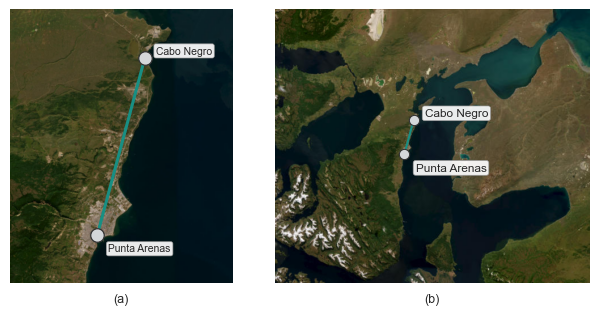


Figure 2 nodes:
                                         zone     lat     lon         label
bus_name                                                                   
elec_punta_arenas_centro  punta_arenas_centro -53.163 -70.917  Punta Arenas
elec_cabo_negro                    cabo_negro -52.966 -70.829    Cabo Negro

Saved Figure 2:
  output\output_punta_arenas\figures\figure02_case_topology.svg
  output\output_punta_arenas\figures\figure02_case_topology.png


In [12]:
# Figure 2 — Two-node topology of the modelled Punta Arenas–Cabo Negro system
#
# Coordinates are read from nodes.csv.
# Network buses are matched to geographical nodes by removing technical
# carrier prefixes (e.g. elec_).
#
# Panels:
#   (a) Local Punta Arenas–Cabo Negro topology
#   (b) Wider Magallanes context
#
# Exports:
#   - figure02_case_topology.svg
#   - figure02_case_topology.png
if ctx is None:
    raise ImportError(
        "contextily is required for Figure 2. Install it with: pip install contextily"
    )

# =============================================================================
# 1. Configuration
# =============================================================================
FIG2_SCENARIO = "BAU_base"
FIG2_YEAR = 2050

# Main geographical nodes represented in this figure
FIG2_TARGET_ZONES = ['punta_arenas_centro', 'cabo_negro']

FIG2_NODE_LABELS = {'punta_arenas_centro': 'Punta Arenas', 'cabo_negro': 'Cabo Negro'}

# ── Input data ────────────────────────────────────────────────────────────────
NODES_CSV = Path(case_folder) / "nodes.csv"

if not NODES_CSV.exists():
    raise FileNotFoundError(
        f"Could not find nodes.csv in the Punta Arenas input folder: {NODES_CSV}"
    )
print(f"Using nodes file: {NODES_CSV}")

FIG2_BASEMAP = ctx.providers.Esri.WorldImagery

# Local-panel padding [metres in EPSG:3857]
PAD_A_X = 18_000
PAD_A_Y = 10_000

# Regional-panel padding
PAD_B_WEST  = 140_000
PAD_B_EAST  = 190_000
PAD_B_SOUTH = 140_000
PAD_B_NORTH = 120_000

# Plot styling
NODE_SIZE_A = 95
NODE_SIZE_B = 55

NODE_FACE = "#d4d7d9"
NODE_EDGE = "0.20"

LINK_COLOR = "#188f83"
LINK_WIDTH_A = 2.2
LINK_WIDTH_B = 1.5

LABEL_FONTSIZE_A = 7.5
LABEL_FONTSIZE_B = 8.5
PANEL_FONTSIZE = 9

FIG2_BASENAME = "figure02_case_topology"

# =============================================================================
# 2. Load solved network
# =============================================================================
if "scenario_results" not in globals():
    raise RuntimeError(
        "scenario_results is not available. "
        "Run the scenario-loading cell first."
    )
if FIG2_SCENARIO not in scenario_results:
    raise KeyError(f'{FIG2_SCENARIO} not found in scenario_results.')
if FIG2_YEAR not in scenario_results[FIG2_SCENARIO]["results"]:
    raise KeyError(f'{FIG2_SCENARIO} has no solved result for {FIG2_YEAR}.')
net = scenario_results[FIG2_SCENARIO]['results'][FIG2_YEAR]['network']

# =============================================================================
# 3. Load nodes.csv
# =============================================================================
def _load_nodes(path):
    nodes = pd.read_csv(path)
    required = ["zone", "lat", "lon"]
    missing = [col for col in required if col not in nodes.columns]
    if missing:
        raise ValueError(f'nodes.csv is missing columns: {missing}')

    # Remove metadata / units row:
    # e.g. "# zone[name]"
    nodes = nodes[
        ~nodes["zone"]
        .astype(str)
        .str.strip()
        .str.startswith("#")
    ].copy()
    nodes['zone'] = nodes['zone'].astype(str).str.strip().str.lower()
    nodes['lat'] = pd.to_numeric(nodes['lat'], errors='coerce')
    nodes['lon'] = pd.to_numeric(nodes['lon'], errors='coerce')

    # Keep enabled nodes if that column exists
    if "enabled" in nodes.columns:
        nodes["enabled_bool"] = (
            nodes["enabled"]
            .astype(str)
            .str.strip()
            .str.upper()
            .eq("TRUE")
        )
    else:
        nodes["enabled_bool"] = True
    return nodes


nodes = _load_nodes(NODES_CSV)

# =============================================================================
# 4. Match network buses to nodes.csv
# =============================================================================
def _match_bus_to_zone(bus_name, valid_zones):
    """
    Match a PyPSA technical bus name to the geographical node name.

    Examples
    --------
    elec_punta_arenas_centro -> punta_arenas_centro
    elec_cabo_negro          -> cabo_negro

    The function is intentionally reusable for future heat/H2 buses.
    """
    name = str(bus_name).strip().lower()

    # Exact match first
    if name in valid_zones:
        return name

    # Technical carrier prefixes used/expected in the model
    prefixes = ['elec_', 'electricity_', 'h2_', 'hydrogen_', 'heat_']
    for prefix in prefixes:
        if name.startswith(prefix):
            candidate = name[len(prefix):]
            if candidate in valid_zones:
                return candidate
    return None


def _build_bus_node_crosswalk(network, nodes_df):
    valid_zones = set(nodes_df["zone"])
    crosswalk = pd.DataFrame(index=network.buses.index.copy())
    crosswalk.index.name = "bus_name"
    crosswalk["zone"] = [
        _match_bus_to_zone(bus, valid_zones)
        for bus in crosswalk.index
    ]

    # Add geographical information from nodes.csv
    node_info = nodes_df.set_index('zone')[['lat', 'lon', 'enabled_bool']]
    crosswalk = crosswalk.join(node_info, on='zone')
    return crosswalk


# This object can be reused later for plotting capacities/results by bus
bus_node_crosswalk = _build_bus_node_crosswalk(net, nodes)

print("\nNetwork → nodes.csv match:")
display(bus_node_crosswalk)

# =============================================================================
# 5. Select Figure 2 nodes and build GeoDataFrame
# =============================================================================
fig2_bus_df = bus_node_crosswalk[
    bus_node_crosswalk["zone"].isin(
        FIG2_TARGET_ZONES
    )
].copy()

# Make sure both expected nodes were found
found_zones = set(fig2_bus_df['zone'].dropna())

missing_zones = set(FIG2_TARGET_ZONES) - found_zones

if missing_zones:
    raise ValueError(
        "Could not match these Figure 2 nodes: "
        f"{sorted(missing_zones)}\n\n"
        "Network buses:\n"
        f"{list(net.buses.index)}\n\n"
        "Available nodes.csv zones:\n"
        f"{list(nodes['zone'])}"
    )

# Check coordinates
missing_coords = fig2_bus_df[fig2_bus_df[['lat', 'lon']].isna().any(axis=1)]

if not missing_coords.empty:
    raise ValueError(
        "Missing coordinates in nodes.csv for:\n"
        + missing_coords.to_string()
    )
fig2_bus_df['label'] = fig2_bus_df['zone'].map(FIG2_NODE_LABELS)

# Build geographic points
bus_gdf = gpd.GeoDataFrame(
    fig2_bus_df,
    geometry=gpd.points_from_xy(
        fig2_bus_df["lon"],
        fig2_bus_df["lat"],
    ),
    crs="EPSG:4326",
).to_crs(epsg=3857)

# =============================================================================
# 6. Build model interconnection
# =============================================================================
def _build_interconnection(network, mapped_buses):
    rows = []

    # First try to recover an actual network link
    if (
        hasattr(network, "links")
        and not network.links.empty
    ):
        for link_name, row in network.links.iterrows():
            bus0 = row.get("bus0")
            bus1 = row.get("bus1")
            if (
                bus0 in mapped_buses.index
                and bus1 in mapped_buses.index
            ):
                p0 = mapped_buses.loc[bus0, 'geometry']
                p1 = mapped_buses.loc[bus1, 'geometry']
                rows.append(
                    {
                        "name": link_name,
                        "bus0": bus0,
                        "bus1": bus1,
                        "geometry": LineString(
                            [p0, p1]
                        ),
                    }
                )

    # If the electricity connection is represented differently in the
    # network, draw the conceptual two-node interconnection directly.
    if not rows and len(mapped_buses) == 2:
        bus_names = list(mapped_buses.index)
        p0 = mapped_buses.loc[bus_names[0], 'geometry']
        p1 = mapped_buses.loc[bus_names[1], 'geometry']
        rows.append(
            {
                "name": "model_interconnection",
                "bus0": bus_names[0],
                "bus1": bus_names[1],
                "geometry": LineString(
                    [p0, p1]
                ),
            }
        )
    return gpd.GeoDataFrame(rows, geometry='geometry', crs='EPSG:3857')


link_gdf = _build_interconnection(net, bus_gdf)

# =============================================================================
# 7. Map extents
# =============================================================================
minx, miny, maxx, maxy = bus_gdf.total_bounds

# Panel (a): close view
extent_a = (minx - PAD_A_X, maxx + PAD_A_X, miny - PAD_A_Y, maxy + PAD_A_Y)

# Panel (b): regional Magallanes context
extent_b = (
    minx - PAD_B_WEST,
    maxx + PAD_B_EAST,
    miny - PAD_B_SOUTH,
    maxy + PAD_B_NORTH,
)

# =============================================================================
# 8. Plot helpers
# =============================================================================
def _set_extent(ax, extent):
    xmin, xmax, ymin, ymax = extent
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)


def _format_axis(ax):
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)


def _add_node_labels(
    ax,
    gdf,
    panel="a",
):
    for bus_name, row in gdf.iterrows():
        zone = row["zone"]
        x = row.geometry.x
        y = row.geometry.y

        # Different offsets avoid overlap
        if zone == "cabo_negro":
            offset = (8, 5)
        else:  # Punta Arenas
            offset = (8, -10)
        fontsize = LABEL_FONTSIZE_A if panel == 'a' else LABEL_FONTSIZE_B
        ax.annotate(
            row["label"],
            xy=(x, y),
            xytext=offset,
            textcoords="offset points",
            fontsize=fontsize,
            ha="left",
            va="center",
            bbox=dict(
                boxstyle="round,pad=0.20",
                fc="white",
                ec="0.60",
                lw=0.5,
                alpha=0.92,
            ),
            zorder=7,
        )


def _panel_label(ax, label):
    ax.text(
        0.5,
        -0.035,
        label,
        transform=ax.transAxes,
        ha="center",
        va="top",
        fontsize=PANEL_FONTSIZE,
    )


# =============================================================================
# 9. Create Figure 2
# =============================================================================
FIG_WIDTH = globals().get('WORD_DOUBLE_COL_IN', 7.16)

fig = plt.figure(figsize=(FIG_WIDTH, 3.15))

gs = GridSpec(nrows=1, ncols=2, figure=fig, width_ratios=[1.0, 1.55], wspace=0.005)

ax_a = fig.add_subplot(gs[0, 0])

ax_b = fig.add_subplot(gs[0, 1])

# -----------------------------------------------------------------------------
# (a) Local topology
# -----------------------------------------------------------------------------
_set_extent(ax_a, extent_a)

ctx.add_basemap(ax_a, source=FIG2_BASEMAP, attribution=False)

if not link_gdf.empty:
    link_gdf.plot(ax=ax_a, linewidth=LINK_WIDTH_A, color=LINK_COLOR, zorder=4)
bus_gdf.plot(
    ax=ax_a,
    markersize=NODE_SIZE_A,
    color=NODE_FACE,
    edgecolor=NODE_EDGE,
    linewidth=0.9,
    zorder=5,
)

_add_node_labels(ax_a, bus_gdf, panel='a')

_format_axis(ax_a)

_panel_label(ax_a, '(a)')

# -----------------------------------------------------------------------------
# (b) Magallanes context
# -----------------------------------------------------------------------------
_set_extent(ax_b, extent_b)

ctx.add_basemap(ax_b, source=FIG2_BASEMAP, attribution=False)

if not link_gdf.empty:
    link_gdf.plot(ax=ax_b, linewidth=LINK_WIDTH_B, color=LINK_COLOR, zorder=4)
bus_gdf.plot(
    ax=ax_b,
    markersize=NODE_SIZE_B,
    color=NODE_FACE,
    edgecolor=NODE_EDGE,
    linewidth=0.8,
    zorder=5,
)

_add_node_labels(ax_b, bus_gdf, panel='b')

_format_axis(ax_b)

_panel_label(ax_b, '(b)')

# =============================================================================
# 10. Final layout
# =============================================================================
fig.subplots_adjust(left=0.01, right=0.995, top=0.99, bottom=0.12)

# =============================================================================
# 11. Export
# =============================================================================
figure2_paths = []

for extension in [
    "svg",
    "png",
]:
    filename = f'{FIG2_BASENAME}.{extension}'

    # Use your existing paper-export helper if available
    if "save_paper_figure" in globals():
        output_path = save_paper_figure(fig, filename)
    else:
        output_path = Path(filename)
        fig.savefig(output_path, dpi=400, bbox_inches='tight')
    figure2_paths.append(output_path)

# =============================================================================
# 12. SHOW FIGURE
# =============================================================================
plt.show()

# =============================================================================
# 13. Summary
# =============================================================================
print("\nFigure 2 nodes:")

print(bus_gdf[['zone', 'lat', 'lon', 'label']])

print("\nSaved Figure 2:")

for p in figure2_paths:
    print(f"  {p}")


### Figure 3 — Characterisation of persistent low-renewable-generation events

Loads the 2016–2025 historical weather profiles, identifies simultaneous low-wind/low-solar periods, and generates the interannual screening plus the critical-event zoom.


In [13]:
# Historical weather-profile cache used by Figures 3 and 6
REP_WEATHER_YEARS = list(range(2016, 2026))
REP_CUTOUT_DIR = Path("data")
REP_CUTOUT_PREFIX = "magallanes"
REP_OUTPUT_DIR = OUTPUT_ROOT / "representative_weather_benchmarks"
REP_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def _normalise_cf_index(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out.index = pd.DatetimeIndex(pd.to_datetime(out.index))
    # PyPSA/atlite profiles in this notebook are treated as timezone-naive.
    if out.index.tz is not None:
        out.index = out.index.tz_localize(None)
    return out.sort_index()


def load_historical_vre_profiles(
    weather_years=REP_WEATHER_YEARS,
    cutout_dir=REP_CUTOUT_DIR,
    cutout_prefix=REP_CUTOUT_PREFIX,
):
    """Load wind/solar CFs directly from the existing ERA5 cutouts."""
    if "scenario_results" not in globals():
        raise RuntimeError("Run the main result-loading cells first.")

    # Use nodes from the active/available scenario; node geography is common to the cases.
    preferred = ACTIVE_SCENARIO if ACTIVE_SCENARIO in scenario_results else next(iter(scenario_results))
    node_result = scenario_results[preferred]["results"][detailed_year]
    nodes_df = node_result["nodes"].load() if hasattr(node_result["nodes"], "load") else node_result["nodes"].copy()
    cache = {}
    missing = []
    for wy in weather_years:
        path = Path(cutout_dir) / f"{cutout_prefix}_{wy}.nc"
        if not path.exists():
            missing.append(path)
            continue
        cutout = atlite.Cutout(str(path))
        wind_cf, solar_cf = config.get_vre_profiles_from_cutout(
            cutout=cutout,
            nodes_df=nodes_df,
            method=vre_profile_method,
            wind_turbine=wind_turbine,
            solar_panel=solar_panel,
            solar_orientation=solar_orientation,
        )
        wind_cf = _normalise_cf_index(wind_cf)
        solar_cf = _normalise_cf_index(solar_cf)

        # Remove Feb-29 only for the climatology/representative-period selection.
        # The original cutouts remain untouched for the capacity-expansion runs.
        non_leap_w = ~((wind_cf.index.month == 2) & (wind_cf.index.day == 29))
        non_leap_s = ~((solar_cf.index.month == 2) & (solar_cf.index.day == 29))
        cache[int(wy)] = {
            "wind": wind_cf.loc[non_leap_w].copy(),
            "solar": solar_cf.loc[non_leap_s].copy(),
            "cutout": path,
        }
    if missing:
        print("Historical VRE screening skipped missing cutouts:")
        for path in missing:
            print(f"  - {path}")
    if not cache:
        raise FileNotFoundError("No historical weather cutouts were available for representative-weather screening.")
    return cache


# Reuse the cache when the cell is rerun.
if "historical_vre_profiles" not in globals() or not historical_vre_profiles:
    historical_vre_profiles = load_historical_vre_profiles()
print(f"Loaded historical VRE profiles for: {sorted(historical_vre_profiles)}")


c:\Users\vse23\AppData\Local\anaconda3\envs\pypsa-isolated\Lib\site-packages\atlite\resource.py:90: FutureWarning:

'add_cutout_windspeed' for wind turbine
power curves will default to True in atlite relase v0.2.15.

c:\Users\vse23\AppData\Local\anaconda3\envs\pypsa-isolated\Lib\site-packages\atlite\resource.py:90: FutureWarning:

'add_cutout_windspeed' for wind turbine
power curves will default to True in atlite relase v0.2.15.

c:\Users\vse23\AppData\Local\anaconda3\envs\pypsa-isolated\Lib\site-packages\atlite\resource.py:90: FutureWarning:

'add_cutout_windspeed' for wind turbine
power curves will default to True in atlite relase v0.2.15.

c:\Users\vse23\AppData\Local\anaconda3\envs\pypsa-isolated\Lib\site-packages\atlite\resource.py:90: FutureWarning:

'add_cutout_windspeed' for wind turbine
power curves will default to True in atlite relase v0.2.15.

c:\Users\vse23\AppData\Local\anaconda3\envs\pypsa-isolated\Lib\site-packages\atlite\resource.py:90: FutureWarning:

'add_cutout_wind

Loaded historical VRE profiles for: [2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]


In [14]:
# Renewable-scarcity helper functions
def _prepare_cf_series(cf_df: pd.DataFrame) -> pd.Series:
    """Average capacity-factor profiles across zones."""
    if cf_df is None or cf_df.empty:
        raise ValueError("No capacity-factor data are available.")
    cf = cf_df.copy()
    if not isinstance(cf.index, pd.DatetimeIndex):
        cf.index = pd.to_datetime(cf.index)
    return cf.mean(axis=1)


def _daily_mean_series(cf_series: pd.Series) -> pd.Series:
    return cf_series.resample("D").mean()


def _monthly_max_consecutive_low_days(
    daily_cf: pd.Series,
    threshold: float,
) -> pd.Series:
    month_labels = [
        "Jan", "Feb", "Mar", "Apr", "May", "Jun",
        "Jul", "Aug", "Sep", "Oct", "Nov", "Dec",
    ]
    result = pd.Series(0.0, index=month_labels)
    for month_num, month_data in daily_cf.groupby(daily_cf.index.month):
        maximum = 0
        current = 0
        for is_low in month_data.lt(threshold):
            current = current + 1 if is_low else 0
            maximum = max(maximum, current)
        result.iloc[month_num - 1] = maximum
    return result


def _longest_true_run(mask: pd.Series) -> tuple[pd.Timestamp | None, pd.Timestamp | None, int]:
    """Return the start, end, and duration of the longest True run."""
    mask = mask.astype(bool)
    best_start = best_end = current_start = None
    best_length = current_length = 0
    for timestamp, value in mask.items():
        if value:
            if current_start is None:
                current_start = timestamp
            current_length += 1
            if current_length > best_length:
                best_start = current_start
                best_end = timestamp
                best_length = current_length
        else:
            current_start = None
            current_length = 0
    return best_start, best_end, best_length


Saved figure: output\output_punta_arenas\figures\figure03_restructured_multiyear_scarcity.svg
Saved figure: output\output_punta_arenas\figures\figure03_restructured_multiyear_scarcity.png


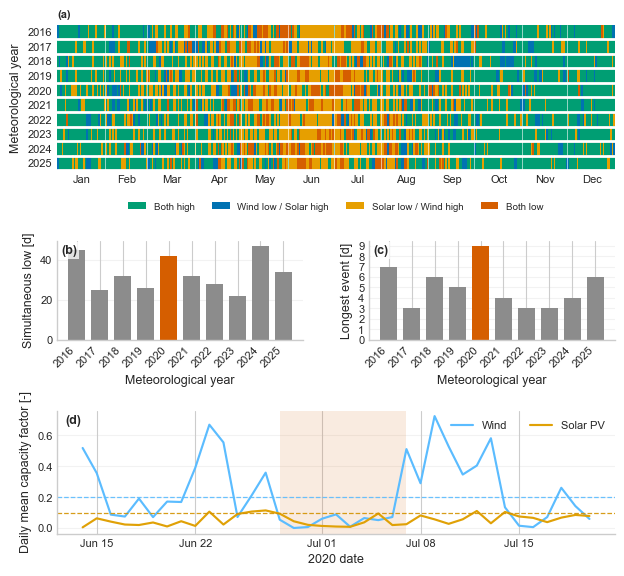

Critical screening year: 2020 (9 consecutive simultaneous low-generation days)
Saved Figure 3: output\output_punta_arenas\figures\figure03_restructured_multiyear_scarcity.svg


In [15]:
# Figure 3 — Multi-year low-renewable-generation screening and critical-event zoom
#
# Combines the main message of the previous multi-year screening and
# critical-year diagnostic figures while preserving the established
# renewable-resource palette and paper formatting.
def _canonical_day_of_year(index):
    """Map month/day combinations to a common non-leap 365-day calendar."""
    return pd.DatetimeIndex([
        pd.Timestamp(2001, ts.month, ts.day)
        for ts in pd.DatetimeIndex(index)
    ]).dayofyear.to_numpy()


def build_multiyear_scarcity_table(profile_cache):
    daily_frames = []
    annual_rows = []
    for weather_year, profiles in sorted(profile_cache.items()):
        wind_daily = profiles["wind"].mean(axis=1).resample("D").mean()
        solar_daily = profiles["solar"].mean(axis=1).resample("D").mean()
        daily = pd.DataFrame({'wind': wind_daily, 'solar': solar_daily}).dropna()

        # Use a common 365-day calendar for the matrix.
        daily = daily.loc[~((daily.index.month == 2) & (daily.index.day == 29))].copy()
        daily["both_low"] = (
            daily["wind"].lt(LOW_WIND_THRESHOLD)
            & daily["solar"].lt(LOW_SOLAR_THRESHOLD)
        )
        daily["category"] = np.select(
            [
                daily["wind"].ge(LOW_WIND_THRESHOLD)
                & daily["solar"].ge(LOW_SOLAR_THRESHOLD),
                daily["wind"].lt(LOW_WIND_THRESHOLD)
                & daily["solar"].ge(LOW_SOLAR_THRESHOLD),
                daily["wind"].ge(LOW_WIND_THRESHOLD)
                & daily["solar"].lt(LOW_SOLAR_THRESHOLD),
                daily["both_low"],
            ],
            [0, 1, 2, 3],
            default=np.nan,
        )
        daily["weather_year"] = int(weather_year)
        daily["canonical_doy"] = _canonical_day_of_year(daily.index)
        daily_frames.append(daily.reset_index(names="date"))
        start, end, longest = _longest_true_run(daily["both_low"])
        annual_rows.append({
            "weather_year": int(weather_year),
            "simultaneous_low_days": int(daily["both_low"].sum()),
            "max_consecutive_simultaneous_low_days": int(longest),
            "longest_event_start": start,
            "longest_event_end": end,
        })
    return (pd.concat(daily_frames, ignore_index=True), pd.DataFrame(annual_rows))


scarcity_daily_long, scarcity_annual_summary = (
    build_multiyear_scarcity_table(historical_vre_profiles)
)

scarcity_annual_summary = (
    scarcity_annual_summary
    .sort_values("weather_year")
    .reset_index(drop=True)
)

critical_row = (
    scarcity_annual_summary
    .sort_values(
        [
            "max_consecutive_simultaneous_low_days",
            "simultaneous_low_days",
            "weather_year",
        ],
        ascending=[False, False, True],
    )
    .iloc[0]
)

critical_screen_year = int(critical_row["weather_year"])

if critical_screen_year != int(critical_weather_year):
    print(
        f"WARNING: screening identifies {critical_screen_year} as the critical "
        f"year, while critical_weather_year={critical_weather_year}. "
        "Review before final paper runs."
    )
plot_years = scarcity_annual_summary['weather_year'].astype(int).tolist()

calendar_matrix = np.full((len(plot_years), 365), np.nan)

for row_i, weather_year in enumerate(plot_years):
    subset = scarcity_daily_long.loc[
        scarcity_daily_long["weather_year"].eq(weather_year)
    ]
    for _, row in subset.iterrows():
        doy = int(row["canonical_doy"])
        if 1 <= doy <= 365:
            calendar_matrix[row_i, doy - 1] = row["category"]

# ── Layout ───────────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(WORD_DOUBLE_COL_IN, 5.75))

gs = fig.add_gridspec(3, 2, height_ratios=[1.3, 0.88, 1.1], hspace=0.58, wspace=0.27)

ax_a = fig.add_subplot(gs[0, :])
ax_b = fig.add_subplot(gs[1, 0])
ax_c = fig.add_subplot(gs[1, 1])
ax_d = fig.add_subplot(gs[2, :])

# ── (a) Timing and persistence matrix ───────────────────────────────────────
cmap = ListedColormap(RESOURCE_COLORS)
norm = BoundaryNorm(np.arange(-0.5, 4.5, 1.0), cmap.N)

ax_a.imshow(
    calendar_matrix,
    aspect="auto",
    interpolation="nearest",
    cmap=cmap,
    norm=norm,
)

ax_a.set_yticks(np.arange(len(plot_years)))
ax_a.set_yticklabels(plot_years)

month_labels = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec",
]

month_midpoints = []

for month in range(1, 13):
    start = pd.Timestamp(2001, month, 1).dayofyear - 1
    if month == 12:
        end = 365
    else:
        end = pd.Timestamp(2001, month + 1, 1).dayofyear - 1
    month_midpoints.append((start + end) / 2)
    if month > 1:
        ax_a.axvline(start - 0.5, color='white', linewidth=0.55, alpha=0.75)

# White separation between meteorological years,
# matching the previous matrix style more closely.
for row_boundary in np.arange(0.5, len(plot_years), 1.0):
    ax_a.axhline(row_boundary, color='white', linewidth=2.0, zorder=3)
ax_a.set_xticks(month_midpoints)
ax_a.set_xticklabels(month_labels)
ax_a.set_xlabel("")
ax_a.set_ylabel("Meteorological year")
ax_a.grid(False)
ax_a.tick_params(axis="both", length=0)

for spine in ax_a.spines.values():
    spine.set_visible(False)

# Panel label outside the matrix because this axis does not share
# the same internal plotting area as panels (b)–(d).
ax_a.text(
    0.0,
    1.035,
    "(a)",
    transform=ax_a.transAxes,
    ha="left",
    va="bottom",
    fontsize=8,
    fontweight="bold",
    clip_on=False,
)

# ── (b) Number of simultaneous low-generation days ─────────────────────────
x = np.arange(len(plot_years))

critical_color = RESOURCE_COLORS[3]
noncritical_color = "0.55"

bar_colors = [
    critical_color if year == critical_screen_year else noncritical_color
    for year in plot_years
]

ax_b.bar(
    x,
    scarcity_annual_summary["simultaneous_low_days"].to_numpy(float),
    color=bar_colors,
    width=0.72,
)

ax_b.set_xticks(x)
ax_b.set_xticklabels(plot_years, rotation=45, ha="right")

_paper_axis(ax_b, xlabel='Meteorological year', ylabel='Simultaneous low [d]')

_paper_panel_label(ax_b, "(b)")

# ── (c) Maximum consecutive duration ────────────────────────────────────────
ax_c.bar(
    x,
    scarcity_annual_summary[
        "max_consecutive_simultaneous_low_days"
    ].to_numpy(float),
    color=bar_colors,
    width=0.72,
)

ax_c.set_xticks(x)
ax_c.set_xticklabels(plot_years, rotation=45, ha="right")

_paper_axis(ax_c, xlabel='Meteorological year', ylabel='Longest event [d]')
ax_c.yaxis.set_major_locator(MaxNLocator(integer=True))

_paper_panel_label(ax_c, "(c)")

# ── (d) Critical-event zoom ─────────────────────────────────────────────────
critical_profiles = historical_vre_profiles[critical_screen_year]

wind_daily = critical_profiles['wind'].mean(axis=1).resample('D').mean()

solar_daily = critical_profiles['solar'].mean(axis=1).resample('D').mean()

critical_mask = wind_daily.lt(LOW_WIND_THRESHOLD) & solar_daily.lt(LOW_SOLAR_THRESHOLD)

event_start, event_end, event_duration = _longest_true_run(critical_mask)

zoom_start = event_start - pd.Timedelta(days=14)
zoom_end = event_end + pd.Timedelta(days=14)

wind_zoom = wind_daily.loc[zoom_start:zoom_end]
solar_zoom = solar_daily.loc[zoom_start:zoom_end]

wind_color = TECH_COLORS.get("wind", "#5bbcff")
solar_color = TECH_COLORS.get("solar", "#ffd54f")

ax_d.plot(
    wind_zoom.index,
    wind_zoom.values,
    color=wind_color,
    linewidth=1.55,
    label="Wind",
)

ax_d.plot(
    solar_zoom.index,
    solar_zoom.values,
    color=solar_color,
    linewidth=1.55,
    label="Solar PV",
)

ax_d.axhline(
    LOW_WIND_THRESHOLD,
    color=wind_color,
    linestyle="--",
    linewidth=0.9,
    alpha=0.9,
)

ax_d.axhline(
    LOW_SOLAR_THRESHOLD,
    color="#d39200",
    linestyle="--",
    linewidth=0.9,
    alpha=0.9,
)

ax_d.axvspan(
    event_start,
    event_end + pd.Timedelta(days=1),
    facecolor=critical_color,
    alpha=0.12,
    linewidth=0,
)

_paper_axis(
    ax_d,
    xlabel=f"{critical_screen_year} date",
    ylabel="Daily mean capacity factor [-]",
)

# Show only month and day on the x-axis;
# the year is already stated in the axis label.
ax_d.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=6, maxticks=10))

ax_d.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))

ax_d.tick_params(axis='x', rotation=0)

ax_d.legend(frameon=False, ncol=2, loc='upper right')

_paper_panel_label(ax_d, "(d)")

# ── Shared category legend ───────────────────────────────────────────────────
legend_handles = [
    Patch(
        facecolor=color,
        edgecolor="none",
        label=label,
    )
    for color, label in zip(
        RESOURCE_COLORS,
        RESOURCE_LABELS,
    )
]

ax_a.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.16),
    ncol=4,
    frameon=False,
    fontsize=7,
    handlelength=1.8,
    columnspacing=1.8,
)

fig.subplots_adjust(left=0.1, right=0.985, top=0.965, bottom=0.08)

# ── Export ───────────────────────────────────────────────────────────────────
fig3_path = save_paper_figure(fig, 'figure03_restructured_multiyear_scarcity.svg')

save_paper_figure(fig, 'figure03_restructured_multiyear_scarcity.png')

plt.show()

scarcity_annual_summary.to_csv(
    TABLE_EXPORT_DIR / "figure03_multiyear_scarcity_summary.csv",
    index=False,
)

print(
    f"Critical screening year: {critical_screen_year} "
    f"({event_duration} consecutive simultaneous low-generation days)"
)

print(f"Saved Figure 3: {fig3_path}")


### Figure 4 — Cross-scenario system comparison

Compares the seven 2050 pathways in terms of hourly demand/PtX use, annual electricity supply, dispatchable supply, installed capacity, and annual system cost. BESS is separated by storage duration. Secondary axes show VRE curtailment in panel (b), GHG emissions in panel (c), total storage energy capacity in panel (d), and average system cost normalised by served local + PtX electricity in panel (e).


In [16]:
# Shared cross-scenario plotting helpers used by Figure 4 and supplementary outputs
def _norm_carrier(x):
    return str(x).strip().lower().replace(" ", "_").replace("-", "_")


def format_scenario_axis(ax, x, labels):
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=0, ha="center", fontsize=7)
    ax.tick_params(axis="x", pad=3)


def build_generation_group_df(df_year):
    """
    Annual electricity generation / dispatch by broad technology group [TWh/yr].

    Reconstructed directly from each optimized PyPSA network.
    """
    out = pd.DataFrame(0.0, index=df_year.index, columns=TECH_GROUPS)
    for idx, row in df_year.iterrows():
        scenario_code = row["scenario"]
        year = int(row["year"])
        net = scenario_results[scenario_code]["results"][year]["network"]
        try:
            weights = pd.Series(net.snapshot_weightings.objective, index=net.snapshots).astype(float)
        except Exception:
            weights = pd.Series(1.0, index=net.snapshots)

        # Generators
        if hasattr(net, "generators") and len(net.generators) > 0:
            p_gen = net.generators_t.p.reindex(columns=net.generators.index, fill_value=0.0).clip(lower=0.0)
            for asset in net.generators.index:
                carrier = _norm_carrier(net.generators.loc[asset, "carrier"]) if "carrier" in net.generators.columns else ""
                group = GENERATOR_CARRIER_GROUP.get(carrier)
                energy_mwh = float((p_gen[asset] * weights).sum())
                if energy_mwh <= 1e-6:
                    continue
                if group is None:
                    group = "Other"
                out.loc[idx, group] += energy_mwh / 1e6

        # Storage-unit discharge
        if hasattr(net, "storage_units") and len(net.storage_units) > 0:
            p_su = net.storage_units_t.p.reindex(columns=net.storage_units.index, fill_value=0.0).clip(lower=0.0)
            for asset in net.storage_units.index:
                carrier = _norm_carrier(net.storage_units.loc[asset, "carrier"]) if "carrier" in net.storage_units.columns else ""
                group = STORAGE_UNIT_CARRIER_GROUP.get(carrier)
                energy_mwh = float((p_su[asset] * weights).sum())
                if energy_mwh <= 1e-6:
                    continue
                if group is None:
                    group = "Other"
                out.loc[idx, group] += energy_mwh / 1e6

        # Electricity-producing links
        if hasattr(net, "links") and len(net.links) > 0:
            for asset in net.links.index:
                carrier = _norm_carrier(net.links.loc[asset, "carrier"]) if "carrier" in net.links.columns else ""
                group = ELECTRICITY_OUTPUT_LINK_GROUP.get(carrier)
                if group is None:
                    continue

                # Link outputs are negative at output ports in PyPSA.
                output_candidates = []
                for port in ["p1", "p2", "p3", "p4"]:
                    if hasattr(net.links_t, port):
                        p = getattr(net.links_t, port)
                        if asset in p.columns:
                            s = (-p[asset]).clip(lower=0.0)
                            output_candidates.append(s)
                if not output_candidates:
                    continue
                output = max(output_candidates, key=lambda s: float((s * weights).sum()))
                energy_mwh = float((output * weights).sum())
                if energy_mwh <= 1e-6:
                    continue
                out.loc[idx, group] += energy_mwh / 1e6
    return out[TECH_GROUPS]


def build_cost_group_df(df_year):
    """
    Build system cost by broad technology group [million USD/yr],
    reconstructed directly from scenario_results.
    """
    out = pd.DataFrame(0.0, index=df_year.index, columns=TECH_GROUPS)
    for idx, row in df_year.iterrows():
        scenario_code = row["scenario"]
        year = int(row["year"])
        net = scenario_results[scenario_code]["results"][year]["network"]
        costs = estimate_cost_breakdown_from_network(net)
        if costs.empty:
            continue
        grouped = costs.groupby("group")["total_cost"].sum()
        for group, value in grouped.items():
            if group not in out.columns:
                out.loc[idx, "Other"] += float(value)
            else:
                out.loc[idx, group] += float(value)
    return out[TECH_GROUPS] / 1e6


def plot_stacked_bars(ax, stack_df, groups, colors, labels, ylabel):
    """Plot a stacked bar chart and return the displayed groups."""
    x = np.arange(len(stack_df))
    bottom = np.zeros(len(stack_df))
    plotted_groups = []
    for group in groups:
        if group not in stack_df.columns:
            continue
        values = stack_df[group].fillna(0.0).values
        if np.allclose(values.sum(), 0.0):
            continue
        ax.bar(
            x,
            values,
            bottom=bottom,
            width=0.78,
            color=colors.get(group, "#999999"),
            alpha=0.90,
            label=group,
            edgecolor="white",
            linewidth=0.25,
        )
        bottom += values
        plotted_groups.append(group)
    format_scenario_axis(ax, x, labels)
    finish_axis(ax, ylabel=ylabel)
    ax.grid(False)
    ax.yaxis.grid(True, alpha=0.22)
    ax.set_axisbelow(True)
    ax.set_xlim(-0.65, len(stack_df) - 0.35)
    return plotted_groups


Saved figure: output\output_punta_arenas\figures\cross_scenario_all_years\figure04_system_design_2050.png
Saved figure: output\output_punta_arenas\figures\cross_scenario_all_years\figure04_system_design_2050.svg
Saved figure: output\output_punta_arenas\figures\cross_scenario_all_years\figure04_system_design_2050.pdf


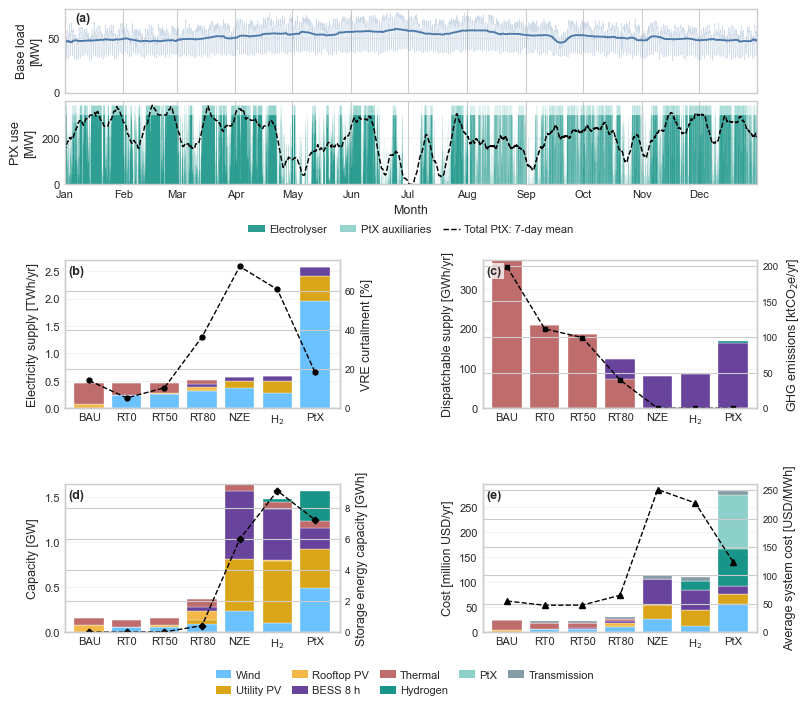

,Scenario,Thermal generation [GWh/yr],BESS discharge [GWh/yr],BESS power capacity [MW],BESS energy capacity [GWh],BESS duration [h],H2-to-power output [GWh/yr],H2 tank/other capacity [GWh],UHS capacity [GWh],BESS equivalent cycles [1/yr]
0,BAU,373.488,0.000,0.000,0.000,0.0,0.000,0.000,0.0,0.000
1,RT0,209.999,0.000,0.000,0.000,0.0,0.000,0.000,0.0,0.000
2,RT50,186.744,1.430,1.264,0.010,8.0,0.000,0.000,0.0,141.412
3,RT80,74.698,48.677,52.552,0.420,8.0,0.000,0.000,0.0,115.784
4,NZE,0.000,81.381,750.000,6.000,8.0,0.000,0.000,0.0,13.563
5,H$_2$,0.000,86.139,566.584,4.533,8.0,2.191,4.581,0.0,19.004
6,PtX,0.000,165.515,227.833,1.823,8.0,4.103,5.418,0.0,90.809


Saved flexibility table to: output\output_punta_arenas\tables\table_flexibility_requirements_2050.csv


In [17]:
# ─────────────────────────────────────────────────────────────────────────────
# Figure 4 — Cross-scenario system comparison
#
# (a) Hourly local-demand components and PtX electricity use
# (b) Annual electricity supply
# (c) Annual flexible electricity supply
# (d) Installed power capacity
# (e) Annual system cost
#
# Reliability and flexibility indicators are also exported below as a numerical table.
# ─────────────────────────────────────────────────────────────────────────────

# ── Configuration ────────────────────────────────────────────────────────────
comparison_year = detailed_year

figure4_export_dir = PAPER_FIGURE_DIR / 'cross_scenario_all_years'

figure4_export_dir.mkdir(parents=True, exist_ok=True)

# Technology groups are finalised after scanning the 2050 networks so BESS
# can be separated by storage duration (e.g. 4 h and 8 h).
FIGURE4_BASE_TECH_GROUPS = [
    "Wind",
    "Solar PV",
    "Rooftop PV",
    "Thermal",
    "Hydrogen",
    "PtX",
    "Transmission",
    "Slack",
    "Other",
]

# Prefer the explicit PtX scenario for panel (a).
profile_scenario = 'PTX_base' if 'PTX_base' in scenario_results else None

# Otherwise, find the first scenario with PtX enabled.
if profile_scenario is None:
    profile_scenario = next(
        (
            scenario_code
            for scenario_code, package in scenario_results.items()
            if package.get("metadata", {}).get("enable_ptx", False)
        ),
        None,
    )
if profile_scenario is None:
    raise ValueError('No PtX-enabled scenario was found for panel (a).')

# ── Validation and scenario ordering ─────────────────────────────────────────
df_y = scenario_comparison[scenario_comparison['year'] == comparison_year].copy()

if df_y.empty:
    raise ValueError(f'No scenario comparison data found for {comparison_year}.')
df_y = apply_scenario_order(df_y).reset_index(drop=True)

df_y["label"] = (
    df_y["scenario"]
    .map(SCENARIO_TECH_LABELS)
    .fillna(
        df_y["scenario"]
        .astype(str)
        .str.replace("_", " ", regex=False)
    )
)

# ── BESS duration groups and Figure 4 technology palette ─────────────────────
def _figure4_bess_duration_label(max_hours):
    """Return a stable legend label such as 'BESS 4 h' or 'BESS 8 h'."""
    hours = float(max_hours)
    if np.isclose(hours, round(hours)):
        hours_text = str(int(round(hours)))
    else:
        hours_text = f"{hours:g}"
    return f"BESS {hours_text} h"


def _figure4_bess_units(net):
    if not hasattr(net, "storage_units") or len(net.storage_units) == 0:
        return pd.Index([])
    carriers = net.storage_units.get(
        "carrier",
        pd.Series("", index=net.storage_units.index),
    ).astype(str).str.lower()
    names = pd.Index(net.storage_units.index.astype(str)).str.lower()
    mask = carriers.str.contains("bess|battery", regex=True, na=False)
    mask |= names.str.contains("bess|battery", regex=True, na=False)
    return net.storage_units.index[mask]


def _collect_figure4_bess_duration_groups(df_year):
    durations = set()
    for _, row in df_year.iterrows():
        result = scenario_results[row["scenario"]]["results"][int(row["year"])]
        net = result["network"]
        for unit in _figure4_bess_units(net):
            hours = pd.to_numeric(
                pd.Series([net.storage_units.loc[unit, "max_hours"]]),
                errors="coerce",
            ).iloc[0]
            if pd.notna(hours):
                durations.add(float(hours))
    return [_figure4_bess_duration_label(hours) for hours in sorted(durations)]


BESS_DURATION_GROUPS = _collect_figure4_bess_duration_groups(df_y)
if not BESS_DURATION_GROUPS:
    BESS_DURATION_GROUPS = ["BESS"]

FIGURE4_TECH_GROUPS = [
    "Wind",
    "Solar PV",
    "Rooftop PV",
    *BESS_DURATION_GROUPS,
    "Thermal",
    "Hydrogen",
    "PtX",
    "Transmission",
    "Slack",
    "Other",
]

FIGURE4_TECH_COLORS = dict(TECH_COLORS_GROUPED)
FIGURE4_TECH_COLORS["Solar PV"] = TECH_COLORS.get(
    "solar_utility",
    TECH_COLORS.get("solar", "#d89b00"),
)
FIGURE4_TECH_COLORS["Rooftop PV"] = TECH_COLORS.get(
    "solar_residential",
    "#f2b134",
)

# Distinct purple shades for BESS durations.
bess_cmap = plt.get_cmap("Purples")
for index, group in enumerate(BESS_DURATION_GROUPS):
    fraction = 0.55 + 0.30 * index / max(len(BESS_DURATION_GROUPS) - 1, 1)
    FIGURE4_TECH_COLORS[group] = bess_cmap(fraction)

FIGURE4_TECH_LEGEND_LABELS = dict(TECH_LEGEND_LABELS)
FIGURE4_TECH_LEGEND_LABELS["Solar PV"] = "Utility PV"
FIGURE4_TECH_LEGEND_LABELS["Rooftop PV"] = "Rooftop PV"
for group in BESS_DURATION_GROUPS:
    FIGURE4_TECH_LEGEND_LABELS[group] = group

# ── General helpers ──────────────────────────────────────────────────────────
def column_or_zero(df, column):
    """Return a numeric column or a zero-valued Series."""
    if column in df.columns:
        return pd.to_numeric(df[column], errors='coerce').fillna(0.0)
    return pd.Series(0.0, index=df.index, dtype=float)


def link_input_series(net, carriers):
    """Aggregate positive p0 electricity input for selected links [MW]."""
    snapshots = pd.Index(net.snapshots)
    if (
        len(net.links) == 0
        or not hasattr(net.links_t, "p0")
    ):
        return pd.Series(0.0, index=snapshots, dtype=float)
    carriers = set(carriers)
    selected_links = net.links.index[net.links['carrier'].astype(str).isin(carriers)]
    if len(selected_links) == 0:
        return pd.Series(0.0, index=snapshots, dtype=float)
    p0 = (
        net.links_t.p0
        .reindex(
            index=net.snapshots,
            columns=selected_links,
            fill_value=0.0,
        )
        .apply(pd.to_numeric, errors="coerce")
        .fillna(0.0)
        .clip(lower=0.0)
    )
    return p0.sum(axis=1).reindex(net.snapshots, fill_value=0.0).astype(float)


def _figure4_snapshot_weights(net):
    try:
        return pd.Series(net.snapshot_weightings.objective, index=net.snapshots).astype(float)
    except Exception:
        return pd.Series(1.0, index=net.snapshots, dtype=float)


def _figure4_solar_breakdown(result, mode="dispatch"):
    """Return utility-scale and rooftop PV either as annual dispatch [TWh] or capacity [GW]."""
    net = result["network"]
    utility_value = 0.0
    rooftop_value = 0.0
    if not hasattr(net, "generators") or len(net.generators) == 0:
        return utility_value, rooftop_value
    carrier_series = net.generators.get("carrier", pd.Series("", index=net.generators.index)).astype(str)
    solar_assets = [
        asset
        for asset in net.generators.index
        if classify_solar_generator(
            asset,
            carrier_series.get(asset, ""),
        ) is not None
    ]
    if len(solar_assets) == 0:
        return utility_value, rooftop_value
    if mode == "dispatch":
        weights = _figure4_snapshot_weights(net)
        dispatch = (
            net.generators_t.p
            .reindex(index=net.snapshots, columns=solar_assets, fill_value=0.0)
            .clip(lower=0.0)
        )
        for asset in solar_assets:
            group = classify_solar_generator(asset, carrier_series.get(asset, ""))
            value = float((dispatch[asset] * weights).sum()) / 1e6
            if group == "Rooftop PV":
                rooftop_value += value
            else:
                utility_value += value
    else:
        if "p_nom_opt" in net.generators.columns:
            capacities = pd.to_numeric(net.generators["p_nom_opt"], errors="coerce")
            if "p_nom" in net.generators.columns:
                capacities = capacities.fillna(pd.to_numeric(net.generators["p_nom"], errors="coerce"))
        else:
            capacities = pd.to_numeric(net.generators.get("p_nom", pd.Series(0.0, index=net.generators.index)), errors="coerce")
        capacities = capacities.fillna(0.0)
        for asset in solar_assets:
            group = classify_solar_generator(asset, carrier_series.get(asset, ""))
            value = float(capacities.get(asset, 0.0)) / 1e3
            if group == "Rooftop PV":
                rooftop_value += value
            else:
                utility_value += value
    return utility_value, rooftop_value


def _figure4_bess_breakdown(result, mode="dispatch_twh"):
    """Return BESS operation/capacity split by max_hours."""
    net = result["network"]
    output = {group: 0.0 for group in BESS_DURATION_GROUPS}
    units = _figure4_bess_units(net)
    if len(units) == 0:
        return output

    weights = _figure4_snapshot_weights(net)
    if "p_nom_opt" in net.storage_units.columns:
        capacities = pd.to_numeric(
            net.storage_units.loc[units, "p_nom_opt"],
            errors="coerce",
        )
        capacities = capacities.fillna(
            pd.to_numeric(
                net.storage_units.loc[units, "p_nom"],
                errors="coerce",
            )
        )
    else:
        capacities = pd.to_numeric(
            net.storage_units.loc[units, "p_nom"],
            errors="coerce",
        )
    capacities = capacities.fillna(0.0)

    power = (
        net.storage_units_t.p
        .reindex(index=net.snapshots, columns=units, fill_value=0.0)
        .fillna(0.0)
        .clip(lower=0.0)
    )

    for unit in units:
        duration = float(net.storage_units.loc[unit, "max_hours"])
        group = _figure4_bess_duration_label(duration)
        if group not in output:
            output[group] = 0.0
        if mode == "capacity_gw":
            output[group] += float(capacities.get(unit, 0.0)) / 1e3
        else:
            discharge_mwh = float((power[unit] * weights).sum())
            if mode == "dispatch_gwh":
                output[group] += discharge_mwh / 1e3
            elif mode == "dispatch_twh":
                output[group] += discharge_mwh / 1e6
            else:
                raise ValueError(f"Unknown BESS breakdown mode: {mode}")
    return output


# ── Annual electricity supply ────────────────────────────────────────────────
def build_dispatch_group_df(df_year):
    """Build annual electricity supply by technology [TWh/yr]."""
    out = pd.DataFrame(index=df_year.index)
    out['Wind'] = column_or_zero(df_year, 'generation_wind_mwh') / 1000000.0
    utility_pv = []
    rooftop_pv = []
    for _, row in df_year.iterrows():
        scenario_code = row["scenario"]
        model_year = int(row["year"])
        result = scenario_results[scenario_code]["results"][model_year]
        utility_value, rooftop_value = _figure4_solar_breakdown(result, mode="dispatch")
        utility_pv.append(utility_value)
        rooftop_pv.append(rooftop_value)
    out["Solar PV"] = utility_pv
    out["Rooftop PV"] = rooftop_pv
    for group in BESS_DURATION_GROUPS:
        out[group] = 0.0
    for idx, row in df_year.iterrows():
        result = scenario_results[row["scenario"]]["results"][int(row["year"])]
        bess_values = _figure4_bess_breakdown(result, mode="dispatch_twh")
        for group, value in bess_values.items():
            out.loc[idx, group] = value
    thermal_columns = [
        "generation_ocgt_mwh",
        "generation_gas_mwh",
        "generation_natural_gas_mwh",
        "generation_diesel_mwh",
    ]
    valid_thermal_columns = [
        column
        for column in thermal_columns
        if column in df_year.columns
    ]
    if valid_thermal_columns:
        out["Thermal"] = (
            df_year[valid_thermal_columns]
            .fillna(0.0)
            .sum(axis=1)
            / 1e6
        )
    else:
        out['Thermal'] = column_or_zero(df_year, 'thermal_generation_mwh') / 1000000.0
    if "h2_to_power_mwh" in df_year.columns:
        out['Hydrogen'] = column_or_zero(df_year, 'h2_to_power_mwh') / 1000000.0
    else:
        out["Hydrogen"] = (
            column_or_zero(df_year, "h2_fuel_cell_output_mwh")
            + column_or_zero(df_year, "h2_turbine_output_mwh")
        ) / 1e6
    out["PtX"] = 0.0
    out["Slack"] = column_or_zero(df_year, "generation_slack_mwh") / 1e6
    out["Transmission"] = 0.0
    out["Other"] = 0.0
    for group in FIGURE4_TECH_GROUPS:
        if group not in out.columns:
            out[group] = 0.0
    return out[FIGURE4_TECH_GROUPS]


# ── Annual flexible electricity supply ──────────────────────────────────────
FLEXIBILITY_GROUPS = ["Thermal", *BESS_DURATION_GROUPS, "Hydrogen"]


def build_flexibility_group_df(df_year):
    """
    Build annual flexible electricity supplied by thermal generation,
    BESS discharge, and hydrogen-to-power [GWh/yr].
    """
    out = pd.DataFrame(index=df_year.index)
    out['Thermal'] = column_or_zero(df_year, 'thermal_generation_mwh') / 1000.0
    for group in BESS_DURATION_GROUPS:
        out[group] = 0.0
    for idx, row in df_year.iterrows():
        result = scenario_results[row["scenario"]]["results"][int(row["year"])]
        bess_values = _figure4_bess_breakdown(result, mode="dispatch_gwh")
        for group, value in bess_values.items():
            out.loc[idx, group] = value
    out['Hydrogen'] = column_or_zero(df_year, 'h2_to_power_mwh') / 1000.0
    return out[FLEXIBILITY_GROUPS]


# ── Installed capacity ───────────────────────────────────────────────────────
def build_capacity_group_df(df_year):
    """Build installed power capacity by technology [GW]."""
    out = pd.DataFrame(index=df_year.index)
    out['Wind'] = column_or_zero(df_year, 'cap_wind_mw') / 1000.0
    utility_pv = []
    rooftop_pv = []
    for _, row in df_year.iterrows():
        scenario_code = row["scenario"]
        model_year = int(row["year"])
        result = scenario_results[scenario_code]["results"][model_year]
        utility_value, rooftop_value = _figure4_solar_breakdown(result, mode="capacity")
        utility_pv.append(utility_value)
        rooftop_pv.append(rooftop_value)
    out["Solar PV"] = utility_pv
    out["Rooftop PV"] = rooftop_pv
    for group in BESS_DURATION_GROUPS:
        out[group] = 0.0
    for idx, row in df_year.iterrows():
        result = scenario_results[row["scenario"]]["results"][int(row["year"])]
        bess_values = _figure4_bess_breakdown(result, mode="capacity_gw")
        for group, value in bess_values.items():
            out.loc[idx, group] = value
    thermal_columns = [
        "cap_ocgt_mw", "cap_gas_mw", "cap_natural_gas_mw", "cap_diesel_mw"
    ]
    valid_thermal_columns = [column for column in thermal_columns if column in df_year.columns]
    out["Thermal"] = (
        df_year[valid_thermal_columns].fillna(0.0).sum(axis=1) / 1e3
        if valid_thermal_columns
        else 0.0
    )
    hydrogen_columns = ["linkcap_electrolyzer_mw", "linkcap_h2_fuel_cell_mw", "linkcap_h2_turbine_mw"]
    valid_hydrogen_columns = [column for column in hydrogen_columns if column in df_year.columns]
    out["Hydrogen"] = (
        df_year[valid_hydrogen_columns].fillna(0.0).sum(axis=1) / 1e3
        if valid_hydrogen_columns
        else 0.0
    )
    out["PtX"] = 0.0
    out["Transmission"] = 0.0
    out["Slack"] = 0.0
    out["Other"] = 0.0
    for group in FIGURE4_TECH_GROUPS:
        if group not in out.columns:
            out[group] = 0.0
    return out[FIGURE4_TECH_GROUPS]


def build_figure4_cost_group_df(df_year):
    """Build annual system cost, splitting PV and BESS duration groups."""
    out = pd.DataFrame(0.0, index=df_year.index, columns=FIGURE4_TECH_GROUPS)
    for idx, row in df_year.iterrows():
        net = scenario_results[row["scenario"]]["results"][int(row["year"])]["network"]
        costs = estimate_cost_breakdown_from_network(net)
        if costs.empty:
            continue
        for _, cost_row in costs.iterrows():
            group = str(cost_row.get("group", "Other"))
            asset = str(cost_row.get("asset", ""))
            if group == "Solar PV":
                carrier = ""
                if asset in net.generators.index and "carrier" in net.generators.columns:
                    carrier = net.generators.loc[asset, "carrier"]
                solar_group = classify_solar_generator(asset, carrier)
                if solar_group is not None:
                    group = solar_group
            elif group == "BESS":
                if asset in net.storage_units.index:
                    group = _figure4_bess_duration_label(
                        net.storage_units.loc[asset, "max_hours"]
                    )
                elif len(BESS_DURATION_GROUPS) == 1:
                    group = BESS_DURATION_GROUPS[0]
            if group not in out.columns:
                group = "Other"
            out.loc[idx, group] += float(cost_row.get("total_cost", 0.0)) / 1e6
    return out[FIGURE4_TECH_GROUPS]


# ── Prepare annual panel data ────────────────────────────────────────────────
dispatch_group_df = build_dispatch_group_df(df_y)
flexibility_group_df = build_flexibility_group_df(df_y)
capacity_group_df = build_capacity_group_df(df_y)
cost_group_df = build_figure4_cost_group_df(df_y)

# Secondary-axis indicators requested for the manuscript figure.
vre_generation_mwh = (
    dispatch_group_df["Wind"]
    + dispatch_group_df["Solar PV"]
    + dispatch_group_df["Rooftop PV"]
) * 1e6
curtailment_total_mwh = column_or_zero(df_y, "curtailment_total_mwh")
vre_available_mwh = vre_generation_mwh + curtailment_total_mwh
figure4_curtailment_pct = (
    100.0
    * curtailment_total_mwh
    .div(vre_available_mwh.replace(0.0, np.nan))
    .fillna(0.0)
)
figure4_emissions_kt = column_or_zero(df_y, "co2_tons") / 1e3
figure4_storage_energy_gwh = (
    column_or_zero(df_y, "energy_bess_mwh")
    + column_or_zero(df_y, "h2_storage_total_mwh")
    + column_or_zero(df_y, "uhs_storage_total_mwh")
) / 1e3
ptx_electricity_mwh = (
    column_or_zero(df_y, "electrolyzer_input_mwh")
    + column_or_zero(df_y, "asu_electricity_mwh")
    + column_or_zero(df_y, "dac_electricity_mwh")
)
served_electricity_mwh = column_or_zero(df_y, "demand_mwh") + ptx_electricity_mwh
figure4_average_cost_usd_mwh = (
    (cost_group_df.sum(axis=1) * 1e6)
    .div(served_electricity_mwh.replace(0.0, np.nan))
    .fillna(0.0)
)

# ── Prepare hourly demand-component and PtX profiles ─────────────────────────
profile_package = scenario_results[profile_scenario]

if comparison_year not in profile_package["results"]:
    raise ValueError(f'{profile_scenario} has no result for {comparison_year}.')
profile_result = profile_package["results"][comparison_year]
profile_net = profile_result["network"]


def normalise_profile_index(values):
    """Return a timezone-naive DatetimeIndex for profile alignment."""
    index = pd.DatetimeIndex(pd.to_datetime(values))
    if index.tz is not None:
        index = index.tz_localize(None)
    return index


profile_snapshots = normalise_profile_index(profile_net.snapshots)

demand_components_df, demand_components_path, _ = (
    load_demand_components_for_scenario(
        profile_scenario,
        package=profile_package,
    )
)

if demand_components_df.empty:
    raise FileNotFoundError(
        "Panel (a) requires demand_components_<scenario>.csv. "
        f"No component file was found for {profile_scenario}."
    )
if "timestamp" not in demand_components_df.columns:
    raise ValueError(f"{demand_components_path} has no 'timestamp' column.")
component_year = demand_components_df[
    demand_components_df["year"]
    .astype(int)
    .eq(int(comparison_year))
].copy()

if component_year.empty:
    raise ValueError(
        f"{demand_components_path} has no demand components for "
        f"{comparison_year}."
    )
component_year['component_key'] = component_year['component'].map(_safe_component_name)

component_profiles = (
    component_year
    .pivot_table(
        index="timestamp",
        columns="component_key",
        values="demand_mw",
        aggfunc="sum",
        fill_value=0.0,
    )
    .sort_index()
)

component_profiles.index = normalise_profile_index(component_profiles.index)

# Sum duplicated timestamps, if any, after aggregating zones.
component_profiles = component_profiles.groupby(level=0).sum().sort_index()

# If the CSV uses another calendar year but preserves the hourly sequence,
# align it by position with the solved network.
if not component_profiles.index.equals(profile_snapshots):
    if len(component_profiles) != len(profile_snapshots):
        raise ValueError(
            "Demand-component profiles cannot be aligned with the solved "
            f"network: {len(component_profiles)} component timestamps versus "
            f"{len(profile_snapshots)} network snapshots."
        )
    component_profiles.index = profile_snapshots
component_profiles = (
    component_profiles
    .apply(pd.to_numeric, errors="coerce")
    .fillna(0.0)
    .clip(lower=0.0)
)

# Stable paper order, followed automatically by any future component.
active_components = [
    component
    for component in component_profiles.columns
    if component_profiles[component].abs().max() > 1e-9
]

preferred_component_order = [
    "base_load",
    "heating",
    "ev",
    "cooking",
    "process_electrification",
    "other",
]

profile_component_order = [
    component
    for component in preferred_component_order
    if component in active_components
]

profile_component_order += sorted(
    component
    for component in active_components
    if component not in profile_component_order
)

if not profile_component_order:
    raise ValueError(
        f"No active electricity-demand components were found for "
        f"{comparison_year} in {demand_components_path}."
    )
component_profiles = component_profiles[profile_component_order]

component_rolling = (
    component_profiles
    .rolling(
        window=168,
        center=True,
        min_periods=24,
    )
    .mean()
)

# PtX remains separate because it is optimised flexible electricity use,
# rather than an exogenous component from demand_components_<scenario>.csv.
electrolyser_use = link_input_series(profile_net, ['electrolyzer'])

ptx_aux_use = link_input_series(profile_net, ['asu', 'dac'])

ptx_profile = pd.DataFrame(
    {
        "Electrolyser": electrolyser_use.to_numpy(),
        "PtX auxiliaries": ptx_aux_use.to_numpy(),
    },
    index=profile_snapshots,
)

ptx_profile = ptx_profile.sort_index().clip(lower=0.0)

ptx_rolling = ptx_profile.rolling(window=168, center=True, min_periods=24).mean()

ptx_total = ptx_profile['Electrolyser'] + ptx_profile['PtX auxiliaries']

ptx_total_rolling = ptx_rolling['Electrolyser'] + ptx_rolling['PtX auxiliaries']

# ── Figure layout ────────────────────────────────────────────────────────────
n_profile_axes = len(profile_component_order) + 1
additional_profile_axes = max(0, n_profile_axes - 2)

# Increase figure height as new demand components appear.
figure_height = 7.20 + 0.72 * additional_profile_axes
profile_height_ratio = 1.18 * n_profile_axes / 2.0

figure_width = max(WORD_DOUBLE_COL_IN, 8.2)
fig = plt.figure(figsize=(figure_width, figure_height))

outer_gs = fig.add_gridspec(
    nrows=3,
    ncols=2,
    height_ratios=[
        profile_height_ratio,
        1.0,
        1.0,
    ],
    hspace=0.48,
    wspace=0.52,
)

# One strip per local-demand component, followed by a separate PtX strip.
profile_gs = outer_gs[0, :].subgridspec(
    nrows=n_profile_axes,
    ncols=1,
    height_ratios=[1.0] * n_profile_axes,
    hspace=0.10,
)

profile_axes = []

for row_index in range(len(profile_component_order)):
    axis = fig.add_subplot(
        profile_gs[row_index, 0],
        sharex=profile_axes[0] if profile_axes else None,
    )
    profile_axes.append(axis)
ax_a_ptx = fig.add_subplot(profile_gs[-1, 0], sharex=profile_axes[0])

ax_b = fig.add_subplot(outer_gs[1, 0])
ax_c = fig.add_subplot(outer_gs[1, 1])
ax_d = fig.add_subplot(outer_gs[2, 0])
ax_e = fig.add_subplot(outer_gs[2, 1])

# ── (a) Hourly local-demand components and PtX electricity use ───────────────
electrolyser_color = DEMAND_COLORS_GROUPED.get(
    "Electrolyser",
    TECH_COLORS.get(
        "electrolyzer",
        "#00897b",
    ),
)

ptx_aux_color = DEMAND_COLORS_GROUPED.get(
    "PtX auxiliaries",
    TECH_COLORS.get(
        "asu",
        "#80cbc4",
    ),
)

fallback_component_colors = plt.get_cmap("tab10")

for component_index, (axis, component) in enumerate(
    zip(
        profile_axes,
        profile_component_order,
    )
):
    component_label = DEMAND_COMPONENT_LABELS.get(
        component,
        component.replace("_", " ").title(),
    )
    component_color = DEMAND_COMPONENT_COLORS.get(
        component,
        fallback_component_colors(
            component_index % 10
        ),
    )

    # Thin line: hourly profile.
    axis.plot(
        component_profiles.index,
        component_profiles[component],
        color=component_color,
        linewidth=0.35,
        alpha=0.28,
    )

    # Thick line: seven-day rolling average.
    axis.plot(
        component_rolling.index,
        component_rolling[component],
        color=component_color,
        linewidth=1.35,
    )
    axis.set_ylabel(f'{component_label}\n[MW]')
    axis.set_ylim(bottom=0.0)
    axis.grid(axis='y', alpha=0.22)
    axis.set_axisbelow(True)
    axis.tick_params(axis='x', labelbottom=False)
panel_label(profile_axes[0], '(a)')

# PtX electricity use: stacked hourly areas and seven-day total mean.
ax_a_ptx.fill_between(
    ptx_profile.index,
    0.0,
    ptx_profile["Electrolyser"],
    color=electrolyser_color,
    alpha=0.82,
    linewidth=0.0,
    step="mid",
    label="Electrolyser",
)

ax_a_ptx.fill_between(
    ptx_profile.index,
    ptx_profile["Electrolyser"],
    ptx_total,
    color=ptx_aux_color,
    alpha=0.82,
    linewidth=0.0,
    step="mid",
    label="PtX auxiliaries",
)

ax_a_ptx.plot(
    ptx_total_rolling.index,
    ptx_total_rolling,
    color="black",
    linewidth=1.05,
    linestyle="--",
    label="Total PtX: 7-day mean",
)

ax_a_ptx.set_ylabel('PtX use\n[MW]')

ax_a_ptx.set_ylim(bottom=0.0)

ax_a_ptx.set_xlabel('Month')

ax_a_ptx.grid(axis='y', alpha=0.22)

ax_a_ptx.set_axisbelow(True)

ax_a_ptx.xaxis.set_major_locator(mdates.MonthLocator())

ax_a_ptx.xaxis.set_major_formatter(mdates.DateFormatter('%b'))

ax_a_ptx.set_xlim(profile_snapshots.min(), profile_snapshots.max())

ax_a_ptx.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.36),
    ncol=3,
    frameon=False,
    fontsize=FONT_SIZE_SMALL,
    columnspacing=1.1,
    handlelength=1.5,
    handletextpad=0.4,
)

# ── (b) Annual electricity supply ───────────────────────────────────────────
used_tech_groups = set()

used = plot_stacked_bars(
    ax_b,
    dispatch_group_df,
    FIGURE4_TECH_GROUPS,
    FIGURE4_TECH_COLORS,
    df_y["label"].tolist(),
    ylabel="Electricity supply [TWh/yr]",
)

used_tech_groups.update(used)

panel_label(ax_b, '(b)')
ax_b2 = ax_b.twinx()
ax_b2.plot(
    np.arange(len(df_y)),
    figure4_curtailment_pct,
    color="black",
    marker="o",
    markersize=3.5,
    linewidth=1.0,
    linestyle="--",
)
ax_b2.set_ylabel("VRE curtailment [%]")
ax_b2.set_ylim(bottom=0.0)
ax_b2.spines["top"].set_visible(False)
ax_b2.tick_params(axis="y", labelsize=7)

# ── (c) Annual flexible electricity supply ──────────────────────────────────
used = plot_stacked_bars(
    ax_c,
    flexibility_group_df,
    FLEXIBILITY_GROUPS,
    FIGURE4_TECH_COLORS,
    df_y["label"].tolist(),
    ylabel="Dispatchable supply [GWh/yr]",
)

used_tech_groups.update(used)

panel_label(ax_c, '(c)')
ax_c2 = ax_c.twinx()
ax_c2.plot(
    np.arange(len(df_y)),
    figure4_emissions_kt,
    color="black",
    marker="s",
    markersize=3.5,
    linewidth=1.0,
    linestyle="--",
)
ax_c2.set_ylabel(r"GHG emissions [ktCO$_2$e/yr]")
ax_c2.set_ylim(bottom=0.0)
ax_c2.spines["top"].set_visible(False)
ax_c2.tick_params(axis="y", labelsize=7)

# ── (d) Installed power capacity ─────────────────────────────────────────────
used = plot_stacked_bars(
    ax_d,
    capacity_group_df,
    FIGURE4_TECH_GROUPS,
    FIGURE4_TECH_COLORS,
    df_y["label"].tolist(),
    ylabel="Capacity [GW]",
)

used_tech_groups.update(used)

panel_label(ax_d, '(d)')
ax_d2 = ax_d.twinx()
ax_d2.plot(
    np.arange(len(df_y)),
    figure4_storage_energy_gwh,
    color="black",
    marker="D",
    markersize=3.4,
    linewidth=1.0,
    linestyle="--",
)
ax_d2.set_ylabel("Storage energy capacity [GWh]")
ax_d2.set_ylim(bottom=0.0)
ax_d2.spines["top"].set_visible(False)
ax_d2.tick_params(axis="y", labelsize=7)

# ── (e) Annual system cost ───────────────────────────────────────────────────
used = plot_stacked_bars(
    ax_e,
    cost_group_df,
    FIGURE4_TECH_GROUPS,
    FIGURE4_TECH_COLORS,
    df_y["label"].tolist(),
    ylabel=COST_AXIS_LABEL,
)

used_tech_groups.update(used)

panel_label(ax_e, '(e)')
ax_e2 = ax_e.twinx()
ax_e2.plot(
    np.arange(len(df_y)),
    figure4_average_cost_usd_mwh,
    color="black",
    marker="^",
    markersize=3.8,
    linewidth=1.0,
    linestyle="--",
)
ax_e2.set_ylabel("Average system cost [USD/MWh]")
ax_e2.set_ylim(bottom=0.0)
ax_e2.spines["top"].set_visible(False)
ax_e2.tick_params(axis="y", labelsize=7)

# ── Shared technology legend ─────────────────────────────────────────────────
tech_handles = []
tech_labels = []

for group in FIGURE4_TECH_GROUPS:
    if group not in used_tech_groups:
        continue
    tech_handles.append(
        plt.Rectangle(
            (0, 0),
            1,
            1,
            facecolor=FIGURE4_TECH_COLORS.get(
                group,
                "#999999",
            ),
            edgecolor="none",
            alpha=0.90,
        )
    )
    tech_labels.append(FIGURE4_TECH_LEGEND_LABELS.get(group, group))
fig.legend(
    tech_handles,
    tech_labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.018),
    ncol=5,
    frameon=False,
    fontsize=FONT_SIZE_SMALL,
    columnspacing=1.0,
    handlelength=1.4,
    handletextpad=0.4,
)

# ── Final figure spacing ─────────────────────────────────────────────────────
fig.subplots_adjust(top=0.985, bottom=0.12, left=0.085, right=0.93)

# ── Export Figure 4 ──────────────────────────────────────────────────────────
figure4_paths = []

for extension in [
    "png",
    "svg",
    "pdf",
]:
    figure4_paths.append(
        save_paper_figure(
            fig,
            (
                f"figure04_system_design_"
                f"{comparison_year}.{extension}"
            ),
            folder=figure4_export_dir,
        )
    )
plt.show()

# ─────────────────────────────────────────────────────────────────────────────
# Export reliability and flexibility table
# ─────────────────────────────────────────────────────────────────────────────
bess_power_mw = column_or_zero(df_y, 'cap_bess_mw')

bess_energy_mwh = column_or_zero(df_y, 'energy_bess_mwh')

bess_duration_h = bess_energy_mwh.div(bess_power_mw.replace(0.0, np.nan)).fillna(0.0)

flexibility_table = pd.DataFrame(
    {
        "Scenario": df_y["label"],
        "Thermal generation [GWh/yr]": (
            column_or_zero(
                df_y,
                "thermal_generation_mwh",
            )
            / 1e3
        ),
        "BESS discharge [GWh/yr]": (
            column_or_zero(
                df_y,
                "bess_discharge_mwh",
            )
            / 1e3
        ),
        "BESS power capacity [MW]": bess_power_mw,
        "BESS energy capacity [GWh]": (
            bess_energy_mwh
            / 1e3
        ),
        "BESS duration [h]": bess_duration_h,
        "H2-to-power output [GWh/yr]": (
            column_or_zero(
                df_y,
                "h2_to_power_mwh",
            )
            / 1e3
        ),
        "H2 tank/other capacity [GWh]": (
            column_or_zero(
                df_y,
                "h2_storage_total_mwh",
            )
            / 1e3
        ),
        "UHS capacity [GWh]": (
            column_or_zero(
                df_y,
                "uhs_storage_total_mwh",
            )
            / 1e3
        ),
    }
)

flexibility_table["BESS equivalent cycles [1/yr]"] = (
    flexibility_table["BESS discharge [GWh/yr]"]
    .div(
        flexibility_table["BESS energy capacity [GWh]"]
        .replace(0.0, np.nan)
    )
    .fillna(0.0)
)

flexibility_table_path = (
    TABLE_EXPORT_DIR
    / f"table_flexibility_requirements_{comparison_year}.csv"
)

flexibility_table.to_csv(flexibility_table_path, index=False)

display(flexibility_table.round(3))

print(f'Saved flexibility table to: {flexibility_table_path}')


### Figure 5 — Dispatch under favourable and critical renewable conditions

Identifies the critical 2020 low-renewable event and compares hourly operation for the manuscript subset (BAU, RT80, and PtX) against a favourable summer period. The paper figure uses a wider layout and daily vertical grid lines to make the chronology of the 7-day windows explicit.


In [18]:
# Longest simultaneous low-wind and low-solar event
def identify_simultaneous_low_event(
    wind_cf,
    solar_cf,
    wind_threshold=LOW_WIND_THRESHOLD,
    solar_threshold=LOW_SOLAR_THRESHOLD,
):
    wind_series = wind_cf.mean(axis=1).copy()
    solar_series = solar_cf.mean(axis=1).copy()
    wind_series.index = pd.to_datetime(wind_series.index)
    solar_series.index = pd.to_datetime(solar_series.index)
    wind_daily = wind_series.resample("D").mean()
    solar_daily = solar_series.resample("D").mean()
    low_event_mask = (wind_daily < wind_threshold) & (solar_daily < solar_threshold)
    start, end, duration_days = _longest_true_run(low_event_mask)
    event_table = pd.DataFrame({
        "wind_daily_cf": wind_daily,
        "solar_daily_cf": solar_daily,
        "simultaneous_low": low_event_mask,
    })
    if start is None:
        raise ValueError("No simultaneous low-wind and low-solar event found with the selected thresholds.")
    return {
        "start_day": start,
        "end_day": end,
        "duration_days": duration_days,
        "start_hour": pd.Timestamp(start),
        "end_hour": pd.Timestamp(end) + pd.Timedelta(hours=23),
        "event_table": event_table,
    }


critical_event = identify_simultaneous_low_event(
    wind_cf,
    solar_cf,
    wind_threshold=LOW_WIND_THRESHOLD,
    solar_threshold=LOW_SOLAR_THRESHOLD,
)

critical_event_start = critical_event["start_hour"]
critical_event_end = critical_event["end_hour"]

print("Critical simultaneous low-renewable event:")
print(f"  Start: {critical_event_start}")
print(f"  End:   {critical_event_end}")
print(f"  Duration: {critical_event['duration_days']} days")

display(
    critical_event["event_table"]
    .loc[critical_event["start_day"]:critical_event["end_day"]]
    .round(3)
)

# Export event table for traceability
critical_event_table_path = TABLE_EXPORT_DIR / f"critical_event_daily_table_{base_case_name}_{active_scenario}_{detailed_year}.csv"
critical_event["event_table"].to_csv(critical_event_table_path)
print(f"Saved daily event table to: {critical_event_table_path}")


Critical simultaneous low-renewable event:
  Start: 2050-06-28 00:00:00
  End:   2050-07-06 23:00:00
  Duration: 9 days


,wind_daily_cf,solar_daily_cf,simultaneous_low
index,,,
2050-06-28,0.054,0.093,True
2050-06-29,0.001,0.044,True
2050-06-30,0.007,0.021,True
2050-07-01,0.060,0.014,True
2050-07-02,0.089,0.010,True
2050-07-03,0.009,0.008,True
2050-07-04,0.065,0.037,True
2050-07-05,0.051,0.094,True
2050-07-06,0.071,0.020,True


Saved daily event table to: output\output_punta_arenas\tables\critical_event_daily_table_punta_arenas_PTX_base_2050.csv


In [19]:
# Shared dispatch-balance helpers used by Figure 5
def _series_like_snapshots(net, value=0.0):
    return pd.Series(float(value), index=pd.to_datetime(net.snapshots))


def _link_input_power_by_carrier(net, carrier: str) -> pd.Series:
    """Positive input power at p0 for links of a given carrier [MW]."""
    if len(net.links) == 0 or not hasattr(net.links_t, "p0"):
        return _series_like_snapshots(net)
    links = net.links.index[net.links["carrier"].astype(str) == carrier]
    if len(links) == 0:
        return _series_like_snapshots(net)
    data = net.links_t.p0.reindex(columns=links, fill_value=0.0)
    return data.clip(lower=0.0).sum(axis=1)


def _link_output_power_by_carrier(net, carrier: str) -> pd.Series:
    """Positive useful output power at p1 for links of a given carrier [MW]."""
    if len(net.links) == 0 or not hasattr(net.links_t, "p1"):
        return _series_like_snapshots(net)
    links = net.links.index[net.links["carrier"].astype(str) == carrier]
    if len(links) == 0:
        return _series_like_snapshots(net)
    data = -net.links_t.p1.reindex(columns=links, fill_value=0.0)
    return data.clip(lower=0.0).sum(axis=1)


def _electricity_balance_for_network(net):
    """
    Return positive electricity supply and negative flexible electricity
    consumption. This avoids hiding BESS charging/electrolyser operation inside
    the positive dispatch stack.
    """
    # Positive generator dispatch
    if len(net.generators) > 0:
        gen_dispatch = net.generators_t.p.reindex(columns=net.generators.index, fill_value=0.0).clip(lower=0.0)
        gen_carrier = net.generators["carrier"].astype(str)
        supply = gen_dispatch.T.groupby(gen_carrier).sum().T
    else:
        supply = pd.DataFrame(index=pd.to_datetime(net.snapshots))

    # BESS: PyPSA storage_units_t.p is positive when discharging and negative when charging.
    if len(net.storage_units) > 0:
        bess_power = net.storage_units_t.p.reindex(columns=net.storage_units.index, fill_value=0.0)
        supply["bess"] = bess_power.clip(lower=0.0).sum(axis=1)
        bess_charge = (-bess_power.clip(upper=0.0)).sum(axis=1)
    else:
        bess_charge = _series_like_snapshots(net)

    # Hydrogen-to-power output is positive supply on the electricity side.
    for carrier in ["h2_fuel_cell", "h2_turbine"]:
        output = _link_output_power_by_carrier(net, carrier)
        if output.sum() > 1e-6:
            supply[carrier] = output

    # Flexible electricity uses shown below zero.
    consumption = pd.DataFrame(index=supply.index)
    if bess_charge.sum() > 1e-6:
        consumption["bess_charge"] = bess_charge
    for carrier in ["electrolyzer", "asu", "dac"]:
        input_power = _link_input_power_by_carrier(net, carrier)
        if input_power.sum() > 1e-6:
            consumption[carrier] = input_power
    preferred_supply_order = [
        "wind", "solar", "bess", "h2_fuel_cell", "h2_turbine",
        "ocgt", "gas", "natural_gas", "diesel", "slack"
    ]
    supply_cols = [c for c in preferred_supply_order if c in supply.columns]
    supply_cols += [c for c in supply.columns if c not in supply_cols]
    supply = supply[supply_cols].clip(lower=0.0)
    preferred_consumption_order = ["bess_charge", "electrolyzer", "asu", "dac"]
    cons_cols = [c for c in preferred_consumption_order if c in consumption.columns]
    cons_cols += [c for c in consumption.columns if c not in cons_cols]
    consumption = consumption[cons_cols].clip(lower=0.0)
    return supply, consumption


Saved figure: output\output_punta_arenas\figures\figure_supp_dispatch_favourable_vs_critical_2050.png


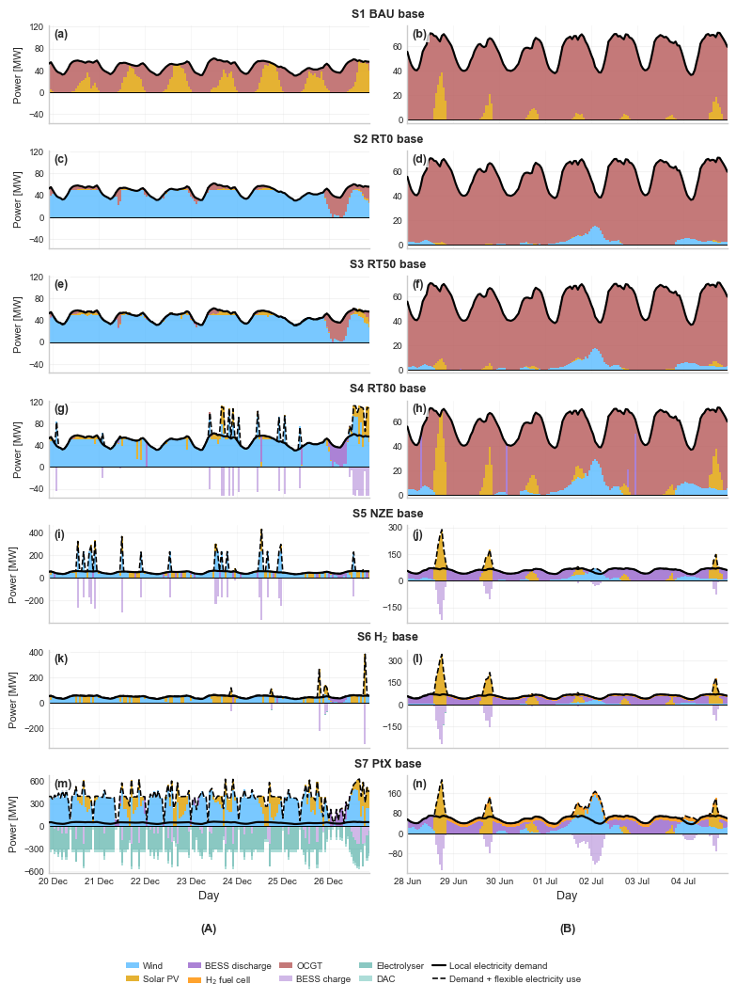

Saved figure to: output\output_punta_arenas\figures\figure_supp_dispatch_favourable_vs_critical_2050.png
Saved figure: output\output_punta_arenas\figures\figure05_dispatch_favourable_vs_critical_2050_S1_S4_S7.png


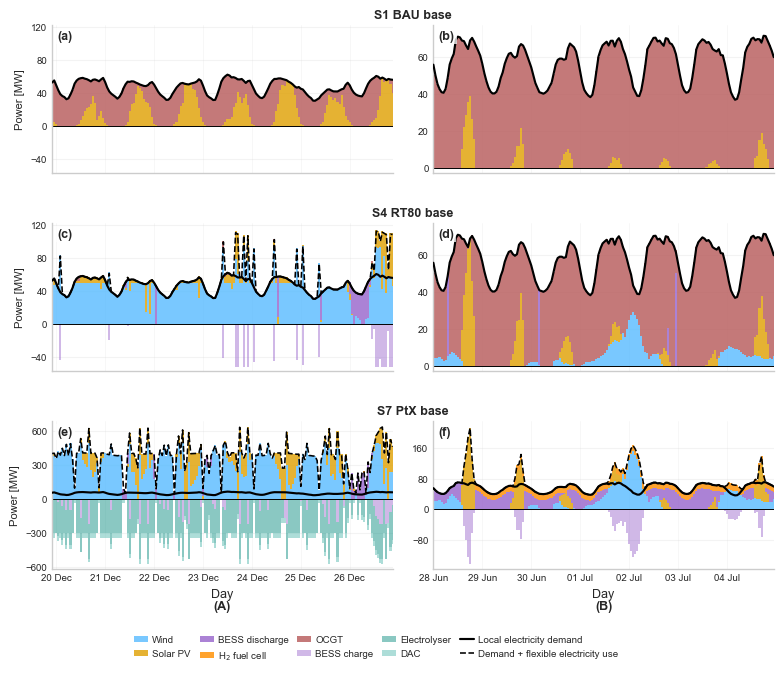

Saved figure to: output\output_punta_arenas\figures\figure05_dispatch_favourable_vs_critical_2050_S1_S4_S7.png
(A) Favourable summer period selected from NZE: 19 Dec 2050 22:00 to 26 Dec 2050 21:00.
(B) Critical-event period: 28 Jun 2050 00:00 to 04 Jul 2050 23:00.
Both columns show approximately 7 days of operation.

Power-axis limits by column and scenario group:

(A) Favourable summer period:
  BAU–RT: -56.8 to 122.4 MW
  NZE: -398.9 to 463.0 MW
  H$_2$: -350.8 to 413.3 MW
  PtX: -618.8 to 684.0 MW

(B) Critical low-renewable generation event:
  BAU–RT: -2.7 to 77.2 MW
  NZE: -236.7 to 312.5 MW
  H$_2$: -296.1 to 371.9 MW
  PtX: -156.0 to 231.8 MW


C:\Users\vse23\AppData\Local\Temp\ipykernel_55040\3105490115.py:1170: UserWarning:

obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.



,scenario,paper_label,period,period_start,period_end,local_demand_mwh,electricity_supply_mwh,flexible_electricity_use_mwh,supply_wind_mwh,supply_solar_mwh,supply_bess_mwh,supply_ocgt_mwh,supply_slack_mwh,negative_bess_charge_mwh,supply_h2_fuel_cell_mwh,negative_electrolyzer_mwh,supply_ptx_shortfall_mwh,negative_dac_mwh
0,BAU_base,BAU,summer_period,2050-12-19 22:00:00,2050-12-26 21:00:00,7941.511,7941.511,0.000,0.000,2541.583,0.000,5399.927,0.0,NaN,NaN,NaN,NaN,NaN
1,BAU_base,BAU,critical_event,2050-06-28 00:00:00,2050-07-04 23:00:00,9583.215,9583.215,0.000,0.000,420.438,0.000,9162.777,0.0,NaN,NaN,NaN,NaN,NaN
2,RT0_base,RT0,summer_period,2050-12-19 22:00:00,2050-12-26 21:00:00,7941.511,8103.008,0.000,6913.040,119.193,0.000,1070.774,0.0,NaN,NaN,NaN,NaN,NaN
3,RT0_base,RT0,critical_event,2050-06-28 00:00:00,2050-07-04 23:00:00,9583.215,9590.856,0.000,382.088,23.800,0.000,9184.969,0.0,NaN,NaN,NaN,NaN,NaN
4,RT_base,RT50,summer_period,2050-12-19 22:00:00,2050-12-26 21:00:00,7941.511,8146.175,39.513,7037.674,345.156,29.599,733.746,0.0,39.513,NaN,NaN,NaN,NaN
5,RT_base,RT50,critical_event,2050-06-28 00:00:00,2050-07-04 23:00:00,9583.215,9591.647,0.000,421.115,102.123,0.512,9067.897,0.0,0.000,NaN,NaN,NaN,NaN
6,RT80_base,RT80,summer_period,2050-12-19 22:00:00,2050-12-26 21:00:00,7941.511,9117.935,986.402,7608.276,973.425,485.145,51.089,0.0,986.402,NaN,NaN,NaN,NaN
7,RT80_base,RT80,critical_event,2050-06-28 00:00:00,2050-07-04 23:00:00,9583.215,9604.928,0.000,701.106,749.078,150.339,8004.405,0.0,0.000,NaN,NaN,NaN,NaN
8,RE_base,NZE,summer_period,2050-12-19 22:00:00,2050-12-26 21:00:00,7941.511,11984.374,3866.958,8221.496,2657.155,1105.723,0.000,0.0,3866.958,NaN,NaN,NaN,NaN
9,RE_base,NZE,critical_event,2050-06-28 00:00:00,2050-07-04 23:00:00,9583.215,11119.881,1341.604,1722.036,3098.709,6299.136,0.000,0.0,1341.604,NaN,NaN,NaN,NaN


Saved dispatch comparison summary to: output\output_punta_arenas\tables\dispatch_favourable_vs_critical_summary_2050.csv


In [20]:
# Figure 5 — Hourly dispatch under favourable and critical renewable conditions

# ── Configuration ─────────────────────────────────────────────────────────────
dispatch_comparison_year = globals().get('detailed_year', 2050)

SUMMER_MONTHS = (12, 1, 2)
SUMMER_WINDOW_DAYS = 7
CRITICAL_WINDOW_DAYS = 7

# Leave as None for automatic selection.
# Example:
# SUMMER_PERIOD_START = f"{dispatch_comparison_year}-01-15 00:00"
SUMMER_PERIOD_START = None

figure_width = max(globals().get('WORD_DOUBLE_COL_IN', 7.2), 8.2)

small_font = globals().get('FONT_SIZE_SMALL', 8)

# ── Scenario selection and labels ─────────────────────────────────────────────
def _short_scenario_label(scenario_code):
    """Return BAU, RT0, RT50, RT80, NZE, H2 or PtX."""
    text = str(scenario_code).upper().replace('-', '_')
    parts = [part for part in text.split('_') if part]
    if "PTX" in parts or "PTX" in text:
        return "PtX"
    if "RT80" in parts or "RT80" in text:
        return "RT80"
    if "RT0" in parts or "RT0" in text:
        return "RT0"
    if "RT" in parts:
        return "RT50"
    if "BAU" in parts:
        return "BAU"
    if "RE" in parts:
        return "NZE"
    if "RH" in parts:
        return r"H$_2$"
    return str(scenario_code).replace('_base', '').replace('_BASE', '')


def _scenario_row_label(scenario_code):
    """
    Use the paper scenario label when available;
    otherwise fall back to BAU, RT, NZE, H2 or PtX.
    """
    if callable(
        globals().get("scenario_label")
    ):
        label = scenario_label(scenario_code)

        # Avoid Unicode subscript glyph issue with Arial.
        if label == "H₂":
            return r"H$_2$"
        return label
    return _short_scenario_label(scenario_code)


scenario_order = ['BAU', 'RT0', 'RT50', 'RT80', 'NZE', 'H$_2$', 'PtX']

available_scenarios = list(scenario_results.keys())

dispatch_comparison_scenarios = []

for desired_label in scenario_order:
    matching_scenarios = [
        scenario_code
        for scenario_code in available_scenarios
        if _short_scenario_label(
            scenario_code
        ) == desired_label
    ]
    if not matching_scenarios:
        continue

    # Prefer the base pathway if more than one variant exists.
    matching_scenarios.sort(
        key=lambda scenario_code: (
            not str(
                scenario_code
            ).upper().endswith(
                "_BASE"
            ),
            str(scenario_code),
        )
    )
    dispatch_comparison_scenarios.append(matching_scenarios[0])
if not dispatch_comparison_scenarios:
    raise ValueError('No BAU, RT0, RT50, RT80, NZE, H2 or PtX scenarios were found.')


def _scale_group_label(scenario_code):
    """
    BAU, RT0, RT50 and RT80 share a scale.

    NZE, H2 and PtX use independent scales so that their
    operational detail is not compressed by another scenario.
    """
    label = _short_scenario_label(scenario_code)
    if label in {
        "BAU",
        "RT0",
        "RT50",
        "RT80",
    }:
        return "BAU–RT"
    return label


# ── General helpers ───────────────────────────────────────────────────────────
def _naive_datetime_index(values):
    index = pd.DatetimeIndex(pd.to_datetime(values))
    if index.tz is not None:
        index = index.tz_localize(None)
    return index


def _naive_timestamp(value):
    timestamp = pd.Timestamp(value)
    if timestamp.tz is not None:
        timestamp = timestamp.tz_localize(None)
    return timestamp


def _normalise_timeseries_index(values):
    output = values.copy()
    output.index = _naive_datetime_index(output.index)
    return output.sort_index()


def _total_local_load(result):
    load = result["load"]
    if isinstance(
        load,
        pd.Series,
    ):
        return load.copy()
    return load.sum(axis=1)


def _format_period(start, end):
    start = pd.Timestamp(start)
    end = pd.Timestamp(end)
    if (
        start.year == end.year
        and start.month == end.month
    ):
        return f'{start.day}–{end.day} {start:%b %Y}'
    if start.year == end.year:
        return f'{start.day} {start:%b}–{end.day} {end:%b %Y}'
    return f'{start.day} {start:%b %Y}–{end.day} {end:%b %Y}'


def _snapshot_hours(index):
    index = pd.DatetimeIndex(index)
    if len(index) == 0:
        return pd.Series(dtype=float, index=index)
    timestamp_series = pd.Series(index, index=index)
    durations = timestamp_series.shift(-1) - timestamp_series
    typical_duration = durations.dropna().median()
    if pd.isna(
        typical_duration
    ):
        typical_duration = pd.Timedelta(hours=1)
    durations.iloc[-1] = typical_duration
    return durations.dt.total_seconds().div(3600.0)


# ── Renewable potential for summer-period selection ──────────────────────────
def _renewable_potential_and_load(
    scenario_code,
    model_year,
):
    """
    Return available wind + solar generation potential
    and local electricity load [MW].

    Potential is installed capacity multiplied by p_max_pu,
    rather than realised dispatch.
    """
    result = scenario_results[scenario_code]['results'][model_year]
    network = result["network"]
    generator_carriers = network.generators['carrier'].astype(str)
    renewable_generators = (
        network.generators.index[
            generator_carriers.str.contains(
                r"wind|solar|pv",
                case=False,
                regex=True,
            )
        ]
    )
    if len(
        renewable_generators
    ) == 0:
        return None, None
    p_nom_fallback = pd.to_numeric(
        network.generators.get(
            "p_nom",
            pd.Series(
                0.0,
                index=network.generators.index,
            ),
        ),
        errors="coerce",
    ).fillna(0.0)
    p_nom = pd.to_numeric(
        network.generators.get(
            "p_nom_opt",
            pd.Series(
                np.nan,
                index=network.generators.index,
            ),
        ),
        errors="coerce",
    ).fillna(
        p_nom_fallback
    )
    p_nom = p_nom.reindex(renewable_generators).fillna(0.0)
    static_p_max_pu = pd.to_numeric(
        network.generators.get(
            "p_max_pu",
            pd.Series(
                1.0,
                index=network.generators.index,
            ),
        ),
        errors="coerce",
    ).fillna(1.0)
    dynamic_p_max_pu = getattr(
        network.generators_t,
        "p_max_pu",
        pd.DataFrame(
            index=network.snapshots
        ),
    )
    p_max_pu = (
        dynamic_p_max_pu
        .reindex(
            index=network.snapshots,
            columns=renewable_generators,
        )
        .copy()
    )
    for generator in renewable_generators:
        p_max_pu[generator] = (
            pd.to_numeric(
                p_max_pu[generator],
                errors="coerce",
            )
            .fillna(
                float(
                    static_p_max_pu.get(
                        generator,
                        1.0,
                    )
                )
            )
        )
    renewable_potential = p_max_pu.multiply(p_nom, axis=1).sum(axis=1)
    renewable_potential.index = _naive_datetime_index(renewable_potential.index)
    local_load = _total_local_load(result)
    local_load.index = _naive_datetime_index(local_load.index)
    local_load = local_load.reindex(renewable_potential.index).fillna(0.0)
    return (renewable_potential.sort_index(), local_load.sort_index())


# Prefer NZE for selecting the favourable weather period.
summer_reference_rank = {'NZE': 0, 'H$_2$': 1, 'PtX': 2, 'RT80': 3, 'RT50': 4, 'BAU': 5}

summer_reference_preferences = sorted(
    dispatch_comparison_scenarios,
    key=lambda scenario_code: (
        summer_reference_rank.get(
            _short_scenario_label(
                scenario_code
            ),
            99,
        )
    ),
)

summer_reference_scenario = None
reference_renewable_potential = None
reference_local_load = None

for candidate in summer_reference_preferences:
    if (
        dispatch_comparison_year
        not in scenario_results[
            candidate
        ]["results"]
    ):
        continue
    candidate_potential, candidate_load = (
        _renewable_potential_and_load(
            candidate,
            dispatch_comparison_year,
        )
    )
    if (
        candidate_potential is not None
        and candidate_potential.max() > 1e-6
    ):
        summer_reference_scenario = candidate
        reference_renewable_potential = candidate_potential
        reference_local_load = candidate_load
        break
if summer_reference_scenario is None:
    raise ValueError(
        "No scenario with wind or solar capacity was found "
        "to identify the favourable summer period."
    )

# ── Determine snapshot interval ───────────────────────────────────────────────
reference_index = reference_renewable_potential.index

if len(reference_index) < 2:
    raise ValueError('Not enough snapshots to select comparison periods.')
snapshot_interval = reference_index.to_series().diff().dropna().median()

if (
    pd.isna(snapshot_interval)
    or snapshot_interval <= pd.Timedelta(0)
):
    raise ValueError('Could not determine the snapshot interval.')

# ── Select the favourable 7-day summer period ────────────────────────────────
summer_window_steps = int(
    round(
        pd.Timedelta(
            days=SUMMER_WINDOW_DAYS
        )
        / snapshot_interval
    )
)

summer_window_steps = max(summer_window_steps, 1)

if SUMMER_PERIOD_START is not None:
    summer_period_start = _naive_timestamp(SUMMER_PERIOD_START)
    matching_positions = np.flatnonzero(reference_index == summer_period_start)
    if len(matching_positions) == 0:
        raise ValueError(
            f"SUMMER_PERIOD_START={SUMMER_PERIOD_START} "
            "is not a model snapshot."
        )
    start_position = int(matching_positions[0])
    end_position = start_position + summer_window_steps - 1
    if end_position >= len(
        reference_index
    ):
        raise ValueError(
            "The manually selected summer period extends "
            "beyond the available snapshots."
        )
    summer_period_end = reference_index[end_position]
else:
    summer_snapshot_mask = pd.Series(
        reference_index.month.isin(
            SUMMER_MONTHS
        ).astype(float),
        index=reference_index,
    )
    complete_summer_window = (
        summer_snapshot_mask
        .rolling(
            window=summer_window_steps,
            min_periods=summer_window_steps,
        )
        .sum()
        .eq(
            float(
                summer_window_steps
            )
        )
    )
    rolling_renewable_potential = (
        reference_renewable_potential
        .rolling(
            window=summer_window_steps,
            min_periods=summer_window_steps,
        )
        .sum()
    )
    rolling_local_load = (
        reference_local_load
        .rolling(
            window=summer_window_steps,
            min_periods=summer_window_steps,
        )
        .sum()
    )
    favourable_period_score = (
        rolling_renewable_potential
        .div(
            rolling_local_load.replace(
                0.0,
                np.nan,
            )
        )
        .where(
            complete_summer_window
        )
    )
    valid_scores = favourable_period_score.dropna()
    if valid_scores.empty:
        raise ValueError('No complete seven-day summer period was found.')
    summer_period_end = valid_scores.idxmax()
    end_position = int(reference_index.get_loc(summer_period_end))
    start_position = end_position - summer_window_steps + 1
    summer_period_start = reference_index[start_position]

# ── Select the first 7 days of the critical event ─────────────────────────────
critical_event_start_clean = _naive_timestamp(critical_event_start)

critical_event_end_clean = _naive_timestamp(critical_event_end)

critical_period_start = critical_event_start_clean

critical_candidate_end = (
    critical_period_start
    + pd.Timedelta(
        days=CRITICAL_WINDOW_DAYS
    )
    - snapshot_interval
)

critical_period_end = min(critical_event_end_clean, critical_candidate_end)

# ── Period definitions: left (A), right (B) ──────────────────────────────────
period_definitions = [
    {
        "key": "summer_period",
        "column_label": "(A)",
        "description": (
            "Favourable summer period"
        ),
        "start": summer_period_start,
        "end": summer_period_end,
    },
    {
        "key": "critical_event",
        "column_label": "(B)",
        "description": (
            "Critical low-renewable generation event"
        ),
        "start": critical_period_start,
        "end": critical_period_end,
    },
]

# ── Prepare dispatch data ─────────────────────────────────────────────────────
dispatch_period_data = {}
dispatch_comparison_rows = []

for scenario_code in dispatch_comparison_scenarios:
    package = scenario_results[scenario_code]
    if (
        dispatch_comparison_year
        not in package["results"]
    ):
        raise ValueError(
            f"{scenario_code} has no result for "
            f"{dispatch_comparison_year}."
        )
    result = package['results'][dispatch_comparison_year]
    network = result["network"]
    supply, consumption = _electricity_balance_for_network(network)
    supply = _normalise_timeseries_index(supply).fillna(0.0)
    consumption = _normalise_timeseries_index(consumption).fillna(0.0)
    local_load = _normalise_timeseries_index(_total_local_load(result)).fillna(0.0)
    consumption = consumption.reindex(supply.index, fill_value=0.0).fillna(0.0)
    local_load = local_load.reindex(supply.index).fillna(0.0)
    for period in period_definitions:
        period_mask = (
            (supply.index >= period["start"])
            & (supply.index <= period["end"])
        )
        supply_period = supply.loc[period_mask].copy()
        consumption_period = consumption.loc[period_mask].copy()
        load_period = local_load.loc[period_mask].copy()
        if supply_period.empty:
            raise ValueError(
                f"No snapshots found for {scenario_code}, "
                f"{period['description']}: "
                f"{period['start']} to {period['end']}."
            )
        dispatch_period_data[
            (
                scenario_code,
                period["key"],
            )
        ] = {
            "supply": supply_period,
            "consumption": consumption_period,
            "load": load_period,
        }
        snapshot_hours = _snapshot_hours(supply_period.index)
        supply_energy = supply_period.mul(snapshot_hours, axis=0)
        consumption_energy = consumption_period.mul(snapshot_hours, axis=0)
        load_energy = load_period * snapshot_hours
        summary_row = {
            "scenario": scenario_code,
            "paper_label": (
                _short_scenario_label(
                    scenario_code
                )
            ),
            "period": period["key"],
            "period_start": (
                supply_period.index.min()
            ),
            "period_end": (
                supply_period.index.max()
            ),
            "local_demand_mwh": float(
                load_energy.sum()
            ),
            "electricity_supply_mwh": float(
                supply_energy.sum().sum()
            ),
            "flexible_electricity_use_mwh": float(
                consumption_energy.sum().sum()
            ),
        }
        for column in supply_energy.columns:
            summary_row[f'supply_{column}_mwh'] = float(supply_energy[column].sum())
        for column in consumption_energy.columns:
            summary_row[
                f"negative_{column}_mwh"
            ] = float(
                consumption_energy[
                    column
                ].sum()
            )
        dispatch_comparison_rows.append(summary_row)

# ── Grouped y-axis limits within each column ──────────────────────────────────
scale_group_members = {}

for scenario_code in dispatch_comparison_scenarios:
    group_label = _scale_group_label(scenario_code)
    scale_group_members.setdefault(group_label, []).append(scenario_code)


def _calculate_group_ylim(
    period_key,
    scenario_codes,
):
    positive_max = 1.0
    negative_max = 0.0
    for scenario_code in scenario_codes:
        data = dispatch_period_data[scenario_code, period_key]
        supply_period = data['supply'].clip(lower=0.0)
        consumption_period = data['consumption'].clip(lower=0.0)
        load_period = data['load'].clip(lower=0.0)
        flexible_use = consumption_period.sum(axis=1)
        total_supply = supply_period.sum(axis=1)
        total_electricity_use = load_period + flexible_use
        positive_max = max(
            positive_max,
            float(
                total_supply.max()
            ),
            float(
                load_period.max()
            ),
            float(
                total_electricity_use.max()
            ),
        )
        negative_max = max(negative_max, float(flexible_use.max()))
    upper_limit = 1.08 * positive_max
    if negative_max > 1e-6:
        lower_limit = -1.08 * negative_max
    else:
        lower_limit = -0.035 * upper_limit
    return (lower_limit, upper_limit)


period_group_y_limits = {}

for period in period_definitions:
    for (
        group_label,
        scenario_codes,
    ) in scale_group_members.items():
        period_group_y_limits[
            (
                period["key"],
                group_label,
            )
        ] = _calculate_group_ylim(
            period["key"],
            scenario_codes,
        )

# ── Plotting colours and labels ───────────────────────────────────────────────
fallback_colors = {
    "wind": "#5bbcff",
    "solar": "#ffd54f",
    "hydro": "#4fc3f7",
    "bess": "#8e6bbf",
    "h2_fuel_cell": "#2ca58d",
    "h2_turbine": "#158f75",
    "ocgt": "#7f7f7f",
    "gas": "#9e9e9e",
    "natural_gas": "#9e9e9e",
    "diesel": "#4d4d4d",
    "slack": "#d62728",
    "electrolyzer": "#00a6a6",
    "electrolyser": "#00a6a6",
    "asu": "#e67e22",
    "dac": "#c44e52",
}

plot_colors = fallback_colors.copy()

plot_colors.update(globals().get('TECH_COLORS', {}))


def _dispatch_color(carrier):
    color_key = 'bess' if carrier == 'bess_charge' else carrier
    return plot_colors.get(
        color_key,
        "#999999",
    )


def _dispatch_legend_label(carrier):
    label_overrides = {
        "bess": "BESS discharge",
        "bess_charge": "BESS charge",
        "electrolyzer": "Electrolyser",
        "electrolyser": "Electrolyser",
        "asu": "ASU",
        "dac": "DAC",
        "h2_fuel_cell": (
            r"H$_2$ fuel cell"
        ),
        "h2_turbine": (
            r"H$_2$ turbine"
        ),
        "ocgt": "OCGT",
        "slack": "Slack",
    }
    if carrier in label_overrides:
        return label_overrides[carrier]
    if callable(
        globals().get(
            "clean_technology_label"
        )
    ):
        return clean_technology_label(carrier)
    return str(carrier).replace('_', ' ').title()


def _add_panel_label(
    ax,
    text,
):
    if callable(
        globals().get(
            "panel_label"
        )
    ):
        panel_label(ax, text)
    else:
        ax.text(
            0.012,
            0.97,
            text,
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=small_font,
            fontweight="bold",
        )


# ── Individual panel ──────────────────────────────────────────────────────────
def _plot_dispatch_panel(
    ax,
    supply_period,
    consumption_period,
    load_period,
    y_limits,
    panel_text,
    show_ylabel,
):
    active_supply_columns = [
        column
        for column in supply_period.columns
        if (
            supply_period[column]
            .clip(lower=0.0)
            .sum()
            > 1e-6
        )
    ]
    if active_supply_columns:
        ax.stackplot(
            supply_period.index,
            *[
                (
                    supply_period[column]
                    .fillna(0.0)
                    .clip(lower=0.0)
                    .to_numpy()
                )
                for column
                in active_supply_columns
            ],
            colors=[
                _dispatch_color(
                    column
                )
                for column
                in active_supply_columns
            ],
            alpha=0.82,
            linewidth=0.0,
            step="mid",
        )
    negative_stack = np.zeros(len(consumption_period), dtype=float)
    for column in consumption_period.columns:
        values = consumption_period[column].fillna(0.0).clip(lower=0.0).to_numpy()
        if values.sum() <= 1e-6:
            continue
        previous_stack = negative_stack.copy()
        negative_stack += values
        ax.fill_between(
            consumption_period.index,
            -previous_stack,
            -negative_stack,
            step="mid",
            color=_dispatch_color(
                column
            ),
            alpha=0.46,
            linewidth=0.0,
        )
    flexible_use = consumption_period.clip(lower=0.0).sum(axis=1)
    total_electricity_use = load_period + flexible_use
    ax.plot(load_period.index, load_period, color='black', linewidth=1.55, zorder=5)
    if flexible_use.sum() > 1e-6:
        ax.plot(
            total_electricity_use.index,
            total_electricity_use,
            color="black",
            linewidth=1.15,
            linestyle="--",
            zorder=5,
        )
    ax.axhline(0.0, color='black', linewidth=0.7)
    ax.set_xlim(supply_period.index.min(), supply_period.index.max())
    ax.set_ylim(y_limits)
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.margins(x=0.0)
    ax.set_ylabel('Power [MW]' if show_ylabel else '', fontsize=small_font)
    ax.grid(axis='y', alpha=0.22)
    ax.set_axisbelow(True)
    ax.tick_params(labelsize=small_font - 1)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    _add_panel_label(ax, panel_text)
    if ax.get_legend() is not None:
        ax.get_legend().remove()


# ── Shared legend ─────────────────────────────────────────────────────────────
def _combined_dispatch_legend(
    selected_scenarios=None,
):
    """
    Build a shared legend using only carriers present
    in the scenarios included in the figure.
    """
    if selected_scenarios is None:
        selected_scenarios = dispatch_comparison_scenarios
    used_supply_carriers = set()
    used_consumption_carriers = set()
    has_flexible_use = False
    for scenario_code in selected_scenarios:
        for period in period_definitions:
            data = dispatch_period_data[scenario_code, period['key']]
            for column in data[
                "supply"
            ].columns:
                if (
                    data["supply"][column]
                    .clip(lower=0.0)
                    .sum()
                    > 1e-6
                ):
                    used_supply_carriers.add(column)
            for column in data[
                "consumption"
            ].columns:
                if (
                    data["consumption"][column]
                    .clip(lower=0.0)
                    .sum()
                    > 1e-6
                ):
                    used_consumption_carriers.add(column)
                    has_flexible_use = True
    preferred_supply_order = [
        "wind",
        "solar",
        "hydro",
        "bess",
        "h2_fuel_cell",
        "h2_turbine",
        "ocgt",
        "gas",
        "natural_gas",
        "diesel",
        "slack",
    ]
    ordered_supply_carriers = [
        carrier
        for carrier in preferred_supply_order
        if carrier in used_supply_carriers
    ]
    ordered_supply_carriers += sorted(
        carrier
        for carrier in used_supply_carriers
        if carrier not in ordered_supply_carriers
    )
    preferred_consumption_order = [
        "bess_charge",
        "electrolyzer",
        "electrolyser",
        "asu",
        "dac",
    ]
    ordered_consumption_carriers = [
        carrier
        for carrier in preferred_consumption_order
        if carrier in used_consumption_carriers
    ]
    ordered_consumption_carriers += sorted(
        carrier
        for carrier in used_consumption_carriers
        if carrier not in ordered_consumption_carriers
    )
    handles = []
    labels = []
    seen_labels = set()
    for carrier in ordered_supply_carriers:
        label = _dispatch_legend_label(carrier)
        if label in seen_labels:
            continue
        handles.append(
            Patch(
                facecolor=_dispatch_color(
                    carrier
                ),
                edgecolor="none",
                alpha=0.82,
            )
        )
        labels.append(label)
        seen_labels.add(label)
    for carrier in ordered_consumption_carriers:
        label = _dispatch_legend_label(carrier)
        if label in seen_labels:
            continue
        handles.append(
            Patch(
                facecolor=_dispatch_color(
                    carrier
                ),
                edgecolor="none",
                alpha=0.46,
            )
        )
        labels.append(label)
        seen_labels.add(label)
    handles.append(Line2D([0], [0], color='black', linewidth=1.55))
    labels.append('Local electricity demand')
    if has_flexible_use:
        handles.append(Line2D([0], [0], color='black', linewidth=1.15, linestyle='--'))
        labels.append('Demand + flexible electricity use')
    return handles, labels


# ── Figure builder ────────────────────────────────────────────────────────────
def _build_dispatch_figure(
    selected_scenarios,
    filename_suffix="",
    row_height=1.55,
    minimum_height=5.2,
    bottom_margin=0.14,
    hspace=0.28,
):
    """
    Plot favourable-versus-critical dispatch for a selected set of scenarios.

    The full seven-scenario figure and a reduced S1/S4/S7 paper figure are
    produced from the same pre-computed dispatch data.
    """
    number_of_rows = len(selected_scenarios)
    if number_of_rows == 0:
        raise ValueError('No scenarios were provided to _build_dispatch_figure().')
    fig, axes = plt.subplots(
        nrows=number_of_rows,
        ncols=2,
        figsize=(
            figure_width,
            max(
                minimum_height,
                row_height * number_of_rows,
            ),
        ),
        sharex="col",
        sharey=False,
        squeeze=False,
    )
    subplot_letters = list('abcdefghijklmnopqrstuvwxyz')
    letter_index = 0
    scenario_row_axes = []
    for row_index, scenario_code in enumerate(
        selected_scenarios
    ):
        group_label = _scale_group_label(scenario_code)
        for column_index, period in enumerate(
            period_definitions
        ):
            axis = axes[row_index, column_index]
            data = dispatch_period_data[scenario_code, period['key']]
            y_limits = period_group_y_limits[period['key'], group_label]
            _plot_dispatch_panel(
                ax=axis,
                supply_period=data["supply"],
                consumption_period=data[
                    "consumption"
                ],
                load_period=data["load"],
                y_limits=y_limits,
                panel_text=(
                    f"("
                    f"{subplot_letters[letter_index]}"
                    f")"
                ),
                show_ylabel=(
                    column_index == 0
                ),
            )
            letter_index += 1
        scenario_row_axes.append(
            (
                axes[row_index, 0],
                axes[row_index, 1],
                _scenario_row_label(
                    scenario_code
                ),
            )
        )

    # Hide x labels except on the bottom row.
    for row_index in range(
        number_of_rows - 1
    ):
        for column_index in range(2):
            axes[row_index, column_index].tick_params(axis='x', labelbottom=False)

    # Daily vertical grid and explicit day labels for the 7-day windows.
    for column_index in range(2):
        day_locator = mdates.DayLocator(interval=1)
        for row_index in range(number_of_rows):
            axis = axes[row_index, column_index]
            axis.xaxis.set_major_locator(day_locator)
            axis.grid(axis="x", alpha=0.18, linewidth=0.6)
        axes[-1, column_index].xaxis.set_major_formatter(
            mdates.DateFormatter("%d %b")
        )
        axes[-1, column_index].tick_params(axis="x", rotation=0)
        axes[-1, column_index].set_xlabel("Day")

    # Layout
    fig.subplots_adjust(
        top=0.97,
        bottom=bottom_margin,
        left=0.105,
        right=0.985,
        hspace=hspace,
        wspace=0.12,
    )
    fig.canvas.draw()

    # Horizontal scenario labels above each row.
    for (
        left_axis,
        right_axis,
        label,
    ) in scenario_row_axes:
        left_position = left_axis.get_position()
        right_position = right_axis.get_position()
        row_centre = (left_position.x0 + right_position.x1) / 2.0
        row_top = max(left_position.y1, right_position.y1)
        fig.text(
            row_centre,
            row_top + 0.005,
            label,
            ha="center",
            va="bottom",
            fontsize=small_font + 1,
            fontweight="bold",
        )

    # ── Column labels (A) and (B) ─────────────────────────────────────────────
    left_position = axes[-1, 0].get_position()
    right_position = axes[-1, 1].get_position()
    left_column_centre = (left_position.x0 + left_position.x1) / 2.0
    right_column_centre = (right_position.x0 + right_position.x1) / 2.0
    column_label_y = max(0.045, bottom_margin - 0.055)
    fig.text(
        left_column_centre,
        column_label_y,
        "(A)",
        ha="center",
        va="center",
        fontsize=small_font + 1,
        fontweight="bold",
    )
    fig.text(
        right_column_centre,
        column_label_y,
        "(B)",
        ha="center",
        va="center",
        fontsize=small_font + 1,
        fontweight="bold",
    )

    # ── Shared legend ──────────────────────────────────────────────────────────
    # Only technologies appearing in the selected scenarios are shown.
    legend_handles, legend_labels = _combined_dispatch_legend(selected_scenarios)
    legend_ncol = min(5, max(1, len(legend_labels)))
    fig.legend(
        legend_handles,
        legend_labels,
        loc="lower center",
        bbox_to_anchor=(
            0.5,
            0.02,
        ),
        ncol=legend_ncol,
        frameon=False,
        fontsize=small_font - 1,
        columnspacing=0.9,
        handlelength=1.45,
        handletextpad=0.4,
    )

    # ── Export figure ──────────────────────────────────────────────────────────
    figure_prefix = "figure05" if filename_suffix == "_S1_S4_S7" else "figure_supp"
    figure_filename = (
        f"{figure_prefix}_dispatch_favourable_vs_critical_"
        f"{dispatch_comparison_year}{filename_suffix}.png"
    )
    if callable(
        globals().get(
            "save_paper_figure"
        )
    ):
        figure_path = save_paper_figure(fig, figure_filename)
    else:
        figure_path = Path(figure_filename)
        fig.savefig(figure_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f'Saved figure to: {figure_path}')
    return (fig, axes, figure_path)


# ── Supplementary diagnostic: all seven scenarios ─────────────────────────────────────────────
dispatch_comparison_fig_all, \
dispatch_comparison_axes_all, \
dispatch_comparison_figure_path = (
    _build_dispatch_figure(
        selected_scenarios=(
            dispatch_comparison_scenarios
        ),
        filename_suffix="",
        row_height=1.55,
        minimum_height=9.3,
        bottom_margin=0.14,
        hspace=0.28,
    )
)

# ── Figure 5: paper view — S1, S4 and S7 ──────────────────────────────
# S1 = BAU
# S4 = RT80
# S7 = PtX
#
# This version uses taller rows so hourly operation is easier to read.
subset_labels = {'BAU', 'RT80', 'PtX'}

dispatch_subset_scenarios = [
    scenario_code
    for scenario_code
    in dispatch_comparison_scenarios
    if _short_scenario_label(
        scenario_code
    ) in subset_labels
]

missing_subset_labels = (
    subset_labels
    - {
        _short_scenario_label(
            scenario_code
        )
        for scenario_code
        in dispatch_subset_scenarios
    }
)

if missing_subset_labels:
    raise ValueError(
        "Could not build the S1/S4/S7 figure because "
        "these scenario labels are missing: "
        f"{sorted(missing_subset_labels)}"
    )
dispatch_comparison_fig_subset, \
dispatch_comparison_axes_subset, \
dispatch_comparison_subset_path = (
    _build_dispatch_figure(
        selected_scenarios=(
            dispatch_subset_scenarios
        ),
        filename_suffix="_S1_S4_S7",
        row_height=2.15,
        minimum_height=6.8,
        bottom_margin=0.17,
        hspace=0.34,
    )
)

# ── Period and scale information ──────────────────────────────────────────────
print(
    "(A) Favourable summer period selected from "
    f"{_short_scenario_label(summer_reference_scenario)}: "
    f"{summer_period_start:%d %b %Y %H:%M} to "
    f"{summer_period_end:%d %b %Y %H:%M}."
)

print(
    "(B) Critical-event period: "
    f"{critical_period_start:%d %b %Y %H:%M} to "
    f"{critical_period_end:%d %b %Y %H:%M}."
)

print(f'Both columns show approximately {SUMMER_WINDOW_DAYS} days of operation.')

print('\nPower-axis limits by column and scenario group:')

for period in period_definitions:
    print(f"\n{period['column_label']} {period['description']}:")
    for group_label in scale_group_members:
        limits = period_group_y_limits[period['key'], group_label]
        print(f'  {group_label}: {limits[0]:.1f} to {limits[1]:.1f} MW')

# ── Export comparison summary ─────────────────────────────────────────────────
dispatch_comparison_summary = pd.DataFrame(dispatch_comparison_rows)

display(dispatch_comparison_summary.round(3))

table_export_dir = Path(globals().get('TABLE_EXPORT_DIR', '.'))

table_export_dir.mkdir(parents=True, exist_ok=True)

dispatch_comparison_summary_path = (
    table_export_dir
    / (
        "dispatch_favourable_vs_critical_summary_"
        f"{dispatch_comparison_year}.csv"
    )
)

dispatch_comparison_summary.to_csv(dispatch_comparison_summary_path, index=False)

print(f'Saved dispatch comparison summary to: {dispatch_comparison_summary_path}')


### Figure 6 — Investment robustness across meteorological years and complementary critical-year planning

Re-optimises the full PtX pathway for each 2016–2025 weather year and compares the resulting 2050 designs. Two additional **sequential constrained designs** (2020→2024 and 2024→2020) can be generated to test planning that incorporates both the longest-event and highest-cumulative-exposure indicators while preserving first-stage capacities as lower bounds.

*v17.3: Figure 6(a) also reports methanol product-storage capacity; product Store capacities are labelled in tonnes rather than MWh.*

In [21]:
# ─────────────────────────────────────────────────────────────────────────────
# PtX weather-year design sensitivity
#
# Re-optimise the COMPLETE myopic PtX_base pathway for every meteorological year:
#
#   weather years : 2016–2025
#   planning years: 2025, 2030, 2040, 2050
#
# => 10 weather years × 4 planning years = 40 optimisations
#
# DIFFERENCE FROM THE PREVIOUS ROBUSTNESS TEST:
#   Previous:
#       optimise once with 2020 -> fix capacities -> re-dispatch other weather years
#
#   Here:
#       re-optimise capacities independently for EACH weather year,
#       while preserving the full 2025→2030→2040→2050 myopic pathway.
#
# IMPORTANT:
#   The same PtX scenario assumptions and the same CO2 caps used in the main
#   critical-weather-year run are retained for all weather years.
#   Therefore, weather is the only experimental dimension changed.
# ─────────────────────────────────────────────────────────────────────────────

# ══════════════════════════════════════════════════════════════════════════════
# 0. CONTROLS
# ══════════════════════════════════════════════════════════════════════════════
PTX_SENSITIVITY_SCENARIO = "PTX_base"

PTX_SENSITIVITY_WEATHER_YEARS = list(range(2016, 2026))

PTX_SENSITIVITY_PLANNING_YEARS = [2025, 2030, 2040, 2050]

PTX_SENSITIVITY_REFERENCE_WEATHER_YEAR = 2020

PTX_SENSITIVITY_CUTOUT_DIR = Path("data")
PTX_SENSITIVITY_CUTOUT_PREFIX = "magallanes"

PTX_SENSITIVITY_OUTPUT_DIR = Path(OUTPUT_ROOT) / "ptx_weather_design_sensitivity"

PTX_SENSITIVITY_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Keep only the ten 2050 networks in memory.
# The complete 2025–2050 pathways are exported to CSV after each weather run.
KEEP_2050_NETWORKS = True

# Optional: save the ten 2050 networks as NetCDF if the notebook's safe
# exporter is available.
SAVE_2050_NETWORK_NETCDF = True

# ══════════════════════════════════════════════════════════════════════════════
# 1. CHECK REQUIRED NOTEBOOK OBJECTS
# ══════════════════════════════════════════════════════════════════════════════
required_globals = [
    "config",
    "scenario_results",
    "paths_base",
    "_demand_csv_for_scenario",
    "_scenario_optional_csv",
    "_load_ptx_monthly_demand_for_scenario",
    "base_case_name",
    "solver_name",
    "time_limit",
    "mip_gap",
    "threads",
    "enable_heat",
    "enable_year_linking",
    "fallback_to_highs",
    "vre_profile_method",
    "wind_turbine",
    "solar_panel",
    "solar_orientation",
    "estimate_cost_breakdown_from_network",
]

missing_globals = [name for name in required_globals if name not in globals()]

if missing_globals:
    raise RuntimeError(
        "Run the main scenario-definition / simulation cells first. Missing objects:\n  " + "\n  ".join(missing_globals)
    )
if PTX_SENSITIVITY_SCENARIO not in scenario_results:
    raise KeyError(
        f"{PTX_SENSITIVITY_SCENARIO} is not available in scenario_results. Run the main PtX_base scenario first."
    )

# ══════════════════════════════════════════════════════════════════════════════
# 2. GET PtX SCENARIO AND HOLD POLICY ASSUMPTIONS FIXED
# ══════════════════════════════════════════════════════════════════════════════
ptx_reference_package = scenario_results[PTX_SENSITIVITY_SCENARIO]

ptx_scenario = dict(ptx_reference_package["metadata"])

# Keep the CO2 pathway from the main 2020 PtX run.
ptx_fixed_co2_caps = ptx_reference_package.get("co2_cap_tons")

if ptx_fixed_co2_caps is None:
    if "_co2_cap_from_policy" in globals() and "bau_co2_by_year" in globals():
        ptx_fixed_co2_caps = _co2_cap_from_policy(
            ptx_scenario["co2_policy"],
            bau_co2_by_year,
        )
    else:
        raise RuntimeError("Could not recover the PtX CO2-cap pathway. The main PTX_base run should be executed first.")
if isinstance(
    ptx_fixed_co2_caps,
    dict,
):
    ptx_fixed_co2_caps = {int(year): value for year, value in ptx_fixed_co2_caps.items()}
print("=" * 72)
print("PtX WEATHER-YEAR DESIGN SENSITIVITY")
print("=" * 72)

print(f"Scenario       : {PTX_SENSITIVITY_SCENARIO}")

print(f"Weather years  : {PTX_SENSITIVITY_WEATHER_YEARS[0]}–{PTX_SENSITIVITY_WEATHER_YEARS[-1]}")

print(f"Planning years : {PTX_SENSITIVITY_PLANNING_YEARS}")

print("CO2 caps       : fixed to the main PtX pathway")

print(f"Year-linking   : {enable_year_linking}")

# ══════════════════════════════════════════════════════════════════════════════
# 3. CHECK EXISTING WEATHER CUTOUTS
# ══════════════════════════════════════════════════════════════════════════════
missing_cutouts = []

for weather_year in PTX_SENSITIVITY_WEATHER_YEARS:
    cutout_path = PTX_SENSITIVITY_CUTOUT_DIR / (f"{PTX_SENSITIVITY_CUTOUT_PREFIX}_{weather_year}.nc")
    if not cutout_path.exists():
        missing_cutouts.append(cutout_path)
if missing_cutouts:
    raise FileNotFoundError(
        "The following existing ERA5 cutouts were not found:\n"
        + "\n".join(str(path.resolve()) for path in missing_cutouts)
    )

# Check that the current config supports an explicit cutout file.
run_signature = inspect.signature(config.run_case_multiple_years).parameters

if "cutout_file" not in run_signature:
    raise RuntimeError(
        "The current config.run_case_multiple_years does not expose "
        "'cutout_file'. Update/reload the current config.py before "
        "running this sensitivity."
    )

# ══════════════════════════════════════════════════════════════════════════════
# 4. PREPARE PtX INPUT FILES
# ══════════════════════════════════════════════════════════════════════════════
demand_file, demand_summary_file = _demand_csv_for_scenario(ptx_scenario)

ptx_paths = dict(paths_base)

ptx_paths["csv_demand"] = demand_file

ptx_paths["csv_demand_summary"] = demand_summary_file

# Scenario-specific files when available, base files otherwise.
for base_name, path_key in [
    (
        "generators_capacity",
        "csv_capacity",
    ),
    (
        "storage_capacity",
        "csv_storage",
    ),
    (
        "hydrogen_assets",
        "csv_hydrogen",
    ),
    (
        "costs",
        "csv_costs",
    ),
    (
        "ptx_assets",
        "csv_ptx_assets",
    ),
    (
        "ptx_monthly_demand",
        "csv_ptx_monthly_demand",
    ),
]:
    ptx_paths[path_key] = _scenario_optional_csv(base_name, PTX_SENSITIVITY_SCENARIO)
ptx_monthly_demand_df = _load_ptx_monthly_demand_for_scenario(
    ptx_scenario,
    ptx_paths["csv_ptx_monthly_demand"],
)

# ══════════════════════════════════════════════════════════════════════════════
# 5. SUMMARY HELPERS
# ══════════════════════════════════════════════════════════════════════════════
def _opt_capacity(
    table,
    nominal_column,
    optimal_column,
):
    """Return solved/fixed nominal capacity."""
    if table is None or table.empty:
        return pd.Series(dtype=float)
    nominal = pd.to_numeric(
        table.get(
            nominal_column,
            pd.Series(
                0.0,
                index=table.index,
            ),
        ),
        errors="coerce",
    ).fillna(0.0)
    if optimal_column in table.columns:
        optimal = pd.to_numeric(table[optimal_column], errors='coerce')
        return optimal.fillna(nominal)
    return nominal


def _asset_text(
    table,
):
    """Carrier + asset id, lowercase, for flexible matching."""
    if table is None or table.empty:
        return pd.Series(dtype=str)
    carrier = (
        table.get(
            "carrier",
            pd.Series(
                "",
                index=table.index,
            ),
        )
        .fillna("")
        .astype(str)
        .str.lower()
    )
    names = pd.Series(table.index.astype(str), index=table.index).str.lower()
    return carrier + " " + names


def _contains_any(
    text,
    patterns,
):
    if text.empty:
        return pd.Series(False, index=text.index)
    pattern = "|".join(patterns)
    return text.str.contains(pattern, case=False, regex=True, na=False)


def _snapshot_weights(
    net,
):
    """Annualisation weights."""
    index = pd.Index(net.snapshots)
    try:
        values = net.snapshot_weightings["objective"]
    except Exception:
        try:
            values = net.snapshot_weightings.objective
        except Exception:
            values = np.ones(len(index))
    values = np.asarray(values, dtype=float).reshape(-1)
    if len(values) != len(index):
        values = np.ones(len(index))
    return pd.Series(values, index=index)


def _weighted_sum(
    series,
    weights,
):
    if series is None:
        return 0.0
    series = (
        pd.to_numeric(
            series,
            errors="coerce",
        )
        .fillna(0.0)
        .reindex(weights.index)
        .fillna(0.0)
    )
    return float((series * weights).sum())


def _transmission_capacity(
    net,
):
    """
    Installed electrical transfer capacity [MW].

    Avoid double-counting the standard *_fwd / *_rev pair.
    """
    total = 0.0

    # Link-based transmission
    if len(net.links) > 0:
        link_text = _asset_text(net.links)
        electrical = net.links["bus0"].astype(str).str.startswith("elec_") & net.links["bus1"].astype(
            str
        ).str.startswith("elec_")
        if "carrier" in net.links.columns:
            electrical &= net.links["carrier"].astype(str).str.lower().eq("electricity")
        tx = net.links.loc[electrical]
        capacities = _opt_capacity(tx, 'p_nom', 'p_nom_opt')
        selected = []
        for link_id in tx.index:
            name = str(link_id)
            if name.endswith("_rev") and (f"{name[:-4]}_fwd" in tx.index):
                continue
            selected.append(link_id)
        total += float(capacities.reindex(selected).fillna(0.0).sum())

    # PyPSA Lines, if used
    if len(net.lines) > 0:
        line_capacity = _opt_capacity(net.lines, 's_nom', 's_nom_opt')
        total += float(line_capacity.sum())
    return total


def _vre_curtailment(
    net,
):
    """
    Annual wind+solar curtailment [MWh] and [% of available VRE].
    """
    if len(net.generators) == 0:
        return 0.0, np.nan
    weights = _snapshot_weights(net)
    capacities = _opt_capacity(net.generators, 'p_nom', 'p_nom_opt')
    carrier = net.generators["carrier"].astype(str).str.lower()
    curtailment_mwh = 0.0
    available_mwh = 0.0
    for generator in net.generators.index:
        if carrier.loc[generator] not in {
            "wind",
            "solar",
        }:
            continue
        p_nom = float(capacities.get(generator, 0.0))
        if (
            hasattr(
                net.generators_t,
                "p_max_pu",
            )
            and generator in net.generators_t.p_max_pu.columns
        ):
            p_max_pu = net.generators_t.p_max_pu[generator].fillna(0.0).clip(lower=0.0)
        else:
            p_max_pu = pd.Series(
                float(
                    net.generators.loc[
                        generator,
                        "p_max_pu",
                    ]
                    if "p_max_pu" in net.generators.columns
                    else 1.0
                ),
                index=net.snapshots,
            )
        available = p_nom * p_max_pu
        actual = net.generators_t.p[generator].fillna(0.0).clip(lower=0.0)
        available_energy = _weighted_sum(available, weights)
        actual_energy = _weighted_sum(actual, weights)
        available_mwh += available_energy
        curtailment_mwh += max(available_energy - actual_energy, 0.0)
    curtailment_share = 100.0 * curtailment_mwh / available_mwh if available_mwh > 0 else np.nan
    return (curtailment_mwh, curtailment_share)


def _summarise_design(
    result,
    weather_year,
    planning_year,
):
    """One summary row per weather-year × planning-year optimisation."""
    net = result["network"]
    weights = _snapshot_weights(net)

    # ── Generator capacities ────────────────────────────────────────────────
    gen_capacity = _opt_capacity(net.generators, 'p_nom', 'p_nom_opt')
    gen_text = _asset_text(net.generators)
    wind_mask = _contains_any(gen_text, ['\\bwind\\b'])
    solar_mask = _contains_any(gen_text, ['\\bsolar\\b', '\\bpv\\b'])
    thermal_mask = _contains_any(
        gen_text,
        [
            r"\bocgt\b",
            r"\bgas\b",
            r"natural_gas",
            r"diesel",
        ],
    )

    # ── BESS ────────────────────────────────────────────────────────────────
    su_capacity = _opt_capacity(net.storage_units, 'p_nom', 'p_nom_opt')
    su_text = _asset_text(net.storage_units)
    bess_mask = _contains_any(su_text, ['bess', 'battery'])
    bess_power_mw = float(su_capacity[bess_mask].sum() if not su_capacity.empty else 0.0)
    bess_energy_mwh = 0.0
    if len(net.storage_units) > 0 and not su_capacity.empty:
        max_hours = pd.to_numeric(
            net.storage_units.get(
                "max_hours",
                pd.Series(
                    0.0,
                    index=net.storage_units.index,
                ),
            ),
            errors="coerce",
        ).fillna(0.0)
        bess_energy_mwh = float((su_capacity[bess_mask] * max_hours[bess_mask]).sum())

    # ── Link capacities ─────────────────────────────────────────────────────
    link_capacity = _opt_capacity(net.links, 'p_nom', 'p_nom_opt')
    link_text = _asset_text(net.links)
    electrolyser_mask = _contains_any(link_text, ['electroly'])
    h2_to_power_mask = _contains_any(
        link_text,
        [
            "h2_fuel_cell",
            "fuel cell",
            "fuel_cell",
            "h2_turbine",
            "hydrogen turbine",
        ],
    )
    ptx_aux_mask = _contains_any(
        link_text,
        [
            r"\basu\b",
            r"\bdac\b",
            "methanol",
            "meoh",
        ],
    )

    # ── H2 and PtX product Stores ───────────────────────────────────────────
    store_capacity = _opt_capacity(net.stores, 'e_nom', 'e_nom_opt')
    store_text = _asset_text(net.stores)
    h2_store_mask = _contains_any(
        store_text,
        [
            r"\bh2\b",
            "hydrogen",
        ],
    ) & ~_contains_any(
        store_text,
        [
            "methanol",
            "meoh",
            "ch3oh",
            "ptx_product",
        ],
    )
    methanol_store_mask = _contains_any(
        store_text,
        [
            "methanol",
            "meoh",
            "ch3oh",
        ],
    )
    h2_store_mwh = float(
        store_capacity[h2_store_mask].sum() if not store_capacity.empty else 0.0
    )
    methanol_store_tons = float(
        store_capacity[methanol_store_mask].sum()
        if not store_capacity.empty
        else 0.0
    )

    # ── Generation / operation ──────────────────────────────────────────────
    wind_generation_mwh = 0.0
    solar_generation_mwh = 0.0
    slack_mwh = 0.0
    if len(net.generators) > 0:
        dispatch = (
            net.generators_t.p.reindex(
                columns=net.generators.index,
                fill_value=0.0,
            )
            .fillna(0.0)
            .clip(lower=0.0)
        )
        for generator in net.generators.index:
            energy = _weighted_sum(dispatch[generator], weights)
            carrier = str(net.generators.loc[generator, 'carrier']).lower()
            name = str(generator).lower()
            if carrier == "wind":
                wind_generation_mwh += energy
            elif carrier == "solar":
                solar_generation_mwh += energy
            if "slack" in carrier or "slack" in name:
                slack_mwh += energy

    # ── BESS annual discharge ───────────────────────────────────────────────
    bess_discharge_mwh = 0.0
    if len(net.storage_units) > 0 and hasattr(
        net.storage_units_t,
        "p",
    ):
        storage_dispatch = (
            net.storage_units_t.p.reindex(
                columns=net.storage_units.index,
                fill_value=0.0,
            )
            .fillna(0.0)
            .clip(lower=0.0)
        )
        for asset in net.storage_units.index[bess_mask]:
            bess_discharge_mwh += _weighted_sum(storage_dispatch[asset], weights)

    # ── H2-to-power annual output ───────────────────────────────────────────
    h2_to_power_mwh = 0.0
    if len(net.links) > 0 and hasattr(
        net.links_t,
        "p1",
    ):
        p1 = net.links_t.p1.reindex(columns=net.links.index, fill_value=0.0).fillna(0.0)
        for link_id in net.links.index[h2_to_power_mask]:
            output = (-p1[link_id]).clip(lower=0.0)
            h2_to_power_mwh += _weighted_sum(output, weights)

    # ── PtX-chain electricity input ─────────────────────────────────────────
    ptx_electricity_input_mwh = 0.0
    if len(net.links) > 0 and hasattr(
        net.links_t,
        "p0",
    ):
        p0 = net.links_t.p0.reindex(columns=net.links.index, fill_value=0.0).fillna(0.0)
        ptx_input_mask = electrolyser_mask | ptx_aux_mask
        for link_id in net.links.index[ptx_input_mask]:
            bus0 = str(net.links.loc[link_id, 'bus0'])
            if not bus0.startswith("elec_"):
                continue
            input_power = p0[link_id].clip(lower=0.0)
            ptx_electricity_input_mwh += _weighted_sum(input_power, weights)

    # ── Demand ──────────────────────────────────────────────────────────────
    load = result.get("load")
    if isinstance(
        load,
        pd.Series,
    ):
        load_series = load
    elif isinstance(
        load,
        pd.DataFrame,
    ):
        load_series = load.sum(axis=1)
    else:
        load_series = net.loads_t.p_set.sum(axis=1)
    load_series = load_series.reindex(net.snapshots).fillna(0.0)
    demand_mwh = _weighted_sum(load_series, weights)

    # ── Curtailment ─────────────────────────────────────────────────────────
    curtailment_mwh, curtailment_share = _vre_curtailment(net)

    # ── Annual system cost ───────────────────────────────────────────────────
    # Use the same reconstruction as Figure 4, rather than the raw PyPSA
    # objective. This includes annualised costs of all installed/fixed assets
    # carried into the solved 2050 design, which is important for myopic
    # year-linked pathways.
    cost_breakdown = estimate_cost_breakdown_from_network(net)
    annual_system_cost_musd = (
        float(cost_breakdown["total_cost"].sum()) / 1e6
        if not cost_breakdown.empty
        else np.nan
    )

    return {
        "weather_year": int(weather_year),
        "planning_year": int(planning_year),
        "status": result.get("status"),
        "condition": result.get("condition"),
        "solver": result.get("solver"),
        # Raw PyPSA objective retained as a solver diagnostic only.
        "raw_objective_musd": float(
            result.get(
                "objective",
                np.nan,
            )
        )
        / 1e6,
        # Reconstructed annual system cost, consistent with Figure 4.
        "annual_system_cost_musd": annual_system_cost_musd,
        # Power capacities
        "wind_mw": float(gen_capacity[wind_mask].sum()),
        "solar_mw": float(gen_capacity[solar_mask].sum()),
        "thermal_mw": float(gen_capacity[thermal_mask].sum()),
        "bess_power_mw": bess_power_mw,
        "electrolyser_mw": float(link_capacity[electrolyser_mask].sum() if not link_capacity.empty else 0.0),
        "h2_to_power_mw": float(link_capacity[h2_to_power_mask].sum() if not link_capacity.empty else 0.0),
        "ptx_aux_mw": float(link_capacity[ptx_aux_mask].sum() if not link_capacity.empty else 0.0),
        "transmission_mw": _transmission_capacity(net),
        # Energy/product-storage capacities
        "bess_energy_gwh": bess_energy_mwh / 1e3,
        "h2_store_gwh": h2_store_mwh / 1e3,
        # PtX product Store uses tonnes in the model; report as kt MeOH.
        "methanol_store_kt": methanol_store_tons / 1e3,
        # Annual operation
        "demand_gwh": demand_mwh / 1e3,
        "wind_generation_gwh": wind_generation_mwh / 1e3,
        "solar_generation_gwh": solar_generation_mwh / 1e3,
        "bess_discharge_gwh": bess_discharge_mwh / 1e3,
        "h2_to_power_gwh": h2_to_power_mwh / 1e3,
        "ptx_electricity_input_gwh": ptx_electricity_input_mwh / 1e3,
        "curtailment_gwh": curtailment_mwh / 1e3,
        "curtailment_share_pct": curtailment_share,
        "slack_gwh": slack_mwh / 1e3,
        "slack_share_pct": (100.0 * slack_mwh / demand_mwh if demand_mwh > 0 else np.nan),
    }



def _capacity_unit_for_asset(component, table, asset):
    """Return the physical unit used by an installed-capacity variable."""
    component_key = str(component).strip().lower().replace("_", "")
    if component_key in {"generator", "generators", "storageunit", "storageunits", "link", "links", "line", "lines"}:
        return "MW"

    if component_key in {"store", "stores"}:
        carrier = ""
        if table is not None and asset in table.index and "carrier" in table.columns:
            carrier = str(table.loc[asset, "carrier"])
        text = f"{asset} {carrier}".lower()

        if any(token in text for token in ("methanol", "meoh", "ch3oh")):
            return "t MeOH"
        if any(token in text for token in ("ammonia", "nh3")):
            return "t NH3"
        if any(token in text for token in ("hydrogen", "h2", "uhs")):
            return "MWh"
        return "nominal energy unit"

    return "nominal capacity unit"


def _methanol_store_capacity_kt(net):
    """Installed methanol product-storage capacity [kt MeOH]."""
    if net is None or len(net.stores) == 0:
        return 0.0
    capacities = _opt_capacity(net.stores, "e_nom", "e_nom_opt")
    text = _asset_text(net.stores)
    mask = _contains_any(text, ["methanol", "meoh", "ch3oh"])
    return float(capacities[mask].sum()) / 1e3 if not capacities.empty else 0.0


def _capacity_long_table(
    net,
    weather_year,
    planning_year,
):
    """
    Long-form installed-capacity table.
    Useful later if we decide to redesign Figure 6.
    """
    rows = []
    component_specs = [
        (
            "Generator",
            net.generators,
            "p_nom",
            "p_nom_opt",
            "MW",
        ),
        (
            "StorageUnit",
            net.storage_units,
            "p_nom",
            "p_nom_opt",
            "MW",
        ),
        (
            "Link",
            net.links,
            "p_nom",
            "p_nom_opt",
            "MW",
        ),
        (
            "Store",
            net.stores,
            "e_nom",
            "e_nom_opt",
            None,
        ),
        (
            "Line",
            net.lines,
            "s_nom",
            "s_nom_opt",
            "MW",
        ),
    ]
    for (
        component,
        table,
        nominal,
        optimal,
        unit,
    ) in component_specs:
        if table is None or table.empty:
            continue
        capacities = _opt_capacity(table, nominal, optimal)
        carriers = (
            table.get(
                "carrier",
                pd.Series(
                    component,
                    index=table.index,
                ),
            )
            .fillna(component)
            .astype(str)
        )
        for asset in table.index:
            rows.append(
                {
                    "weather_year": int(weather_year),
                    "planning_year": int(planning_year),
                    "component": component,
                    "asset": str(asset),
                    "carrier": carriers.loc[asset],
                    "capacity": float(capacities.loc[asset]),
                    "unit": (
                        _capacity_unit_for_asset(component, table, asset)
                        if unit is None
                        else unit
                    ),
                }
            )
    return rows


# ══════════════════════════════════════════════════════════════════════════════
# 6. RUN THE 10 × 4 EXPERIMENT
# ══════════════════════════════════════════════════════════════════════════════
ptx_weather_design_summary_rows = []
ptx_weather_capacity_rows = []

# When the expensive experiment has already been completed, reload the saved
# tables instead of rerunning 40 optimisations. This also makes the downstream
# Figure 6 cells reproducible with RUN=False.
if not RUN_PTX_WEATHER_DESIGN_SENSITIVITY:
    _existing_summary_path = (
        PTX_SENSITIVITY_OUTPUT_DIR / "ptx_weather_design_summary.csv"
    )
    _existing_capacity_path = (
        PTX_SENSITIVITY_OUTPUT_DIR / "ptx_weather_capacity_long.csv"
    )
    if _existing_summary_path.exists():
        _existing_summary = pd.read_csv(_existing_summary_path)

        # Older saved summaries pre-date annual system cost and methanol-product
        # storage reporting. Reconstruct the missing 2050 metrics directly from
        # the already-saved NetCDF networks; no capacity-expansion rerun is needed.
        _needs_cost_backfill = "annual_system_cost_musd" not in _existing_summary.columns
        _needs_meoh_backfill = "methanol_store_kt" not in _existing_summary.columns

        if _needs_cost_backfill:
            _existing_summary["annual_system_cost_musd"] = np.nan
        if _needs_meoh_backfill:
            _existing_summary["methanol_store_kt"] = np.nan

        if _needs_cost_backfill or _needs_meoh_backfill:
            _cost_backfill_count = 0
            _meoh_backfill_count = 0
            _netcdf_dir = PTX_SENSITIVITY_OUTPUT_DIR / "networks_2050"

            for _weather_year in PTX_SENSITIVITY_WEATHER_YEARS:
                _mask_2050 = (
                    pd.to_numeric(_existing_summary["weather_year"], errors="coerce").eq(_weather_year)
                    & pd.to_numeric(_existing_summary["planning_year"], errors="coerce").eq(2050)
                )
                if not _mask_2050.any():
                    continue

                _netcdf_path = _netcdf_dir / f"PTX_base_WY{_weather_year}_2050.nc"
                if not _netcdf_path.exists():
                    continue

                _saved_net = pypsa.Network(_netcdf_path)

                if _needs_cost_backfill:
                    _saved_costs = estimate_cost_breakdown_from_network(_saved_net)
                    if not _saved_costs.empty:
                        _existing_summary.loc[_mask_2050, "annual_system_cost_musd"] = (
                            float(_saved_costs["total_cost"].sum()) / 1e6
                        )
                        _cost_backfill_count += 1

                if _needs_meoh_backfill:
                    _existing_summary.loc[_mask_2050, "methanol_store_kt"] = (
                        _methanol_store_capacity_kt(_saved_net)
                    )
                    _meoh_backfill_count += 1

            if _needs_cost_backfill:
                print(
                    "Backfilled annual_system_cost_musd for "
                    f"{_cost_backfill_count} saved 2050 weather-year designs."
                )
                if _cost_backfill_count < len(PTX_SENSITIVITY_WEATHER_YEARS):
                    print(
                        "WARNING: some 2050 annual system costs could not be reconstructed; "
                        "their Figure 6 cost cells will remain NaN."
                    )

            if _needs_meoh_backfill:
                print(
                    "Backfilled methanol_store_kt for "
                    f"{_meoh_backfill_count} saved 2050 weather-year designs."
                )
                if _meoh_backfill_count < len(PTX_SENSITIVITY_WEATHER_YEARS):
                    print(
                        "WARNING: some 2050 methanol-storage capacities could not be "
                        "reconstructed; their Figure 6 cells will remain NaN."
                    )

        ptx_weather_design_summary_rows = _existing_summary.to_dict("records")
        print(f"Loaded existing PtX weather-design summary: {_existing_summary_path}")
    else:
        raise FileNotFoundError(
            "RUN_PTX_WEATHER_DESIGN_SENSITIVITY=False, but the saved summary "
            f"was not found: {_existing_summary_path}\n"
            "Set the flag to True only if the 2016–2025 experiment really needs "
            "to be rerun."
        )
    if _existing_capacity_path.exists():
        _existing_capacity = pd.read_csv(_existing_capacity_path)

        # Correct physical units for product Stores in legacy saved tables.
        if {"component", "asset", "carrier", "unit"}.issubset(_existing_capacity.columns):
            _component_text = _existing_capacity["component"].astype(str).str.lower()
            _store_mask = _component_text.eq("store")
            _asset_carrier_text = (
                _existing_capacity["asset"].astype(str)
                + " "
                + _existing_capacity["carrier"].astype(str)
            ).str.lower()

            _existing_capacity.loc[
                _store_mask & _asset_carrier_text.str.contains("methanol|meoh|ch3oh", regex=True),
                "unit",
            ] = "t MeOH"
            _existing_capacity.loc[
                _store_mask & _asset_carrier_text.str.contains("ammonia|nh3", regex=True),
                "unit",
            ] = "t NH3"
            _existing_capacity.loc[
                _store_mask
                & _asset_carrier_text.str.contains("hydrogen|h2|uhs", regex=True)
                & ~_asset_carrier_text.str.contains("methanol|meoh|ch3oh|ammonia|nh3", regex=True),
                "unit",
            ] = "MWh"

        ptx_weather_capacity_rows = _existing_capacity.to_dict("records")
        print(f"Loaded existing PtX weather-design capacities: {_existing_capacity_path}")

# Ten 2050 networks only, rather than all 40.
ptx_weather_design_2050_networks = {}

ptx_weather_design_export_dirs = {}

if RUN_PTX_WEATHER_DESIGN_SENSITIVITY:
    for run_index, weather_year in enumerate(
        PTX_SENSITIVITY_WEATHER_YEARS,
        start=1,
    ):
        print("\n" + "=" * 72)
        print(f"PtX design sensitivity [{run_index}/{len(PTX_SENSITIVITY_WEATHER_YEARS)}]")
        print(f"Meteorological year: {weather_year}")
        print("=" * 72)
        cutout_filename = f"{PTX_SENSITIVITY_CUTOUT_PREFIX}_{weather_year}.nc"
        case_name_weather = f"{base_case_name}_{PTX_SENSITIVITY_SCENARIO}_WY{weather_year}"

        # All possible arguments.
        # They are filtered against the actual config.py signature below.
        run_kwargs = {
            "years": PTX_SENSITIVITY_PLANNING_YEARS,
            "weather_year": weather_year,
            "case_name": case_name_weather,
            "solver_name": solver_name,
            "time_limit": time_limit,
            "mip_gap": mip_gap,
            "threads": threads,
            "prepare_cutout": False,
            "fallback_to_highs": fallback_to_highs,
            "enable_year_linking": True,
            "enable_hydrogen": bool(
                ptx_scenario.get(
                    "enable_hydrogen",
                    True,
                )
            ),
            "enable_heat": enable_heat,
            "enable_ptx": True,
            "co2_cap_tons": ptx_fixed_co2_caps,
            "ptx_monthly_demand_df": ptx_monthly_demand_df,
            "vre_profile_method": vre_profile_method,
            "wind_turbine": wind_turbine,
            "solar_panel": solar_panel,
            "solar_orientation": solar_orientation,
            # Force use of the existing historical cutout.
            "cutout_base_dir": str(PTX_SENSITIVITY_CUTOUT_DIR),
            "cutout_file": cutout_filename,
        }

        # Add available CSV paths.
        for key, value in ptx_paths.items():
            if key in run_signature:
                run_kwargs[key] = value

        # Keep only arguments accepted by the current config.
        run_kwargs = {key: value for key, value in run_kwargs.items() if key in run_signature}

        # ── Full 2025 → 2050 optimisation pathway ────────────────────────────
        weather_results = config.run_case_multiple_years(**run_kwargs)

        # ── Summarise all four planning years ────────────────────────────────
        for planning_year in PTX_SENSITIVITY_PLANNING_YEARS:
            result = weather_results[planning_year]
            summary_row = _summarise_design(
                result=result,
                weather_year=weather_year,
                planning_year=planning_year,
            )
            ptx_weather_design_summary_rows.append(summary_row)
            capacity_rows = _capacity_long_table(
                net=result["network"],
                weather_year=weather_year,
                planning_year=planning_year,
            )
            ptx_weather_capacity_rows.extend(capacity_rows)

        # ── Export complete pathway to regular CSV bundle ────────────────────
        export_dir = config.export_results_to_csv(
            weather_results,
            case_name=case_name_weather,
            output_base_dir=str(PTX_SENSITIVITY_OUTPUT_DIR),
        )
        ptx_weather_design_export_dirs[weather_year] = export_dir

        # ── Keep/save only 2050 network ──────────────────────────────────────
        net_2050 = weather_results[2050]["network"]
        if KEEP_2050_NETWORKS:
            ptx_weather_design_2050_networks[weather_year] = net_2050
        if SAVE_2050_NETWORK_NETCDF and callable(globals().get("export_network_netcdf_safe")):
            netcdf_dir = PTX_SENSITIVITY_OUTPUT_DIR / "networks_2050"
            netcdf_dir.mkdir(parents=True, exist_ok=True)
            netcdf_path = netcdf_dir / (f"PTX_base_WY{weather_year}_2050.nc")
            export_network_netcdf_safe(net_2050, netcdf_path, strict=True)

        # ── Checkpoint after EVERY meteorological year ───────────────────────
        partial_summary = pd.DataFrame(ptx_weather_design_summary_rows)
        partial_capacity = pd.DataFrame(ptx_weather_capacity_rows)
        partial_summary.to_csv(
            PTX_SENSITIVITY_OUTPUT_DIR / "ptx_weather_design_summary_CHECKPOINT.csv",
            index=False,
        )
        partial_capacity.to_csv(
            PTX_SENSITIVITY_OUTPUT_DIR / "ptx_weather_capacity_long_CHECKPOINT.csv",
            index=False,
        )
        print(f"Completed weather year {weather_year}.")
        print(f"Exported pathway to: {export_dir}")

        # Release the 2025/2030/2040 networks before next weather year.
        if KEEP_2050_NETWORKS:
            retained_net = ptx_weather_design_2050_networks[weather_year]
        del weather_results
        gc.collect()
else:
    print("PtX weather-year design sensitivity run disabled; using saved outputs.")

# ══════════════════════════════════════════════════════════════════════════════
# 7. FINAL TABLES
# ══════════════════════════════════════════════════════════════════════════════
ptx_weather_design_summary = (
    pd.DataFrame(ptx_weather_design_summary_rows)
    .sort_values(
        [
            "weather_year",
            "planning_year",
        ]
    )
    .reset_index(drop=True)
)

ptx_weather_capacity_long = pd.DataFrame(ptx_weather_capacity_rows)

# ── Add deviations from the 2020 design ──────────────────────────────────────
metrics_for_reference_comparison = [
    "wind_mw",
    "solar_mw",
    "bess_power_mw",
    "bess_energy_gwh",
    "electrolyser_mw",
    "h2_to_power_mw",
    "h2_store_gwh",
    "methanol_store_kt",
    "transmission_mw",
    "curtailment_share_pct",
    "annual_system_cost_musd",
]

reference_rows = ptx_weather_design_summary.loc[
    ptx_weather_design_summary["weather_year"].eq(PTX_SENSITIVITY_REFERENCE_WEATHER_YEAR)
].set_index("planning_year")

for metric in metrics_for_reference_comparison:
    if metric not in (ptx_weather_design_summary.columns):
        continue
    reference_map = reference_rows[metric].to_dict()
    reference_values = ptx_weather_design_summary["planning_year"].map(reference_map)
    ptx_weather_design_summary[f"{metric}_delta_pct_vs_2020"] = np.where(
        reference_values.abs() > 1e-9,
        100.0 * (ptx_weather_design_summary[metric] - reference_values) / reference_values,
        np.nan,
    )

# ══════════════════════════════════════════════════════════════════════════════
# 8. DISPLAY THE 2050 DESIGN SENSITIVITY
# ══════════════════════════════════════════════════════════════════════════════
ptx_weather_design_2050 = ptx_weather_design_summary.loc[ptx_weather_design_summary["planning_year"].eq(2050)].copy()

display_columns_2050 = [
    "weather_year",
    "wind_mw",
    "solar_mw",
    "bess_power_mw",
    "bess_energy_gwh",
    "electrolyser_mw",
    "h2_to_power_mw",
    "h2_store_gwh",
    "methanol_store_kt",
    "transmission_mw",
    "annual_system_cost_musd",
    "ptx_electricity_input_gwh",
    "curtailment_share_pct",
    "slack_share_pct",
]

print("\n2050 PtX design by meteorological year:")

display(ptx_weather_design_2050[display_columns_2050].round(3))

# Show percentage deviations from the critical-year design.
delta_columns = ['weather_year']

for metric in [
    "wind_mw",
    "solar_mw",
    "bess_power_mw",
    "bess_energy_gwh",
    "electrolyser_mw",
    "h2_to_power_mw",
    "h2_store_gwh",
    "methanol_store_kt",
    "transmission_mw",
]:
    column = f"{metric}_delta_pct_vs_2020"
    if column in (ptx_weather_design_2050.columns):
        delta_columns.append(column)
print("\n2050 design deviation relative to the 2020-weather design [%]:")

display(ptx_weather_design_2050[delta_columns].round(2))

# ══════════════════════════════════════════════════════════════════════════════
# 9. EXPORT FINAL SUMMARIES
# ══════════════════════════════════════════════════════════════════════════════
summary_path = PTX_SENSITIVITY_OUTPUT_DIR / "ptx_weather_design_summary.csv"

capacity_path = PTX_SENSITIVITY_OUTPUT_DIR / "ptx_weather_capacity_long.csv"

summary_2050_path = PTX_SENSITIVITY_OUTPUT_DIR / "ptx_weather_design_2050.csv"

ptx_weather_design_summary.to_csv(summary_path, index=False)

ptx_weather_capacity_long.to_csv(capacity_path, index=False)

ptx_weather_design_2050.to_csv(summary_2050_path, index=False)

print("\nSaved final sensitivity outputs:")

print(f"  {summary_path}")

print(f"  {capacity_path}")

print(f"  {summary_2050_path}")

print(
    "\nExperiment complete: "
    f"{len(PTX_SENSITIVITY_WEATHER_YEARS)} weather years × "
    f"{len(PTX_SENSITIVITY_PLANNING_YEARS)} planning years = "
    f"{len(PTX_SENSITIVITY_WEATHER_YEARS) * len(PTX_SENSITIVITY_PLANNING_YEARS)} "
    "optimisations."
)


PtX WEATHER-YEAR DESIGN SENSITIVITY
Scenario       : PTX_base
Weather years  : 2016–2025
Planning years : [2025, 2030, 2040, 2050]
CO2 caps       : fixed to the main PtX pathway
Year-linking   : True
Loaded existing PtX weather-design summary: output\output_punta_arenas\ptx_weather_design_sensitivity\ptx_weather_design_summary.csv
Loaded existing PtX weather-design capacities: output\output_punta_arenas\ptx_weather_design_sensitivity\ptx_weather_capacity_long.csv
PtX weather-year design sensitivity run disabled; using saved outputs.

2050 PtX design by meteorological year:


,weather_year,wind_mw,solar_mw,bess_power_mw,bess_energy_gwh,electrolyser_mw,h2_to_power_mw,h2_store_gwh,methanol_store_kt,transmission_mw,annual_system_cost_musd,ptx_electricity_input_gwh,curtailment_share_pct,slack_share_pct
3,2016,479.245,360.901,326.625,2.613,314.998,31.783,2.609,5.949,100.0,276.142,1896.620,9.347,0.0
7,2017,493.771,709.600,192.171,1.537,303.290,0.000,0.894,3.978,100.0,281.029,1807.155,30.005,0.0
11,2018,510.712,271.883,265.009,2.120,307.565,7.734,0.725,4.002,100.0,259.271,1811.263,16.963,0.0
15,2019,461.990,46.576,173.320,1.387,301.546,26.938,2.154,4.975,100.0,246.276,1829.160,5.847,0.0
19,2020,492.111,432.917,227.833,1.823,303.634,31.935,5.418,1.343,100.0,283.113,1831.785,18.305,0.0
23,2021,484.960,228.374,232.767,1.862,316.499,27.847,1.692,1.473,100.0,266.782,1822.740,15.579,0.0
27,2022,454.756,586.521,197.670,1.581,320.566,17.828,1.422,2.000,100.0,281.555,1816.384,22.360,0.0
31,2023,444.789,201.041,117.180,0.937,313.179,21.859,1.144,3.346,100.0,252.135,1816.902,16.926,0.0
35,2024,526.768,273.648,297.044,2.376,316.614,26.627,1.840,5.871,100.0,278.223,1822.180,18.929,0.0
39,2025,476.308,264.562,220.840,1.767,326.951,43.747,5.278,3.632,100.0,271.323,1969.276,11.997,0.0



2050 design deviation relative to the 2020-weather design [%]:


,weather_year,wind_mw_delta_pct_vs_2020,solar_mw_delta_pct_vs_2020,bess_power_mw_delta_pct_vs_2020,bess_energy_gwh_delta_pct_vs_2020,electrolyser_mw_delta_pct_vs_2020,h2_to_power_mw_delta_pct_vs_2020,h2_store_gwh_delta_pct_vs_2020,methanol_store_kt_delta_pct_vs_2020,transmission_mw_delta_pct_vs_2020
3,2016,-2.61,-16.64,43.36,43.36,3.74,-0.47,-51.84,342.92,0.0
7,2017,0.34,63.91,-15.65,-15.65,-0.11,-100.00,-83.50,196.19,0.0
11,2018,3.78,-37.20,16.32,16.32,1.29,-75.78,-86.61,197.93,0.0
15,2019,-6.12,-89.24,-23.93,-23.93,-0.69,-15.65,-60.23,270.40,0.0
19,2020,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0
23,2021,-1.45,-47.25,2.17,2.17,4.24,-12.80,-68.77,9.66,0.0
27,2022,-7.59,35.48,-13.24,-13.24,5.58,-44.17,-73.76,48.91,0.0
31,2023,-9.62,-53.56,-48.57,-48.57,3.14,-31.55,-78.89,149.11,0.0
35,2024,7.04,-36.79,30.38,30.38,4.28,-16.62,-66.04,337.11,0.0
39,2025,-3.21,-38.89,-3.07,-3.07,7.68,36.99,-2.59,170.41,0.0



Saved final sensitivity outputs:
  output\output_punta_arenas\ptx_weather_design_sensitivity\ptx_weather_design_summary.csv
  output\output_punta_arenas\ptx_weather_design_sensitivity\ptx_weather_capacity_long.csv
  output\output_punta_arenas\ptx_weather_design_sensitivity\ptx_weather_design_2050.csv

Experiment complete: 10 weather years × 4 planning years = 40 optimisations.


In [22]:
# Select a representative historical weather year
#
# The selected year is a REAL historical year. It is the candidate closest to
# the multi-year mean after standardising:
#   - 12 monthly mean wind CFs
#   - 12 monthly mean solar CFs
#   - annual mean wind and solar CF
#   - simultaneous low-renewable days
#   - longest consecutive simultaneous low-renewable event
#
# This deliberately differs from the critical-year criterion, which focuses on
# the longest persistent low-renewable event.
def _representative_year_feature_row(weather_year, profiles):
    wind = profiles["wind"].mean(axis=1)
    solar = profiles["solar"].mean(axis=1)
    daily = pd.DataFrame({
        "wind": wind.resample("D").mean(),
        "solar": solar.resample("D").mean(),
    }).dropna()
    both_low = (
        daily["wind"].lt(LOW_WIND_THRESHOLD)
        & daily["solar"].lt(LOW_SOLAR_THRESHOLD)
    )
    _, _, longest_run = _longest_true_run(both_low)
    row = {
        "weather_year": int(weather_year),
        "annual_wind_cf": float(wind.mean()),
        "annual_solar_cf": float(solar.mean()),
        "simultaneous_low_days": int(both_low.sum()),
        "max_consecutive_simultaneous_low_days": int(longest_run),
    }
    monthly_wind = wind.groupby(wind.index.month).mean()
    monthly_solar = solar.groupby(solar.index.month).mean()
    for month in range(1, 13):
        row[f"wind_cf_m{month:02d}"] = float(monthly_wind.get(month, np.nan))
        row[f"solar_cf_m{month:02d}"] = float(monthly_solar.get(month, np.nan))
    return row


representative_year_metrics = pd.DataFrame([
    _representative_year_feature_row(wy, profiles)
    for wy, profiles in sorted(historical_vre_profiles.items())
])

feature_columns = [
    column for column in representative_year_metrics.columns
    if column != "weather_year"
]

X = representative_year_metrics[feature_columns].astype(float)
feature_mean = X.mean(axis=0)
feature_std = X.std(axis=0, ddof=0).replace(0.0, 1.0)
Z = (X - feature_mean) / feature_std

# Equal weight after standardisation; the score is RMS standardised distance.
representative_year_metrics["representativeness_score"] = np.sqrt((Z.pow(2)).mean(axis=1))
representative_year_metrics = representative_year_metrics.sort_values(
    ["representativeness_score", "weather_year"]
).reset_index(drop=True)

REPRESENTATIVE_HISTORICAL_YEAR = int(representative_year_metrics.iloc[0]["weather_year"])

# Also record the event-based critical year from this same screening pool.
CRITICAL_YEAR_FROM_SCREENING = int(
    representative_year_metrics.sort_values(
        ["max_consecutive_simultaneous_low_days", "simultaneous_low_days", "weather_year"],
        ascending=[False, False, True],
    ).iloc[0]["weather_year"]
)

representative_year_metrics.to_csv(
    REP_OUTPUT_DIR / "representative_historical_year_selection.csv",
    index=False,
)

print(f"Representative historical year: {REPRESENTATIVE_HISTORICAL_YEAR}")
print(f"Critical year from current screening pool: {CRITICAL_YEAR_FROM_SCREENING}")
display(
    representative_year_metrics[[
        "weather_year",
        "representativeness_score",
        "annual_wind_cf",
        "annual_solar_cf",
        "simultaneous_low_days",
        "max_consecutive_simultaneous_low_days",
    ]].round(4)
)


Representative historical year: 2021
Critical year from current screening pool: 2020


,weather_year,representativeness_score,annual_wind_cf,annual_solar_cf,simultaneous_low_days,max_consecutive_simultaneous_low_days
0,2021,0.7024,0.5865,0.1287,32,4
1,2022,0.7979,0.5835,0.1322,28,3
2,2018,0.8923,0.5580,0.1314,32,6
3,2025,0.9117,0.5699,0.1319,34,6
4,2017,0.9573,0.5716,0.1292,25,3
5,2019,0.9813,0.5744,0.1303,26,5
6,2016,1.0710,0.5284,0.1321,45,7
7,2023,1.0773,0.6125,0.1349,22,3
8,2020,1.1648,0.5472,0.1230,42,9
9,2024,1.3033,0.5609,0.1259,47,4


### 4.1 Sequential critical-year capacity expansion — 2020→2024 and 2024→2020

Tests whether combining the two complementary critical-event indicators improves the 2050 PtX design without imposing an arbitrary storage multiplier.

- **2020→2024:** start from the 2050 design optimised with the year containing the longest consecutive simultaneous low-renewable event, then re-optimise under 2024 while enforcing the 2020 installed capacities as lower bounds.
- **2024→2020:** reverse the order, starting from the year with the highest annual number of simultaneous low-renewable days.

These are **sequential constrained re-optimisations**, not a joint multi-year optimum. The final 2050 designs are exported and appended to Figure 6 for comparison with the ten single-weather-year designs.

In [23]:
# ─────────────────────────────────────────────────────────────────────────────
# Sequential critical-year capacity expansion: 2020→2024 and 2024→2020
#
# Purpose:
#   Compare both orderings of the two complementary critical-event indicators
#   without imposing an arbitrary 2× storage multiplier.
#
# Method (2050 only):
#   1) Load the solved 2050 PtX design for the first weather year.
#   2) Convert its optimal installed capacities into LOWER BOUNDS.
#   3) Replace wind/solar profiles with the second weather year.
#   4) Re-optimise capacity expansion and operation.
#
# The second-stage problem can add capacity, but cannot retire capacity selected
# in the first stage. All other 2050 PtX assumptions remain unchanged.
# ─────────────────────────────────────────────────────────────────────────────

SEQUENTIAL_CRITICAL_YEAR_PAIRS = [
    (2020, 2024),
    (2024, 2020),
]

SEQUENTIAL_OUTPUT_DIR = (
    Path(OUTPUT_ROOT)
    / "ptx_weather_design_sensitivity"
    / "sequential_critical_years"
)
SEQUENTIAL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SEQUENTIAL_SUMMARY_PATH = SEQUENTIAL_OUTPUT_DIR / "ptx_sequential_critical_designs_2050.csv"


def _load_ptx_design_network_2050(weather_year: int):
    """Load one solved 2050 PtX network from the weather-year sensitivity."""
    weather_year = int(weather_year)
    netcdf_path = (
        Path(OUTPUT_ROOT)
        / "ptx_weather_design_sensitivity"
        / "networks_2050"
        / f"PTX_base_WY{weather_year}_2050.nc"
    )
    if netcdf_path.exists():
        return pypsa.Network(netcdf_path), netcdf_path

    if (
        "ptx_weather_design_2050_networks" in globals()
        and weather_year in ptx_weather_design_2050_networks
    ):
        return ptx_weather_design_2050_networks[weather_year].copy(), Path(
            f"in-memory:PTX_base_WY{weather_year}_2050"
        )

    raise FileNotFoundError(
        f"2050 PtX design for weather year {weather_year} was not found.\n"
        f"Expected: {netcdf_path}\n"
        "Run/load the Figure 6 weather-year design sensitivity first."
    )


def _set_first_stage_capacity_floors(net):
    """
    Preserve the first-stage installed capacities as lower bounds.

    Extendable assets remain extendable, so the second-stage optimisation can
    add capacity if needed. Fixed assets remain unchanged.
    """
    specs = [
        ("generators", "p_nom", "p_nom_opt", "p_nom_min", "p_nom_extendable"),
        ("storage_units", "p_nom", "p_nom_opt", "p_nom_min", "p_nom_extendable"),
        ("links", "p_nom", "p_nom_opt", "p_nom_min", "p_nom_extendable"),
        ("stores", "e_nom", "e_nom_opt", "e_nom_min", "e_nom_extendable"),
        ("lines", "s_nom", "s_nom_opt", "s_nom_min", "s_nom_extendable"),
    ]

    floor_rows = []

    for component_name, nominal_col, optimal_col, min_col, extendable_col in specs:
        table = getattr(net, component_name)
        if table is None or table.empty:
            continue

        nominal = pd.to_numeric(
            table.get(nominal_col, pd.Series(0.0, index=table.index)),
            errors="coerce",
        ).fillna(0.0)

        if optimal_col in table.columns:
            solved = pd.to_numeric(table[optimal_col], errors="coerce").fillna(nominal)
        else:
            solved = nominal.copy()

        if min_col in table.columns:
            existing_min = pd.to_numeric(table[min_col], errors="coerce").fillna(0.0)
        else:
            table[min_col] = 0.0
            existing_min = pd.Series(0.0, index=table.index)

        if extendable_col in table.columns:
            extendable = table[extendable_col].fillna(False).astype(bool)
        else:
            extendable = pd.Series(False, index=table.index)

        # Only extendable assets need a new lower bound. Fixed assets already
        # retain their nominal capacity.
        new_floor = pd.concat([existing_min, solved], axis=1).max(axis=1)
        table.loc[extendable, min_col] = new_floor.loc[extendable]

        for asset in table.index[extendable]:
            floor_rows.append(
                {
                    "component": component_name,
                    "asset": str(asset),
                    "capacity_floor": float(new_floor.loc[asset]),
                    "unit": _capacity_unit_for_asset(component_name, table, asset),
                }
            )

    return pd.DataFrame(floor_rows)


def _replace_vre_profiles_for_sequential_design(net, weather_year: int):
    """Replace wind/solar availability using an existing historical ERA5 cutout."""
    weather_year = int(weather_year)

    ptx_package = scenario_results[PTX_SENSITIVITY_SCENARIO]
    nodes_2050 = ptx_package["results"][2050]["nodes"].load()

    cutout_path = (
        PTX_SENSITIVITY_CUTOUT_DIR
        / f"{PTX_SENSITIVITY_CUTOUT_PREFIX}_{weather_year}.nc"
    )
    if not cutout_path.exists():
        raise FileNotFoundError(f"Missing historical cutout: {cutout_path}")

    cutout = atlite.Cutout(str(cutout_path))
    wind_cf_hist, solar_cf_hist = config.get_vre_profiles_from_cutout(
        cutout=cutout,
        nodes_df=nodes_2050,
        method=vre_profile_method,
        wind_turbine=wind_turbine,
        solar_panel=solar_panel,
        solar_orientation=solar_orientation,
    )

    # The design network uses 2050 timestamps; map the historical weather
    # sequence onto the model year exactly as in the main sensitivity analysis.
    wind_cf = config.map_weather_year(wind_cf_hist, target_year=2050)
    solar_cf = config.map_weather_year(solar_cf_hist, target_year=2050)

    if net.generators_t.p_max_pu.empty:
        net.generators_t.p_max_pu = pd.DataFrame(
            1.0,
            index=net.snapshots,
            columns=net.generators.index,
        )
    else:
        net.generators_t.p_max_pu = net.generators_t.p_max_pu.reindex(
            index=net.snapshots,
            columns=net.generators.index,
            fill_value=1.0,
        )

    replaced = []
    for generator_id, row in net.generators.iterrows():
        carrier = str(row.get("carrier", "")).lower()
        zone = str(row.get("bus", "")).replace("elec_", "")

        if carrier == "wind" and zone in wind_cf.columns:
            net.generators_t.p_max_pu[generator_id] = (
                wind_cf[zone].reindex(net.snapshots).fillna(0.0)
            )
            replaced.append(generator_id)

        elif carrier in {"solar", "solar_pv"} and zone in solar_cf.columns:
            net.generators_t.p_max_pu[generator_id] = (
                solar_cf[zone].reindex(net.snapshots).fillna(0.0)
            )
            replaced.append(generator_id)

    print(
        f"Sequential design: updated VRE profiles for {len(replaced)} generators "
        f"using weather year {weather_year}."
    )
    return net


def _attach_ptx_monthly_requirements_2050(net):
    """
    Rebuild transient PtX monthly-export requirements after loading NetCDF.

    These Python-side attributes are not guaranteed to survive NetCDF export,
    but config.add_custom_constraints expects them during optimisation.
    """
    scenario = dict(scenario_results[PTX_SENSITIVITY_SCENARIO]["metadata"])
    csv_ptx = _scenario_optional_csv(
        "ptx_monthly_demand",
        PTX_SENSITIVITY_SCENARIO,
    )
    demand_df = _load_ptx_monthly_demand_for_scenario(scenario, csv_ptx)

    if demand_df is None or demand_df.empty:
        return net

    demand_df = demand_df.copy()
    if "year" in demand_df.columns:
        demand_df = demand_df[
            demand_df["year"].isna()
            | demand_df["year"].astype("Int64").eq(2050)
        ]

    demand_df = demand_df.loc[
        pd.to_numeric(demand_df["demand_tons"], errors="coerce")
        .fillna(0.0)
        .gt(0.0)
    ].copy()

    grouped = (
        demand_df.groupby(["zone", "product", "month"], as_index=False)
        .agg(demand_tons=("demand_tons", "sum"))
    )

    product_defaults = getattr(config, "PTX_PRODUCT_DEFAULTS", {})
    product_key_fun = getattr(config, "_ptx_product_key", None)
    if not product_defaults or product_key_fun is None:
        raise RuntimeError(
            "Could not rebuild PtX monthly export constraints: "
            "config.PTX_PRODUCT_DEFAULTS or config._ptx_product_key is unavailable."
        )

    requirements = []
    for _, requirement in grouped.iterrows():
        zone = str(requirement["zone"]).strip()
        product = product_key_fun(requirement["product"], default="")
        if product not in product_defaults:
            continue

        info = product_defaults[product]
        export_id = f"{info['export_carrier']}_{zone}"
        if export_id not in net.links.index:
            raise KeyError(
                f"Expected PtX export link '{export_id}' is missing from the "
                "sequential-design network."
            )

        requirements.append(
            {
                "link_id": export_id,
                "zone": zone,
                "product": product,
                "month": int(requirement["month"]),
                "demand_tons": float(requirement["demand_tons"]),
            }
        )

    if not requirements:
        raise RuntimeError(
            "No PtX monthly export requirements could be reconstructed for 2050."
        )

    net._ptx_monthly_export_requirements = requirements
    print(f"Attached {len(requirements)} PtX monthly export requirements.")
    return net


def _solver_options_for_sequential(target_solver: str):
    options = {}
    if target_solver == "gurobi":
        if time_limit is not None:
            options["TimeLimit"] = float(time_limit)
        if mip_gap is not None:
            options["MIPGap"] = float(mip_gap)
        if threads is not None:
            options["Threads"] = int(threads)
        options["OutputFlag"] = 0
        options["LogToConsole"] = 0
    elif target_solver == "highs":
        if time_limit is not None:
            options["time_limit"] = float(time_limit)
        if mip_gap is not None:
            options["mip_rel_gap"] = float(mip_gap)
        if threads is not None:
            options["threads"] = int(threads)
    return options


def _optimise_sequential_second_stage(net):
    """Run the second-stage capacity expansion with the usual custom constraints."""
    solver_options = _solver_options_for_sequential(solver_name)
    kwargs = {"solver_name": solver_name}
    if solver_options:
        kwargs["solver_options"] = solver_options

    extra_fun = getattr(config, "add_custom_constraints", None)
    try:
        if extra_fun is not None:
            status, condition = net.optimize(
                extra_functionality=extra_fun,
                **kwargs,
            )
        else:
            status, condition = net.optimize(**kwargs)
        used_solver = solver_name

    except Exception as exc:
        if fallback_to_highs and solver_name == "gurobi":
            print(f"Gurobi failed in sequential design: {exc}. Trying HiGHS.")
            fallback_kwargs = {"solver_name": "highs"}
            fallback_options = _solver_options_for_sequential("highs")
            if fallback_options:
                fallback_kwargs["solver_options"] = fallback_options

            if extra_fun is not None:
                status, condition = net.optimize(
                    extra_functionality=extra_fun,
                    **fallback_kwargs,
                )
            else:
                status, condition = net.optimize(**fallback_kwargs)
            used_solver = "highs"
        else:
            raise

    return status, condition, used_solver


def run_sequential_critical_design(first_weather_year: int, second_weather_year: int):
    """Run one ordered pair, e.g. 2020→2024, and export the solved 2050 design."""
    first_weather_year = int(first_weather_year)
    second_weather_year = int(second_weather_year)
    design_label = f"{first_weather_year}\u2192{second_weather_year}"

    print("\n" + "=" * 72)
    print(f"SEQUENTIAL CRITICAL-YEAR DESIGN: {design_label}")
    print("=" * 72)

    net, source = _load_ptx_design_network_2050(first_weather_year)
    print(f"First-stage design source: {source}")

    floors = _set_first_stage_capacity_floors(net)
    net = _replace_vre_profiles_for_sequential_design(net, second_weather_year)
    net = _attach_ptx_monthly_requirements_2050(net)

    status, condition, used_solver = _optimise_sequential_second_stage(net)
    print(f"Solver status: {status} / {condition} ({used_solver})")

    result_like = {
        "network": net,
        "load": net.loads_t.p_set.copy(),
        "status": status,
        "condition": condition,
        "solver": used_solver,
        "objective": float(getattr(net, "objective", np.nan)),
    }
    summary = _summarise_design(
        result=result_like,
        weather_year=second_weather_year,
        planning_year=2050,
    )
    summary.update(
        {
            "design_case": "sequential_critical_years",
            "design_label": design_label,
            "first_weather_year": first_weather_year,
            "second_weather_year": second_weather_year,
            # Synthetic designs should not be interpreted as one weather year.
            "weather_year": np.nan,
        }
    )

    floors["design_label"] = design_label
    floors_path = (
        SEQUENTIAL_OUTPUT_DIR
        / f"capacity_floors_{first_weather_year}_to_{second_weather_year}.csv"
    )
    floors.to_csv(floors_path, index=False)

    netcdf_path = (
        SEQUENTIAL_OUTPUT_DIR
        / f"PTX_base_SEQ_{first_weather_year}_to_{second_weather_year}_2050.nc"
    )
    if callable(globals().get("export_network_netcdf_safe")):
        export_network_netcdf_safe(net, netcdf_path, strict=True)
    else:
        net.export_to_netcdf(netcdf_path)

    print(f"Saved sequential design: {netcdf_path}")
    print(f"Saved capacity floors:   {floors_path}")

    return summary, net, netcdf_path


sequential_critical_design_rows = []
sequential_critical_design_networks = {}
sequential_critical_design_paths = {}

if RUN_PTX_SEQUENTIAL_CRITICAL_DESIGNS:
    for first_wy, second_wy in SEQUENTIAL_CRITICAL_YEAR_PAIRS:
        summary, net_seq, netcdf_path = run_sequential_critical_design(
            first_wy,
            second_wy,
        )
        label = summary["design_label"]
        sequential_critical_design_rows.append(summary)
        sequential_critical_design_networks[label] = net_seq
        sequential_critical_design_paths[label] = netcdf_path

    sequential_critical_designs_2050 = pd.DataFrame(
        sequential_critical_design_rows
    )
    sequential_critical_designs_2050.to_csv(
        SEQUENTIAL_SUMMARY_PATH,
        index=False,
    )
    print(f"\nSaved sequential-design summary: {SEQUENTIAL_SUMMARY_PATH}")

elif SEQUENTIAL_SUMMARY_PATH.exists():
    sequential_critical_designs_2050 = pd.read_csv(SEQUENTIAL_SUMMARY_PATH)
    print(f"Loaded saved sequential-design summary: {SEQUENTIAL_SUMMARY_PATH}")

else:
    sequential_critical_designs_2050 = pd.DataFrame()
    print(
        "Sequential critical-year runs are disabled and no saved summary exists. "
        "Set RUN_PTX_SEQUENTIAL_CRITICAL_DESIGNS=True after the ten historical "
        "weather-year designs are available."
    )


# Backfill methanol storage into legacy sequential summaries and correct the
# physical unit labels in already-saved capacity-floor CSVs. This is reporting
# only; it does not rerun either optimisation.
if not sequential_critical_designs_2050.empty:
    if "methanol_store_kt" not in sequential_critical_designs_2050.columns:
        sequential_critical_designs_2050["methanol_store_kt"] = np.nan

    _sequential_meoh_backfilled = 0
    for _first_wy, _second_wy in SEQUENTIAL_CRITICAL_YEAR_PAIRS:
        _label = f"{_first_wy}\u2192{_second_wy}"
        _mask = sequential_critical_designs_2050["design_label"].astype(str).eq(_label)
        if not _mask.any():
            continue

        if sequential_critical_designs_2050.loc[_mask, "methanol_store_kt"].isna().all():
            _seq_path = (
                SEQUENTIAL_OUTPUT_DIR
                / f"PTX_base_SEQ_{_first_wy}_to_{_second_wy}_2050.nc"
            )
            if _seq_path.exists():
                _seq_net = pypsa.Network(_seq_path)
                sequential_critical_designs_2050.loc[_mask, "methanol_store_kt"] = (
                    _methanol_store_capacity_kt(_seq_net)
                )
                _sequential_meoh_backfilled += 1

        _floor_path = (
            SEQUENTIAL_OUTPUT_DIR
            / f"capacity_floors_{_first_wy}_to_{_second_wy}.csv"
        )
        if _floor_path.exists():
            _floors_saved = pd.read_csv(_floor_path)
            if {"component", "asset", "unit"}.issubset(_floors_saved.columns):
                _store_mask = _floors_saved["component"].astype(str).str.lower().eq("stores")
                _asset_text_floor = _floors_saved["asset"].astype(str).str.lower()

                _floors_saved.loc[
                    _store_mask
                    & _asset_text_floor.str.contains("methanol|meoh|ch3oh", regex=True),
                    "unit",
                ] = "t MeOH"
                _floors_saved.loc[
                    _store_mask
                    & _asset_text_floor.str.contains("ammonia|nh3", regex=True),
                    "unit",
                ] = "t NH3"
                _floors_saved.loc[
                    _store_mask
                    & _asset_text_floor.str.contains("hydrogen|h2|uhs", regex=True)
                    & ~_asset_text_floor.str.contains("methanol|meoh|ch3oh|ammonia|nh3", regex=True),
                    "unit",
                ] = "MWh"

                _floors_saved.to_csv(_floor_path, index=False)

    # Persist any reporting backfill so Figure 6 can be regenerated later with
    # RUN_PTX_SEQUENTIAL_CRITICAL_DESIGNS=False.
    sequential_critical_designs_2050.to_csv(SEQUENTIAL_SUMMARY_PATH, index=False)

    if _sequential_meoh_backfilled:
        print(
            "Backfilled methanol_store_kt for "
            f"{_sequential_meoh_backfilled} saved sequential designs."
        )
    print("Checked/corrected sequential capacity-floor units (MWh vs t product).")


if not sequential_critical_designs_2050.empty:
    display_columns = [
        "design_label",
        "wind_mw",
        "solar_mw",
        "bess_power_mw",
        "bess_energy_gwh",
        "electrolyser_mw",
        "h2_to_power_mw",
        "h2_store_gwh",
        "methanol_store_kt",
        "transmission_mw",
        "annual_system_cost_musd",
        "curtailment_share_pct",
    ]
    display(
        sequential_critical_designs_2050[
            [c for c in display_columns if c in sequential_critical_designs_2050.columns]
        ].round(3)
    )


Loaded saved sequential-design summary: output\output_punta_arenas\ptx_weather_design_sensitivity\sequential_critical_years\ptx_sequential_critical_designs_2050.csv
Checked/corrected sequential capacity-floor units (MWh vs t product).


,design_label,wind_mw,solar_mw,bess_power_mw,bess_energy_gwh,electrolyser_mw,h2_to_power_mw,h2_store_gwh,methanol_store_kt,transmission_mw,annual_system_cost_musd,curtailment_share_pct
0,2020→2024,492.111,432.917,227.833,1.823,305.112,32.119,5.418,6.066,100.0,283.609,18.792
1,2024→2020,526.768,378.750,297.044,2.376,316.614,26.627,4.209,5.871,100.0,290.647,19.677


Saved figure: output\output_punta_arenas\figures\figure06_weather_representation_sensitivity_2050.svg
Saved figure: output\output_punta_arenas\figures\figure06_weather_representation_sensitivity_2050.png


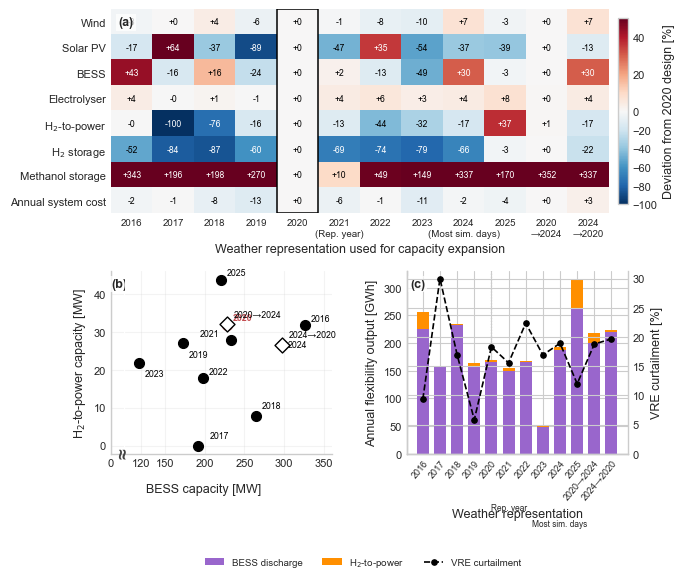

Representative historical year: 2021
Saved Figure 6: output\output_punta_arenas\figures\figure06_weather_representation_sensitivity_2050.svg


In [24]:
# Figure 6 — Investment sensitivity to meteorological-year selection
#
# Simplified version:
#   - only historical weather years 2016–2025
#   - 2020 highlighted as the reference/critical year
#   - 2021 identified as the representative historical year
#   - 2024 identified as the year with the most simultaneous low-renewable days
#   - 2020 remains the critical/reference design (longest consecutive event)
def _load_weather_representation_2050_table():
    hist_path = (
        Path(OUTPUT_ROOT)
        / "ptx_weather_design_sensitivity"
        / "ptx_weather_design_2050.csv"
    )
    if (
        "ptx_weather_design_2050" in globals()
        and isinstance(ptx_weather_design_2050, pd.DataFrame)
        and not ptx_weather_design_2050.empty
    ):
        historical = ptx_weather_design_2050.copy()
    elif hist_path.exists():
        historical = pd.read_csv(hist_path)
    else:
        raise FileNotFoundError(
            "The saved 2016–2025 PtX weather-design sensitivity is missing: "
            f"{hist_path}"
        )

    historical = historical.loc[historical["planning_year"].eq(2050)].copy()
    historical["design_case"] = "historical_year"
    historical["design_label"] = historical["weather_year"].astype(int).astype(str)
    historical["design_order"] = historical["weather_year"].astype(int)

    frames = [historical]

    sequential_path = (
        Path(OUTPUT_ROOT)
        / "ptx_weather_design_sensitivity"
        / "sequential_critical_years"
        / "ptx_sequential_critical_designs_2050.csv"
    )
    if (
        "sequential_critical_designs_2050" in globals()
        and isinstance(sequential_critical_designs_2050, pd.DataFrame)
        and not sequential_critical_designs_2050.empty
    ):
        sequential = sequential_critical_designs_2050.copy()
    elif sequential_path.exists():
        sequential = pd.read_csv(sequential_path)
    else:
        sequential = pd.DataFrame()

    if not sequential.empty:
        sequential["design_case"] = "sequential_critical_years"
        # Keep both orderings after the ten historical designs.
        order_map = {"2020→2024": 2026, "2024→2020": 2027}
        sequential["design_order"] = (
            sequential["design_label"].map(order_map).fillna(2099)
        )
        frames.append(sequential)

    combined = pd.concat(frames, ignore_index=True, sort=False)
    return (
        combined
        .sort_values(["design_order", "design_label"])
        .reset_index(drop=True)
    )


weather_representation_2050 = _load_weather_representation_2050_table()

REFERENCE_YEAR = int(critical_weather_year)
REP_YEAR = int(globals().get("REPRESENTATIVE_HISTORICAL_YEAR", 2021))

reference_rows = weather_representation_2050.loc[
    weather_representation_2050["design_case"].eq("historical_year")
    & pd.to_numeric(
        weather_representation_2050["weather_year"], errors="coerce"
    ).eq(REFERENCE_YEAR)
]

if reference_rows.empty:
    raise ValueError(f'Reference weather year {REFERENCE_YEAR} is missing.')
reference_row = reference_rows.iloc[0]

# ── Capacity deviations: identical metrics to the previous sensitivity diagnostic ─────────────────
capacity_metrics = {
    "wind_mw": "Wind",
    "solar_mw": "Solar PV",
    "bess_power_mw": "BESS",
    "electrolyser_mw": "Electrolyser",
    "h2_to_power_mw": r"H$_2$-to-power",
    "h2_store_gwh": r"H$_2$ storage",
    "methanol_store_kt": "Methanol storage",
    "annual_system_cost_musd": "Annual system cost",
}

delta_matrix = []

for _, row in weather_representation_2050.iterrows():
    row_values = []
    for metric in capacity_metrics:
        reference_value = float(reference_row[metric])
        value = float(row[metric])
        if abs(reference_value) > 1e-9:
            delta = 100.0 * (value - reference_value) / reference_value
        else:
            delta = np.nan
        row_values.append(delta)
    delta_matrix.append(row_values)
delta_matrix = np.asarray(delta_matrix, dtype=float)

# ── X labels ─────────────────────────────────────────────────────────────────
MOST_SIMULTANEOUS_DAYS_YEAR = 2024

design_labels_heat = []
design_labels_operation = []

for _, row in weather_representation_2050.iterrows():
    design_case = str(row.get("design_case", "historical_year"))
    design_label = str(row.get("design_label", ""))

    if design_case == "historical_year":
        weather_year = int(row["weather_year"])
        operation_label = str(weather_year)
        if weather_year == REP_YEAR:
            heat_label = f"{weather_year}\n(Rep. year)"
        elif weather_year == MOST_SIMULTANEOUS_DAYS_YEAR:
            heat_label = f"{weather_year}\n(Most sim. days)"
        else:
            heat_label = str(weather_year)
    else:
        operation_label = design_label
        heat_label = design_label.replace("→", "\n→")

    design_labels_heat.append(heat_label)
    design_labels_operation.append(operation_label)

# ── Colours: same as the previous sensitivity diagnostic ───────────────────────────────────────────
tech_colors_fig7 = globals().get("TECH_COLORS", {})

bess_color_fig7 = tech_colors_fig7.get("bess", "#8E6BBF")
h2_color_fig7 = tech_colors_fig7.get("h2_fuel_cell", "#2CA58D")
reference_color_fig7 = "#C44E52"

# ── Figure layout: same as the previous sensitivity diagnostic ─────────────────────────────────────
fig = plt.figure(figsize=(WORD_DOUBLE_COL_IN, 5.85))

gs = GridSpec(2, 2, figure=fig, height_ratios=[1.12, 1.0], hspace=0.3, wspace=0.34)

ax_heat = fig.add_subplot(gs[0, :])

# Panel (b): split into two horizontally adjacent axes
gs_portfolio = gs[1, 0].subgridspec(1, 2, width_ratios=[0.06, 0.94], wspace=0.01)

ax_portfolio_left = fig.add_subplot(gs_portfolio[0, 0])
ax_portfolio_right = fig.add_subplot(gs_portfolio[0, 1], sharey=ax_portfolio_left)

# Alias retained for compatibility if needed later
ax_portfolio = ax_portfolio_right

ax_operation = fig.add_subplot(gs[1, 1])

# ── (a) Capacity sensitivity heatmap ─────────────────────────────────────────
norm = TwoSlopeNorm(vmin=-100, vcenter=0, vmax=50)

ax_heat.grid(False)
ax_heat.tick_params(length=0)

for spine in ax_heat.spines.values():
    spine.set_visible(False)
im = ax_heat.imshow(delta_matrix.T, aspect='auto', cmap='RdBu_r', norm=norm)

ax_heat.set_xticks(np.arange(len(design_labels_heat)))
ax_heat.set_xticklabels(design_labels_heat, fontsize=7)

ax_heat.set_yticks(np.arange(len(capacity_metrics)))
ax_heat.set_yticklabels(list(capacity_metrics.values()))

ax_heat.set_xlabel("Weather representation used for capacity expansion")

for metric_index in range(delta_matrix.shape[1]):
    for design_index in range(delta_matrix.shape[0]):
        value = delta_matrix[design_index, metric_index]
        if not np.isfinite(value):
            continue
        text_color = 'white' if value < -55 or value > 30 else 'black'
        ax_heat.text(
            design_index,
            metric_index,
            f"{value:+.0f}",
            ha="center",
            va="center",
            fontsize=6.2,
            color=text_color,
        )

# Highlight the critical-year column
reference_position = int(
    weather_representation_2050.index[
        weather_representation_2050["design_case"].eq("historical_year")
        & pd.to_numeric(
            weather_representation_2050["weather_year"], errors="coerce"
        ).eq(REFERENCE_YEAR)
    ][0]
)

ax_heat.add_patch(
    plt.Rectangle(
        (reference_position - 0.5, -0.5),
        1.0,
        len(capacity_metrics),
        fill=False,
        edgecolor="black",
        linewidth=1.1,
    )
)

colorbar = fig.colorbar(im, ax=ax_heat, fraction=0.018, pad=0.018)

colorbar.set_label(f'Deviation from {REFERENCE_YEAR} design [%]')

_paper_panel_label(ax_heat, "(a)")

# ── (b) Flexibility portfolio — broken BESS x-axis ──────────────────────────
historical_offsets = {
    2016: (4, 3),
    2017: (8, 5),      # moved up/right
    2018: (4, 6),
    2019: (4, -10),
    2020: (4, 3),
    2021: (-22, 3),
    2022: (4, 3),
    2023: (4, -10),
    2024: (4, -2),     # slightly lower
    2025: (4, 3),
}

BESS_LEFT_MIN = 0
BESS_LEFT_MAX = 5

bess_min = float(weather_representation_2050["bess_power_mw"].min())
BESS_RIGHT_MIN = max(10, np.floor(bess_min / 10.0) * 10.0 - 10.0)

bess_max = float(weather_representation_2050["bess_power_mw"].max())

# Keep 350 MW visible as a labelled tick
BESS_RIGHT_MAX = max(360, np.ceil(bess_max / 10.0) * 10.0 + 10.0)

for _, row in weather_representation_2050.iterrows():
    design_case = str(row.get("design_case", "historical_year"))
    if design_case == "historical_year":
        weather_year = int(row["weather_year"])
        is_reference = (weather_year == REFERENCE_YEAR)
        point_label = str(weather_year)
        dx, dy = historical_offsets.get(weather_year, (4, 3))
        marker = "o"
        point_color = reference_color_fig7 if is_reference else "black"
        facecolor = point_color
    else:
        is_reference = False
        point_label = str(row["design_label"])
        dx, dy = (5, 5)
        marker = "D"
        point_color = "black"
        facecolor = "white"

    ax_portfolio_right.scatter(
        row["bess_power_mw"],
        row["h2_to_power_mw"],
        s=58 if design_case != "historical_year" else 52,
        marker=marker,
        facecolor=facecolor,
        edgecolor=point_color,
        linewidth=1.0 if design_case != "historical_year" else 0.8,
        zorder=4 if design_case != "historical_year" else 3,
    )
    ax_portfolio_right.annotate(
        point_label,
        (row["bess_power_mw"], row["h2_to_power_mw"]),
        xytext=(dx, dy),
        textcoords="offset points",
        fontsize=6.3,
        fontweight=("bold" if is_reference else "normal"),
        color=point_color,
    )

# Broken x-axis ranges
ax_portfolio_left.set_xlim(BESS_LEFT_MIN, BESS_LEFT_MAX)
ax_portfolio_right.set_xlim(BESS_RIGHT_MIN, BESS_RIGHT_MAX)

# Only show zero on the short left-hand segment
ax_portfolio_left.set_xticks([0])

right_ticks = [
    tick
    for tick in [120, 150, 200, 250, 300, 350]
    if tick <= BESS_RIGHT_MAX
]

ax_portfolio_right.set_xticks(right_ticks)

# Shared y-axis
ax_portfolio_left.set_ylabel(r"H$_2$-to-power capacity [MW]")

ax_portfolio_right.tick_params(axis='y', left=False, labelleft=False)

# Common x-axis label
ax_portfolio_right.set_xlabel("BESS capacity [MW]")
ax_portfolio_right.xaxis.set_label_coords(0.38, -0.16)

# Formatting
ax_portfolio_left.grid(axis="y", alpha=0.22)
ax_portfolio_right.grid(alpha=0.22)

for ax in [ax_portfolio_left, ax_portfolio_right]:
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)

# Remove touching/interior spines
ax_portfolio_left.spines["right"].set_visible(False)
ax_portfolio_right.spines["left"].set_visible(False)
ax_portfolio_right.spines["right"].set_visible(False)

_paper_panel_label(ax_portfolio_left, "(b)")

# ── (c) Flexibility operation + VRE curtailment ──────────────────────────────
x = np.arange(len(weather_representation_2050))

bess_operation = (
    weather_representation_2050["bess_discharge_gwh"]
    .fillna(0.0)
    .to_numpy(float)
)

h2_operation = (
    weather_representation_2050["h2_to_power_gwh"]
    .fillna(0.0)
    .to_numpy(float)
)

curtailment = (
    weather_representation_2050["curtailment_share_pct"]
    .fillna(0.0)
    .to_numpy(float)
)

ax_operation.bar(
    x,
    bess_operation,
    width=0.70,
    color=bess_color_fig7,
    label="BESS discharge",
)

ax_operation.bar(
    x,
    h2_operation,
    width=0.70,
    bottom=bess_operation,
    color=h2_color_fig7,
    label=r"H$_2$-to-power",
)

ax_operation.set_xticks(x)

ax_operation.set_xticklabels(
    design_labels_operation,
    rotation=50,
    ha="right",
    rotation_mode="anchor",
    fontsize=6.5,
)

# Put special-year descriptors directly under their own ticks. This keeps the
# representative-year note aligned with 2021 instead of rotating it with the tick.
for year, label, y_position in [
    (REP_YEAR, "Rep. year", -0.27),
    (MOST_SIMULTANEOUS_DAYS_YEAR, "Most sim. days", -0.36),
]:
    matches = weather_representation_2050.index[
        pd.to_numeric(
            weather_representation_2050["weather_year"], errors="coerce"
        ).eq(int(year))
    ]
    if len(matches):
        ax_operation.text(
            int(matches[0]),
            y_position,
            label,
            transform=ax_operation.get_xaxis_transform(),
            ha="center",
            va="top",
            fontsize=6.0,
        )
ax_operation.set_xlabel("Weather representation")
ax_operation.set_ylabel("Annual flexibility output [GWh]")

ax_curtailment = ax_operation.twinx()

ax_curtailment.plot(
    x,
    curtailment,
    color="black",
    marker="o",
    markersize=3.8,
    linewidth=1.2,
    linestyle="--",
    label="VRE curtailment",
)

ax_curtailment.set_ylabel("VRE curtailment [%]")
ax_curtailment.set_ylim(bottom=0.0)

# Same reference marker as the previous sensitivity diagnostic
ax_operation.axvline(
    reference_position,
    color="0.35",
    linewidth=0.8,
    linestyle=":",
    zorder=0,
)

ax_operation.spines["top"].set_visible(False)
ax_operation.spines["right"].set_visible(False)
ax_curtailment.spines["top"].set_visible(False)

_paper_panel_label(ax_operation, "(c)")

# ── Shared legend ────────────────────────────────────────────────────────────
legend_handles = [
    Patch(
        facecolor=bess_color_fig7,
        edgecolor="none",
        label="BESS discharge",
    ),
    Patch(
        facecolor=h2_color_fig7,
        edgecolor="none",
        label=r"H$_2$-to-power",
    ),
    Line2D(
        [0],
        [0],
        color="black",
        marker="o",
        linestyle="--",
        linewidth=1.2,
        markersize=3.8,
        label="VRE curtailment",
    ),
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.008),
    ncol=3,
    frameon=False,
    fontsize=7,
)

fig.subplots_adjust(left=0.1, right=0.92, top=0.98, bottom=0.22)

# Single vertical wavy symbol centred in the broken-axis gap
left_box = ax_portfolio_left.get_position()
right_box = ax_portfolio_right.get_position()

break_x = 0.5 * (left_box.x1 + right_box.x0)
break_y = left_box.y0

fig.text(
    break_x,
    break_y + 0.002,
    "≈",
    transform=fig.transFigure,
    rotation=90,
    ha="center",
    va="center",
    fontsize=14,
    color="0.25",
)

# ── Export ───────────────────────────────────────────────────────────────────
figure6_path = save_paper_figure(
    fig,
    "figure06_weather_representation_sensitivity_2050.svg",
)

save_paper_figure(fig, 'figure06_weather_representation_sensitivity_2050.png')

plt.show()

weather_representation_2050.to_csv(
    TABLE_EXPORT_DIR / "figure06_weather_representation_sensitivity_2050.csv",
    index=False,
)

print(f"Representative historical year: {REP_YEAR}")
print(f"Saved Figure 6: {figure6_path}")


### Figure 7 — Operational robustness of alternative critical-year designs

Compares the fixed-capacity 2050 PtX designs across operational meteorological
years 2016–2025.

Rows correspond to:

1. **2020 design** — selected from the longest consecutive simultaneous
   low-renewable-generation event.
2. **2024 design** — selected from the largest annual cumulative exposure to
   simultaneous low-renewable-generation conditions.
3. **2020→2024 design** — sequential constrained re-optimisation, preserving the
   2020 capacities as lower bounds before re-optimising under 2024 weather.
4. **2024→2020 design** — the reverse sequential ordering.

The **left column** reports annual unserved electricity. The **right column**
characterises residual stress episodes by duration, peak additional power
requirement, and additional energy requirement. If a sequential design produces
zero unserved demand across all tested years, its stress-episode panel is left
intentionally empty and labelled accordingly.

The former flexibility-output/curtailment panel is omitted here because the
investment/flexibility comparison is already reported in Figure 6.


In [25]:
# Generic fixed-capacity operational robustness experiment
#
# The same routine is used for four 2050 PtX designs:
#   - 2020
#   - 2024
#   - 2020→2024
#   - 2024→2020
#
# Each fixed design is independently re-dispatched under every 2016–2025
# meteorological year. Sequential designs are loaded from the Figure 6
# sequential capacity-expansion outputs.


def _robustness_design_key(value):
    """Filesystem-safe identifier for a fixed design."""
    if isinstance(value, (int, np.integer)):
        return str(int(value))
    text = str(value).strip()
    text = text.replace("→", "_to_").replace("->", "_to_")
    text = re.sub(r"\s+", "", text)
    return text


def _robustness_design_label(value):
    """Human-readable design label."""
    key = _robustness_design_key(value)
    if "_to_" in key:
        first, second = key.split("_to_", 1)
        return f"{first}→{second}"
    return key


def _saved_robustness_summary_path(design_key, scenario_code="PTX_base", target_year=2050):
    key = _robustness_design_key(design_key)
    design_dir = ROBUSTNESS_EXPORT_DIR / f"design_{key}"
    return design_dir / (
        f"weather_robustness_{scenario_code}_{target_year}_design_{key}.csv"
    )


def _load_saved_robustness_summary(design_key, scenario_code="PTX_base", target_year=2050):
    """Load a saved robustness summary, with a legacy fallback for 2020."""
    key = _robustness_design_key(design_key)
    path = _saved_robustness_summary_path(key, scenario_code, target_year)
    if path.exists():
        return pd.read_csv(path)

    if key == _robustness_design_key(int(critical_weather_year)):
        legacy = ROBUSTNESS_EXPORT_DIR / f"weather_robustness_{scenario_code}_{target_year}.csv"
        if legacy.exists():
            print(f"Using legacy robustness summary: {legacy}")
            return pd.read_csv(legacy)
    return None


def run_weather_year_robustness(
    design_weather_year=2020,
    *,
    design_key=None,
    design_label=None,
    design_network_path=None,
):
    """Re-operate one fixed 2050 PtX design across 2016–2025 weather years."""
    design_weather_year = int(design_weather_year)
    design_key = _robustness_design_key(
        design_weather_year if design_key is None else design_key
    )
    design_label = (
        _robustness_design_label(design_key)
        if design_label is None
        else str(design_label)
    )
    robustness_scenario_code = "PTX_base"
    robustness_target_year = 2050
    robustness_weather_years = list(range(2016, 2026))
    robustness_cutout_base_dir = Path("data")
    robustness_cutout_prefix = "magallanes"

    solver_name_robustness = solver_name
    time_limit_robustness = time_limit
    mip_gap_robustness = mip_gap
    threads_robustness = threads
    fallback_to_highs_robustness = fallback_to_highs

    missing_cutouts = [
        robustness_cutout_base_dir / f"{robustness_cutout_prefix}_{wy}.nc"
        for wy in robustness_weather_years
        if not (robustness_cutout_base_dir / f"{robustness_cutout_prefix}_{wy}.nc").exists()
    ]
    if missing_cutouts:
        raise FileNotFoundError(
            "Some robustness cutouts are missing. Check the folder/path before running:\n"
            + "\n".join(str(path.resolve()) for path in missing_cutouts)
        )

    if robustness_scenario_code not in scenario_results:
        raise KeyError(
            f"{robustness_scenario_code} not found in scenario_results. "
            "Run/load the PtX scenario before running robustness."
        )

    base_package = scenario_results[robustness_scenario_code]
    base_result = base_package["results"][robustness_target_year]
    base_nodes = base_result["nodes"].load()

    # ── Load the design network ──────────────────────────────────────────────
    if design_network_path is not None:
        design_source = Path(design_network_path)
        if design_source.exists():
            base_net = pypsa.Network(design_source)
        else:
            # Optional in-memory fallback for sequential designs created in this session.
            in_memory_label = _robustness_design_label(design_key)
            if (
                "sequential_critical_design_networks" in globals()
                and in_memory_label in sequential_critical_design_networks
            ):
                base_net = sequential_critical_design_networks[in_memory_label].copy()
                design_source = Path(f"in-memory:{in_memory_label}")
            else:
                raise FileNotFoundError(
                    f"Fixed design network '{design_label}' was not found at:\n"
                    f"  {design_source}\n"
                    "Run/load the Figure 6 sequential critical-year design section first."
                )
    elif design_weather_year == int(critical_weather_year):
        network_netcdf = base_result.get("network_netcdf")
        if network_netcdf is None or not Path(network_netcdf).exists():
            raise FileNotFoundError(
                "The 2020 robustness run requires the exported network.nc file. "
                "Set EXPORT_NETWORK_NETCDF=True and rerun/load the main PtX scenario."
            )
        base_net = pypsa.Network(network_netcdf)
        design_source = Path(network_netcdf)
    else:
        sensitivity_dir = Path(OUTPUT_ROOT) / "ptx_weather_design_sensitivity"
        design_source = (
            sensitivity_dir
            / "networks_2050"
            / f"PTX_base_WY{design_weather_year}_2050.nc"
        )
        if design_source.exists():
            base_net = pypsa.Network(design_source)
        elif (
            "ptx_weather_design_2050_networks" in globals()
            and design_weather_year in ptx_weather_design_2050_networks
        ):
            base_net = ptx_weather_design_2050_networks[design_weather_year]
            design_source = Path(f"in-memory PtX design WY{design_weather_year}")
        else:
            raise FileNotFoundError(
                "The alternative fixed design is unavailable. Expected the 2050 "
                f"network optimised with weather year {design_weather_year} at:\n"
                f"  {design_source}\n"
                "Run the Figure 6 weather-year design sensitivity first with "
                "SAVE_2050_NETWORK_NETCDF=True."
            )

    print(
        "\nUsing fixed capacities from "
        f"{robustness_scenario_code}, model year {robustness_target_year}, "
        f"design {design_label}.\n"
        f"Design source: {design_source}"
    )

    # ── Rebuild transient monthly PtX export requirements ────────────────────
    ptx_monthly_export_requirements = []
    base_scenario = dict(base_package.get("metadata", {}))
    if base_scenario.get("enable_ptx", False):
        ptx_monthly_demand_csv = _scenario_optional_csv(
            "ptx_monthly_demand",
            robustness_scenario_code,
        )
        ptx_monthly_demand_df = _load_ptx_monthly_demand_for_scenario(
            base_scenario,
            ptx_monthly_demand_csv,
        )
        demand_df = ptx_monthly_demand_df.copy()
        if "year" in demand_df.columns:
            demand_df = demand_df[
                demand_df["year"].isna()
                | demand_df["year"].astype("Int64").eq(robustness_target_year)
            ]
        demand_df = demand_df.loc[
            pd.to_numeric(demand_df["demand_tons"], errors="coerce")
            .fillna(0.0)
            .gt(0.0)
        ].copy()

        if not demand_df.empty:
            grouped = (
                demand_df.groupby(["zone", "product", "month"], as_index=False)
                .agg(demand_tons=("demand_tons", "sum"))
            )
            product_defaults = getattr(config, "PTX_PRODUCT_DEFAULTS", {})
            product_key_fun = getattr(config, "_ptx_product_key", None)
            if not product_defaults or product_key_fun is None:
                raise RuntimeError(
                    "Could not rebuild PtX monthly export constraints: "
                    "config.PTX_PRODUCT_DEFAULTS or config._ptx_product_key is unavailable."
                )

            for _, requirement in grouped.iterrows():
                zone = str(requirement["zone"]).strip()
                product = product_key_fun(requirement["product"], default="")
                if product not in product_defaults:
                    continue
                info = product_defaults[product]
                export_id = f"{info['export_carrier']}_{zone}"
                if export_id not in base_net.links.index:
                    raise KeyError(
                        f"Expected PtX export link '{export_id}' is missing "
                        "from the fixed-design network."
                    )
                ptx_monthly_export_requirements.append(
                    {
                        "link_id": export_id,
                        "zone": zone,
                        "product": product,
                        "month": int(requirement["month"]),
                        "demand_tons": float(requirement["demand_tons"]),
                    }
                )

        if not ptx_monthly_export_requirements:
            raise RuntimeError(
                "PtX robustness was requested, but no monthly export requirements "
                "could be reconstructed."
            )
        print(
            f"Reconstructed {len(ptx_monthly_export_requirements)} PtX monthly "
            "export requirements."
        )

    def _copy_optimized_capacities_to_nominal(net):
        """Convert an expansion solution into a clean fixed-capacity network."""
        with tempfile.TemporaryDirectory() as tmpdir:
            tmp_path = Path(tmpdir) / "fixed_capacity_template.nc"
            exported_path = export_network_netcdf_safe(net, tmp_path, strict=True)
            net = pypsa.Network(exported_path)

        if len(net.generators) > 0:
            if "p_nom_opt" in net.generators.columns:
                mask = net.generators["p_nom_opt"].notna()
                net.generators.loc[mask, "p_nom"] = net.generators.loc[mask, "p_nom_opt"]
            if "p_nom_extendable" in net.generators.columns:
                net.generators["p_nom_extendable"] = False

        if len(net.storage_units) > 0:
            if "p_nom_opt" in net.storage_units.columns:
                mask = net.storage_units["p_nom_opt"].notna()
                net.storage_units.loc[mask, "p_nom"] = net.storage_units.loc[mask, "p_nom_opt"]

            # Preserve the same initial SOC assumption after extendable BESS
            # capacities are converted to fixed capacities.
            if "initial_soc_fraction" in net.storage_units.columns:
                initial_fraction = pd.to_numeric(
                    net.storage_units["initial_soc_fraction"],
                    errors="coerce",
                )
                mask_initial = initial_fraction.notna()
                net.storage_units.loc[mask_initial, "state_of_charge_initial"] = (
                    initial_fraction.loc[mask_initial]
                    * net.storage_units.loc[mask_initial, "p_nom"]
                    * net.storage_units.loc[mask_initial, "max_hours"]
                )
            if "p_nom_extendable" in net.storage_units.columns:
                net.storage_units["p_nom_extendable"] = False

        if len(net.links) > 0:
            if "p_nom_opt" in net.links.columns:
                mask = net.links["p_nom_opt"].notna()
                net.links.loc[mask, "p_nom"] = net.links.loc[mask, "p_nom_opt"]
            if "p_nom_extendable" in net.links.columns:
                net.links["p_nom_extendable"] = False

        if len(net.stores) > 0:
            if "e_nom_opt" in net.stores.columns:
                mask = net.stores["e_nom_opt"].notna()
                net.stores.loc[mask, "e_nom"] = net.stores.loc[mask, "e_nom_opt"]
            if "e_nom_extendable" in net.stores.columns:
                net.stores["e_nom_extendable"] = False

        if hasattr(net, "model"):
            try:
                delattr(net, "model")
            except Exception:
                pass
        return net

    def _replace_vre_profiles_for_weather_year(net, weather_year):
        cutout_path = (
            robustness_cutout_base_dir
            / f"{robustness_cutout_prefix}_{weather_year}.nc"
        )
        print(f"Using existing cutout: {cutout_path}")
        cutout = atlite.Cutout(str(cutout_path))
        wind_cf_hist, solar_cf_hist = config.get_vre_profiles_from_cutout(
            cutout=cutout,
            nodes_df=base_nodes,
            method=vre_profile_method,
            wind_turbine=wind_turbine,
            solar_panel=solar_panel,
            solar_orientation=solar_orientation,
        )
        wind_cf = config.map_weather_year(wind_cf_hist, target_year=robustness_target_year)
        solar_cf = config.map_weather_year(solar_cf_hist, target_year=robustness_target_year)

        if net.generators_t.p_max_pu.empty:
            net.generators_t.p_max_pu = pd.DataFrame(
                1.0,
                index=net.snapshots,
                columns=net.generators.index,
            )
        else:
            net.generators_t.p_max_pu = net.generators_t.p_max_pu.reindex(
                index=net.snapshots,
                columns=net.generators.index,
                fill_value=1.0,
            )

        replaced = []
        for generator_id, row in net.generators.iterrows():
            carrier = str(row.get("carrier", "")).lower()
            zone = str(row.get("bus", "")).replace("elec_", "")
            if carrier == "wind" and zone in wind_cf.columns:
                net.generators_t.p_max_pu[generator_id] = (
                    wind_cf[zone].reindex(net.snapshots).fillna(0.0)
                )
                replaced.append(generator_id)
            elif carrier in {"solar", "solar_pv"} and zone in solar_cf.columns:
                net.generators_t.p_max_pu[generator_id] = (
                    solar_cf[zone].reindex(net.snapshots).fillna(0.0)
                )
                replaced.append(generator_id)
        print(f"Updated VRE profiles for {len(replaced)} generators.")
        return net, wind_cf, solar_cf

    def _build_solver_options(target_solver):
        options = {}
        if target_solver == "gurobi":
            if time_limit_robustness is not None:
                options["TimeLimit"] = float(time_limit_robustness)
            if mip_gap_robustness is not None:
                options["MIPGap"] = float(mip_gap_robustness)
            if threads_robustness is not None:
                options["Threads"] = int(threads_robustness)
            options["OutputFlag"] = 0
            options["LogToConsole"] = 0
        elif target_solver == "highs":
            if time_limit_robustness is not None:
                options["time_limit"] = float(time_limit_robustness)
            if mip_gap_robustness is not None:
                options["mip_rel_gap"] = float(mip_gap_robustness)
            if threads_robustness is not None:
                options["threads"] = int(threads_robustness)
        return options

    def _run_fixed_capacity_operation(net):
        options = _build_solver_options(solver_name_robustness)
        optimize_kwargs = {"solver_name": solver_name_robustness}
        if options:
            optimize_kwargs["solver_options"] = options
        extra_fun = getattr(config, "add_custom_constraints", None)

        try:
            if extra_fun is not None:
                status, condition = net.optimize(
                    extra_functionality=extra_fun,
                    **optimize_kwargs,
                )
            else:
                status, condition = net.optimize(**optimize_kwargs)
            used_solver = solver_name_robustness
        except Exception as exc:
            if fallback_to_highs_robustness and solver_name_robustness == "gurobi":
                print(f"Gurobi failed during robustness run: {exc}. Trying HiGHS.")
                fallback_kwargs = {"solver_name": "highs"}
                fallback_options = _build_solver_options("highs")
                if fallback_options:
                    fallback_kwargs["solver_options"] = fallback_options
                if extra_fun is not None:
                    status, condition = net.optimize(
                        extra_functionality=extra_fun,
                        **fallback_kwargs,
                    )
                else:
                    status, condition = net.optimize(**fallback_kwargs)
                used_solver = "highs"
            else:
                raise
        return status, condition, used_solver

    def _generation_by_carrier(net):
        if len(net.generators) == 0:
            return pd.Series(dtype=float)
        generation = (
            net.generators_t.p
            .reindex(columns=net.generators.index, fill_value=0.0)
            .clip(lower=0.0)
        )
        carriers = net.generators["carrier"].astype(str)
        return generation.T.groupby(carriers).sum().T.sum().sort_values(ascending=False)

    def _vre_curtailment_mwh(net):
        total_curtailment = 0.0
        if len(net.generators) == 0:
            return total_curtailment
        for carrier in ["wind", "solar", "solar_pv"]:
            generators = net.generators.index[
                net.generators["carrier"].astype(str).str.lower().eq(carrier)
            ]
            for generator_id in generators:
                p_nom = float(net.generators.loc[generator_id, "p_nom"])
                available = (
                    net.generators_t.p_max_pu[generator_id]
                    .fillna(0.0)
                    .clip(lower=0.0)
                    * p_nom
                )
                actual = (
                    net.generators_t.p[generator_id]
                    .fillna(0.0)
                    .clip(lower=0.0)
                )
                total_curtailment += float(
                    (available - actual).clip(lower=0.0).sum()
                )
        return total_curtailment

    def _storage_metrics(net):
        bess_charge = 0.0
        bess_discharge = 0.0
        bess_energy_capacity = 0.0
        if len(net.storage_units) > 0:
            power = net.storage_units_t.p.reindex(
                columns=net.storage_units.index,
                fill_value=0.0,
            )
            bess_charge = float((-power.clip(upper=0.0)).sum().sum())
            bess_discharge = float(power.clip(lower=0.0).sum().sum())
            if "max_hours" in net.storage_units.columns:
                bess_energy_capacity = float(
                    (net.storage_units["p_nom"] * net.storage_units["max_hours"]).sum()
                )

        h2_store_energy = 0.0
        uhs_store_energy = 0.0
        if len(net.stores) > 0:
            for _, row in net.stores.iterrows():
                carrier = str(row.get("carrier", "")).lower()
                e_nom = float(row.get("e_nom", 0.0))
                if carrier == "hydrogen_storage":
                    h2_store_energy += e_nom
                elif carrier == "uhs_storage":
                    uhs_store_energy += e_nom
        return {
            "bess_charge_mwh": bess_charge,
            "bess_discharge_mwh": bess_discharge,
            "bess_energy_capacity_mwh": bess_energy_capacity,
            "h2_store_energy_mwh": h2_store_energy,
            "uhs_store_energy_mwh": uhs_store_energy,
        }

    def _h2_link_metrics(net):
        output = {
            "electrolyzer_input_gwh": 0.0,
            "h2_fuel_cell_output_gwh": 0.0,
            "h2_turbine_output_gwh": 0.0,
            "uhs_injection_gwh": 0.0,
            "uhs_withdrawal_gwh": 0.0,
        }
        if len(net.links) == 0:
            return output
        p0 = net.links_t.p0.reindex(columns=net.links.index, fill_value=0.0)
        p1 = net.links_t.p1.reindex(columns=net.links.index, fill_value=0.0)
        for link_id, row in net.links.iterrows():
            carrier = str(row.get("carrier", "")).lower()
            if carrier == "electrolyzer":
                output["electrolyzer_input_gwh"] += float(
                    p0[link_id].clip(lower=0.0).sum() / 1e3
                )
            elif carrier == "h2_fuel_cell":
                output["h2_fuel_cell_output_gwh"] += float(
                    (-p1[link_id]).clip(lower=0.0).sum() / 1e3
                )
            elif carrier == "h2_turbine":
                output["h2_turbine_output_gwh"] += float(
                    (-p1[link_id]).clip(lower=0.0).sum() / 1e3
                )
            elif carrier == "uhs_injection":
                output["uhs_injection_gwh"] += float(
                    p0[link_id].clip(lower=0.0).sum() / 1e3
                )
            elif carrier == "uhs_withdrawal":
                output["uhs_withdrawal_gwh"] += float(
                    (-p1[link_id]).clip(lower=0.0).sum() / 1e3
                )
        return output

    def _transmission_metrics(net):
        if len(net.links) == 0:
            return {
                "tx_capacity_mw": 0.0,
                "tx_gross_flow_mwh": 0.0,
                "tx_net_abs_flow_mwh": 0.0,
            }
        transmission = net.links[
            net.links["carrier"].astype(str).eq("electricity")
            & net.links["bus0"].astype(str).str.startswith("elec_")
            & net.links["bus1"].astype(str).str.startswith("elec_")
        ]
        if transmission.empty:
            return {
                "tx_capacity_mw": 0.0,
                "tx_gross_flow_mwh": 0.0,
                "tx_net_abs_flow_mwh": 0.0,
            }
        p0 = net.links_t.p0.reindex(columns=transmission.index, fill_value=0.0)

        counted_links = []
        for link_id in transmission.index:
            name = str(link_id)
            if name.endswith("_rev") and f"{name[:-4]}_fwd" in transmission.index:
                continue
            counted_links.append(link_id)
        tx_capacity = float(transmission.loc[counted_links, "p_nom"].sum())
        gross_flow = float(p0.clip(lower=0.0).sum().sum())

        used = set()
        net_abs_flow = 0.0
        for link_id in transmission.index:
            name = str(link_id)
            if name in used:
                continue
            if name.endswith("_fwd") and f"{name[:-4]}_rev" in transmission.index:
                reverse = f"{name[:-4]}_rev"
                net_flow = p0[link_id].clip(lower=0.0) - p0[reverse].clip(lower=0.0)
                net_abs_flow += float(net_flow.abs().sum())
                used.update([link_id, reverse])
            elif name.endswith("_rev") and f"{name[:-4]}_fwd" in transmission.index:
                continue
            else:
                net_abs_flow += float(p0[link_id].clip(lower=0.0).sum())
                used.add(link_id)
        return {
            "tx_capacity_mw": tx_capacity,
            "tx_gross_flow_mwh": gross_flow,
            "tx_net_abs_flow_mwh": net_abs_flow,
        }

    def _summarise_result(net, weather_year, status, condition, used_solver):
        load_mwh = float(base_result["load"].sum().sum())

        generation = _generation_by_carrier(net)
        carrier_index = generation.index.astype(str).str.lower()

        slack_mwh = float(generation[carrier_index.str.contains("slack")].sum())
        thermal_mwh = float(
            generation[carrier_index.isin(["ocgt", "gas", "natural_gas", "diesel"])].sum()
        )
        ptx_shortfall_tons = float(generation[carrier_index == "ptx_shortfall"].sum())
        wind_mwh = float(generation[carrier_index == "wind"].sum())
        solar_mwh = float(generation[carrier_index.isin(["solar", "solar_pv"])].sum())

        curtailment_mwh = _vre_curtailment_mwh(net)
        vre_available_mwh = wind_mwh + solar_mwh + curtailment_mwh

        storage = _storage_metrics(net)
        h2_links = _h2_link_metrics(net)
        transmission = _transmission_metrics(net)

        objective = float(net.objective) if net.objective is not None else np.nan

        return {
            "design_key": design_key,
            "design_label": design_label,
            "design_weather_year": design_weather_year,
            "weather_year": weather_year,
            "model_year": robustness_target_year,
            "status": status,
            "condition": condition,
            "solver": used_solver,
            "objective": objective,
            "demand_gwh": load_mwh / 1e3,
            "wind_generation_gwh": wind_mwh / 1e3,
            "solar_generation_gwh": solar_mwh / 1e3,
            "thermal_generation_gwh": thermal_mwh / 1e3,
            "slack_gwh": slack_mwh / 1e3,
            "slack_share_pct": 100.0 * slack_mwh / load_mwh if load_mwh > 0 else np.nan,
            "ptx_shortfall_tons": ptx_shortfall_tons,
            "curtailment_gwh": curtailment_mwh / 1e3,
            "curtailment_share_vre_available_pct": (
                100.0 * curtailment_mwh / vre_available_mwh
                if vre_available_mwh > 0
                else np.nan
            ),
            "bess_charge_gwh": storage["bess_charge_mwh"] / 1e3,
            "bess_discharge_gwh": storage["bess_discharge_mwh"] / 1e3,
            "bess_energy_capacity_gwh": storage["bess_energy_capacity_mwh"] / 1e3,
            "h2_store_energy_gwh": storage["h2_store_energy_mwh"] / 1e3,
            "uhs_store_energy_gwh": storage["uhs_store_energy_mwh"] / 1e3,
            "electrolyzer_input_gwh": h2_links["electrolyzer_input_gwh"],
            "h2_fuel_cell_output_gwh": h2_links["h2_fuel_cell_output_gwh"],
            "h2_turbine_output_gwh": h2_links["h2_turbine_output_gwh"],
            "uhs_injection_gwh": h2_links["uhs_injection_gwh"],
            "uhs_withdrawal_gwh": h2_links["uhs_withdrawal_gwh"],
            "tx_capacity_mw": transmission["tx_capacity_mw"],
            "tx_gross_flow_gwh": transmission["tx_gross_flow_mwh"] / 1e3,
            "tx_net_abs_flow_gwh": transmission["tx_net_abs_flow_mwh"] / 1e3,
        }

    # ── Run all operational weather years ────────────────────────────────────
    design_output_dir = ROBUSTNESS_EXPORT_DIR / f"design_{design_key}"
    network_dir = design_output_dir / "networks"
    design_output_dir.mkdir(parents=True, exist_ok=True)
    network_dir.mkdir(parents=True, exist_ok=True)

    robustness_results = {}
    summary_rows = []

    for weather_year in robustness_weather_years:
        print(
            f"\nRobustness run: design {design_label}, "
            f"operational WY{weather_year}"
        )
        net_weather = _copy_optimized_capacities_to_nominal(base_net)
        if ptx_monthly_export_requirements:
            net_weather._ptx_monthly_export_requirements = [
                dict(requirement) for requirement in ptx_monthly_export_requirements
            ]

        net_weather, wind_cf_weather, solar_cf_weather = (
            _replace_vre_profiles_for_weather_year(net_weather, weather_year)
        )
        status, condition, used_solver = _run_fixed_capacity_operation(net_weather)

        network_path = network_dir / (
            f"robustness_{robustness_scenario_code}_{robustness_target_year}_"
            f"design_{design_key}_weather_{weather_year}.nc"
        )
        export_network_netcdf_safe(net_weather, network_path, strict=True)
        print(f"Saved robustness network: {network_path}")

        robustness_results[weather_year] = {
            "network": net_weather,
            "wind_cf": wind_cf_weather,
            "solar_cf": solar_cf_weather,
            "status": status,
            "condition": condition,
            "solver": used_solver,
        }
        summary_rows.append(
            _summarise_result(
                net_weather,
                weather_year,
                status,
                condition,
                used_solver,
            )
        )

    summary = (
        pd.DataFrame(summary_rows)
        .sort_values("weather_year")
        .reset_index(drop=True)
    )

    if "ptx_shortfall_tons" in summary.columns:
        max_ptx_shortfall = float(
            pd.to_numeric(summary["ptx_shortfall_tons"], errors="coerce")
            .fillna(0.0)
            .max()
        )
        if max_ptx_shortfall > 1e-6:
            print(
                "WARNING: non-zero PtX product shortfall was used in at least "
                f"one weather year (maximum {max_ptx_shortfall:.3f} t)."
            )
        else:
            print("PtX monthly export targets are satisfied in all tested years.")

    summary_path = _saved_robustness_summary_path(
        design_key,
        robustness_scenario_code,
        robustness_target_year,
    )
    summary.to_csv(summary_path, index=False)
    display(summary.round(3))
    print(f"Saved robustness summary: {summary_path}")
    return robustness_results, summary


# ── Fixed-design robustness runs ─────────────────────────────────────────────
# Existing 2020 and 2024 runs can be reused from disk. The new sequential flag
# runs only the two sequential designs unless the other flags are explicitly set.

if RUN_ROBUSTNESS:
    weather_robustness_results, weather_robustness_summary = (
        run_weather_year_robustness(
            int(critical_weather_year),
            design_key=str(int(critical_weather_year)),
            design_label=str(int(critical_weather_year)),
        )
    )
else:
    weather_robustness_results = {}
    weather_robustness_summary = _load_saved_robustness_summary(
        str(int(critical_weather_year))
    )
    if weather_robustness_summary is None:
        print(
            "2020 fixed-design robustness is disabled and no saved summary was found."
        )

if RUN_ROBUSTNESS_2024:
    weather_robustness_2024_results, weather_robustness_2024_summary = (
        run_weather_year_robustness(
            2024,
            design_key="2024",
            design_label="2024",
        )
    )
else:
    weather_robustness_2024_results = {}
    weather_robustness_2024_summary = _load_saved_robustness_summary("2024")
    if weather_robustness_2024_summary is None:
        print(
            "2024 fixed-design robustness is disabled. Set RUN_ROBUSTNESS_2024=True "
            "after the 2024 optimal network has been saved by Figure 6."
        )

SEQUENTIAL_ROBUSTNESS_SPECS = [
    {
        "key": "2020_to_2024",
        "label": "2020→2024",
        "second_weather_year": 2024,
        "path": SEQUENTIAL_OUTPUT_DIR / "PTX_base_SEQ_2020_to_2024_2050.nc",
    },
    {
        "key": "2024_to_2020",
        "label": "2024→2020",
        "second_weather_year": 2020,
        "path": SEQUENTIAL_OUTPUT_DIR / "PTX_base_SEQ_2024_to_2020_2050.nc",
    },
]

sequential_robustness_results = {}
sequential_robustness_summaries = {}

for _spec in SEQUENTIAL_ROBUSTNESS_SPECS:
    _key = _spec["key"]
    if RUN_ROBUSTNESS_SEQUENTIAL:
        _results, _summary = run_weather_year_robustness(
            _spec["second_weather_year"],
            design_key=_key,
            design_label=_spec["label"],
            design_network_path=_spec["path"],
        )
    else:
        _results = {}
        _summary = _load_saved_robustness_summary(_key)
        if _summary is None:
            print(
                f"Sequential robustness for {_spec['label']} is disabled and no "
                "saved summary was found. Set RUN_ROBUSTNESS_SEQUENTIAL=True "
                "to run the two sequential fixed-design stress tests."
            )

    sequential_robustness_results[_key] = _results
    sequential_robustness_summaries[_key] = _summary

weather_robustness_2020_to_2024_results = sequential_robustness_results["2020_to_2024"]
weather_robustness_2020_to_2024_summary = sequential_robustness_summaries["2020_to_2024"]
weather_robustness_2024_to_2020_results = sequential_robustness_results["2024_to_2020"]
weather_robustness_2024_to_2020_summary = sequential_robustness_summaries["2024_to_2020"]


Using legacy robustness summary: output\output_punta_arenas\robustness\weather_robustness_PTX_base_2050.csv


C:\Users\vse23\AppData\Local\Temp\ipykernel_55040\308763723.py:115: DeprecatedWarning:

iterate_components is deprecated as of 1.0.0 and will be removed in 2.0.0. Use `for component in n.components` instead.




Using fixed capacities from PTX_base, model year 2050, design 2020→2024.
Design source: output\output_punta_arenas\ptx_weather_design_sensitivity\sequential_critical_years\PTX_base_SEQ_2020_to_2024_2050.nc
Reconstructed 12 PtX monthly export requirements.

Robustness run: design 2020→2024, operational WY2016


Using existing cutout: data\magallanes_2016.nc


c:\Users\vse23\AppData\Local\anaconda3\envs\pypsa-isolated\Lib\site-packages\atlite\resource.py:90: FutureWarning:

'add_cutout_windspeed' for wind turbine
power curves will default to True in atlite relase v0.2.15.

INFO:atlite.convert:Convert and aggregate 'wind'.
INFO:atlite.convert:Convert and aggregate 'pv'.
c:\Users\vse23\AppData\Local\anaconda3\envs\pypsa-isolated\Lib\site-packages\atlite\resource.py:90: FutureWarning:

'add_cutout_windspeed' for wind turbine
power curves will default to True in atlite relase v0.2.15.

INFO:atlite.convert:Convert and aggregate 'wind'.
INFO:atlite.convert:Convert and aggregate 'pv'.


...

Set parameter Username
Set parameter LicenseID to value 2807461
Academic license - for non-commercial use only - expires 2027-04-15
Read LP format model from file C:\Users\vse23\AppData\Local\Temp\linopy-problem-c7o9y_y8.lp
Reading time = 3.58 seconds
obj: 560653 rows, 254040 columns, 919796 nonzeros
Set parameter LogToConsole to value 1
Set parameter TimeLimit to value 4000
Set parameter MIPGap to value 0.02
Set parameter Threads to value 4


C:\Users\vse23\AppData\Local\Temp\ipykernel_55040\308763723.py:115: DeprecatedWarning:

iterate_components is deprecated as of 1.0.0 and will be removed in 2.0.0. Use `for component in n.components` instead.



Saved robustness network: output\output_punta_arenas\robustness\design_2024_to_2020\networks\robustness_PTX_base_2050_design_2024_to_2020_weather_2025.nc


,design_key,design_label,design_weather_year,weather_year,model_year,status,condition,solver,objective,demand_gwh,...,h2_store_energy_gwh,uhs_store_energy_gwh,electrolyzer_input_gwh,h2_fuel_cell_output_gwh,h2_turbine_output_gwh,uhs_injection_gwh,uhs_withdrawal_gwh,tx_capacity_mw,tx_gross_flow_gwh,tx_net_abs_flow_gwh
0,2024_to_2020,2024→2020,2020,2016,2050,ok,optimal,gurobi,3.994144e+07,454.835,...,4.209,0.0,1572.886,2.971,0.0,0.0,0.0,100.0,460.538,460.538
1,2024_to_2020,2024→2020,2020,2017,2050,ok,optimal,gurobi,1.332907e+09,454.835,...,4.209,0.0,1553.298,0.005,0.0,0.0,0.0,100.0,460.631,460.631
2,2024_to_2020,2024→2020,2020,2018,2050,ok,optimal,gurobi,0.000000e+00,454.835,...,4.209,0.0,1563.922,0.000,0.0,0.0,0.0,100.0,460.946,460.946
3,2024_to_2020,2024→2020,2020,2019,2050,ok,optimal,gurobi,0.000000e+00,454.835,...,4.209,0.0,1563.924,0.000,0.0,0.0,0.0,100.0,460.980,460.980
4,2024_to_2020,2024→2020,2020,2020,2050,ok,optimal,gurobi,0.000000e+00,454.835,...,4.209,0.0,1570.247,2.021,0.0,0.0,0.0,100.0,461.144,461.144
5,2024_to_2020,2024→2020,2020,2021,2050,ok,optimal,gurobi,0.000000e+00,454.835,...,4.209,0.0,1564.014,0.020,0.0,0.0,0.0,100.0,461.021,461.021
6,2024_to_2020,2024→2020,2020,2022,2050,ok,optimal,gurobi,7.938190e+07,454.835,...,4.209,0.0,1565.186,0.339,0.0,0.0,0.0,100.0,460.925,460.925
7,2024_to_2020,2024→2020,2020,2023,2050,ok,optimal,gurobi,0.000000e+00,454.835,...,4.209,0.0,1563.915,0.001,0.0,0.0,0.0,100.0,460.847,460.847
8,2024_to_2020,2024→2020,2020,2024,2050,ok,optimal,gurobi,0.000000e+00,454.835,...,4.209,0.0,1567.569,1.082,0.0,0.0,0.0,100.0,461.084,461.084
9,2024_to_2020,2024→2020,2020,2025,2050,ok,optimal,gurobi,0.000000e+00,454.835,...,4.209,0.0,1568.619,1.551,0.0,0.0,0.0,100.0,460.942,460.942


Saved robustness summary: output\output_punta_arenas\robustness\design_2024_to_2020\weather_robustness_PTX_base_2050_design_2024_to_2020.csv


In [26]:
# ══════════════════════════════════════════════════════════════════════════════
# ROBUSTNESS DIAGNOSTICS — UNSERVED ELECTRICITY EVENTS
#
# Shared by Figure 7 across all four fixed designs.
# ══════════════════════════════════════════════════════════════════════════════

ROBUSTNESS_SCENARIO = "PTX_base"
ROBUSTNESS_YEAR = 2050
SLACK_EPS_MW = 1e-4
PEAK_DEMAND_QUANTILE = 0.90
DEPLETED_THRESHOLD_PCT = 5.0


def _robustness_design_dir(design_key):
    key = _robustness_design_key(design_key)
    return ROBUSTNESS_EXPORT_DIR / f"design_{key}"


def _robustness_diagnostic_dir(design_key):
    directory = _robustness_design_dir(design_key) / "diagnostics"
    directory.mkdir(parents=True, exist_ok=True)
    return directory


def _load_robustness_networks(design_key, in_memory_results=None):
    """Load solved operational networks for one fixed design."""
    design_key = _robustness_design_key(design_key)
    design_label = _robustness_design_label(design_key)
    networks = {}

    if isinstance(in_memory_results, dict) and in_memory_results:
        for weather_year, result in in_memory_results.items():
            if isinstance(result, dict) and "network" in result:
                networks[int(weather_year)] = result["network"]
        if networks:
            print(
                f"Using {len(networks)} in-memory robustness networks for "
                f"design {design_label}."
            )
            return dict(sorted(networks.items()))

    network_dir = _robustness_design_dir(design_key) / "networks"
    files = []
    if network_dir.exists():
        files = sorted(
            network_dir.glob(
                f"robustness_{ROBUSTNESS_SCENARIO}_{ROBUSTNESS_YEAR}_"
                f"design_{design_key}_weather_*.nc"
            )
        )

    # Legacy fallback for the original 2020 robustness export layout.
    if not files and design_key == _robustness_design_key(int(critical_weather_year)):
        legacy_dir = ROBUSTNESS_EXPORT_DIR / "networks"
        if legacy_dir.exists():
            files = sorted(
                legacy_dir.glob(
                    f"robustness_{ROBUSTNESS_SCENARIO}_{ROBUSTNESS_YEAR}_weather_*.nc"
                )
            )
            if files:
                network_dir = legacy_dir

    for path in files:
        match = re.search(r"weather[_-]?(\d{4})", path.stem)
        if match is None:
            match = re.search(r"(\d{4})(?!.*\d)", path.stem)
        if match is None:
            continue
        networks[int(match.group(1))] = pypsa.Network(path)

    if not networks:
        return {}

    print(
        f"Loaded {len(networks)} robustness networks for design "
        f"{design_label} from {network_dir.resolve()}"
    )
    return dict(sorted(networks.items()))


def _zero_series(net):
    return pd.Series(0.0, index=net.snapshots, dtype=float)


def _sum_timeseries(table, columns, index):
    columns = [column for column in columns if column in table.columns]
    if not columns:
        return pd.Series(0.0, index=index, dtype=float)
    return (
        table.reindex(index=index, columns=columns, fill_value=0.0)
        .fillna(0.0)
        .sum(axis=1)
        .astype(float)
    )


def _electricity_load(net):
    """Local electricity demand only."""
    if len(net.loads) == 0:
        return _zero_series(net)
    loads = net.loads.index[net.loads["bus"].astype(str).str.startswith("elec_")]
    if hasattr(net.loads_t, "p_set") and not net.loads_t.p_set.empty:
        return _sum_timeseries(net.loads_t.p_set, loads, net.snapshots)
    if hasattr(net.loads_t, "p") and not net.loads_t.p.empty:
        return _sum_timeseries(net.loads_t.p, loads, net.snapshots)
    return _zero_series(net)


def _generator_series(net, carriers):
    carriers = {str(carrier).lower() for carrier in carriers}
    generators = net.generators.index[
        net.generators["carrier"].astype(str).str.lower().isin(carriers)
    ]
    return _sum_timeseries(net.generators_t.p, generators, net.snapshots).clip(
        lower=0.0
    )


def _vre_available(net, carrier):
    carrier = str(carrier).lower()
    generator_carriers = net.generators["carrier"].astype(str).str.lower()
    if carrier == "solar":
        generators = net.generators.index[
            generator_carriers.isin(["solar", "solar_pv"])
        ]
    else:
        generators = net.generators.index[generator_carriers.eq(carrier)]

    if len(generators) == 0:
        return _zero_series(net)

    output = _zero_series(net)
    p_max_pu = net.generators_t.p_max_pu.reindex(
        index=net.snapshots,
        columns=generators,
    )
    for generator_id in generators:
        p_nom = float(net.generators.loc[generator_id, "p_nom"])
        if generator_id in p_max_pu.columns:
            capacity_factor = p_max_pu[generator_id].fillna(1.0)
        else:
            capacity_factor = pd.Series(1.0, index=net.snapshots)
        output = output.add(p_nom * capacity_factor, fill_value=0.0)
    return output


def _bess_operation(net):
    if len(net.storage_units) == 0:
        zero = _zero_series(net)
        return zero, zero, zero, 0.0

    carrier = net.storage_units["carrier"].astype(str).str.lower()
    units = net.storage_units.index[
        carrier.str.contains("bess|battery", regex=True, na=False)
    ]
    if len(units) == 0:
        zero = _zero_series(net)
        return zero, zero, zero, 0.0

    power = (
        net.storage_units_t.p
        .reindex(index=net.snapshots, columns=units, fill_value=0.0)
        .fillna(0.0)
    )
    discharge = power.clip(lower=0.0).sum(axis=1)
    charge = (-power.clip(upper=0.0)).sum(axis=1)
    soc = (
        net.storage_units_t.state_of_charge
        .reindex(index=net.snapshots, columns=units, fill_value=0.0)
        .fillna(0.0)
        .sum(axis=1)
    )
    energy_capacity = float(
        (
            net.storage_units.loc[units, "p_nom"].astype(float)
            * net.storage_units.loc[units, "max_hours"].astype(float)
        ).sum()
    )
    soc_pct = 100.0 * soc / energy_capacity if energy_capacity > 0 else _zero_series(net)
    return charge, discharge, soc_pct, energy_capacity


def _h2_inventory(net):
    if len(net.stores) == 0:
        return _zero_series(net), 0.0
    stores = net.stores.index[
        net.stores["carrier"]
        .astype(str)
        .str.lower()
        .isin(["hydrogen_storage", "uhs_storage"])
    ]
    if len(stores) == 0:
        return _zero_series(net), 0.0
    inventory = (
        net.stores_t.e
        .reindex(index=net.snapshots, columns=stores, fill_value=0.0)
        .fillna(0.0)
        .sum(axis=1)
    )
    capacity = float(net.stores.loc[stores, "e_nom"].astype(float).sum())
    inventory_pct = (
        100.0 * inventory / capacity if capacity > 0 else _zero_series(net)
    )
    return inventory_pct, capacity


def _electricity_flow_of_links(net, carriers, mode="consumption"):
    carriers = {str(carrier).lower() for carrier in carriers}
    link_ids = net.links.index[
        net.links["carrier"].astype(str).str.lower().isin(carriers)
    ]
    result = _zero_series(net)

    for link_id in link_ids:
        for port in range(10):
            bus_column = f"bus{port}"
            if bus_column not in net.links.columns:
                continue
            bus = str(net.links.loc[link_id, bus_column]).strip()
            if not bus.startswith("elec_"):
                continue
            table_name = f"p{port}"
            if not hasattr(net.links_t, table_name):
                continue
            table = getattr(net.links_t, table_name)
            if link_id not in table.columns:
                continue
            flow = table[link_id].reindex(net.snapshots).fillna(0.0)
            if mode == "consumption":
                result = result.add(flow.clip(lower=0.0), fill_value=0.0)
            elif mode == "generation":
                result = result.add((-flow.clip(upper=0.0)), fill_value=0.0)
    return result


def _build_hourly_robustness_diagnostics(net, weather_year):
    local_demand = _electricity_load(net)
    slack = _generator_series(net, ["slack"])
    ptx_shortfall = _generator_series(net, ["ptx_shortfall"])
    wind_generation = _generator_series(net, ["wind"])
    solar_generation = _generator_series(net, ["solar", "solar_pv"])
    wind_available = _vre_available(net, "wind")
    solar_available = _vre_available(net, "solar")
    bess_charge, bess_discharge, bess_soc_pct, bess_capacity = _bess_operation(net)
    h2_inventory_pct, h2_capacity = _h2_inventory(net)

    ptx_electricity = _electricity_flow_of_links(
        net,
        carriers=[
            "electrolyzer",
            "electrolyser",
            "asu",
            "dac",
            "methanol_synthesis",
            "ammonia_synthesis",
        ],
        mode="consumption",
    )
    h2_to_power = _electricity_flow_of_links(
        net,
        carriers=["h2_fuel_cell", "h2_turbine"],
        mode="generation",
    )

    peak_threshold = float(local_demand.quantile(PEAK_DEMAND_QUANTILE))
    hourly = pd.DataFrame(
        {
            "weather_year": int(weather_year),
            "local_demand_mw": local_demand,
            "slack_mw": slack,
            "ptx_shortfall_tph": ptx_shortfall,
            "ptx_electricity_mw": ptx_electricity,
            "wind_generation_mw": wind_generation,
            "solar_generation_mw": solar_generation,
            "wind_available_mw": wind_available,
            "solar_available_mw": solar_available,
            "bess_charge_mw": bess_charge,
            "bess_discharge_mw": bess_discharge,
            "bess_soc_pct": bess_soc_pct,
            "h2_inventory_pct": h2_inventory_pct,
            "h2_to_power_mw": h2_to_power,
        },
        index=net.snapshots,
    )
    hourly["vre_available_mw"] = (
        hourly["wind_available_mw"] + hourly["solar_available_mw"]
    )
    hourly["vre_generation_mw"] = (
        hourly["wind_generation_mw"] + hourly["solar_generation_mw"]
    )
    hourly["night"] = hourly["solar_available_mw"] <= 1e-3
    hourly["peak_demand_hour"] = hourly["local_demand_mw"] >= peak_threshold
    hourly["slack_active"] = hourly["slack_mw"] > SLACK_EPS_MW
    hourly.attrs["peak_threshold_mw"] = peak_threshold
    hourly.attrs["bess_energy_capacity_mwh"] = bess_capacity
    hourly.attrs["h2_energy_capacity_mwh"] = h2_capacity
    return hourly


def build_robustness_diagnostics(design_key, in_memory_results=None):
    """Build and export event diagnostics for one fixed-design robustness run."""
    design_key = _robustness_design_key(design_key)
    design_label = _robustness_design_label(design_key)
    diagnostic_dir = _robustness_diagnostic_dir(design_key)
    networks = _load_robustness_networks(design_key, in_memory_results)

    annual_path = diagnostic_dir / (
        f"robustness_slack_annual_summary_design_{design_key}.csv"
    )
    event_path = diagnostic_dir / (
        f"robustness_slack_event_summary_design_{design_key}.csv"
    )
    monthly_path = diagnostic_dir / (
        f"robustness_slack_monthly_summary_design_{design_key}.csv"
    )

    # Legacy diagnostic fallback for the original 2020 design.
    legacy_dir = ROBUSTNESS_EXPORT_DIR / "diagnostics"
    legacy_annual = legacy_dir / "robustness_slack_annual_summary.csv"
    legacy_event = legacy_dir / "robustness_slack_event_summary.csv"
    legacy_monthly = legacy_dir / "robustness_slack_monthly_summary.csv"

    if not networks:
        annual_candidate = annual_path
        event_candidate = event_path
        monthly_candidate = monthly_path
        if design_key == _robustness_design_key(int(critical_weather_year)):
            annual_candidate = annual_path if annual_path.exists() else legacy_annual
            event_candidate = event_path if event_path.exists() else legacy_event
            monthly_candidate = monthly_path if monthly_path.exists() else legacy_monthly

        if annual_candidate.exists() and event_candidate.exists():
            annual = pd.read_csv(annual_candidate)
            events = pd.read_csv(event_candidate)
            monthly = (
                pd.read_csv(monthly_candidate)
                if monthly_candidate.exists()
                else pd.DataFrame()
            )
            print(
                f"Loaded saved event diagnostics for design {design_label}."
            )
            return {}, {}, annual, events, monthly, pd.DataFrame()

        return {}, {}, pd.DataFrame(), pd.DataFrame(), pd.DataFrame(), pd.DataFrame()

    hourly_diagnostics = {
        weather_year: _build_hourly_robustness_diagnostics(network, weather_year)
        for weather_year, network in networks.items()
    }

    event_rows = []
    annual_rows = []
    monthly_rows = []
    hour_rows = []

    for weather_year, hourly in hourly_diagnostics.items():
        active = hourly["slack_active"]
        event_group = active.ne(active.shift()).cumsum()
        active_df = hourly.loc[active].copy()

        if active_df.empty:
            annual_rows.append(
                {
                    "weather_year": weather_year,
                    "slack_gwh": 0.0,
                    "slack_hours": 0,
                    "n_events": 0,
                    "peak_slack_mw": 0.0,
                    "slack_at_night_pct": 0.0,
                    "slack_at_peak_demand_pct": 0.0,
                    "slack_while_ptx_active_pct": 0.0,
                    "minimum_bess_soc_during_slack_pct": np.nan,
                    "minimum_h2_inventory_during_slack_pct": np.nan,
                }
            )
            continue

        active_df["event_group"] = event_group.loc[active_df.index]
        total_slack = float(active_df["slack_mw"].sum())
        slack_night = float(active_df.loc[active_df["night"], "slack_mw"].sum())
        slack_peak = float(
            active_df.loc[active_df["peak_demand_hour"], "slack_mw"].sum()
        )
        slack_ptx = float(
            active_df.loc[active_df["ptx_electricity_mw"] > 1e-3, "slack_mw"].sum()
        )
        annual_rows.append(
            {
                "weather_year": weather_year,
                "slack_gwh": total_slack / 1e3,
                "slack_hours": int(len(active_df)),
                "n_events": int(active_df["event_group"].nunique()),
                "peak_slack_mw": float(active_df["slack_mw"].max()),
                "slack_at_night_pct": 100.0 * slack_night / total_slack,
                "slack_at_peak_demand_pct": 100.0 * slack_peak / total_slack,
                "slack_while_ptx_active_pct": 100.0 * slack_ptx / total_slack,
                "minimum_bess_soc_during_slack_pct": float(
                    active_df["bess_soc_pct"].min()
                ),
                "minimum_h2_inventory_during_slack_pct": float(
                    active_df["h2_inventory_pct"].min()
                ),
            }
        )

        for event_number, (_, event) in enumerate(
            active_df.groupby("event_group"),
            start=1,
        ):
            start = event.index.min()
            end = event.index.max()
            slack_mwh = float(event["slack_mw"].sum())
            previous_positions = hourly.index[hourly.index < start]
            if len(previous_positions):
                before = hourly.loc[previous_positions[-1]]
                bess_before = float(before["bess_soc_pct"])
                h2_before = float(before["h2_inventory_pct"])
            else:
                bess_before = np.nan
                h2_before = np.nan

            event_rows.append(
                {
                    "weather_year": weather_year,
                    "event": event_number,
                    "start": start,
                    "end": end,
                    "duration_h": int(len(event)),
                    "slack_mwh": slack_mwh,
                    "peak_slack_mw": float(event["slack_mw"].max()),
                    "mean_local_demand_mw": float(event["local_demand_mw"].mean()),
                    "peak_local_demand_mw": float(event["local_demand_mw"].max()),
                    "night_share_slack_pct": (
                        100.0
                        * event.loc[event["night"], "slack_mw"].sum()
                        / slack_mwh
                    ),
                    "peak_demand_share_slack_pct": (
                        100.0
                        * event.loc[event["peak_demand_hour"], "slack_mw"].sum()
                        / slack_mwh
                    ),
                    "mean_ptx_electricity_mw": float(
                        event["ptx_electricity_mw"].mean()
                    ),
                    "ptx_active_share_slack_pct": (
                        100.0
                        * event.loc[
                            event["ptx_electricity_mw"] > 1e-3,
                            "slack_mw",
                        ].sum()
                        / slack_mwh
                    ),
                    "ptx_shortfall_t": float(event["ptx_shortfall_tph"].sum()),
                    "bess_soc_before_pct": bess_before,
                    "minimum_bess_soc_pct": float(event["bess_soc_pct"].min()),
                    "h2_inventory_before_pct": h2_before,
                    "minimum_h2_inventory_pct": float(
                        event["h2_inventory_pct"].min()
                    ),
                    "mean_bess_discharge_mw": float(
                        event["bess_discharge_mw"].mean()
                    ),
                    "mean_h2_to_power_mw": float(event["h2_to_power_mw"].mean()),
                    "mean_vre_available_mw": float(event["vre_available_mw"].mean()),
                }
            )

        for month, group in active_df.groupby(active_df.index.month):
            monthly_rows.append(
                {
                    "weather_year": weather_year,
                    "month": int(month),
                    "slack_mwh": float(group["slack_mw"].sum()),
                    "slack_hours": int(len(group)),
                    "peak_slack_mw": float(group["slack_mw"].max()),
                }
            )

        for hour, group in active_df.groupby(active_df.index.hour):
            hour_rows.append(
                {
                    "weather_year": weather_year,
                    "hour": int(hour),
                    "slack_mwh": float(group["slack_mw"].sum()),
                    "slack_hours": int(len(group)),
                }
            )

    annual = pd.DataFrame(annual_rows).sort_values("weather_year").reset_index(drop=True)
    events = pd.DataFrame(event_rows)
    if not events.empty:
        events = events.sort_values(["weather_year", "start"]).reset_index(drop=True)
    monthly = pd.DataFrame(monthly_rows)
    by_hour = pd.DataFrame(hour_rows)

    annual.to_csv(annual_path, index=False)
    events.to_csv(event_path, index=False)
    if not monthly.empty:
        monthly.to_csv(monthly_path, index=False)

    print(f"\nDiagnostics for design {design_label}")
    display(annual.round(2))
    if not events.empty:
        display(events.round(2))
    print(f"Saved diagnostic tables in: {diagnostic_dir.resolve()}")
    return networks, hourly_diagnostics, annual, events, monthly, by_hour


# Diagnostics for all Figure 7 rows.
(
    robustness_networks,
    hourly_diagnostics,
    year_slack_summary,
    slack_event_summary,
    monthly_slack_summary,
    slack_by_hour,
) = build_robustness_diagnostics(
    str(int(critical_weather_year)),
    weather_robustness_results,
)

(
    robustness_2024_networks,
    hourly_diagnostics_2024,
    year_slack_summary_2024,
    slack_event_summary_2024,
    monthly_slack_summary_2024,
    slack_by_hour_2024,
) = build_robustness_diagnostics(
    "2024",
    weather_robustness_2024_results,
)

(
    robustness_2020_to_2024_networks,
    hourly_diagnostics_2020_to_2024,
    year_slack_summary_2020_to_2024,
    slack_event_summary_2020_to_2024,
    monthly_slack_summary_2020_to_2024,
    slack_by_hour_2020_to_2024,
) = build_robustness_diagnostics(
    "2020_to_2024",
    weather_robustness_2020_to_2024_results,
)

(
    robustness_2024_to_2020_networks,
    hourly_diagnostics_2024_to_2020,
    year_slack_summary_2024_to_2020,
    slack_event_summary_2024_to_2020,
    monthly_slack_summary_2024_to_2020,
    slack_by_hour_2024_to_2020,
) = build_robustness_diagnostics(
    "2024_to_2020",
    weather_robustness_2024_to_2020_results,
)


Loaded 10 robustness networks for design 2020 from C:\Users\vse23\OneDrive - University of Canterbury\Vicente\Analysis\0_PyPSA-Isolated\model\output\output_punta_arenas\robustness\networks

Diagnostics for design 2020


,weather_year,slack_gwh,slack_hours,n_events,peak_slack_mw,slack_at_night_pct,slack_at_peak_demand_pct,slack_while_ptx_active_pct,minimum_bess_soc_during_slack_pct,minimum_h2_inventory_during_slack_pct
0,2016,10.21,259,19,68.00,77.82,19.76,0.00,0.0,0.0
1,2017,0.90,24,4,62.61,84.24,11.70,0.00,0.0,0.0
2,2018,0.00,0,0,0.00,0.00,0.00,0.00,NaN,NaN
3,2019,0.00,0,0,0.00,0.00,0.00,0.00,NaN,NaN
4,2020,0.00,0,0,0.00,0.00,0.00,0.00,NaN,NaN
5,2021,0.00,0,0,0.00,0.00,0.00,0.00,NaN,NaN
6,2022,0.00,0,0,0.00,0.00,0.00,0.00,NaN,NaN
7,2023,0.00,0,0,0.00,0.00,0.00,0.00,NaN,NaN
8,2024,12.79,329,34,71.50,82.90,42.68,4.86,0.0,0.0
9,2025,0.93,29,7,65.87,89.29,27.04,0.00,0.0,0.0


C:\Users\vse23\AppData\Local\Temp\ipykernel_55040\2486105548.py:507: UserWarning:

obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.



,weather_year,event,start,end,duration_h,slack_mwh,peak_slack_mw,mean_local_demand_mw,peak_local_demand_mw,night_share_slack_pct,...,mean_ptx_electricity_mw,ptx_active_share_slack_pct,ptx_shortfall_t,bess_soc_before_pct,minimum_bess_soc_pct,h2_inventory_before_pct,minimum_h2_inventory_pct,mean_bess_discharge_mw,mean_h2_to_power_mw,mean_vre_available_mw
0,2016,1,2050-05-07 02:00:00,2050-05-07 02:00:00,1,30.68,30.68,40.92,40.92,100.00,...,0.0,0.0,0.00,16.96,16.91,0.00,0.0,0.97,0.00,9.48
1,2016,2,2050-05-07 05:00:00,2050-05-07 05:00:00,1,29.80,29.80,39.04,39.04,100.00,...,0.0,0.0,54.25,13.17,13.17,0.00,0.0,0.00,0.00,9.43
2,2016,3,2050-05-07 10:00:00,2050-05-08 01:00:00,16,703.79,68.00,63.16,69.26,47.01,...,0.0,0.0,54.25,0.00,0.00,0.00,0.0,0.00,0.00,19.56
3,2016,4,2050-05-09 05:00:00,2050-05-09 13:00:00,9,424.82,67.43,58.52,67.43,96.06,...,0.0,0.0,0.00,0.00,0.00,0.00,0.0,0.00,0.00,11.55
4,2016,5,2050-05-09 22:00:00,2050-05-10 14:00:00,17,822.31,66.10,53.06,66.45,94.03,...,0.0,0.0,108.51,0.00,0.00,0.00,0.0,0.00,0.00,4.78
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59,2025,3,2050-04-09 07:00:00,2050-04-09 07:00:00,1,12.44,12.44,47.86,47.86,100.00,...,0.0,0.0,0.00,7.03,7.03,0.00,0.0,0.00,0.00,36.15
60,2025,4,2050-04-09 09:00:00,2050-04-09 10:00:00,2,112.68,61.93,60.78,61.93,100.00,...,0.0,0.0,0.00,4.28,3.77,0.00,0.0,4.40,0.00,0.14
61,2025,5,2050-04-09 12:00:00,2050-04-09 13:00:00,2,90.52,65.87,65.56,66.11,72.76,...,0.0,0.0,0.00,0.00,0.00,0.00,0.0,0.00,0.00,20.71
62,2025,6,2050-08-02 03:00:00,2050-08-02 03:00:00,1,22.72,22.72,40.10,40.10,100.00,...,0.0,0.0,0.00,2.36,2.36,7.69,7.1,0.00,15.97,1.76


Saved diagnostic tables in: C:\Users\vse23\OneDrive - University of Canterbury\Vicente\Analysis\0_PyPSA-Isolated\model\output\output_punta_arenas\robustness\design_2020\diagnostics
Loaded 10 robustness networks for design 2024 from C:\Users\vse23\OneDrive - University of Canterbury\Vicente\Analysis\0_PyPSA-Isolated\model\output\output_punta_arenas\robustness\design_2024\networks

Diagnostics for design 2024


...

Saved diagnostic tables in: C:\Users\vse23\OneDrive - University of Canterbury\Vicente\Analysis\0_PyPSA-Isolated\model\output\output_punta_arenas\robustness\design_2020_to_2024\diagnostics
Using 10 in-memory robustness networks for design 2024→2020.

Diagnostics for design 2024→2020


,weather_year,slack_gwh,slack_hours,n_events,peak_slack_mw,slack_at_night_pct,slack_at_peak_demand_pct,slack_while_ptx_active_pct,minimum_bess_soc_during_slack_pct,minimum_h2_inventory_during_slack_pct
0,2016,0.40,10,4,57.46,84.16,72.36,0.0,0.0,0.0
1,2017,0.37,13,3,59.83,73.73,27.13,0.0,0.0,0.0
2,2018,0.00,0,0,0.00,0.00,0.00,0.0,NaN,NaN
3,2019,0.00,0,0,0.00,0.00,0.00,0.0,NaN,NaN
4,2020,0.00,0,0,0.00,0.00,0.00,0.0,NaN,NaN
5,2021,0.00,0,0,0.00,0.00,0.00,0.0,NaN,NaN
6,2022,0.00,0,0,0.00,0.00,0.00,0.0,NaN,NaN
7,2023,0.00,0,0,0.00,0.00,0.00,0.0,NaN,NaN
8,2024,0.00,0,0,0.00,0.00,0.00,0.0,NaN,NaN
9,2025,0.00,0,0,0.00,0.00,0.00,0.0,NaN,NaN


C:\Users\vse23\AppData\Local\Temp\ipykernel_55040\2486105548.py:507: UserWarning:

obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.



,weather_year,event,start,end,duration_h,slack_mwh,peak_slack_mw,mean_local_demand_mw,peak_local_demand_mw,night_share_slack_pct,...,mean_ptx_electricity_mw,ptx_active_share_slack_pct,ptx_shortfall_t,bess_soc_before_pct,minimum_bess_soc_pct,h2_inventory_before_pct,minimum_h2_inventory_pct,mean_bess_discharge_mw,mean_h2_to_power_mw,mean_vre_available_mw
0,2016,1,2050-05-18 23:00:00,2050-05-19 00:00:00,2,36.40,19.00,52.24,54.03,100.00,...,0.0,0.0,0.0,0.61,0.00,1.87,0.61,6.90,13.31,14.52
1,2016,2,2050-08-01 06:00:00,2050-08-01 06:00:00,1,27.47,27.47,44.61,44.61,100.00,...,0.0,0.0,0.0,4.39,4.22,6.34,5.71,3.82,13.31,0.37
2,2016,3,2050-08-01 08:00:00,2050-08-01 08:00:00,1,46.53,46.53,59.75,59.75,100.00,...,0.0,0.0,0.0,2.42,2.42,5.07,4.44,0.00,13.31,0.18
3,2016,4,2050-08-01 10:00:00,2050-08-01 15:00:00,6,289.02,57.46,69.32,70.90,78.11,...,0.0,0.0,0.0,0.00,0.00,3.80,0.00,0.00,13.31,8.26
4,2017,1,2050-04-02 11:00:00,2050-04-02 11:00:00,1,28.49,28.49,62.61,62.61,100.00,...,0.0,0.0,0.0,3.67,2.13,0.00,0.00,34.82,0.00,0.00
5,2017,2,2050-04-02 22:00:00,2050-04-02 23:00:00,2,27.25,17.16,59.50,62.38,62.99,...,0.0,0.0,0.0,0.00,0.00,0.00,0.00,0.00,0.00,46.81
6,2017,3,2050-04-03 06:00:00,2050-04-03 15:00:00,10,312.56,59.83,59.73,66.19,72.28,...,0.0,0.0,0.0,0.00,0.00,0.00,0.00,0.00,0.00,29.06


Saved diagnostic tables in: C:\Users\vse23\OneDrive - University of Canterbury\Vicente\Analysis\0_PyPSA-Isolated\model\output\output_punta_arenas\robustness\design_2024_to_2020\diagnostics


Saved figure: output\output_punta_arenas\figures\figure07_operational_robustness_all_designs.svg
Saved figure: output\output_punta_arenas\figures\figure07_operational_robustness_all_designs.png


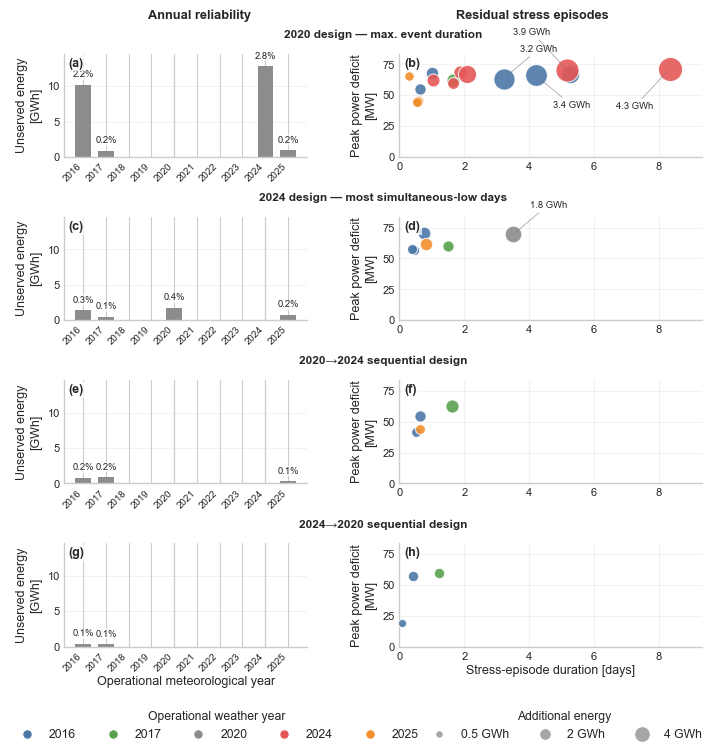

2020: maximum unserved electricity = 12.785 GWh (2.811%) under operational WY2024.
2024: maximum unserved electricity = 1.780 GWh (0.391%) under operational WY2020.
2020→2024: maximum unserved electricity = 0.905 GWh (0.199%) under operational WY2017.
2024→2020: maximum unserved electricity = 0.399 GWh (0.088%) under operational WY2016.
Saved combined Figure 7: output\output_punta_arenas\figures\figure07_operational_robustness_all_designs.svg


In [61]:
# ══════════════════════════════════════════════════════════════════════════════
# FIGURE 7 — Operational robustness across four alternative fixed designs
#
# Rows:
#   1) 2020
#   2) 2024
#   3) 2020→2024
#   4) 2024→2020
#
# Columns:
#   left  = annual unserved electricity
#   right = residual stress episodes
# ══════════════════════════════════════════════════════════════════════════════

STRESS_EPISODE_MAX_GAP_H = 24
MIN_EPISODE_ENERGY_GWH = 1e-4
LABEL_EPISODE_ENERGY_GWH = 1.0

MIN_MARKER_SIZE = 35
MAX_MARKER_SIZE = 300
MAX_ENERGY_LABELS_PER_PANEL = 4

# Full-width manuscript figure: 18 cm
FIGURE7_WIDTH_IN = 18.0 / 2.54
FIGURE7_HEIGHT_IN = 7.7

ROBUSTNESS_YEAR_COLORS = {
    2016: "#4C78A8",
    2017: "#59A14F",
    2024: "#E45756",
    2025: "#F28E2B",
}


def _cluster_slack_events(
    event_df,
    max_gap_h=STRESS_EPISODE_MAX_GAP_H,
):
    """Group nearby contiguous slack events into broader operational stress episodes."""

    if event_df is None or event_df.empty:
        return pd.DataFrame()

    events = event_df.copy()

    events["start"] = pd.to_datetime(
        events["start"]
    )

    events["end"] = pd.to_datetime(
        events["end"]
    )

    events["weather_year"] = pd.to_numeric(
        events["weather_year"],
        errors="coerce",
    ).astype(int)

    events["slack_mwh"] = pd.to_numeric(
        events["slack_mwh"],
        errors="coerce",
    ).fillna(0.0)

    events["peak_slack_mw"] = pd.to_numeric(
        events["peak_slack_mw"],
        errors="coerce",
    ).fillna(0.0)

    rows = []

    def append_cluster(
        cluster_rows,
        weather_year,
    ):
        if not cluster_rows:
            return

        cluster = pd.DataFrame(
            cluster_rows
        )

        start = cluster[
            "start"
        ].min()

        end = cluster[
            "end"
        ].max()

        duration_h = (
            end - start
        ).total_seconds() / 3600.0 + 1.0

        slack_mwh = float(
            cluster[
                "slack_mwh"
            ].sum()
        )

        rows.append(
            {
                "weather_year": int(
                    weather_year
                ),
                "start": start,
                "end": end,
                "duration_h": duration_h,
                "duration_days": duration_h / 24.0,
                "slack_hours": int(
                    cluster[
                        "duration_h"
                    ].sum()
                ),
                "n_slack_events": int(
                    len(cluster)
                ),
                "additional_energy_gwh": (
                    slack_mwh / 1e3
                ),
                "peak_additional_power_mw": float(
                    cluster[
                        "peak_slack_mw"
                    ].max()
                ),
            }
        )

    for (
        weather_year,
        year_events,
    ) in events.groupby(
        "weather_year"
    ):

        year_events = (
            year_events
            .sort_values("start")
            .reset_index(drop=True)
        )

        current_cluster = []
        previous_end = None

        for _, event in year_events.iterrows():

            if previous_end is None:

                current_cluster = [
                    event
                ]

            else:

                gap_h = (
                    event["start"]
                    - previous_end
                ).total_seconds() / 3600.0

                if gap_h <= max_gap_h:

                    current_cluster.append(
                        event
                    )

                else:

                    append_cluster(
                        current_cluster,
                        weather_year,
                    )

                    current_cluster = [
                        event
                    ]

            previous_end = event[
                "end"
            ]

        append_cluster(
            current_cluster,
            weather_year,
        )

    episodes = pd.DataFrame(
        rows
    )

    if episodes.empty:
        return episodes

    episodes = episodes.loc[
        episodes[
            "additional_energy_gwh"
        ]
        > MIN_EPISODE_ENERGY_GWH
    ].copy()

    episodes = (
        episodes
        .sort_values(
            [
                "weather_year",
                "start",
            ]
        )
        .reset_index(
            drop=True
        )
    )

    episodes[
        "episode"
    ] = (
        episodes
        .groupby(
            "weather_year"
        )
        .cumcount()
        + 1
    )

    return episodes


def plot_operational_robustness_all_designs(
    design_rows,
):
    """Create combined 4×2 operational robustness figure."""

    prepared = []

    # ──────────────────────────────────────────────────────────────────────────
    # Prepare datasets
    # ──────────────────────────────────────────────────────────────────────────

    for row in design_rows:

        summary = row[
            "summary"
        ]

        if (
            summary is None
            or summary.empty
        ):

            prepared.append(
                {
                    **row,
                    "summary_ready": False,
                    "episodes": pd.DataFrame(),
                }
            )

            continue

        df = (
            summary
            .copy()
            .sort_values(
                "weather_year"
            )
            .reset_index(
                drop=True
            )
        )

        for col in [
            "weather_year",
            "slack_gwh",
            "slack_share_pct",
            "demand_gwh",
        ]:

            if col in df.columns:

                df[col] = pd.to_numeric(
                    df[col],
                    errors="coerce",
                )

        episodes = (
            _cluster_slack_events(
                row[
                    "events"
                ]
            )
        )

        prepared.append(
            {
                **row,
                "summary_ready": True,
                "summary_plot": df,
                "episodes": episodes,
            }
        )

    # ──────────────────────────────────────────────────────────────────────────
    # Common scales
    # ──────────────────────────────────────────────────────────────────────────

    max_slack = 0.0
    max_duration = 0.0
    max_peak = 0.0

    all_episode_energy = []

    for row in prepared:

        if row.get(
            "summary_ready",
            False,
        ):

            max_slack = max(
                max_slack,
                float(
                    pd.to_numeric(
                        row[
                            "summary_plot"
                        ][
                            "slack_gwh"
                        ],
                        errors="coerce",
                    )
                    .fillna(
                        0.0
                    )
                    .max()
                ),
            )

        episodes = row.get(
            "episodes",
            pd.DataFrame(),
        )

        if (
            episodes is not None
            and not episodes.empty
        ):

            all_episode_energy.extend(
                pd.to_numeric(
                    episodes[
                        "additional_energy_gwh"
                    ],
                    errors="coerce",
                )
                .dropna()
                .tolist()
            )

            max_duration = max(
                max_duration,
                float(
                    pd.to_numeric(
                        episodes[
                            "duration_days"
                        ],
                        errors="coerce",
                    )
                    .fillna(
                        0.0
                    )
                    .max()
                ),
            )

            max_peak = max(
                max_peak,
                float(
                    pd.to_numeric(
                        episodes[
                            "peak_additional_power_mw"
                        ],
                        errors="coerce",
                    )
                    .fillna(
                        0.0
                    )
                    .max()
                ),
            )

    max_slack = max(
        max_slack,
        0.25,
    )

    max_duration = max(
        max_duration,
        1.0,
    )

    max_peak = max(
        max_peak,
        10.0,
    )

    if all_episode_energy:

        global_energy_min = float(
            np.nanmin(
                all_episode_energy
            )
        )

        global_energy_max = float(
            np.nanmax(
                all_episode_energy
            )
        )

    else:

        global_energy_min = 0.0
        global_energy_max = 1.0

    # ──────────────────────────────────────────────────────────────────────────
    # Figure
    # ──────────────────────────────────────────────────────────────────────────

    fig, axes = plt.subplots(
        nrows=4,
        ncols=2,
        figsize=(
            FIGURE7_WIDTH_IN,
            FIGURE7_HEIGHT_IN,
        ),
        gridspec_kw={
            "width_ratios": [
                1.0,
                1.25,
            ],
            "hspace": 0.58,
            "wspace": 0.34,
        },
    )

    panel_letters = iter(
        [
            "(a)",
            "(b)",
            "(c)",
            "(d)",
            "(e)",
            "(f)",
            "(g)",
            "(h)",
        ]
    )

    combined_annual_rows = []
    combined_episode_rows = []

    # ──────────────────────────────────────────────────────────────────────────
    # Draw panels
    # ──────────────────────────────────────────────────────────────────────────

    for (
        row_idx,
        row,
    ) in enumerate(
        prepared
    ):

        ax_l = axes[
            row_idx,
            0,
        ]

        ax_r = axes[
            row_idx,
            1,
        ]

        panel_l = next(
            panel_letters
        )

        panel_r = next(
            panel_letters
        )

        design_label = row[
            "label"
        ]

        # ══════════════════════════════════════════════════════════════════════
        # LEFT — Annual unserved energy
        # ══════════════════════════════════════════════════════════════════════

        if not row.get(
            "summary_ready",
            False,
        ):

            years_local = list(
                range(
                    2016,
                    2026,
                )
            )

            x = np.arange(
                len(
                    years_local
                )
            )

            ax_l.text(
                0.5,
                0.5,
                "Robustness results not available",
                transform=ax_l.transAxes,
                ha="center",
                va="center",
                fontsize=8,
            )

        else:

            df = row[
                "summary_plot"
            ]

            years_local = (
                df[
                    "weather_year"
                ]
                .astype(int)
                .tolist()
            )

            x = np.arange(
                len(df)
            )

            slack = pd.to_numeric(
                df[
                    "slack_gwh"
                ],
                errors="coerce",
            ).fillna(
                0.0
            )

            slack_pct = pd.to_numeric(
                df.get(
                    "slack_share_pct",
                    pd.Series(
                        0.0,
                        index=df.index,
                    ),
                ),
                errors="coerce",
            ).fillna(
                0.0
            )

            ax_l.bar(
                x,
                slack.to_numpy(
                    float
                ),
                width=0.68,
                color="0.55",
            )

            # Weather year(s) explicitly represented during capacity planning.
            for marked_year in row[
                "design_years"
            ]:

                if int(
                    marked_year
                ) in years_local:

                    ax_l.axvline(
                        years_local.index(
                            int(
                                marked_year
                            )
                        ),
                        color="0.35",
                        linewidth=0.8,
                        linestyle=":",
                        zorder=0,
                    )

            # Share of annual local demand.
            for (
                xi,
                gwh,
                pct,
            ) in zip(
                x,
                slack,
                slack_pct,
            ):

                if gwh > 1e-6:

                    ax_l.annotate(
                        f"{pct:.1f}%",
                        xy=(
                            xi,
                            gwh,
                        ),
                        xytext=(
                            0,
                            4,
                        ),
                        textcoords="offset points",
                        ha="center",
                        va="bottom",
                        fontsize=6.8,
                        bbox={
                            "facecolor": "white",
                            "edgecolor": "none",
                            "alpha": 0.78,
                            "pad": 0.35,
                        },
                    )

            export_df = df.copy()

            export_df[
                "design_label"
            ] = design_label

            export_df = export_df[
                [
                    "design_label"
                ]
                + [
                    col
                    for col
                    in export_df.columns
                    if col
                    != "design_label"
                ]
            ]

            combined_annual_rows.append(
                export_df
            )

        # Keep numeric year ticks in every subplot.
        ax_l.set_xticks(
            x
        )

        ax_l.set_xticklabels(
            years_local,
            rotation=45,
            ha="right",
            fontsize=7,
        )

        # Axis title only on bottom row.
        if row_idx == 3:

            ax_l.set_xlabel(
                "Operational meteorological year",
                labelpad=2,
            )

        else:

            ax_l.set_xlabel(
                ""
            )

        ax_l.set_ylabel(
            "Unserved energy\n[GWh]"
        )

        ax_l.set_ylim(
            0.0,
            max_slack
            * 1.14,
        )

        ax_l.grid(
            axis="y",
            alpha=0.25,
        )

        ax_l.set_axisbelow(
            True
        )

        ax_l.spines[
            "top"
        ].set_visible(
            False
        )

        ax_l.spines[
            "right"
        ].set_visible(
            False
        )

        _paper_panel_label(
            ax_l,
            panel_l,
        )

        # ══════════════════════════════════════════════════════════════════════
        # RIGHT — Residual stress episodes
        # ══════════════════════════════════════════════════════════════════════

        episodes = row.get(
            "episodes",
            pd.DataFrame(),
        )

        if (
            episodes is None
            or episodes.empty
        ):

            has_any_slack = False

            if row.get(
                "summary_ready",
                False,
            ):

                has_any_slack = (
                    pd.to_numeric(
                        row[
                            "summary_plot"
                        ][
                            "slack_gwh"
                        ],
                        errors="coerce",
                    )
                    .fillna(
                        0.0
                    )
                    .max()
                    > 1e-9
                )

            message = (
                "No unserved-demand stress episodes"
                if (
                    row.get(
                        "summary_ready",
                        False,
                    )
                    and not has_any_slack
                )
                else
                "Stress-episode diagnostics not available"
            )

            ax_r.text(
                0.5,
                0.5,
                message,
                transform=ax_r.transAxes,
                ha="center",
                va="center",
                fontsize=8,
            )

        else:

            # First pass: draw all stress-episode bubbles.
            for _, event in episodes.iterrows():

                energy = float(
                    event[
                        "additional_energy_gwh"
                    ]
                )

                duration = float(
                    event[
                        "duration_days"
                    ]
                )

                peak_power = float(
                    event[
                        "peak_additional_power_mw"
                    ]
                )

                if (
                    global_energy_max
                    > global_energy_min
                ):

                    marker_size = (
                        MIN_MARKER_SIZE
                        + (
                            (
                                energy
                                - global_energy_min
                            )
                            /
                            (
                                global_energy_max
                                - global_energy_min
                            )
                        )
                        * (
                            MAX_MARKER_SIZE
                            - MIN_MARKER_SIZE
                        )
                    )

                else:

                    marker_size = (
                        MIN_MARKER_SIZE
                        + MAX_MARKER_SIZE
                    ) / 2

                weather_year = int(
                    event[
                        "weather_year"
                    ]
                )

                color = (
                    ROBUSTNESS_YEAR_COLORS.get(
                        weather_year,
                        "0.55",
                    )
                )

                ax_r.scatter(
                    duration,
                    peak_power,
                    s=marker_size,
                    color=color,
                    edgecolor="white",
                    linewidth=0.7,
                    alpha=0.90,
                    zorder=3,
                )

            # Label only the largest residual episodes.
            label_events = (
                episodes.loc[
                    episodes[
                        "additional_energy_gwh"
                    ]
                    >= LABEL_EPISODE_ENERGY_GWH
                ]
                .nlargest(
                    MAX_ENERGY_LABELS_PER_PANEL,
                    "additional_energy_gwh",
                )
                .sort_values(
                    "duration_days"
                )
                .reset_index(
                    drop=True
                )
            )

            label_offsets = [
                (12, 18),
                (12, -18),
                (-12, 24),
                (-12, -24),
            ]

            for (
                label_idx,
                (_, event),
            ) in enumerate(
                label_events.iterrows()
            ):

                duration = float(
                    event[
                        "duration_days"
                    ]
                )

                peak_power = float(
                    event[
                        "peak_additional_power_mw"
                    ]
                )

                energy = float(
                    event[
                        "additional_energy_gwh"
                    ]
                )

                dx, dy = label_offsets[
                    label_idx
                    % len(
                        label_offsets
                    )
                ]

                if (
                    duration
                    > 0.75
                    * max_duration
                    and dx > 0
                ):

                    dx = -abs(
                        dx
                    )

                elif (
                    duration
                    < 0.10
                    * max_duration
                    and dx < 0
                ):

                    dx = abs(
                        dx
                    )

                ax_r.annotate(
                    f"{energy:.1f} GWh",
                    xy=(
                        duration,
                        peak_power,
                    ),
                    xytext=(
                        dx,
                        dy,
                    ),
                    textcoords="offset points",
                    ha=(
                        "left"
                        if dx >= 0
                        else "right"
                    ),
                    va=(
                        "bottom"
                        if dy >= 0
                        else "top"
                    ),
                    fontsize=6.8,
                    zorder=6,
                    bbox={
                        "boxstyle": "round,pad=0.15",
                        "facecolor": "white",
                        "edgecolor": "none",
                        "alpha": 0.92,
                    },
                    arrowprops={
                        "arrowstyle": "-",
                        "color": "0.45",
                        "linewidth": 0.45,
                        "alpha": 0.8,
                        "shrinkA": 2,
                        "shrinkB": 3,
                    },
                )

            export_episodes = (
                episodes.copy()
            )

            export_episodes[
                "design_label"
            ] = design_label

            export_episodes = (
                export_episodes[
                    [
                        "design_label"
                    ]
                    + [
                        col
                        for col
                        in export_episodes.columns
                        if col
                        != "design_label"
                    ]
                ]
            )

            combined_episode_rows.append(
                export_episodes
            )

        ax_r.set_xlim(
            0.0,
            max_duration
            * 1.12,
        )

        ax_r.set_ylim(
            0.0,
            max_peak
            * 1.17,
        )

        # Axis title only on bottom row.
        if row_idx == 3:

            ax_r.set_xlabel(
                "Stress-episode duration [days]",
                labelpad=2,
            )

        else:

            ax_r.set_xlabel(
                ""
            )

        ax_r.set_ylabel(
            "Peak power deficit\n[MW]"
        )

        ax_r.grid(
            axis="both",
            alpha=0.25,
        )

        ax_r.set_axisbelow(
            True
        )

        ax_r.spines[
            "top"
        ].set_visible(
            False
        )

        ax_r.spines[
            "right"
        ].set_visible(
            False
        )

        _paper_panel_label(
            ax_r,
            panel_r,
        )

    # ──────────────────────────────────────────────────────────────────────────
    # Shared legends
    # ──────────────────────────────────────────────────────────────────────────

    active_years = sorted(
        {
            int(year)
            for row
            in prepared
            for year
            in (
                row.get(
                    "episodes",
                    pd.DataFrame(),
                ).get(
                    "weather_year",
                    pd.Series(
                        dtype=float
                    ),
                )
                if row.get(
                    "episodes",
                    pd.DataFrame(),
                )
                is not None
                else []
            )
        }
    )

    legend_handles = []

    if active_years:

        legend_handles = [
            Line2D(
                [0],
                [0],
                marker="o",
                linestyle="None",
                markersize=6.8,
                markerfacecolor=ROBUSTNESS_YEAR_COLORS.get(
                    year,
                    "0.55",
                ),
                markeredgecolor="white",
                markeredgewidth=0.7,
                label=str(
                    year
                ),
            )
            for year
            in active_years
        ]

    if all_episode_energy:

        max_energy = (
            global_energy_max
        )

        if max_energy >= 4.0:

            representative_energy = [
                0.5,
                2.0,
                4.0,
            ]

        elif max_energy >= 2.0:

            representative_energy = [
                0.5,
                1.0,
                2.0,
            ]

        elif max_energy >= 1.0:

            representative_energy = [
                0.25,
                0.5,
                1.0,
            ]

        else:

            representative_energy = [
                0.1,
                0.25,
                0.5,
            ]

        representative_energy = [
            e
            for e
            in representative_energy
            if (
                e
                <= max_energy
                * 1.05
            )
        ]

        size_handles = []

        for energy in representative_energy:

            if (
                global_energy_max
                > global_energy_min
            ):

                size = (
                    MIN_MARKER_SIZE
                    + (
                        (
                            energy
                            - global_energy_min
                        )
                        /
                        (
                            global_energy_max
                            - global_energy_min
                        )
                    )
                    * (
                        MAX_MARKER_SIZE
                        - MIN_MARKER_SIZE
                    )
                )

            else:

                size = (
                    MIN_MARKER_SIZE
                    + MAX_MARKER_SIZE
                ) / 2

            size = np.clip(
                size,
                MIN_MARKER_SIZE,
                MAX_MARKER_SIZE,
            )

            size_handles.append(
                Line2D(
                    [0],
                    [0],
                    marker="o",
                    linestyle="None",
                    markersize=(
                        np.sqrt(
                            size
                        )
                        / 1.5
                    ),
                    markerfacecolor="0.65",
                    markeredgecolor="white",
                    markeredgewidth=0.7,
                    label=f"{energy:g} GWh",
                )
            )

        fig.legend(
            handles=legend_handles,
            title="Operational weather year",
            loc="lower center",
            bbox_to_anchor=(
                0.30,
                0.018,
            ),
            ncol=max(
                1,
                len(
                    active_years
                ),
            ),
            frameon=False,
            fontsize=8.8,
            title_fontsize=8.8,
        )

        fig.legend(
            handles=size_handles,
            title="Additional energy",
            loc="lower center",
            bbox_to_anchor=(
                0.79,
                0.018,
            ),
            ncol=max(
                1,
                len(
                    size_handles
                ),
            ),
            frameon=False,
            fontsize=8.8,
            title_fontsize=8.8,
        )

    # ──────────────────────────────────────────────────────────────────────────
    # Layout
    # ──────────────────────────────────────────────────────────────────────────

    fig.subplots_adjust(
        left=0.085,
        right=0.985,
        top=0.925,
        bottom=0.155,
        hspace=0.58,
        wspace=0.34,
    )

    # Column headings
    fig.text(
        0.275,
        0.982,
        "Annual reliability",
        ha="center",
        va="top",
        fontsize=9.2,
        fontweight="bold",
    )

    fig.text(
        0.745,
        0.982,
        "Residual stress episodes",
        ha="center",
        va="top",
        fontsize=9.2,
        fontweight="bold",
    )

    # Row headings:
    # centred across the full figure width between both columns.
    for (
        row_idx,
        row,
    ) in enumerate(
        prepared
    ):

        left_pos = axes[
            row_idx,
            0,
        ].get_position()

        right_pos = axes[
            row_idx,
            1,
        ].get_position()

        row_x = (
            left_pos.x0
            + right_pos.x1
        ) / 2.0

        row_y = (
            max(
                left_pos.y1,
                right_pos.y1,
            )
            + 0.018
        )

        fig.text(
            row_x,
            row_y,
            row[
                "title"
            ],
            ha="center",
            va="bottom",
            fontsize=8.5,
            fontweight="bold",
        )

    # ──────────────────────────────────────────────────────────────────────────
    # Export figure
    # ──────────────────────────────────────────────────────────────────────────

    figure_path = save_paper_figure(
        fig,
        "figure07_operational_robustness_all_designs.svg",
    )

    save_paper_figure(
        fig,
        "figure07_operational_robustness_all_designs.png",
    )

    plt.show()

    # ──────────────────────────────────────────────────────────────────────────
    # Export tables
    # ──────────────────────────────────────────────────────────────────────────

    annual_export = (
        pd.concat(
            combined_annual_rows,
            ignore_index=True,
        )
        if combined_annual_rows
        else pd.DataFrame()
    )

    episode_export = (
        pd.concat(
            combined_episode_rows,
            ignore_index=True,
        )
        if combined_episode_rows
        else pd.DataFrame()
    )

    annual_export.to_csv(
        TABLE_EXPORT_DIR
        / "figure07_operational_robustness_all_designs.csv",
        index=False,
    )

    episode_export.to_csv(
        TABLE_EXPORT_DIR
        / "figure07_stress_episodes_all_designs.csv",
        index=False,
    )

    # ──────────────────────────────────────────────────────────────────────────
    # Console summary
    # ──────────────────────────────────────────────────────────────────────────

    for row in prepared:

        if not row.get(
            "summary_ready",
            False,
        ):

            print(
                f"{row['label']}: "
                "robustness results not available."
            )

            continue

        df = row[
            "summary_plot"
        ]

        slack = pd.to_numeric(
            df[
                "slack_gwh"
            ],
            errors="coerce",
        ).fillna(
            0.0
        )

        max_idx = (
            slack.idxmax()
        )

        max_value = float(
            slack.loc[
                max_idx
            ]
        )

        max_year = int(
            df.loc[
                max_idx,
                "weather_year",
            ]
        )

        if max_value <= 1e-9:

            print(
                f"{row['label']}: "
                "zero unserved electricity across 2016–2025."
            )

        else:

            pct = float(
                pd.to_numeric(
                    pd.Series(
                        [
                            df.loc[
                                max_idx,
                                "slack_share_pct",
                            ]
                        ]
                    ),
                    errors="coerce",
                )
                .fillna(
                    0.0
                )
                .iloc[0]
            )

            print(
                f"{row['label']}: "
                f"maximum unserved electricity = "
                f"{max_value:.3f} GWh "
                f"({pct:.3f}%) "
                f"under operational WY{max_year}."
            )

    return (
        figure_path,
        annual_export,
        episode_export,
    )


# ══════════════════════════════════════════════════════════════════════════════
# FOUR FIXED DESIGNS
# ══════════════════════════════════════════════════════════════════════════════

ROBUSTNESS_DESIGN_ROWS = [
    {
        "key": "2020",
        "label": "2020",
        "title": "2020 design — max. event duration",
        "design_years": [
            2020
        ],
        "summary": weather_robustness_summary,
        "events": slack_event_summary,
    },
    {
        "key": "2024",
        "label": "2024",
        "title": "2024 design — most simultaneous-low days",
        "design_years": [
            2024
        ],
        "summary": weather_robustness_2024_summary,
        "events": slack_event_summary_2024,
    },
    {
        "key": "2020_to_2024",
        "label": "2020→2024",
        "title": "2020→2024 sequential design",
        "design_years": [
            2020,
            2024,
        ],
        "summary": weather_robustness_2020_to_2024_summary,
        "events": slack_event_summary_2020_to_2024,
    },
    {
        "key": "2024_to_2020",
        "label": "2024→2020",
        "title": "2024→2020 sequential design",
        "design_years": [
            2024,
            2020,
        ],
        "summary": weather_robustness_2024_to_2020_summary,
        "events": slack_event_summary_2024_to_2020,
    },
]


figure7_path, operational_robustness_table, stress_episode_table = (
    plot_operational_robustness_all_designs(
        ROBUSTNESS_DESIGN_ROWS
    )
)

print(
    f"Saved combined Figure 7: {figure7_path}"
)

In [58]:
cols = [
    "weather_year",
    "start",
    "end",
    "duration_h",
    "slack_mwh",
    "peak_slack_mw",
]

print("2020→2024")
display(
    slack_event_summary_2020_to_2024
    .query("weather_year in [2016, 2017]")[cols]
)

print("2024→2020")
display(
    slack_event_summary_2024_to_2020
    .query("weather_year in [2016, 2017]")[cols]
)

2020→2024


,weather_year,start,end,duration_h,slack_mwh,peak_slack_mw
0,2016,2050-05-18 13:00:00,2050-05-19 00:00:00,12,269.121969,41.286274
1,2016,2050-08-01 01:00:00,2050-08-01 15:00:00,15,524.496709,54.794001
2,2017,2050-04-02 01:00:00,2050-04-02 12:00:00,12,551.325894,62.608601
3,2017,2050-04-02 22:00:00,2050-04-02 23:00:00,2,29.052060,19.757437
4,2017,2050-04-03 06:00:00,2050-04-03 15:00:00,10,324.652390,59.830466


2024→2020


,weather_year,start,end,duration_h,slack_mwh,peak_slack_mw
0,2016,2050-05-18 23:00:00,2050-05-19 00:00:00,2,36.396351,19.001332
1,2016,2050-08-01 06:00:00,2050-08-01 06:00:00,1,27.466759,27.466759
2,2016,2050-08-01 08:00:00,2050-08-01 08:00:00,1,46.527445,46.527445
3,2016,2050-08-01 10:00:00,2050-08-01 15:00:00,6,289.023831,57.459018
4,2017,2050-04-02 11:00:00,2050-04-02 11:00:00,1,28.486511,28.486511
5,2017,2050-04-02 22:00:00,2050-04-02 23:00:00,2,27.245691,17.161797
6,2017,2050-04-03 06:00:00,2050-04-03 15:00:00,10,312.563893,59.830466


## 5. Supplementary and diagnostic analyses

These cells are intentionally kept outside the main-paper figure sequence. They provide detailed maps, decompositions, curtailment, BESS/H₂ operation, and event-window diagnostics useful for validation, Supplementary Material, and discussion.


### 5.1 Georeferenced comparison maps

In [51]:
# ─────────────────────────────────────────────────────────────────────────────
# Cross-scenario georeferenced maps
# ─────────────────────────────────────────────────────────────────────────────

# ── Independent map configuration ─────────────────────────────────────────────
MAP_YEAR = 2050

MAP_SCENARIOS = [
    "BAU_base",
    "RT0_base",
    "RT_base",
    "RT80_base",
    "RE_base",
    "RH_base",
    "PTX_base",
]

MAP_SCENARIO_LABELS = {
    "BAU_base": "BAU",
    "RT0_base": "RT0",
    "RT_base": "RT50",
    "RT80_base": "RT80",
    "RE_base": "NZE",
    "RH_base": "H₂",
    "PTX_base": "PtX",
}

# "grid": two columns
# "vertical": one map per row
MAP_LAYOUT = "grid"

MAP_HEIGHT = 460 if MAP_LAYOUT == "grid" else 560
MAP_MAX_ZOOM = 11

SAVE_INDIVIDUAL_HTML = True
SAVE_COMPARISON_HTML = True

# ── Paths independent from previous plotting cells ───────────────────────────
CASE_FOLDER = Path("input_punta_arenas")

MAP_ROOT = Path('output') / 'output_punta_arenas'

map_output_dir = MAP_ROOT / 'figures' / 'maps'

map_table_dir = MAP_ROOT / 'tables' / 'maps'

map_output_dir.mkdir(parents=True, exist_ok=True)

map_table_dir.mkdir(parents=True, exist_ok=True)

# ── Check or reload exported scenario results ─────────────────────────────────
if "scenario_results" not in globals():
    if "load_exported_scenario_results" not in globals():
        raise NameError(
            "The exported-results loader is not available. "
            "Run the imports/configuration cells and the cell defining "
            "load_exported_scenario_results() before this map cell. "
            "The simulations do not need to be rerun."
        )
    scenario_results, scenario_summary = (
        load_exported_scenario_results(
            scenario_codes=MAP_SCENARIOS,
        )
    )
print(f'Building maps for {MAP_YEAR}. Output directory: {map_output_dir}')


Building maps for 2050. Output directory: output\output_punta_arenas\figures\maps


### 5.2 Cross-scenario supplementary tables and decompositions

Saved figure: output\output_punta_arenas\figures\cross_scenario_all_years\figure_supp_cross_scenario_decomposition_2025.png


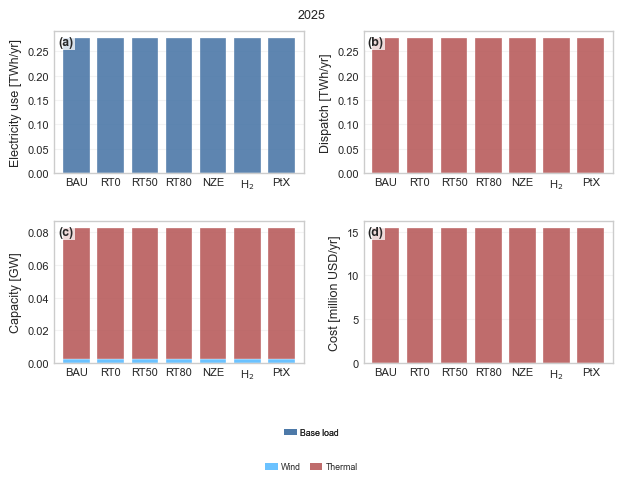

Saved figure: output\output_punta_arenas\figures\cross_scenario_all_years\figure_supp_cross_scenario_decomposition_2030.png


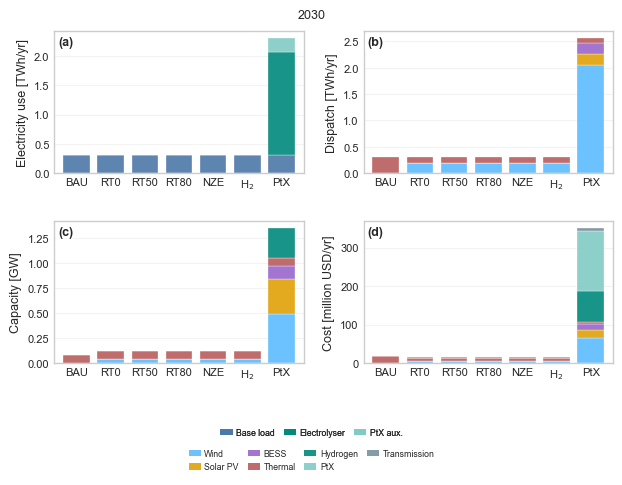

Saved figure: output\output_punta_arenas\figures\cross_scenario_all_years\figure_supp_cross_scenario_decomposition_2040.png


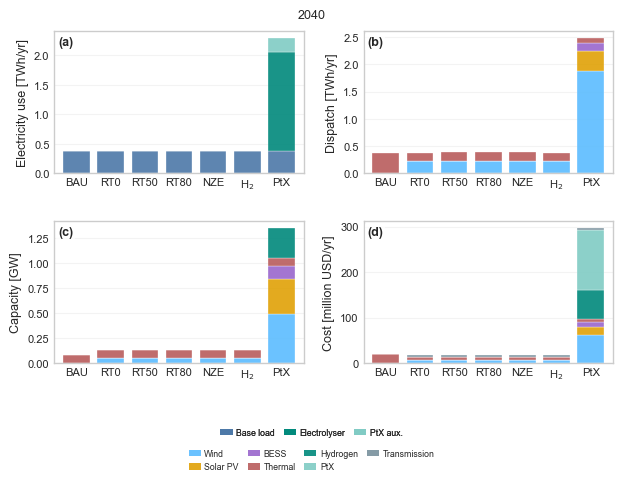

Saved figure: output\output_punta_arenas\figures\cross_scenario_all_years\figure_supp_cross_scenario_decomposition_2050.png


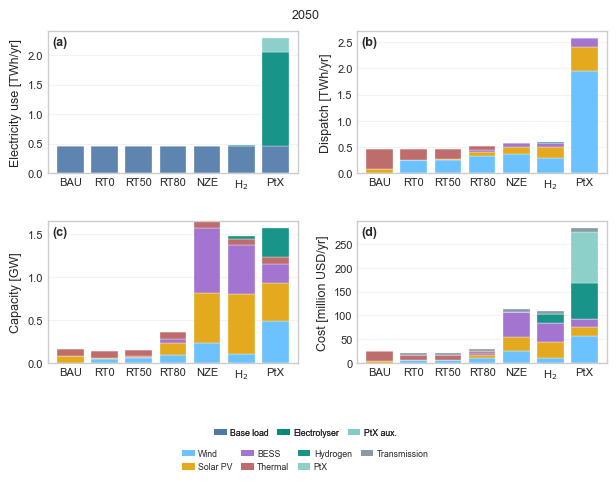

In [52]:
# Supplementary cross-scenario decomposition

# Local compatibility fix:
# another later cell redefines _snapshot_weights(net), which overwrites the
# earlier cost helper that expects _snapshot_weights(net, component).
# This version supports both calling conventions.
def _snapshot_weights(net, component="generators"):
    try:
        if hasattr(net.snapshot_weightings, component):
            values = getattr(net.snapshot_weightings, component)

        elif component in net.snapshot_weightings.columns:
            values = net.snapshot_weightings[component]

        elif "objective" in net.snapshot_weightings.columns:
            values = net.snapshot_weightings["objective"]

        else:
            values = np.ones(len(net.snapshots))

        values = np.asarray(values, dtype=float).reshape(-1)

        if len(values) != len(net.snapshots):
            values = np.ones(len(net.snapshots))

        return pd.Series(values, index=net.snapshots)

    except Exception:
        return pd.Series(
            1.0,
            index=net.snapshots,
            dtype=float,
        )


cross_scenario_years_to_plot = years
cross_scenario_export_dir = PAPER_FIGURE_DIR / "cross_scenario_all_years"
cross_scenario_export_dir.mkdir(parents=True, exist_ok=True)


def build_demand_group_df(df_year):
    """Build electricity-use decomposition [TWh/yr]."""
    out = pd.DataFrame(index=df_year.index)

    if demand_breakdown_summary.empty:
        raise ValueError(
            "Demand breakdown is empty. Run the previous section first."
        )

    demand_y = demand_breakdown_summary[
        demand_breakdown_summary["year"] == int(df_year["year"].iloc[0])
    ].copy()

    demand_y = apply_scenario_order(demand_y)
    demand_y = demand_y.set_index("scenario").reindex(
        df_year["scenario"]
    )

    mapping = {
        "Base load": "demand_base_load_mwh",
        "Heating": "demand_heating_mwh",
        "EVs": "demand_ev_mwh",
        "Cooking": "demand_cooking_mwh",
        "Process electrification": "demand_process_electrification_mwh",
        "Electrolyser": "electrolyser_input_mwh",
        "PtX auxiliaries": "ptx_aux_electricity_mwh",
        "Other local demand": "demand_other_mwh",
    }

    for group, col in mapping.items():
        if col in demand_y.columns:
            out[group] = (
                demand_y[col]
                .fillna(0.0)
                .values
                / 1e6
            )
        else:
            out[group] = 0.0

    for group in DEMAND_GROUPS:
        if group not in out.columns:
            out[group] = 0.0

    return out[DEMAND_GROUPS]


def build_dispatch_group_df(df_year):
    """Build annual electricity dispatch by technology [TWh/yr]."""
    out = pd.DataFrame(index=df_year.index)

    out["Wind"] = (
        df_year.get(
            "generation_wind_mwh",
            0.0,
        )
        / 1e6
    )

    out["Solar PV"] = (
        df_year.get(
            "generation_solar_mwh",
            0.0,
        )
        / 1e6
    )

    out["BESS"] = (
        df_year.get(
            "bess_discharge_mwh",
            0.0,
        )
        / 1e6
    )

    thermal_cols = [
        "generation_ocgt_mwh",
        "generation_gas_mwh",
        "generation_natural_gas_mwh",
        "generation_diesel_mwh",
    ]

    valid_thermal_cols = [
        c
        for c in thermal_cols
        if c in df_year.columns
    ]

    out["Thermal"] = (
        df_year[
            valid_thermal_cols
        ]
        .fillna(0.0)
        .sum(axis=1)
        / 1e6
        if valid_thermal_cols
        else 0.0
    )

    if "h2_to_power_mwh" in df_year.columns:
        out["Hydrogen"] = (
            df_year[
                "h2_to_power_mwh"
            ]
            .fillna(0.0)
            / 1e6
        )

    else:
        h2_cols = [
            "h2_fuel_cell_output_mwh",
            "h2_turbine_output_mwh",
        ]

        valid_h2_cols = [
            c
            for c in h2_cols
            if c in df_year.columns
        ]

        out["Hydrogen"] = (
            df_year[
                valid_h2_cols
            ]
            .fillna(0.0)
            .sum(axis=1)
            / 1e6
            if valid_h2_cols
            else 0.0
        )

    out["PtX"] = 0.0
    out["Slack"] = (
        df_year.get(
            "generation_slack_mwh",
            0.0,
        )
        / 1e6
    )

    out["Other"] = 0.0

    for group in TECH_GROUPS:
        if group not in out.columns:
            out[group] = 0.0

    return out[TECH_GROUPS]


def build_capacity_group_df(df_year):
    """Build installed capacity by technology [GW]."""
    out = pd.DataFrame(index=df_year.index)

    out["Wind"] = (
        df_year.get(
            "cap_wind_mw",
            0.0,
        )
        / 1e3
    )

    out["Solar PV"] = (
        df_year.get(
            "cap_solar_mw",
            0.0,
        )
        / 1e3
    )

    out["BESS"] = (
        df_year.get(
            "cap_bess_mw",
            0.0,
        )
        / 1e3
    )

    thermal_cols = [
        "cap_ocgt_mw",
        "cap_gas_mw",
        "cap_natural_gas_mw",
        "cap_diesel_mw",
    ]

    valid_thermal_cols = [
        c
        for c in thermal_cols
        if c in df_year.columns
    ]

    out["Thermal"] = (
        df_year[
            valid_thermal_cols
        ]
        .fillna(0.0)
        .sum(axis=1)
        / 1e3
        if valid_thermal_cols
        else 0.0
    )

    hydrogen_cols = [
        "linkcap_electrolyzer_mw",
        "linkcap_h2_fuel_cell_mw",
        "linkcap_h2_turbine_mw",
    ]

    valid_hydrogen_cols = [
        c
        for c in hydrogen_cols
        if c in df_year.columns
    ]

    out["Hydrogen"] = (
        df_year[
            valid_hydrogen_cols
        ]
        .fillna(0.0)
        .sum(axis=1)
        / 1e3
        if valid_hydrogen_cols
        else 0.0
    )

    out["PtX"] = 0.0
    out["Slack"] = 0.0
    out["Other"] = 0.0

    for group in TECH_GROUPS:
        if group not in out.columns:
            out[group] = 0.0

    return out[TECH_GROUPS]


def plot_cross_scenario_supplementary(
    comparison_year,
    save_figure=True,
    show_figure=True,
):
    df_y = scenario_comparison[
        scenario_comparison["year"]
        == comparison_year
    ].copy()

    if df_y.empty:
        raise ValueError(
            f"No scenario comparison data found for {comparison_year}."
        )

    df_y = (
        apply_scenario_order(
            df_y
        )
        .reset_index(drop=True)
    )

    df_y["label"] = (
        df_y["scenario"]
        .map(
            SCENARIO_TECH_LABELS
        )
        .fillna(
            df_y["scenario"]
            .astype(str)
        )
    )

    demand_group_df = build_demand_group_df(
        df_y
    )

    dispatch_group_df = build_dispatch_group_df(
        df_y
    )

    capacity_group_df = build_capacity_group_df(
        df_y
    )

    cost_group_df = build_cost_group_df(
        df_y
    )

    fig, axes = plt.subplots(
        2,
        2,
        figsize=FIGSIZE_PAPER_2X2,
    )

    used_demand_groups = set()
    used_tech_groups = set()

    used = plot_stacked_bars(
        axes[0, 0],
        demand_group_df,
        DEMAND_GROUPS,
        DEMAND_COLORS_GROUPED,
        df_y["label"].tolist(),
        ylabel="Electricity use [TWh/yr]",
    )

    used_demand_groups.update(
        used
    )

    panel_label(
        axes[0, 0],
        "(a)",
    )

    used = plot_stacked_bars(
        axes[0, 1],
        dispatch_group_df,
        TECH_GROUPS,
        TECH_COLORS_GROUPED,
        df_y["label"].tolist(),
        ylabel="Dispatch [TWh/yr]",
    )

    used_tech_groups.update(
        used
    )

    panel_label(
        axes[0, 1],
        "(b)",
    )

    used = plot_stacked_bars(
        axes[1, 0],
        capacity_group_df,
        TECH_GROUPS,
        TECH_COLORS_GROUPED,
        df_y["label"].tolist(),
        ylabel="Capacity [GW]",
    )

    used_tech_groups.update(
        used
    )

    panel_label(
        axes[1, 0],
        "(c)",
    )

    used = plot_stacked_bars(
        axes[1, 1],
        cost_group_df,
        TECH_GROUPS,
        TECH_COLORS_GROUPED,
        df_y["label"].tolist(),
        ylabel=COST_AXIS_LABEL,
    )

    used_tech_groups.update(
        used
    )

    panel_label(
        axes[1, 1],
        "(d)",
    )

    fig.text(
        0.5,
        0.975,
        str(comparison_year),
        ha="center",
        va="top",
        fontsize=9,
    )

    # Figure-level legends
    demand_handles = []
    demand_labels = []

    for group in DEMAND_GROUPS:
        if group not in used_demand_groups:
            continue

        demand_handles.append(
            plt.Rectangle(
                (0, 0),
                1,
                1,
                facecolor=DEMAND_COLORS_GROUPED.get(
                    group,
                    "#999999",
                ),
                edgecolor="none",
                alpha=0.90,
            )
        )

        demand_labels.append(
            DEMAND_LEGEND_LABELS.get(
                group,
                group,
            )
        )

    tech_handles = []
    tech_labels = []

    for group in TECH_GROUPS:
        if group not in used_tech_groups:
            continue

        tech_handles.append(
            plt.Rectangle(
                (0, 0),
                1,
                1,
                facecolor=TECH_COLORS_GROUPED.get(
                    group,
                    "#999999",
                ),
                edgecolor="none",
                alpha=0.90,
            )
        )

        tech_labels.append(
            TECH_LEGEND_LABELS.get(
                group,
                group,
            )
        )

    leg1 = fig.legend(
        demand_handles,
        demand_labels,
        loc="lower center",
        bbox_to_anchor=(
            0.5,
            0.095,
        ),
        ncol=4,
        frameon=False,
        fontsize=6.3,
        columnspacing=1.0,
        handlelength=1.4,
        handletextpad=0.4,
    )

    fig.add_artist(
        leg1
    )

    fig.legend(
        tech_handles,
        tech_labels,
        loc="lower center",
        bbox_to_anchor=(
            0.5,
            0.025,
        ),
        ncol=4,
        frameon=False,
        fontsize=6.3,
        columnspacing=1.0,
        handlelength=1.4,
        handletextpad=0.4,
    )

    plt.tight_layout()

    fig.subplots_adjust(
        top=0.93,
        bottom=0.26,
        hspace=0.34,
        wspace=0.24,
    )

    out_path = None

    if save_figure:
        out_path = save_paper_figure(
            fig,
            (
                "figure_supp_cross_scenario_"
                f"decomposition_{comparison_year}.png"
            ),
            folder=cross_scenario_export_dir,
        )

    if show_figure:
        plt.show()

    else:
        plt.close(
            fig
        )

    return out_path


for comparison_year in cross_scenario_years_to_plot:
    plot_cross_scenario_supplementary(
        comparison_year
    )

In [53]:
# Supplementary reliability indicators
#
# Storage/flexibility capacity and operation are reported in the table
# exported by Figure 4 and in each scenario's *_bess_by_year.csv file.
comparison_year = detailed_year
df_y = scenario_comparison[scenario_comparison["year"] == comparison_year].copy()
if df_y.empty:
    raise ValueError(f"No scenario comparison data found for {comparison_year}.")
df_y = apply_scenario_order(df_y).reset_index(drop=True)

reliability_check = pd.DataFrame({
    "scenario": df_y["scenario"],
    "paper_id": df_y["paper_id"] if "paper_id" in df_y.columns else "",
    "year": df_y["year"],
    "slack_generation_gwh": df_y["slack_generation_mwh"].fillna(0.0) / 1e3,
    "curtailment_gwh": df_y["curtailment_total_mwh"].fillna(0.0) / 1e3,
})
display(reliability_check.round(3))


,scenario,paper_id,year,slack_generation_gwh,curtailment_gwh
0,BAU_base,S1,2050,0.0,13.469
1,RT0_base,S2,2050,0.0,13.960
2,RT_base,S3,2050,0.0,32.045
3,RT80_base,S4,2050,0.0,227.709
4,RE_base,S5,2050,0.0,1304.886
5,RH_base,S6,2050,0.0,772.692
6,PTX_base,S7,2050,0.0,539.593


### 5.3 Curtailment diagnostics

In [54]:
# Curtailment calculation
def _get_nominal_capacity_for_curtailment(net, gen_ids):
    """
    Return optimized capacity when available, otherwise nominal capacity.
    Works for both expansion runs and fixed-capacity re-operation.
    """
    gens = net.generators.loc[gen_ids].copy()
    if "p_nom_opt" in gens.columns:
        p_nom = gens["p_nom_opt"].copy()
        p_nom = p_nom.fillna(gens["p_nom"])
    else:
        p_nom = gens["p_nom"].copy()
    return p_nom.astype(float).fillna(0.0)


def build_vre_curtailment_table(net, freq="YS"):
    """
    Build a wind and solar curtailment table.

    Curtailment is calculated as:
        available VRE = p_nom * p_max_pu
        curtailed VRE = max(available VRE - dispatched VRE, 0)

    Parameters
    ----------
    net : pypsa.Network
    freq : str
        "YS" for annual, "MS" for monthly, "D" for daily, "h" for hourly.
    """
    if len(net.generators) == 0:
        return pd.DataFrame()
    rows = []
    vre_carriers = ["wind", "solar"]
    for carrier in vre_carriers:
        gen_ids = net.generators.index[
            net.generators["carrier"].astype(str).str.lower() == carrier
        ].tolist()
        if not gen_ids:
            continue

        # Safer check: do not silently assume p_max_pu = 1 if missing.
        missing_profiles = [g for g in gen_ids if g not in net.generators_t.p_max_pu.columns]
        if missing_profiles:
            raise ValueError(
                f"Missing p_max_pu profiles for {carrier}: {missing_profiles}. "
                "Do not calculate curtailment with assumed p_max_pu = 1.0."
            )
        p_nom = _get_nominal_capacity_for_curtailment(net, gen_ids)
        available = net.generators_t.p_max_pu[gen_ids].clip(lower=0.0).multiply(p_nom, axis=1)
        dispatch = net.generators_t.p[gen_ids].fillna(0.0).clip(lower=0.0)
        curtailed = (available - dispatch).clip(lower=0.0)
        for gen_id in gen_ids:
            bus = net.generators.loc[gen_id, "bus"]
            tmp = pd.DataFrame({
                "available_mwh": available[gen_id],
                "dispatch_mwh": dispatch[gen_id],
                "curtailment_mwh": curtailed[gen_id],
            })
            if freq is not None:
                tmp = tmp.resample(freq).sum()
            for ts, r in tmp.iterrows():
                rows.append({
                    "period": ts,
                    "carrier": carrier,
                    "generator": gen_id,
                    "bus": bus,
                    "available_mwh": float(r["available_mwh"]),
                    "dispatch_mwh": float(r["dispatch_mwh"]),
                    "curtailment_mwh": float(r["curtailment_mwh"]),
                })
    out = pd.DataFrame(rows)
    if out.empty:
        return out
    out["curtailment_share_available_pct"] = np.where(
        out["available_mwh"] > 0,
        100 * out["curtailment_mwh"] / out["available_mwh"],
        np.nan,
    )
    return out


In [43]:
# Curtailment summary tables
curtailment_selection = "all"   # "all", one scenario code, or a list


def _resolve_selection(selection):
    if selection == "all":
        return list(scenario_results.keys())
    if isinstance(selection, str):
        return [selection]
    return list(selection)


curtailment_annual_tables = []
curtailment_monthly_tables = []

for scenario_code in _resolve_selection(curtailment_selection):
    package = scenario_results[scenario_code]
    paper_id = package["metadata"].get("paper_id", "")
    label = scenario_label(scenario_code, paper_id=paper_id)
    for year in years:
        net = package["results"][year]["network"]
        annual_df = build_vre_curtailment_table(net, freq="YS")
        if not annual_df.empty:
            annual_df = annual_df.copy()
            annual_df["scenario"] = scenario_code
            annual_df["paper_id"] = paper_id
            annual_df["scenario_label"] = label
            annual_df["year"] = year
            curtailment_annual_tables.append(annual_df)
        monthly_df = build_vre_curtailment_table(net, freq="MS")
        if not monthly_df.empty:
            monthly_df = monthly_df.copy()
            monthly_df["scenario"] = scenario_code
            monthly_df["paper_id"] = paper_id
            monthly_df["scenario_label"] = label
            monthly_df["year"] = year
            monthly_df["month_num"] = monthly_df["period"].dt.month
            monthly_df["month"] = monthly_df["period"].dt.strftime("%b")
            curtailment_monthly_tables.append(monthly_df)
curtailment_annual_all = pd.concat(curtailment_annual_tables, ignore_index=True) if curtailment_annual_tables else pd.DataFrame()
curtailment_monthly_all = pd.concat(curtailment_monthly_tables, ignore_index=True) if curtailment_monthly_tables else pd.DataFrame()

if not curtailment_annual_all.empty:
    curtailment_annual_summary = (
        curtailment_annual_all
        .groupby(["scenario", "paper_id", "scenario_label", "year", "carrier"], as_index=False)
        [["available_mwh", "dispatch_mwh", "curtailment_mwh"]]
        .sum()
    )
    curtailment_annual_summary["curtailment_share_available_pct"] = np.where(
        curtailment_annual_summary["available_mwh"] > 0,
        100 * curtailment_annual_summary["curtailment_mwh"] / curtailment_annual_summary["available_mwh"],
        np.nan,
    )
    curtailment_annual_total = (
        curtailment_annual_summary
        .groupby(["scenario", "paper_id", "scenario_label", "year"], as_index=False)
        [["available_mwh", "dispatch_mwh", "curtailment_mwh"]]
        .sum()
    )
    curtailment_annual_total["curtailment_share_available_pct"] = np.where(
        curtailment_annual_total["available_mwh"] > 0,
        100 * curtailment_annual_total["curtailment_mwh"] / curtailment_annual_total["available_mwh"],
        np.nan,
    )
else:
    curtailment_annual_summary = pd.DataFrame()
    curtailment_annual_total = pd.DataFrame()
if not curtailment_monthly_all.empty:
    curtailment_monthly_summary = (
        curtailment_monthly_all
        .groupby(["scenario", "paper_id", "scenario_label", "year", "month_num", "month", "carrier"], as_index=False)
        [["available_mwh", "dispatch_mwh", "curtailment_mwh"]]
        .sum()
    )
    curtailment_monthly_summary["curtailment_share_available_pct"] = np.where(
        curtailment_monthly_summary["available_mwh"] > 0,
        100 * curtailment_monthly_summary["curtailment_mwh"] / curtailment_monthly_summary["available_mwh"],
        np.nan,
    )
else:
    curtailment_monthly_summary = pd.DataFrame()
print("Curtailment annual summary rows:", len(curtailment_annual_summary))
print("Curtailment monthly summary rows:", len(curtailment_monthly_summary))
if not curtailment_annual_total.empty:
    display(curtailment_annual_total.head())


Curtailment annual summary rows: 49
Curtailment monthly summary rows: 588


,scenario,paper_id,scenario_label,year,available_mwh,dispatch_mwh,curtailment_mwh,curtailment_share_available_pct
0,BAU_base,S1,S1 BAU base,2025,12858.370371,0.000000,12858.370371,100.000000
1,BAU_base,S1,S1 BAU base,2030,12858.370371,0.000000,12858.370371,100.000000
2,BAU_base,S1,S1 BAU base,2040,12910.701661,0.000000,12910.701661,100.000000
3,BAU_base,S1,S1 BAU base,2050,94816.039742,81347.185085,13468.854656,14.205249
4,PTX_base,S7,S7 PtX base,2025,12858.370371,0.000000,12858.370371,100.000000


INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should

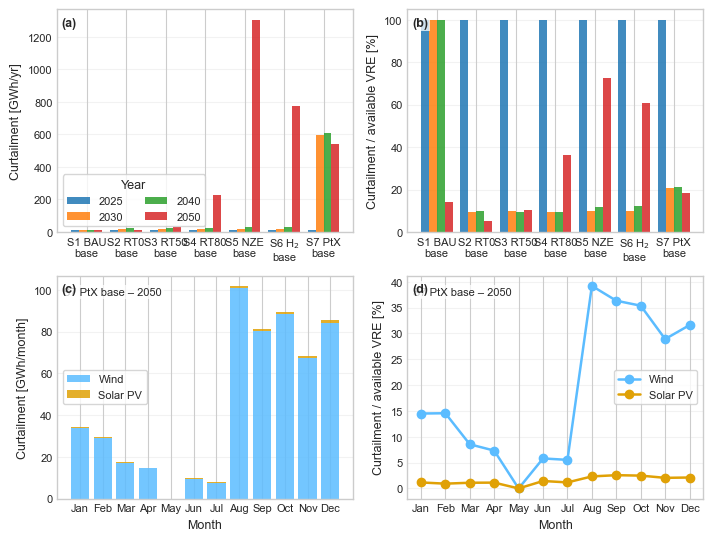

In [44]:
# Curtailment figures
curtailment_focus_scenario = active_scenario
curtailment_focus_year = detailed_year

if curtailment_annual_total.empty:
    raise ValueError("No curtailment summary available. Run the previous cell first.")

# Ordered labels for the annual plots
scenario_order = [s for s in SCENARIO_PLOT_ORDER if s in curtailment_annual_total["scenario"].unique()]
plot_df = curtailment_annual_total.copy()
plot_df["scenario"] = pd.Categorical(plot_df["scenario"], categories=scenario_order, ordered=True)
plot_df = plot_df.sort_values(["scenario", "year"]).copy()
plot_df["x_label"] = [scenario_axis_label(s) for s in plot_df["scenario"]]

unique_scenarios = plot_df[["scenario", "paper_id", "x_label"]].drop_duplicates().sort_values("scenario")
scenario_codes = unique_scenarios["scenario"].tolist()
xlabels = [scenario_axis_label(s) for s in unique_scenarios["scenario"].tolist()]
unique_years = sorted(plot_df["year"].unique())
x = np.arange(len(scenario_codes))
bar_width = 0.8 / max(len(unique_years), 1)

fig, axes = plt.subplots(2, 2, figsize=FIGSIZE_2COL_LARGE)

# (a) Total annual curtailment [GWh/yr]
ax = axes[0, 0]
for i, year in enumerate(unique_years):
    tmp = plot_df[plot_df["year"] == year].set_index("scenario").reindex(scenario_codes)
    values = tmp["curtailment_mwh"].fillna(0).values / 1e3
    ax.bar(x + (i - (len(unique_years)-1)/2) * bar_width, values, width=bar_width, label=str(year), alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(xlabels, rotation=0, ha="center")
finish_axis(ax, ylabel="Curtailment [GWh/yr]")
ax.legend(title="Year", ncol=2, frameon=True)
panel_label(ax, "(a)")

# (b) Curtailment share of available VRE [%]
ax = axes[0, 1]
for i, year in enumerate(unique_years):
    tmp = plot_df[plot_df["year"] == year].set_index("scenario").reindex(scenario_codes)
    values = tmp["curtailment_share_available_pct"].fillna(0).values
    ax.bar(x + (i - (len(unique_years)-1)/2) * bar_width, values, width=bar_width, label=str(year), alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(xlabels, rotation=0, ha="center")
finish_axis(ax, ylabel="Curtailment / available VRE [%]")
panel_label(ax, "(b)")

# Monthly deep-dive for a selected scenario/year
month_order = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
monthly_focus = curtailment_monthly_summary[
    (curtailment_monthly_summary["scenario"] == curtailment_focus_scenario) &
    (curtailment_monthly_summary["year"] == curtailment_focus_year)
].copy()
monthly_focus["month"] = pd.Categorical(monthly_focus["month"], categories=month_order, ordered=True)
monthly_focus = monthly_focus.sort_values(["month", "carrier"])

# (c) Monthly curtailment [GWh/month]
ax = axes[1, 0]
if not monthly_focus.empty:
    pivot_gwh = monthly_focus.pivot_table(index="month", columns="carrier", values="curtailment_mwh", aggfunc="sum").fillna(0) / 1e3
    bottom = np.zeros(len(pivot_gwh))
    for carrier in [c for c in ["wind", "solar"] if c in pivot_gwh.columns]:
        vals = pivot_gwh[carrier].values
        ax.bar(pivot_gwh.index.astype(str), vals, bottom=bottom, color=TECH_COLORS.get(carrier, "#999999"), alpha=0.85, label=clean_technology_label(carrier))
        bottom += vals
    ax.legend(frameon=True)
finish_axis(ax, xlabel="Month", ylabel="Curtailment [GWh/month]")
ax.tick_params(axis="x", rotation=0)
ax.text(0.02, 0.95, f"{scenario_label(curtailment_focus_scenario)} – {curtailment_focus_year}", transform=ax.transAxes, ha="left", va="top", fontsize=FONT_SIZE_SMALL, bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1.2))
panel_label(ax, "(c)")

# (d) Monthly curtailment share [%]
ax = axes[1, 1]
if not monthly_focus.empty:
    pivot_pct = monthly_focus.pivot_table(index="month", columns="carrier", values="curtailment_share_available_pct", aggfunc="sum").fillna(0)
    for carrier in [c for c in ["wind", "solar"] if c in pivot_pct.columns]:
        ax.plot(pivot_pct.index.astype(str), pivot_pct[carrier].values, marker="o", linewidth=1.8, label=clean_technology_label(carrier), color=TECH_COLORS.get(carrier, "#999999"))
    ax.legend(frameon=True)
finish_axis(ax, xlabel="Month", ylabel="Curtailment / available VRE [%]")
ax.tick_params(axis="x", rotation=0)
ax.text(0.02, 0.95, f"{scenario_label(curtailment_focus_scenario)} – {curtailment_focus_year}", transform=ax.transAxes, ha="left", va="top", fontsize=FONT_SIZE_SMALL, bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1.2))
panel_label(ax, "(d)")

plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()


### 5.4 Hydrogen and storage diagnostics

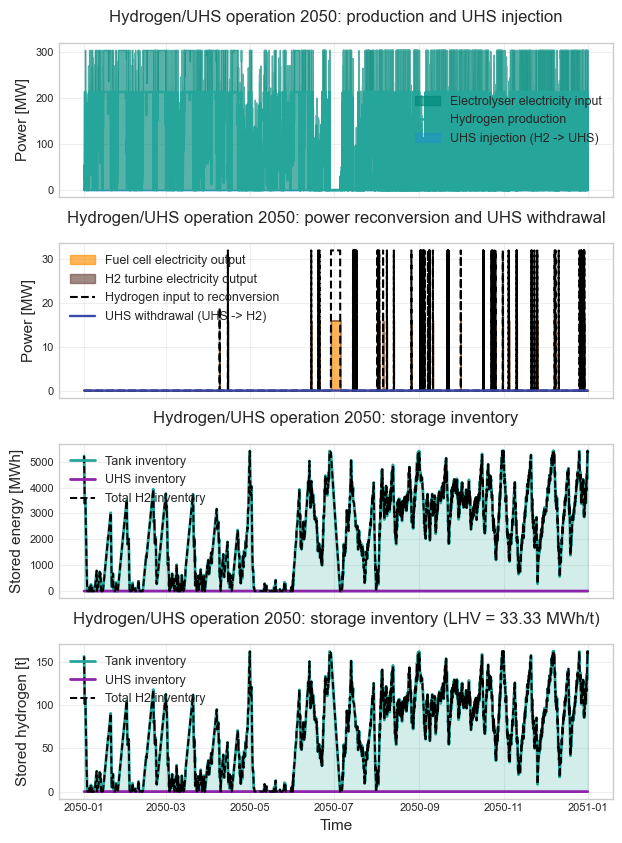

,carrier,bus0,bus1,efficiency,capacity_mw
name,,,,,
h2_electrolyzer_cabo_negro,electrolyzer,elec_cabo_negro,h2_cabo_negro,0.6994,303.633924
h2_fuel_cell_cabo_negro,h2_fuel_cell,h2_cabo_negro,elec_cabo_negro,0.5000,31.934757


,carrier,bus,standing_loss,energy_capacity_mwh
name,,,,
h2_surface_buffer_cabo_negro,hydrogen_storage,h2_cabo_negro,0.0005,5417.760954


,value
electrolyser_input_mwh,1590931.210
hydrogen_production_mwh,1112697.288
uhs_injection_mwh,0.000
uhs_withdrawal_mwh,0.000
hydrogen_reconversion_input_mwh,8205.965
fuel_cell_output_mwh,4102.983
h2_turbine_output_mwh,0.000
peak_tank_inventory_mwh,5417.761
peak_uhs_inventory_mwh,0.000
peak_total_h2_inventory_mwh,5417.761


In [45]:
# Hydrogen and UHS operation
analysis_year = detailed_year
hydrogen_link_carriers = ["electrolyzer", "h2_fuel_cell", "h2_turbine", "uhs_injection", "uhs_withdrawal"]
hydrogen_store_carriers = ["hydrogen_storage", "uhs_storage"]

hydrogen_links = n.links[n.links["carrier"].isin(hydrogen_link_carriers)].copy()
hydrogen_stores = n.stores[n.stores["carrier"].isin(hydrogen_store_carriers)].copy()

if hydrogen_links.empty and hydrogen_stores.empty:
    print(
        f"No hydrogen/UHS assets in the network for {analysis_year}. "
        f"enable_hydrogen={scenario_results[active_scenario]['metadata']['enable_hydrogen']}."
    )
else:
    def _zero_series() -> pd.Series:
        """Return a zero-valued series aligned with the network snapshots."""
        return pd.Series(0.0, index=n.snapshots)
    def _link_input_series(link_index: pd.Index) -> pd.Series:
        """Aggregate electricity input (p0) for the given link indices."""
        if len(link_index) == 0:
            return _zero_series()
        return n.links_t.p0[link_index].clip(lower=0).sum(axis=1)
    def _link_output_series(link_index: pd.Index) -> pd.Series:
        """Aggregate useful output (p0 * efficiency) for the given link indices."""
        if len(link_index) == 0:
            return _zero_series()
        efficiency = n.links.loc[link_index, 'efficiency'].fillna(1.0)
        dispatch = n.links_t.p0[link_index].clip(lower=0)
        return dispatch.multiply(efficiency, axis=1).sum(axis=1)
    electrolyzer_links = hydrogen_links.index[hydrogen_links["carrier"] == "electrolyzer"]
    fuel_cell_links = hydrogen_links.index[hydrogen_links["carrier"] == "h2_fuel_cell"]
    turbine_links = hydrogen_links.index[hydrogen_links["carrier"] == "h2_turbine"]
    uhs_injection_links = hydrogen_links.index[hydrogen_links["carrier"] == "uhs_injection"]
    uhs_withdrawal_links = hydrogen_links.index[hydrogen_links["carrier"] == "uhs_withdrawal"]
    electrolyzer_power = _link_input_series(electrolyzer_links)
    hydrogen_production = _link_output_series(electrolyzer_links)
    fuel_cell_power = _link_output_series(fuel_cell_links)
    turbine_power = _link_output_series(turbine_links)
    hydrogen_to_power = fuel_cell_power + turbine_power
    hydrogen_reconversion_input = _link_input_series(fuel_cell_links) + _link_input_series(turbine_links)
    uhs_injection_power = _link_input_series(uhs_injection_links)
    uhs_withdrawal_power = _link_output_series(uhs_withdrawal_links)
    tank_stores = hydrogen_stores.index[hydrogen_stores["carrier"] == "hydrogen_storage"]
    uhs_stores = hydrogen_stores.index[hydrogen_stores["carrier"] == "uhs_storage"]
    tank_inventory = _zero_series() if len(tank_stores) == 0 else n.stores_t.e[tank_stores].sum(axis=1)
    uhs_inventory = _zero_series() if len(uhs_stores) == 0 else n.stores_t.e[uhs_stores].sum(axis=1)
    hydrogen_inventory = tank_inventory + uhs_inventory
    tank_inventory_ton = tank_inventory / H2_LHV_MWH_PER_TON
    uhs_inventory_ton = uhs_inventory / H2_LHV_MWH_PER_TON
    hydrogen_inventory_ton = hydrogen_inventory / H2_LHV_MWH_PER_TON
    fig, axes = plt.subplots(4, 1, figsize=(WORD_DOUBLE_COL_IN, 8.5), sharex=True)
    axes[0].fill_between(
        electrolyzer_power.index, 0, electrolyzer_power,
        color=TECH_COLORS.get("electrolyzer", '#00897b'), alpha=0.65,
        label="Electrolyser electricity input", step="mid"
    )
    axes[0].plot(
        hydrogen_production.index, hydrogen_production,
        color=TECH_COLORS.get("hydrogen_storage", '#26a69a'), linewidth=1.8,
        label='Hydrogen production',
    )
    axes[0].fill_between(
        uhs_injection_power.index, 0, uhs_injection_power,
        color=TECH_COLORS.get("uhs_injection", '#1e88e5'), alpha=0.35,
        label='UHS injection (H2 -> UHS)', step="mid"
    )
    axes[0].set_title(f'Hydrogen/UHS operation {analysis_year}: production and UHS injection', fontsize=12, pad=15)
    axes[0].set_ylabel("Power [MW]", fontsize=11)
    axes[0].legend(loc="best", fontsize=9)
    axes[0].grid(True, alpha=0.3)
    axes[1].fill_between(
        fuel_cell_power.index, 0, fuel_cell_power,
        color=TECH_COLORS.get("h2_fuel_cell", '#ff8f00'), alpha=0.65,
        label='Fuel cell electricity output', step="mid"
    )
    axes[1].fill_between(
        turbine_power.index, fuel_cell_power, hydrogen_to_power,
        color=TECH_COLORS.get("h2_turbine", '#6d4c41'), alpha=0.65,
        label='H2 turbine electricity output', step="mid"
    )
    axes[1].plot(
        hydrogen_reconversion_input.index, hydrogen_reconversion_input,
        color="black", linewidth=1.5, linestyle="--",
        label='Hydrogen input to reconversion'
    )
    axes[1].plot(
        uhs_withdrawal_power.index, uhs_withdrawal_power,
        color=TECH_COLORS.get("uhs_withdrawal", '#3949ab'), linewidth=1.7,
        label='UHS withdrawal (UHS -> H2)'
    )
    axes[1].set_title(f'Hydrogen/UHS operation {analysis_year}: power reconversion and UHS withdrawal', fontsize=12, pad=15)
    axes[1].set_ylabel("Power [MW]", fontsize=11)
    axes[1].legend(loc="best", fontsize=9)
    axes[1].grid(True, alpha=0.3)
    axes[2].plot(
        tank_inventory.index, tank_inventory,
        color=TECH_COLORS.get("hydrogen_storage", '#26a69a'), linewidth=2,
        label='Tank inventory'
    )
    axes[2].plot(
        uhs_inventory.index, uhs_inventory,
        color=TECH_COLORS.get("uhs_storage", '#8e24aa'), linewidth=2,
        label='UHS inventory'
    )
    axes[2].plot(
        hydrogen_inventory.index, hydrogen_inventory,
        color="black", linewidth=1.4, linestyle="--",
        label='Total H2 inventory'
    )
    axes[2].fill_between(
        tank_inventory.index, 0, tank_inventory,
        color=TECH_COLORS.get("hydrogen_storage", '#26a69a'), alpha=0.2
    )
    axes[2].fill_between(
        uhs_inventory.index, 0, uhs_inventory,
        color=TECH_COLORS.get("uhs_storage", '#8e24aa'), alpha=0.15
    )
    axes[2].set_title(f'Hydrogen/UHS operation {analysis_year}: storage inventory', fontsize=12, pad=15)
    axes[2].set_ylabel("Stored energy [MWh]", fontsize=11)
    axes[2].legend(loc="best", fontsize=9)
    axes[2].grid(True, alpha=0.3)
    axes[3].plot(
        tank_inventory_ton.index, tank_inventory_ton,
        color=TECH_COLORS.get("hydrogen_storage", '#26a69a'), linewidth=2,
        label='Tank inventory'
    )
    axes[3].plot(
        uhs_inventory_ton.index, uhs_inventory_ton,
        color=TECH_COLORS.get("uhs_storage", '#8e24aa'), linewidth=2,
        label='UHS inventory'
    )
    axes[3].plot(
        hydrogen_inventory_ton.index, hydrogen_inventory_ton,
        color="black", linewidth=1.4, linestyle="--",
        label='Total H2 inventory'
    )
    axes[3].fill_between(
        tank_inventory_ton.index, 0, tank_inventory_ton,
        color=TECH_COLORS.get("hydrogen_storage", '#26a69a'), alpha=0.2
    )
    axes[3].fill_between(
        uhs_inventory_ton.index, 0, uhs_inventory_ton,
        color=TECH_COLORS.get("uhs_storage", '#8e24aa'), alpha=0.15
    )
    axes[3].set_title(f'Hydrogen/UHS operation {analysis_year}: storage inventory (LHV = {H2_LHV_MWH_PER_TON} MWh/t)', fontsize=12, pad=15)
    axes[3].set_ylabel("Stored hydrogen [t]", fontsize=11)
    axes[3].set_xlabel("Time", fontsize=11)
    axes[3].legend(loc="best", fontsize=9)
    axes[3].grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    link_capacity_column = "p_nom_opt" if "p_nom_opt" in hydrogen_links.columns else "p_nom"
    link_caps = hydrogen_links[["carrier", "bus0", "bus1", "efficiency"]].copy()
    link_caps["capacity_mw"] = hydrogen_links[link_capacity_column]
    store_caps = pd.DataFrame()
    if not hydrogen_stores.empty:
        store_capacity_column = "e_nom_opt" if "e_nom_opt" in hydrogen_stores.columns else "e_nom"
        store_caps = hydrogen_stores[["carrier", "bus", "standing_loss"]].copy()
        store_caps["energy_capacity_mwh"] = hydrogen_stores[store_capacity_column]
    operation_summary = pd.Series({
        "electrolyser_input_mwh": electrolyzer_power.sum(),
        "hydrogen_production_mwh": hydrogen_production.sum(),
        "uhs_injection_mwh": uhs_injection_power.sum(),
        "uhs_withdrawal_mwh": uhs_withdrawal_power.sum(),
        "hydrogen_reconversion_input_mwh": hydrogen_reconversion_input.sum(),
        "fuel_cell_output_mwh": fuel_cell_power.sum(),
        "h2_turbine_output_mwh": turbine_power.sum(),
        "peak_tank_inventory_mwh": tank_inventory.max(),
        "peak_uhs_inventory_mwh": uhs_inventory.max(),
        "peak_total_h2_inventory_mwh": hydrogen_inventory.max(),
        "peak_tank_inventory_ton": tank_inventory_ton.max(),
        "peak_uhs_inventory_ton": uhs_inventory_ton.max(),
        "peak_total_h2_inventory_ton": hydrogen_inventory_ton.max(),
    }, name="value").to_frame()
    display(link_caps.sort_values(["carrier", "capacity_mw"], ascending=[True, False]))
    if not store_caps.empty:
        display(store_caps.sort_values(["carrier", "energy_capacity_mwh"], ascending=[True, False]))
    display(operation_summary.round(3))


Saved figure: output\output_punta_arenas\figures\figure_storage_operation_multiscale_2050.png
Saved figure to: output\output_punta_arenas\figures\figure_storage_operation_multiscale_2050.png


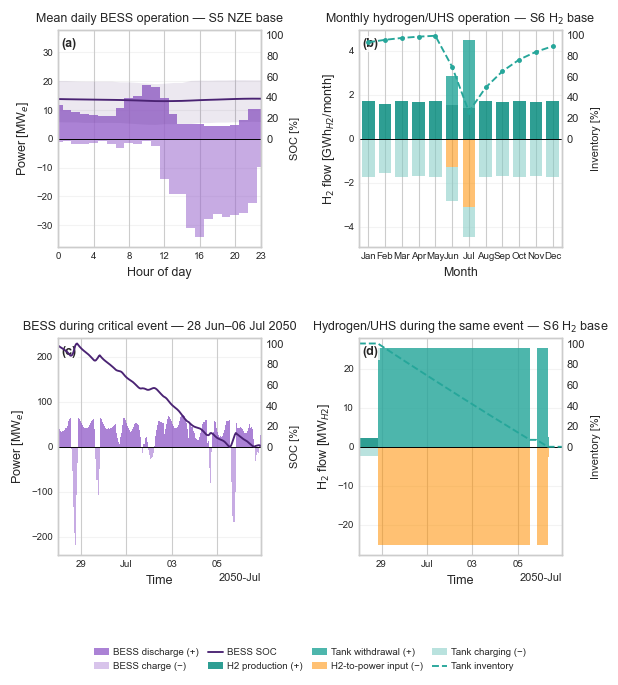

BESS: 750.00 MW / 6000.00 MWh
H2 storage: tank=4.581 GWh_H2; UHS=0.000 GWh_H2


In [46]:
# Multiscale BESS and hydrogen/UHS operation panel

# ── Configuration ─────────────────────────────────────────────────────────────
operation_year = detailed_year

BESS_SCENARIO = "RE_base"
H2_SCENARIO = "RH_base"

# Internal RH_base corresponds to the visible H₂ scenario.
n_bess = scenario_results[BESS_SCENARIO]["results"][operation_year]["network"]
n_h2 = scenario_results[H2_SCENARIO]["results"][operation_year]["network"]

event_start = pd.Timestamp(critical_event_start)
event_end = pd.Timestamp(critical_event_end)

if event_start.tz is not None:
    event_start = event_start.tz_localize(None)
if event_end.tz is not None:
    event_end = event_end.tz_localize(None)
tech_colors = globals().get("TECH_COLORS", {})
small_font = globals().get("FONT_SIZE_SMALL", 8)
figure_width = globals().get("WORD_DOUBLE_COL_IN", 7.2)

colors = {
    "BESS discharge": tech_colors.get("bess", "#8e5cc7"),
    "BESS charge": tech_colors.get("bess", "#8e5cc7"),
    "BESS SOC": "#4a2373",
    "H2 production": tech_colors.get("electrolyzer", "#00897b"),
    "Tank withdrawal": tech_colors.get("hydrogen_storage", "#26a69a"),
    "UHS withdrawal": tech_colors.get("uhs_withdrawal", "#3949ab"),
    "H2-to-power input": tech_colors.get("h2_fuel_cell", "#ff8f00"),
    "Tank charging": "#80cbc4",
    "UHS injection": tech_colors.get("uhs_injection", "#64b5f6"),
    "Tank inventory": tech_colors.get("hydrogen_storage", "#00897b"),
    "UHS inventory": tech_colors.get("uhs_storage", "#8e24aa"),
}

# ── Extraction helpers ────────────────────────────────────────────────────────
def _normalise(values):
    out = values.copy()
    out.index = pd.DatetimeIndex(pd.to_datetime(out.index))
    if out.index.tz is not None:
        out.index = out.index.tz_localize(None)
    return out.sort_index()


def _zero(net):
    return _normalise(pd.Series(0.0, index=net.snapshots))


def _link_flow(
    net,
    carriers,
    port,
):
    """
    Return positive link input at p0 or useful output at p1 [MW].
    """
    links = net.links.index[net.links['carrier'].astype(str).isin(carriers)]
    if len(links) == 0:
        return _zero(net)
    values = getattr(
        net.links_t,
        port,
    ).reindex(
        index=net.snapshots,
        columns=links,
        fill_value=0.0,
    )

    # PyPSA p1 is negative when energy leaves the link.
    if port == "p1":
        values = -values
    return _normalise(values.clip(lower=0.0).sum(axis=1))


def _effective_capacity(
    table,
    index,
    optimised_column,
    fixed_column,
):
    fixed = pd.to_numeric(table.loc[index, fixed_column], errors='coerce').fillna(0.0)
    if optimised_column not in table.columns:
        return fixed
    optimised = pd.to_numeric(table.loc[index, optimised_column], errors='coerce')
    return optimised.fillna(fixed)


def _store_data(
    net,
    carrier,
):
    """
    Return discharge, charging, inventory percentage, and capacity.

    Store p > 0: discharge.
    Store p < 0: charging.
    """
    stores = net.stores.index[net.stores['carrier'].astype(str) == carrier]
    if len(stores) == 0:
        zero = _zero(net)
        return (zero, zero.copy(), zero * np.nan, 0.0)
    power = net.stores_t.p.reindex(index=net.snapshots, columns=stores, fill_value=0.0)
    inventory = (
        net.stores_t.e
        .reindex(
            index=net.snapshots,
            columns=stores,
            fill_value=0.0,
        )
        .sum(axis=1)
    )
    energy_capacity = _effective_capacity(
        net.stores,
        stores,
        "e_nom_opt",
        "e_nom",
    ).sum()
    discharge = power.clip(lower=0.0).sum(axis=1)
    charging = -power.clip(upper=0.0).sum(axis=1)
    if energy_capacity > 0.0:
        inventory_pct = 100.0 * inventory / energy_capacity
    else:
        inventory_pct = inventory * np.nan
    return (
        _normalise(discharge),
        _normalise(charging),
        _normalise(inventory_pct),
        float(energy_capacity),
    )


# ── BESS operation ────────────────────────────────────────────────────────────
bess_carrier = n_bess.storage_units['carrier'].astype(str).str.lower()

bess_units = n_bess.storage_units.index[
    bess_carrier.str.contains(
        r"bess|battery",
        regex=True,
    )
]

# Compatibility with older networks using a generic carrier.
if len(bess_units) == 0:
    bess_units = n_bess.storage_units.index
if len(bess_units) == 0:
    raise ValueError(
        f"No BESS StorageUnits found in "
        f"{BESS_SCENARIO}, {operation_year}."
    )
bess_power_by_unit = (
    n_bess.storage_units_t.p
    .reindex(
        index=n_bess.snapshots,
        columns=bess_units,
        fill_value=0.0,
    )
)

bess_soc_mwh = (
    n_bess.storage_units_t.state_of_charge
    .reindex(
        index=n_bess.snapshots,
        columns=bess_units,
        fill_value=0.0,
    )
    .sum(axis=1)
)

bess_p_nom = _effective_capacity(n_bess.storage_units, bess_units, 'p_nom_opt', 'p_nom')

bess_max_hours = pd.to_numeric(
    n_bess.storage_units.loc[
        bess_units,
        "max_hours",
    ],
    errors="coerce",
).fillna(0.0)

bess_energy_mwh = float((bess_p_nom * bess_max_hours).sum())

if bess_energy_mwh <= 0.0:
    raise ValueError(
        f"{BESS_SCENARIO} has no installed BESS energy capacity "
        f"in {operation_year}."
    )

# Separate charging and discharging before aggregation.
bess_flow = _normalise(
    pd.DataFrame(
        {
            "BESS discharge": (
                bess_power_by_unit
                .clip(lower=0.0)
                .sum(axis=1)
            ),
            "BESS charge": (
                bess_power_by_unit
                .clip(upper=0.0)
                .sum(axis=1)
            ),
        }
    )
)

bess_soc = _normalise(100.0 * bess_soc_mwh / bess_energy_mwh)

# ── Hydrogen/UHS operation ────────────────────────────────────────────────────
(
    tank_withdrawal,
    tank_charging,
    tank_inventory,
    tank_capacity_mwh,
) = _store_data(
    n_h2,
    "hydrogen_storage",
)

_, _, uhs_inventory, uhs_capacity_mwh = _store_data(n_h2, 'uhs_storage')

# All flows are expressed on the H2-energy side:
# sources positive; storage/reconversion uses negative.
h2_flow = _normalise(
    pd.DataFrame(
        {
            "H2 production": _link_flow(
                n_h2,
                [
                    "electrolyzer",
                    "electrolyser",
                ],
                "p1",
            ),
            "Tank withdrawal": tank_withdrawal,
            "UHS withdrawal": _link_flow(
                n_h2,
                ["uhs_withdrawal"],
                "p1",
            ),
            "H2-to-power input": -(
                _link_flow(
                    n_h2,
                    ["h2_fuel_cell"],
                    "p0",
                )
                + _link_flow(
                    n_h2,
                    ["h2_turbine"],
                    "p0",
                )
            ),
            "Tank charging": -tank_charging,
            "UHS injection": -_link_flow(
                n_h2,
                ["uhs_injection"],
                "p0",
            ),
        }
    ).fillna(0.0)
)

h2_inventory = _normalise(
    pd.DataFrame(
        {
            "Tank inventory": tank_inventory,
            "UHS inventory": uhs_inventory,
        }
    )
)

if h2_flow.abs().sum().sum() <= 1e-6:
    raise ValueError(
        f"{H2_SCENARIO} has no H2/UHS operation in "
        f"{operation_year}. Select another scenario or verify "
        "that hydrogen capacity was actually built."
    )

# ── Mean daily BESS profile ───────────────────────────────────────────────────
bess_daily = bess_flow.copy()
bess_daily["SOC"] = bess_soc
bess_daily['hour'] = bess_daily.index.hour + bess_daily.index.minute / 60.0

bess_mean = bess_daily.groupby('hour').mean()

bess_soc_q25 = bess_daily.groupby('hour')['SOC'].quantile(0.25)

bess_soc_q75 = bess_daily.groupby('hour')['SOC'].quantile(0.75)

# ── Monthly hydrogen flows ────────────────────────────────────────────────────
snapshot_duration = h2_flow.index.to_series().shift(-1) - h2_flow.index.to_series()

typical_duration = snapshot_duration.dropna().median()

if pd.isna(typical_duration):
    typical_duration = pd.Timedelta(hours=1)
snapshot_duration.iloc[-1] = typical_duration

snapshot_hours = snapshot_duration.dt.total_seconds() / 3600.0

h2_monthly = (
    h2_flow
    .mul(
        snapshot_hours,
        axis=0,
    )
    .groupby(
        h2_flow.index.month
    )
    .sum()
    .reindex(
        range(1, 13),
        fill_value=0.0,
    )
    / 1e3
)

h2_inventory_monthly = (
    h2_inventory
    .groupby(
        h2_inventory.index.month
    )
    .last()
    .reindex(range(1, 13))
    .ffill()
)

# ── Critical-event data ───────────────────────────────────────────────────────
bess_event_mask = (bess_flow.index >= event_start) & (bess_flow.index <= event_end)

h2_event_mask = (h2_flow.index >= event_start) & (h2_flow.index <= event_end)

bess_event = bess_flow.loc[bess_event_mask]

bess_soc_event = bess_soc.loc[bess_event_mask]

h2_event = h2_flow.loc[h2_event_mask]

h2_inventory_event = h2_inventory.loc[h2_event_mask]

if bess_event.empty or h2_event.empty:
    raise ValueError('The critical-event dates do not overlap the selected networks.')

# ── Plot helpers ──────────────────────────────────────────────────────────────
def _stack_signed(
    ax,
    frame,
    bars=False,
):
    """
    Stack positive and negative flows independently.

    Positive: production, discharge, withdrawal.
    Negative: charging, injection, reconversion input.
    """
    x = np.arange(1, 13) if bars else frame.index
    positive_bottom = np.zeros(len(frame))
    negative_bottom = np.zeros(len(frame))
    for column in frame.columns:
        raw = frame[column].fillna(0.0).to_numpy()
        positive = raw.sum() >= 0.0
        values = np.clip(raw if positive else -raw, 0.0, None)
        if values.sum() <= 1e-9:
            continue
        bottom = positive_bottom if positive else negative_bottom
        alpha = 0.82 if positive else 0.55
        if bars:
            ax.bar(
                x,
                values if positive else -values,
                bottom=(
                    bottom
                    if positive
                    else -bottom
                ),
                width=0.76,
                color=colors[column],
                alpha=alpha,
                linewidth=0.0,
            )
        else:
            ax.fill_between(
                x,
                (
                    bottom
                    if positive
                    else -bottom
                ),
                (
                    bottom + values
                    if positive
                    else -(bottom + values)
                ),
                step="mid",
                color=colors[column],
                alpha=alpha,
                linewidth=0.0,
            )
        if positive:
            positive_bottom += values
        else:
            negative_bottom += values

    # Symmetric primary axis: zero remains at the vertical centre.
    limit = max(positive_bottom.max(), negative_bottom.max(), 1e-06)
    ax.set_ylim(-1.1 * limit, 1.1 * limit)


def _format_percentage_axis(
    ax,
    ylabel,
):
    """
    Align 0% with 0 on the symmetric primary axis.

    The negative half is retained internally for alignment but
    negative percentage ticks are not displayed.
    """
    ax.set_ylim(-105.0, 105.0)
    ax.set_yticks([0, 20, 40, 60, 80, 100])
    ax.set_ylabel(ylabel, fontsize=small_font)
    ax.grid(False)


def _plot_inventory(
    ax,
    inventory,
    x=None,
):
    active = []
    for column, linestyle in [
        ("Tank inventory", "--"),
        ("UHS inventory", "-"),
    ]:
        if inventory[column].notna().sum() == 0:
            continue
        xx = inventory.index if x is None else x
        ax.plot(
            xx,
            inventory[column],
            color=colors[column],
            linestyle=linestyle,
            linewidth=1.35,
            marker=(
                "o"
                if x is not None
                else None
            ),
            markersize=2.5,
        )
        active.append(column)
    _format_percentage_axis(ax, 'Inventory [%]')
    return active


def _scenario_label(code):
    if callable(
        globals().get("scenario_label")
    ):
        return scenario_label(code)
    return code.replace('_base', '')


def _add_panel_label(
    ax,
    text,
):
    if callable(
        globals().get("panel_label")
    ):
        panel_label(ax, text)
    else:
        ax.text(
            0.01,
            0.98,
            text,
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontweight="bold",
        )


# ── Figure ────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(figure_width, 7.0))

ax_a, ax_b, ax_c, ax_d = axes.ravel()

# (a) Mean daily BESS operation
_stack_signed(ax_a, bess_mean[['BESS discharge', 'BESS charge']])

ax_a_soc = ax_a.twinx()

ax_a_soc.fill_between(
    bess_mean.index,
    bess_soc_q25,
    bess_soc_q75,
    color=colors["BESS SOC"],
    alpha=0.10,
    linewidth=0.0,
)

ax_a_soc.plot(
    bess_mean.index,
    bess_mean["SOC"],
    color=colors["BESS SOC"],
    linewidth=1.35,
)

_format_percentage_axis(ax_a_soc, 'SOC [%]')

ax_a.set_xlim(0.0, 23.0)

ax_a.set_xticks([0, 4, 8, 12, 16, 20, 23])

ax_a.set_xlabel('Hour of day')

ax_a.set_ylabel('Power [MW$_e$]')

ax_a.set_title(
    (
        "Mean daily BESS operation — "
        f"{_scenario_label(BESS_SCENARIO)}"
    ),
    fontsize=small_font + 1,
)

_add_panel_label(ax_a, '(a)')

# (b) Monthly hydrogen/UHS operation
_stack_signed(ax_b, h2_monthly, bars=True)

ax_b_inventory = ax_b.twinx()

active_inventory = _plot_inventory(
    ax_b_inventory,
    h2_inventory_monthly,
    x=np.arange(1, 13),
)

ax_b.set_xticks(
    np.arange(1, 13),
    [
        "Jan", "Feb", "Mar",
        "Apr", "May", "Jun",
        "Jul", "Aug", "Sep",
        "Oct", "Nov", "Dec",
    ],
)

ax_b.set_xlim(0.45, 12.55)

ax_b.set_xlabel('Month')

ax_b.set_ylabel('H$_2$ flow [GWh$_{H2}$/month]')

ax_b.set_title(
    (
        "Monthly hydrogen/UHS operation — "
        f"{_scenario_label(H2_SCENARIO)}"
    ),
    fontsize=small_font + 1,
)

_add_panel_label(ax_b, '(b)')

# (c) BESS during the critical event
_stack_signed(ax_c, bess_event)

ax_c_soc = ax_c.twinx()

ax_c_soc.plot(
    bess_soc_event.index,
    bess_soc_event,
    color=colors["BESS SOC"],
    linewidth=1.35,
)

_format_percentage_axis(ax_c_soc, 'SOC [%]')

ax_c.set_xlabel('Time')

ax_c.set_ylabel('Power [MW$_e$]')

ax_c.set_title(
    (
        "BESS during critical event — "
        f"{event_start:%d %b}–{event_end:%d %b %Y}"
    ),
    fontsize=small_font + 1,
)

_add_panel_label(ax_c, '(c)')

# (d) Hydrogen/UHS during the same critical event
_stack_signed(ax_d, h2_event)

ax_d_inventory = ax_d.twinx()

_plot_inventory(ax_d_inventory, h2_inventory_event)

ax_d.set_xlabel('Time')

ax_d.set_ylabel('H$_2$ flow [MW$_{H2}$]')

ax_d.set_title(
    (
        "Hydrogen/UHS during the same event — "
        f"{_scenario_label(H2_SCENARIO)}"
    ),
    fontsize=small_font + 1,
)

_add_panel_label(ax_d, '(d)')

# Shared axis formatting
for ax in axes.ravel():
    ax.axhline(0.0, color='black', linewidth=0.7)
    ax.grid(axis='y', alpha=0.22)
    ax.set_axisbelow(True)
    ax.tick_params(labelsize=small_font - 1)
    ax.margins(x=0.0)

# Critical-event date formatting
for ax in [
    ax_c,
    ax_d,
]:
    locator = mdates.AutoDateLocator(minticks=4, maxticks=7)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

# ── Shared legend ─────────────────────────────────────────────────────────────
legend_handles = [
    Patch(
        facecolor=colors["BESS discharge"],
        edgecolor="none",
        alpha=0.82,
        label="BESS discharge (+)",
    ),
    Patch(
        facecolor=colors["BESS charge"],
        edgecolor="none",
        alpha=0.38,
        label="BESS charge (−)",
    ),
    Line2D(
        [0],
        [0],
        color=colors["BESS SOC"],
        linewidth=1.35,
        label="BESS SOC",
    ),
]

for column in h2_flow.columns:
    if h2_flow[column].abs().sum() <= 1e-6:
        continue
    positive = h2_flow[column].sum() >= 0.0
    legend_handles.append(
        Patch(
            facecolor=colors[column],
            edgecolor="none",
            alpha=(
                0.82
                if positive
                else 0.55
            ),
            label=(
                f"{column} "
                f"({'+' if positive else '−'})"
            ),
        )
    )
for column, linestyle in [
    ("Tank inventory", "--"),
    ("UHS inventory", "-"),
]:
    if column not in active_inventory:
        continue
    legend_handles.append(
        Line2D(
            [0],
            [0],
            color=colors[column],
            linestyle=linestyle,
            linewidth=1.35,
            label=column,
        )
    )
fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(
        0.5,
        0.012,
    ),
    ncol=4,
    frameon=False,
    fontsize=small_font - 1,
    columnspacing=1.0,
    handlelength=1.5,
    handletextpad=0.4,
)

fig.subplots_adjust(
    top=0.94,
    bottom=0.19,
    left=0.10,
    right=0.90,
    hspace=0.42,
    wspace=0.48,
)

# ── Export ────────────────────────────────────────────────────────────────────
if callable(
    globals().get("save_paper_figure")
):
    figure_path = save_paper_figure(
        fig,
        (
            "figure_storage_operation_multiscale_"
            f"{operation_year}.png"
        ),
    )
    print(f'Saved figure to: {figure_path}')
plt.show()

print(f'BESS: {bess_p_nom.sum():.2f} MW / {bess_energy_mwh:.2f} MWh')

print(
    f"H2 storage: tank={tank_capacity_mwh / 1e3:.3f} GWh_H2; "
    f"UHS={uhs_capacity_mwh / 1e3:.3f} GWh_H2"
)


RT0_base: Installed BESS energy capacity is zero.
Saved figure: output\output_punta_arenas\figures\figure_bess_summer_and_critical_event_2050.png
Saved figure to: output\output_punta_arenas\figures\figure_bess_summer_and_critical_event_2050.png


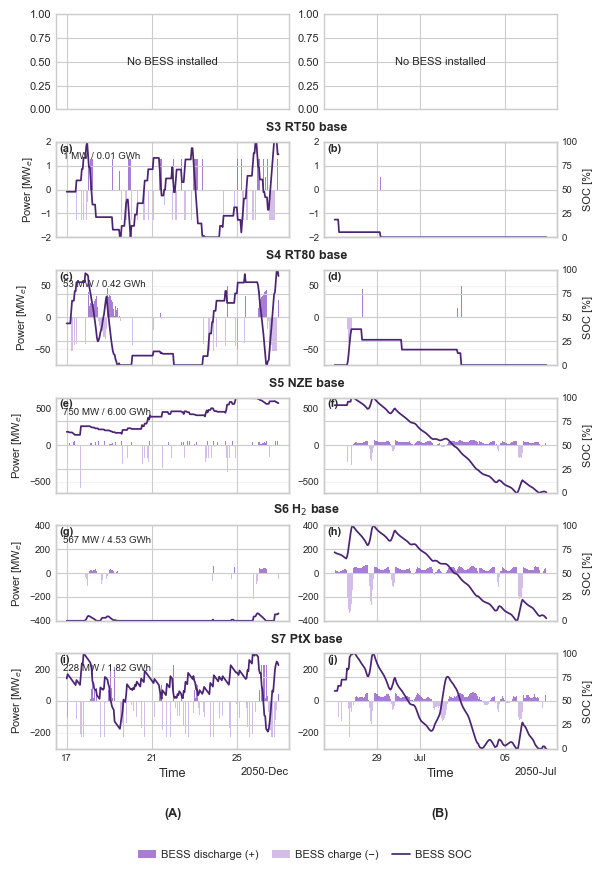

(A) Favourable summer period: 17 Dec 2050 00:00 to 26 Dec 2050 23:00
(B) Critical-event period: 27 Jun 2050 00:00 to 06 Jul 2050 23:00
Note: panel (B) begins one day before the identified critical event to show the incoming BESS SOC.


In [47]:
# BESS operation across scenarios:
# 10-day favourable summer period versus critical-event period

# ── Configuration ─────────────────────────────────────────────────────────────
operation_year = detailed_year

BESS_SCENARIOS = ['RT0_base', 'RT_base', 'RT80_base', 'RE_base', 'RH_base', 'PTX_base']

# Ten-day favourable summer period.
summer_plot_start = pd.Timestamp(f"{operation_year}-12-17 00:00")
summer_plot_end = pd.Timestamp(f"{operation_year}-12-26 23:00")

# The identified event spans approximately nine days.
# Add one preceding day to show how each BESS enters the event.
event_plot_start = pd.Timestamp(critical_event_start) - pd.Timedelta(days=1)
event_plot_end = pd.Timestamp(critical_event_end)

for timestamp_name in [
    "summer_plot_start",
    "summer_plot_end",
    "event_plot_start",
    "event_plot_end",
]:
    timestamp = locals()[timestamp_name]
    if timestamp.tz is not None:
        locals()[timestamp_name] = timestamp.tz_localize(None)
tech_colors = globals().get("TECH_COLORS", {})
small_font = globals().get("FONT_SIZE_SMALL", 8)
figure_width = globals().get("WORD_DOUBLE_COL_IN", 7.2)

bess_color = tech_colors.get("bess", "#9c6ade")
soc_color = "#4a2373"

# ── Helpers ───────────────────────────────────────────────────────────────────
def _normalise_index(series_or_frame):
    output = series_or_frame.copy()
    output.index = pd.DatetimeIndex(pd.to_datetime(output.index))
    if output.index.tz is not None:
        output.index = output.index.tz_localize(None)
    return output.sort_index()


def _effective_capacity(
    table,
    index,
    optimised_column,
    fixed_column,
):
    fixed = pd.to_numeric(table.loc[index, fixed_column], errors='coerce').fillna(0.0)
    if optimised_column not in table.columns:
        return fixed
    optimised = pd.to_numeric(table.loc[index, optimised_column], errors='coerce')
    return optimised.fillna(fixed)


def _scenario_label(code):
    if callable(globals().get("scenario_label")):
        return scenario_label(code)
    return code.replace("_base", "").replace("_", " ")


def extract_bess_operation(network):
    carrier = network.storage_units['carrier'].astype(str).str.lower()
    units = network.storage_units.index[
        carrier.str.contains(
            r"bess|battery",
            regex=True,
        )
    ]

    # Compatibility with older networks using a generic storage carrier.
    if len(units) == 0:
        units = network.storage_units.index
    if len(units) == 0:
        raise ValueError("No BESS StorageUnits were found.")
    power_by_unit = (
        network.storage_units_t.p
        .reindex(
            index=network.snapshots,
            columns=units,
            fill_value=0.0,
        )
    )
    power = pd.DataFrame(
        {
            "BESS discharge": (
                power_by_unit
                .clip(lower=0.0)
                .sum(axis=1)
            ),
            "BESS charge": (
                power_by_unit
                .clip(upper=0.0)
                .sum(axis=1)
            ),
        }
    )
    soc_mwh = (
        network.storage_units_t.state_of_charge
        .reindex(
            index=network.snapshots,
            columns=units,
            fill_value=0.0,
        )
        .sum(axis=1)
    )
    p_nom = _effective_capacity(network.storage_units, units, 'p_nom_opt', 'p_nom')
    max_hours = pd.to_numeric(
        network.storage_units.loc[units, "max_hours"],
        errors="coerce",
    ).fillna(0.0)
    energy_capacity_mwh = float((p_nom * max_hours).sum())
    if energy_capacity_mwh <= 0.0:
        raise ValueError('Installed BESS energy capacity is zero.')
    soc_pct = 100.0 * soc_mwh / energy_capacity_mwh
    return (
        _normalise_index(power),
        _normalise_index(soc_pct),
        float(p_nom.sum()),
        energy_capacity_mwh,
    )


def select_period(
    frame,
    start,
    end,
):
    return frame.loc[(frame.index >= start) & (frame.index <= end)]


def scenario_power_limit(
    power,
    periods,
):
    """
    Return one symmetric power limit for both columns of a scenario.

    Limits differ between scenarios, preventing the small RT BESS
    from being compressed by the much larger NZE/H₂/PtX systems.
    """
    maximum = 0.0
    for start, end in periods:
        selected = select_period(power, start, end)
        if selected.empty:
            continue
        maximum = max(
            maximum,
            float(
                selected["BESS discharge"].max()
            ),
            float(
                abs(
                    selected["BESS charge"].min()
                )
            ),
        )
    maximum = max(maximum, 1e-3)

    # Round the limit upwards to a readable value.
    raw_limit = 1.10 * maximum
    if raw_limit <= 10:
        step = 2
    elif raw_limit <= 50:
        step = 10
    elif raw_limit <= 150:
        step = 25
    else:
        step = 50
    return np.ceil(raw_limit / step) * step


def plot_bess_period(
    ax,
    power,
    soc,
    start,
    end,
    power_limit,
    show_left_ylabel=False,
    show_right_ylabel=False,
):
    period_power = select_period(power, start, end)
    period_soc = select_period(soc, start, end)
    if period_power.empty:
        raise ValueError(f'No BESS data available between {start} and {end}.')
    ax.fill_between(
        period_power.index,
        0.0,
        period_power["BESS discharge"],
        step="mid",
        color=bess_color,
        alpha=0.85,
        linewidth=0.0,
    )
    ax.fill_between(
        period_power.index,
        0.0,
        period_power["BESS charge"],
        step="mid",
        color=bess_color,
        alpha=0.42,
        linewidth=0.0,
    )
    ax.axhline(0.0, color='black', linewidth=0.7)
    ax.set_ylim(-power_limit, power_limit)
    if show_left_ylabel:
        ax.set_ylabel('Power [MW$_e$]', fontsize=small_font)
    else:
        ax.set_ylabel("")
    ax_soc = ax.twinx()
    ax_soc.plot(period_soc.index, period_soc, color=soc_color, linewidth=1.25)
    ax_soc.set_ylim(0.0, 100.0)
    ax_soc.set_yticks([0, 25, 50, 75, 100])
    if show_right_ylabel:
        ax_soc.set_ylabel('SOC [%]', fontsize=small_font)
    else:
        ax_soc.set_ylabel("")
        ax_soc.tick_params(labelright=False)
    ax.grid(axis='y', alpha=0.22)
    ax.set_axisbelow(True)
    ax.margins(x=0.0)
    locator = mdates.AutoDateLocator(minticks=3, maxticks=5)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    ax.tick_params(labelsize=small_font - 1)
    ax_soc.tick_params(labelsize=small_font - 1)
    return ax_soc


# ── Extract scenarios ─────────────────────────────────────────────────────────
bess_results = {}

for scenario in BESS_SCENARIOS:
    network = scenario_results[scenario]['results'][operation_year]['network']
    try:
        bess_results[scenario] = extract_bess_operation(network)
    except ValueError as error:
        print(f'{scenario}: {error}')
        bess_results[scenario] = None

# ── Figure ────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(
    len(BESS_SCENARIOS),
    2,
    figsize=(
        figure_width,
        max(7.6, 1.55 * len(BESS_SCENARIOS)),
    ),
    sharex="col",
    sharey=False,
)

subplot_letters = list("abcdefghijklmnopqrstuvwxyz")
letter_index = 0

scenario_row_axes = []

for row, scenario in enumerate(BESS_SCENARIOS):
    result = bess_results[scenario]
    if result is None:
        for column in range(2):
            axes[row, column].text(
                0.5,
                0.5,
                "No BESS installed",
                transform=axes[row, column].transAxes,
                ha="center",
                va="center",
                fontsize=small_font,
            )
        continue
    power, soc, power_capacity, energy_capacity = result
    power_limit = scenario_power_limit(
        power,
        [
            (
                summer_plot_start,
                summer_plot_end,
            ),
            (
                event_plot_start,
                event_plot_end,
            ),
        ],
    )
    plot_bess_period(
        axes[row, 0],
        power,
        soc,
        summer_plot_start,
        summer_plot_end,
        power_limit=power_limit,
        show_left_ylabel=True,
        show_right_ylabel=False,
    )
    plot_bess_period(
        axes[row, 1],
        power,
        soc,
        event_plot_start,
        event_plot_end,
        power_limit=power_limit,
        show_left_ylabel=False,
        show_right_ylabel=True,
    )

    # Installed capacity annotation.
    axes[row, 0].text(
        0.03,
        0.89,
        (
            f"{power_capacity:.0f} MW / "
            f"{energy_capacity / 1e3:.2f} GWh"
        ),
        transform=axes[row, 0].transAxes,
        ha="left",
        va="top",
        fontsize=small_font - 1,
    )

    # Individual subplot labels: (a)–(h).
    for column in range(2):
        axes[row, column].text(
            0.015,
            0.98,
            f"({subplot_letters[letter_index]})",
            transform=axes[row, column].transAxes,
            ha="left",
            va="top",
            fontsize=small_font,
            fontweight="bold",
        )
        letter_index += 1
    scenario_row_axes.append((axes[row, 0], axes[row, 1], _scenario_label(scenario)))
axes[-1, 0].set_xlabel('Time')

axes[-1, 1].set_xlabel('Time')

# ── Layout before figure-coordinate labels ────────────────────────────────────
fig.subplots_adjust(
    top=0.965,
    bottom=0.175,
    left=0.105,
    right=0.90,
    hspace=0.34,
    wspace=0.15,
)

# Draw once so subplot positions are available.
fig.canvas.draw()

# Horizontal scenario labels above each row.
for left_ax, right_ax, label in scenario_row_axes:
    left_position = left_ax.get_position()
    right_position = right_ax.get_position()
    row_centre = (left_position.x0 + right_position.x1) / 2.0
    row_top = max(left_position.y1, right_position.y1)
    fig.text(
        row_centre,
        row_top + 0.008,
        label,
        ha="center",
        va="bottom",
        fontsize=small_font + 1,
        fontweight="bold",
    )

# ── Column labels below plots ─────────────────────────────────────────────────
left_position = axes[-1, 0].get_position()
right_position = axes[-1, 1].get_position()

fig.text(
    (
        left_position.x0
        + left_position.x1
    ) / 2.0,
    0.105,
    "(A)",
    ha="center",
    va="center",
    fontsize=small_font + 1,
    fontweight="bold",
)

fig.text(
    (
        right_position.x0
        + right_position.x1
    ) / 2.0,
    0.105,
    "(B)",
    ha="center",
    va="center",
    fontsize=small_font + 1,
    fontweight="bold",
)

# ── Shared legend ─────────────────────────────────────────────────────────────
legend_handles = [
    Patch(
        facecolor=bess_color,
        edgecolor="none",
        alpha=0.85,
        label="BESS discharge (+)",
    ),
    Patch(
        facecolor=bess_color,
        edgecolor="none",
        alpha=0.42,
        label="BESS charge (−)",
    ),
    Line2D(
        [0],
        [0],
        color=soc_color,
        linewidth=1.25,
        label="BESS SOC",
    ),
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(
        0.5,
        0.045,
    ),
    ncol=3,
    frameon=False,
    fontsize=small_font,
    columnspacing=1.2,
    handlelength=1.6,
    handletextpad=0.5,
)

# ── Export ────────────────────────────────────────────────────────────────────
if callable(
    globals().get("save_paper_figure")
):
    figure_path = save_paper_figure(
        fig,
        (
            "figure_bess_summer_and_critical_event_"
            f"{operation_year}.png"
        ),
    )
    print(f'Saved figure to: {figure_path}')
plt.show()

# ── Period information ────────────────────────────────────────────────────────
print(
    "(A) Favourable summer period: "
    f"{summer_plot_start:%d %b %Y %H:%M} to "
    f"{summer_plot_end:%d %b %Y %H:%M}"
)

print(
    "(B) Critical-event period: "
    f"{event_plot_start:%d %b %Y %H:%M} to "
    f"{event_plot_end:%d %b %Y %H:%M}"
)

print(
    "Note: panel (B) begins one day before the identified "
    "critical event to show the incoming BESS SOC."
)


Saved figure: output\output_punta_arenas\figures\figure_hydrogen_monthly_and_critical_event_2050.png
Saved figure to: output\output_punta_arenas\figures\figure_hydrogen_monthly_and_critical_event_2050.png


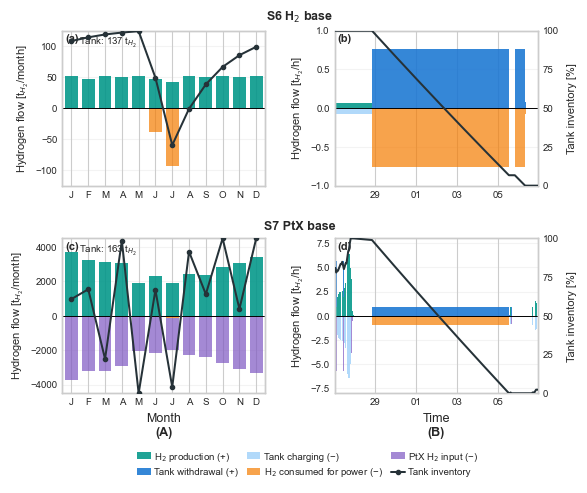

(A) Monthly hydrogen balance: January–December 2050.
(B) Critical-event period: 27 Jun 2050 00:00 to 06 Jul 2050 23:00.
Hydrogen-energy flows were converted to mass using an H2 LHV of 33.33 MWh/t.
'H2 consumed for power' represents the hydrogen input to fuel cells and turbines, not their electricity output.
Panel (B) begins one day before the identified critical event to show the incoming tank inventory.


In [48]:
# Hydrogen storage operation across RH and PtX:
# monthly H2 balance versus critical-event storage operation
# All hydrogen flows are expressed in tonnes of H2.

# ── Configuration ─────────────────────────────────────────────────────────────
operation_year = detailed_year

H2_SCENARIOS = ['RH_base', 'PTX_base']

# Same period used in the BESS figure:
# one day before the identified critical event until its end.
event_plot_start = pd.Timestamp(critical_event_start) - pd.Timedelta(days=1)

event_plot_end = pd.Timestamp(critical_event_end)

if event_plot_start.tz is not None:
    event_plot_start = event_plot_start.tz_localize(None)
if event_plot_end.tz is not None:
    event_plot_end = event_plot_end.tz_localize(None)
small_font = globals().get('FONT_SIZE_SMALL', 8)

figure_width = globals().get('WORD_DOUBLE_COL_IN', 7.2)

# Lower heating value used to convert hydrogen energy to mass.
H2_LHV_MWH_PER_T = 33.33

# Semantic colour families:
# green     = H2 production
# blue      = tank operation
# orange    = H2 consumed for electricity generation
# purple    = H2 consumed by PtX
# dark grey = tank inventory
colors = {
    "H2 production": "#009688",
    "Tank withdrawal": "#1976D2",
    "Tank charging": "#90CAF9",
    "H2 consumed for power": "#F57C00",
    "PtX H2 input": "#7E57C2",
    "Tank inventory": "#263238",
}

legend_labels = {
    "H2 production": r"H$_2$ production (+)",
    "Tank withdrawal": "Tank withdrawal (+)",
    "Tank charging": "Tank charging (−)",
    "H2 consumed for power": (
        r"H$_2$ consumed for power (−)"
    ),
    "PtX H2 input": (
        r"PtX H$_2$ input (−)"
    ),
    "Tank inventory": "Tank inventory",
}

# ── Helpers ───────────────────────────────────────────────────────────────────
def _normalise_index(series_or_frame):
    output = series_or_frame.copy()
    output.index = pd.DatetimeIndex(pd.to_datetime(output.index))
    if output.index.tz is not None:
        output.index = output.index.tz_localize(None)
    return output.sort_index()


def _zero_series(network):
    return _normalise_index(pd.Series(0.0, index=network.snapshots))


def _scenario_label(code):
    if callable(
        globals().get("scenario_label")
    ):
        return scenario_label(code)
    return code.replace('_base', '').replace('_', ' ')


def _effective_capacity(
    table,
    index,
    optimised_column,
    fixed_column,
):
    fixed = pd.to_numeric(table.loc[index, fixed_column], errors='coerce').fillna(0.0)
    if optimised_column not in table.columns:
        return fixed
    optimised = pd.to_numeric(table.loc[index, optimised_column], errors='coerce')
    return optimised.fillna(fixed)


def _link_flow(
    network,
    carriers,
    port,
):
    """
    Aggregate selected Link flows.

    p0:
        Positive energy input to the Link.

    p1:
        Converted to positive useful output from the Link.
    """
    links = network.links.index[network.links['carrier'].astype(str).isin(carriers)]
    if len(links) == 0:
        return _zero_series(network)
    values = getattr(
        network.links_t,
        port,
    ).reindex(
        index=network.snapshots,
        columns=links,
        fill_value=0.0,
    )

    # PyPSA p1 is negative when energy leaves the Link.
    if port == "p1":
        values = -values
    return _normalise_index(values.clip(lower=0.0).sum(axis=1))


def extract_tank_operation(network):
    """
    Extract surface H2-tank operation.

    The original time series are returned in MW_H2.

    Positive:
    - H2 production
    - tank withdrawal

    Negative:
    - tank charging
    - H2 consumed by fuel cells/turbines
    - H2 consumed by PtX synthesis
    """
    tank_stores = network.stores.index[
        network.stores["carrier"]
        .astype(str)
        .eq("hydrogen_storage")
    ]
    if len(tank_stores) == 0:
        raise ValueError('No surface hydrogen-storage Store was found.')
    tank_power = (
        network.stores_t.p
        .reindex(
            index=network.snapshots,
            columns=tank_stores,
            fill_value=0.0,
        )
    )
    tank_inventory_mwh = (
        network.stores_t.e
        .reindex(
            index=network.snapshots,
            columns=tank_stores,
            fill_value=0.0,
        )
        .sum(axis=1)
    )
    tank_capacity_mwh = float(
        _effective_capacity(
            network.stores,
            tank_stores,
            "e_nom_opt",
            "e_nom",
        ).sum()
    )
    if tank_capacity_mwh <= 0.0:
        raise ValueError('Hydrogen tank energy capacity is zero.')
    tank_withdrawal = tank_power.clip(lower=0.0).sum(axis=1)
    tank_charging = -tank_power.clip(upper=0.0).sum(axis=1)
    h2_production = _link_flow(network, ['electrolyzer', 'electrolyser'], 'p1')

    # Hydrogen-energy input to fuel cells/turbines,
    # not their electricity output.
    h2_consumed_for_power = (
        _link_flow(
            network,
            ["h2_fuel_cell"],
            "p0",
        )
        + _link_flow(
            network,
            ["h2_turbine"],
            "p0",
        )
    )
    ptx_h2_input = _link_flow(
        network,
        [
            "methanol_synthesis",
            "ammonia_synthesis",
            "ptx_synthesis",
        ],
        "p0",
    )
    flows_mw_h2 = _normalise_index(
        pd.DataFrame(
            {
                "H2 production": h2_production,
                "Tank withdrawal": tank_withdrawal,
                "Tank charging": -tank_charging,
                "H2 consumed for power": (
                    -h2_consumed_for_power
                ),
                "PtX H2 input": -ptx_h2_input,
            }
        ).fillna(0.0)
    )
    inventory_pct = _normalise_index(100.0 * tank_inventory_mwh / tank_capacity_mwh)
    return (flows_mw_h2, inventory_pct, tank_capacity_mwh)


def _snapshot_hours(index):
    durations = index.to_series().shift(-1) - index.to_series()
    typical_duration = durations.dropna().median()
    if pd.isna(typical_duration):
        typical_duration = pd.Timedelta(hours=1)
    durations.iloc[-1] = typical_duration
    return durations.dt.total_seconds() / 3600.0


def monthly_hydrogen_mass(flow_mw_h2):
    """
    Convert MW_H2 time series to tonnes of H2 per month.

    MW_H2 × hours = MWh_H2
    MWh_H2 / (MWh_H2 per tonne) = tonnes H2
    """
    hours = _snapshot_hours(flow_mw_h2.index)
    monthly_mwh_h2 = (
        flow_mw_h2
        .mul(
            hours,
            axis=0,
        )
        .groupby(flow_mw_h2.index.month)
        .sum()
        .reindex(
            range(1, 13),
            fill_value=0.0,
        )
    )
    return monthly_mwh_h2 / H2_LHV_MWH_PER_T


def hourly_hydrogen_mass_flow(flow_mw_h2):
    """
    Convert MW_H2 to tonnes of H2 per hour.
    """
    return flow_mw_h2 / H2_LHV_MWH_PER_T


def monthly_inventory(inventory):
    """
    End-of-month tank inventory.
    """
    return inventory.groupby(inventory.index.month).last().reindex(range(1, 13)).ffill()


def _nice_symmetric_limit(
    positive_bottom,
    negative_bottom,
):
    maximum = max(float(positive_bottom.max()), float(negative_bottom.max()), 1e-06)
    raw_limit = 1.10 * maximum
    if raw_limit <= 2:
        step = 0.5
    elif raw_limit <= 10:
        step = 2
    elif raw_limit <= 50:
        step = 10
    elif raw_limit <= 150:
        step = 25
    elif raw_limit <= 500:
        step = 50
    elif raw_limit <= 1500:
        step = 250
    else:
        step = 500
    return np.ceil(raw_limit / step) * step


def _stack_signed(
    ax,
    frame,
    bars=False,
):
    """
    Stack positive and negative flows independently.
    """
    x = np.arange(1, 13) if bars else frame.index
    positive_bottom = np.zeros(len(frame))
    negative_bottom = np.zeros(len(frame))
    active_columns = []
    for column in frame.columns:
        raw = frame[column].fillna(0.0).to_numpy()
        if np.abs(raw).sum() <= 1e-9:
            continue
        active_columns.append(column)
        positive_values = np.clip(raw, 0.0, None)
        negative_values = np.clip(-raw, 0.0, None)
        if positive_values.sum() > 1e-9:
            if bars:
                ax.bar(
                    x,
                    positive_values,
                    bottom=positive_bottom,
                    width=0.76,
                    color=colors[column],
                    alpha=0.88,
                    linewidth=0.0,
                )
            else:
                ax.fill_between(
                    x,
                    positive_bottom,
                    (
                        positive_bottom
                        + positive_values
                    ),
                    step="mid",
                    color=colors[column],
                    alpha=0.88,
                    linewidth=0.0,
                )
            positive_bottom += positive_values
        if negative_values.sum() > 1e-9:
            if bars:
                ax.bar(
                    x,
                    -negative_values,
                    bottom=-negative_bottom,
                    width=0.76,
                    color=colors[column],
                    alpha=0.70,
                    linewidth=0.0,
                )
            else:
                ax.fill_between(
                    x,
                    -negative_bottom,
                    -(
                        negative_bottom
                        + negative_values
                    ),
                    step="mid",
                    color=colors[column],
                    alpha=0.70,
                    linewidth=0.0,
                )
            negative_bottom += negative_values
    limit = _nice_symmetric_limit(positive_bottom, negative_bottom)
    ax.set_ylim(-limit, limit)
    return active_columns


def _plot_inventory(
    ax,
    inventory,
    x=None,
    show_ticklabels=True,
    show_ylabel=False,
):
    xx = inventory.index if x is None else x
    ax.plot(
        xx,
        inventory,
        color=colors["Tank inventory"],
        linewidth=1.45,
        marker=(
            "o"
            if x is not None
            else None
        ),
        markersize=3.0,
        zorder=5,
    )
    ax.set_ylim(0.0, 100.0)
    ax.set_yticks([0, 25, 50, 75, 100])
    if show_ylabel:
        ax.set_ylabel('Tank inventory [%]', fontsize=small_font, labelpad=6)
    else:
        ax.set_ylabel("")
    if not show_ticklabels:
        ax.tick_params(labelright=False)
    ax.tick_params(labelsize=small_font - 1)
    ax.grid(False)


# ── Extract scenario data ─────────────────────────────────────────────────────
h2_results = {}

for scenario in H2_SCENARIOS:
    network = scenario_results[scenario]['results'][operation_year]['network']
    try:
        flows_mw_h2, inventory, capacity_mwh = extract_tank_operation(network)
        monthly_flows_t = monthly_hydrogen_mass(flows_mw_h2)

        # Monthly panel:
        # show production and final H2 uses.
        # Tank charging/withdrawal is represented by
        # the variation in tank inventory.
        monthly_balance_t = monthly_flows_t[
            [
                "H2 production",
                "H2 consumed for power",
                "PtX H2 input",
            ]
        ].copy()
        h2_results[scenario] = {
            "flows_mw_h2": flows_mw_h2,
            "inventory": inventory,
            "capacity_mwh": capacity_mwh,
            "capacity_t_h2": (
                capacity_mwh
                / H2_LHV_MWH_PER_T
            ),
            "monthly_balance_t": monthly_balance_t,
            "monthly_inventory": monthly_inventory(
                inventory
            ),
        }
    except ValueError as error:
        print(f'{scenario}: {error}')
        h2_results[scenario] = None

# ── Figure ────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(
    len(H2_SCENARIOS),
    2,
    figsize=(
        figure_width,
        4.9,
    ),
    sharex="col",
    sharey=False,
)

subplot_letters = list("abcd")
letter_index = 0

scenario_row_axes = []
active_legend_columns = []

for row, scenario in enumerate(H2_SCENARIOS):
    result = h2_results[scenario]
    if result is None:
        for column in range(2):
            axes[row, column].text(
                0.5,
                0.5,
                "No hydrogen storage installed",
                transform=(
                    axes[row, column]
                    .transAxes
                ),
                ha="center",
                va="center",
                fontsize=small_font,
            )
        continue
    monthly_balance_t = result['monthly_balance_t']
    monthly_inventory_pct = result['monthly_inventory']
    event_mask = (
        (
            result["flows_mw_h2"].index
            >= event_plot_start
        )
        & (
            result["flows_mw_h2"].index
            <= event_plot_end
        )
    )
    event_flows_t_per_h = (
        hourly_hydrogen_mass_flow(
            result["flows_mw_h2"]
            .loc[event_mask]
        )
    )
    event_inventory = result['inventory'].loc[event_mask]
    if event_flows_t_per_h.empty:
        raise ValueError(
            f"No H2 data available for {scenario} "
            "during the selected event period."
        )

    # ── Column A: monthly H2 balance ──────────────────────────────────────────
    active_monthly = _stack_signed(axes[row, 0], monthly_balance_t, bars=True)
    monthly_inventory_axis = axes[row, 0].twinx()
    _plot_inventory(
        monthly_inventory_axis,
        monthly_inventory_pct,
        x=np.arange(1, 13),
        show_ticklabels=False,
        show_ylabel=False,
    )
    axes[row, 0].set_xticks(
        np.arange(1, 13),
        [
            "J",
            "F",
            "M",
            "A",
            "M",
            "J",
            "J",
            "A",
            "S",
            "O",
            "N",
            "D",
        ],
    )
    axes[row, 0].set_xlim(0.45, 12.55)
    axes[row, 0].set_ylabel(
        r"Hydrogen flow "
        r"[t$_{H_2}$/month]",
        fontsize=small_font,
        labelpad=3,
    )

    # ── Column B: critical-event storage operation ───────────────────────────
    active_event = _stack_signed(axes[row, 1], event_flows_t_per_h, bars=False)
    event_inventory_axis = axes[row, 1].twinx()
    _plot_inventory(
        event_inventory_axis,
        event_inventory,
        show_ticklabels=True,
        show_ylabel=True,
    )
    axes[row, 1].set_ylabel(
        r"Hydrogen flow "
        r"[t$_{H_2}$/h]",
        fontsize=small_font,
        labelpad=3,
    )
    tick_start = event_plot_start.normalize() + pd.Timedelta(days=2)
    tick_end = event_plot_end.normalize()
    event_ticks = pd.date_range(tick_start, tick_end, freq='2D')
    axes[row, 1].set_xticks(event_ticks)
    axes[row, 1].xaxis.set_major_formatter(mdates.DateFormatter('%d'))

    # Tank-capacity annotation in tonnes of H2.
    axes[row, 0].text(
        0.085,
        0.965,
        (
            "Tank: "
            f"{result['capacity_t_h2']:.0f} "
            r"t$_{H_2}$"
        ),
        transform=axes[row, 0].transAxes,
        ha="left",
        va="top",
        fontsize=small_font - 1,
    )

    # Individual subplot labels.
    for column in range(2):
        axes[row, column].text(
            0.015,
            0.98,
            (
                f"("
                f"{subplot_letters[letter_index]}"
                f")"
            ),
            transform=(
                axes[row, column]
                .transAxes
            ),
            ha="left",
            va="top",
            fontsize=small_font,
            fontweight="bold",
        )
        letter_index += 1
    scenario_row_axes.append((axes[row, 0], axes[row, 1], _scenario_label(scenario)))
    for column in (
        active_monthly
        + active_event
    ):
        if column not in active_legend_columns:
            active_legend_columns.append(column)
axes[-1, 0].set_xlabel('Month')

axes[-1, 1].set_xlabel('Time')

# Show x-axis tick labels also on the top row.
if len(H2_SCENARIOS) > 1:
    axes[0, 0].tick_params(labelbottom=True)
    axes[0, 1].tick_params(labelbottom=True)

# ── Shared formatting ─────────────────────────────────────────────────────────
for ax in axes.ravel():
    ax.axhline(0.0, color='black', linewidth=0.7)
    ax.grid(axis='y', alpha=0.22)
    ax.set_axisbelow(True)
    ax.tick_params(labelsize=small_font - 1)
    ax.margins(x=0.0)

# Intermediate spacing: compact but not crowded.
fig.subplots_adjust(
    top=0.945,
    bottom=0.205,
    left=0.11,
    right=0.865,
    hspace=0.34,
    wspace=0.34,
)

fig.canvas.draw()

# ── Horizontal scenario labels ────────────────────────────────────────────────
for left_ax, right_ax, label in scenario_row_axes:
    left_position = left_ax.get_position()
    right_position = right_ax.get_position()
    row_centre = (left_position.x0 + right_position.x1) / 2.0
    row_top = max(left_position.y1, right_position.y1)
    fig.text(
        row_centre,
        row_top + 0.012,
        label,
        ha="center",
        va="bottom",
        fontsize=small_font + 1,
        fontweight="bold",
    )

# ── Column labels (A) and (B) ─────────────────────────────────────────────────
left_position = axes[-1, 0].get_position()
right_position = axes[-1, 1].get_position()

left_column_centre = (left_position.x0 + left_position.x1) / 2.0

right_column_centre = (right_position.x0 + right_position.x1) / 2.0

fig.text(
    left_column_centre,
    0.125,
    "(A)",
    ha="center",
    va="center",
    fontsize=small_font + 1,
    fontweight="bold",
)

fig.text(
    right_column_centre,
    0.125,
    "(B)",
    ha="center",
    va="center",
    fontsize=small_font + 1,
    fontweight="bold",
)

# ── Shared legend ─────────────────────────────────────────────────────────────
legend_handles = []

legend_order = [
    "H2 production",
    "Tank withdrawal",
    "Tank charging",
    "H2 consumed for power",
    "PtX H2 input",
]

for column in legend_order:
    if column not in active_legend_columns:
        continue
    positive = column in ['H2 production', 'Tank withdrawal']
    legend_handles.append(
        Patch(
            facecolor=colors[column],
            edgecolor="none",
            alpha=(
                0.88
                if positive
                else 0.70
            ),
            label=legend_labels[column],
        )
    )
legend_handles.append(
    Line2D(
        [0],
        [0],
        color=colors["Tank inventory"],
        linewidth=1.45,
        marker="o",
        markersize=3,
        label=legend_labels[
            "Tank inventory"
        ],
    )
)

fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(
        0.5,
        0.012,
    ),
    ncol=3,
    frameon=False,
    fontsize=small_font - 1,
    columnspacing=0.9,
    handlelength=1.4,
    handletextpad=0.35,
)

# ── Export ────────────────────────────────────────────────────────────────────
if callable(
    globals().get("save_paper_figure")
):
    figure_path = save_paper_figure(
        fig,
        (
            "figure_hydrogen_monthly_and_"
            f"critical_event_{operation_year}.png"
        ),
    )
    print(f'Saved figure to: {figure_path}')
plt.show()

# ── Period information ────────────────────────────────────────────────────────
print(f'(A) Monthly hydrogen balance: January–December {operation_year}.')

print(
    "(B) Critical-event period: "
    f"{event_plot_start:%d %b %Y %H:%M} to "
    f"{event_plot_end:%d %b %Y %H:%M}."
)

print(
    "Hydrogen-energy flows were converted to mass using "
    f"an H2 LHV of {H2_LHV_MWH_PER_T:.2f} MWh/t."
)

print(
    "'H2 consumed for power' represents the hydrogen input "
    "to fuel cells and turbines, not their electricity output."
)

print(
    "Panel (B) begins one day before the identified critical "
    "event to show the incoming tank inventory."
)


### 5.5 Operational stress-event windows

Detailed event-centred profiles around the largest unserved-electricity episodes. These are diagnostic/Supplementary outputs supporting the interpretation of Figure 7.


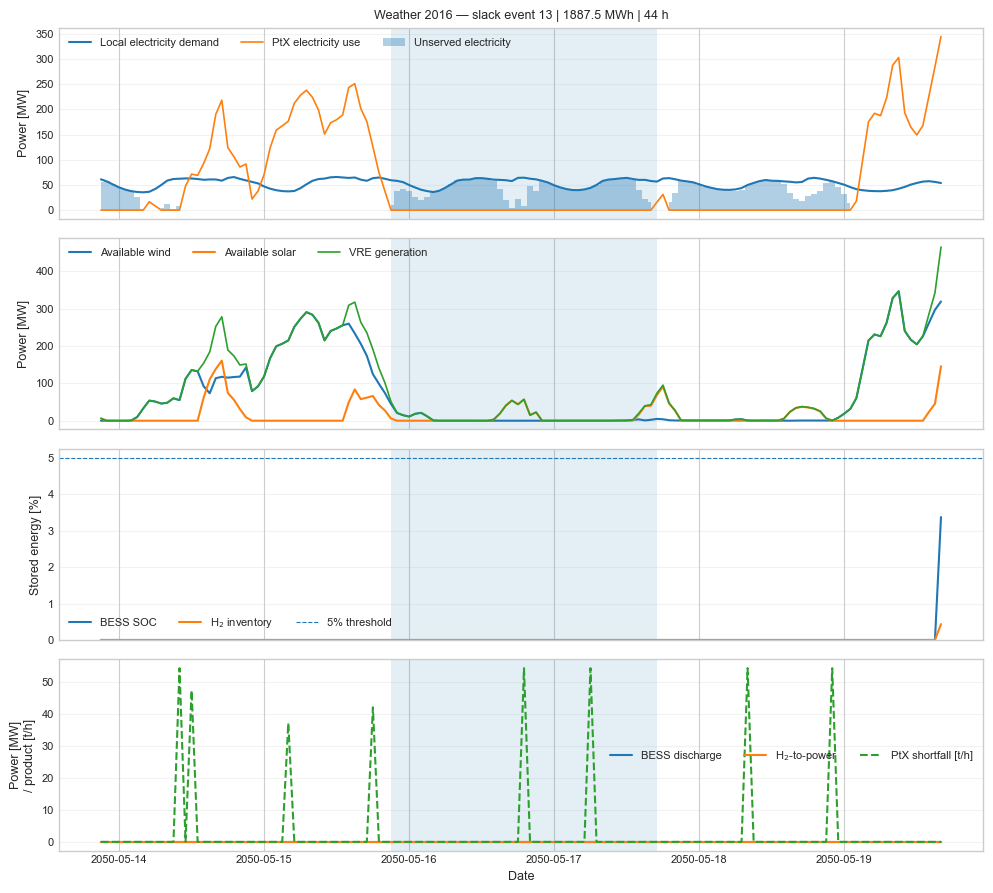

Weather 2016, event 13: 2050-05-15 21:00:00 → 2050-05-17 16:00:00
  Slack: 1887.5 MWh | peak 63.5 MW
  Night: 82.7% | peak-demand hours: 0.0%
  BESS SOC: 0.0% before → minimum 0.0%
  H₂ inventory: 0.0% before → minimum 0.0%
  PtX electricity during event: 0.0 MW average



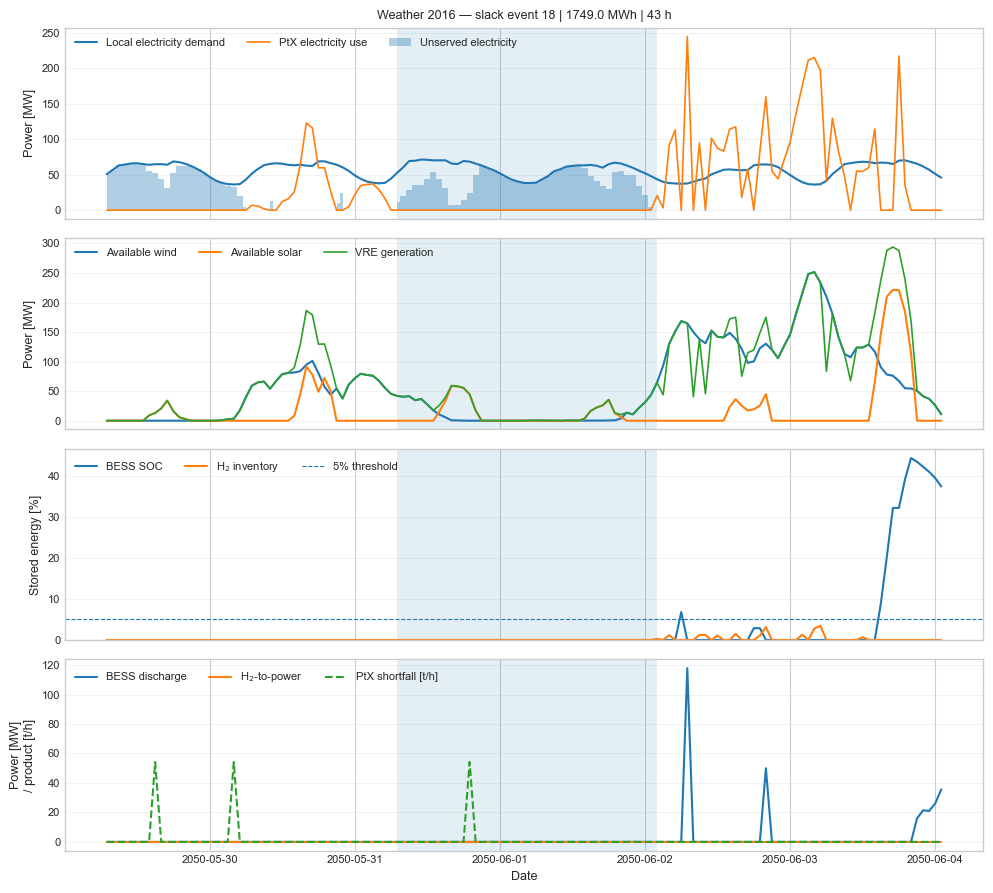

Weather 2016, event 18: 2050-05-31 07:00:00 → 2050-06-02 01:00:00
  Slack: 1749.0 MWh | peak 62.8 MW
  Night: 71.5% | peak-demand hours: 27.2%
  BESS SOC: 0.0% before → minimum 0.0%
  H₂ inventory: 0.0% before → minimum 0.0%
  PtX electricity during event: 0.0 MW average



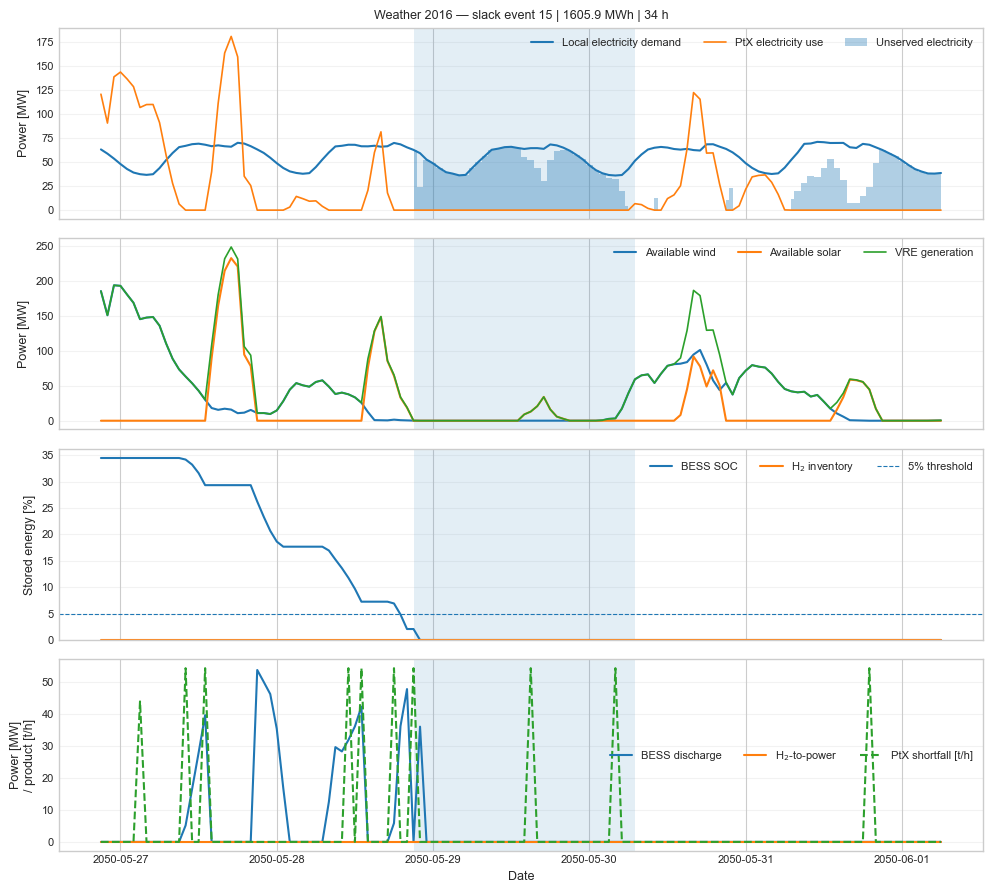

Weather 2016, event 15: 2050-05-28 21:00:00 → 2050-05-30 06:00:00
  Slack: 1605.9 MWh | peak 66.1 MW
  Night: 77.7% | peak-demand hours: 19.2%
  BESS SOC: 2.1% before → minimum 0.0%
  H₂ inventory: 0.0% before → minimum 0.0%
  PtX electricity during event: 0.0 MW average



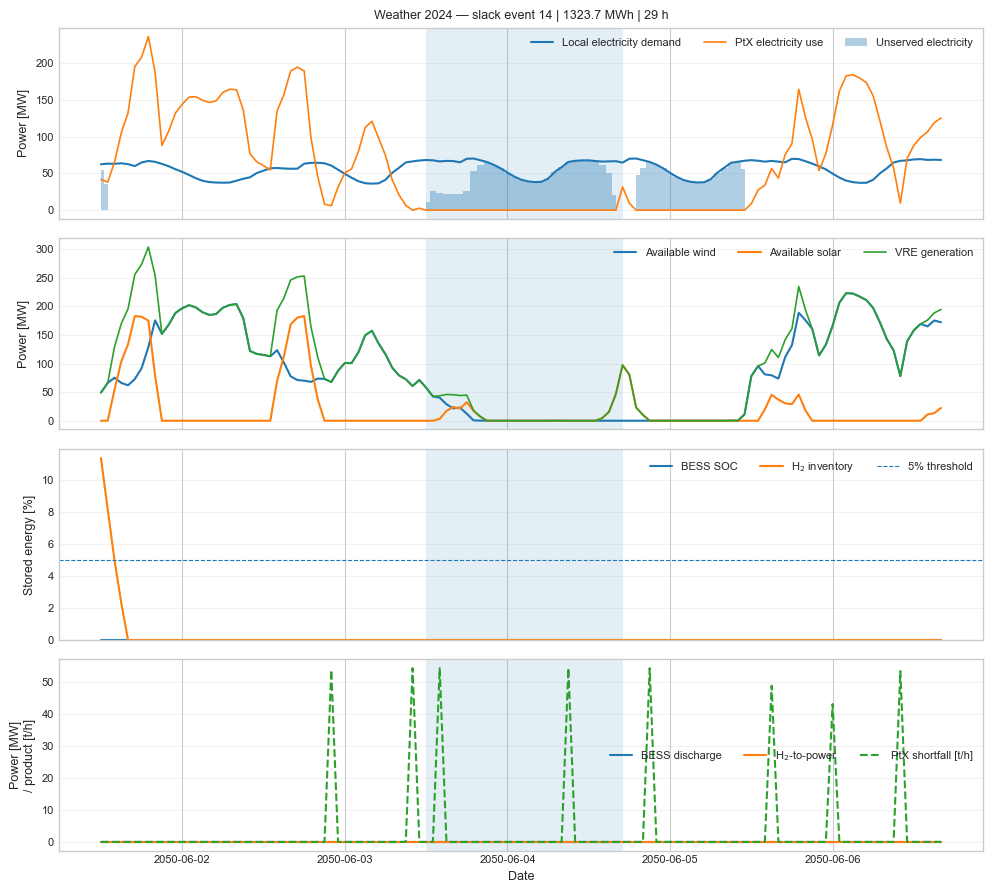

Weather 2024, event 14: 2050-06-03 12:00:00 → 2050-06-04 16:00:00
  Slack: 1323.7 MWh | peak 67.6 MW
  Night: 72.7% | peak-demand hours: 58.7%
  BESS SOC: 0.0% before → minimum 0.0%
  H₂ inventory: 0.0% before → minimum 0.0%
  PtX electricity during event: 0.0 MW average



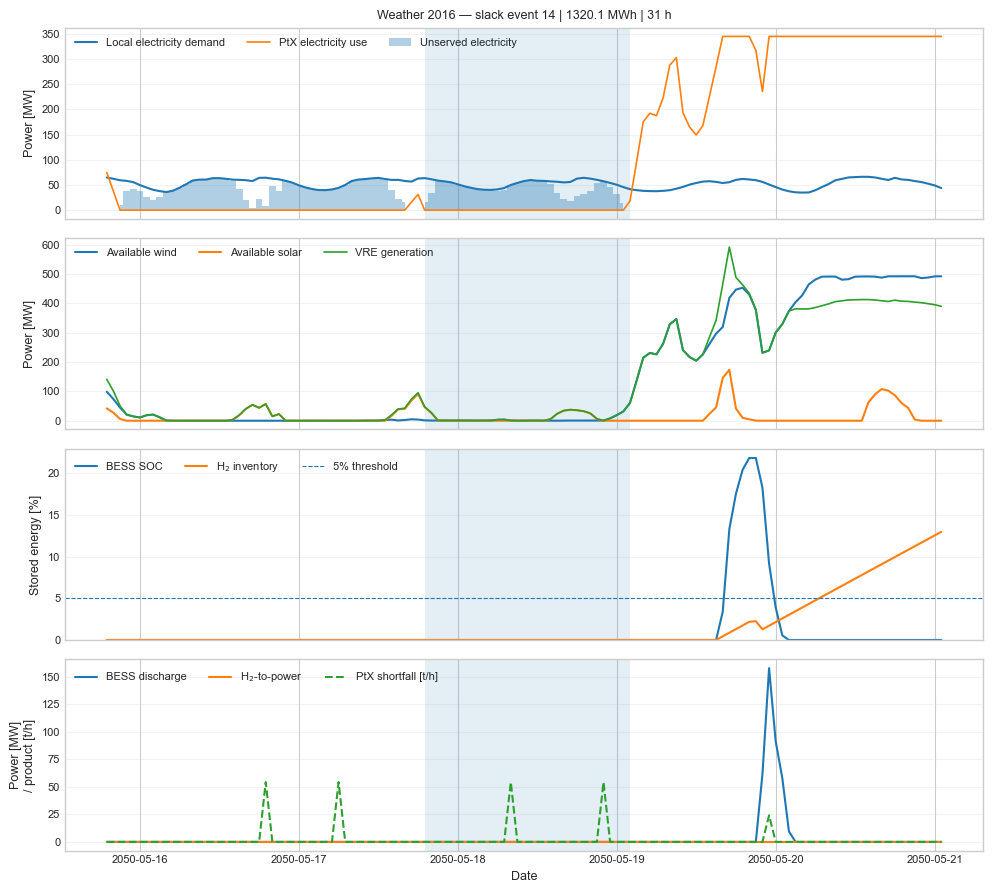

Weather 2016, event 14: 2050-05-17 19:00:00 → 2050-05-19 01:00:00
  Slack: 1320.1 MWh | peak 59.3 MW
  Night: 70.9% | peak-demand hours: 0.0%
  BESS SOC: 0.0% before → minimum 0.0%
  H₂ inventory: 0.0% before → minimum 0.0%
  PtX electricity during event: 0.0 MW average



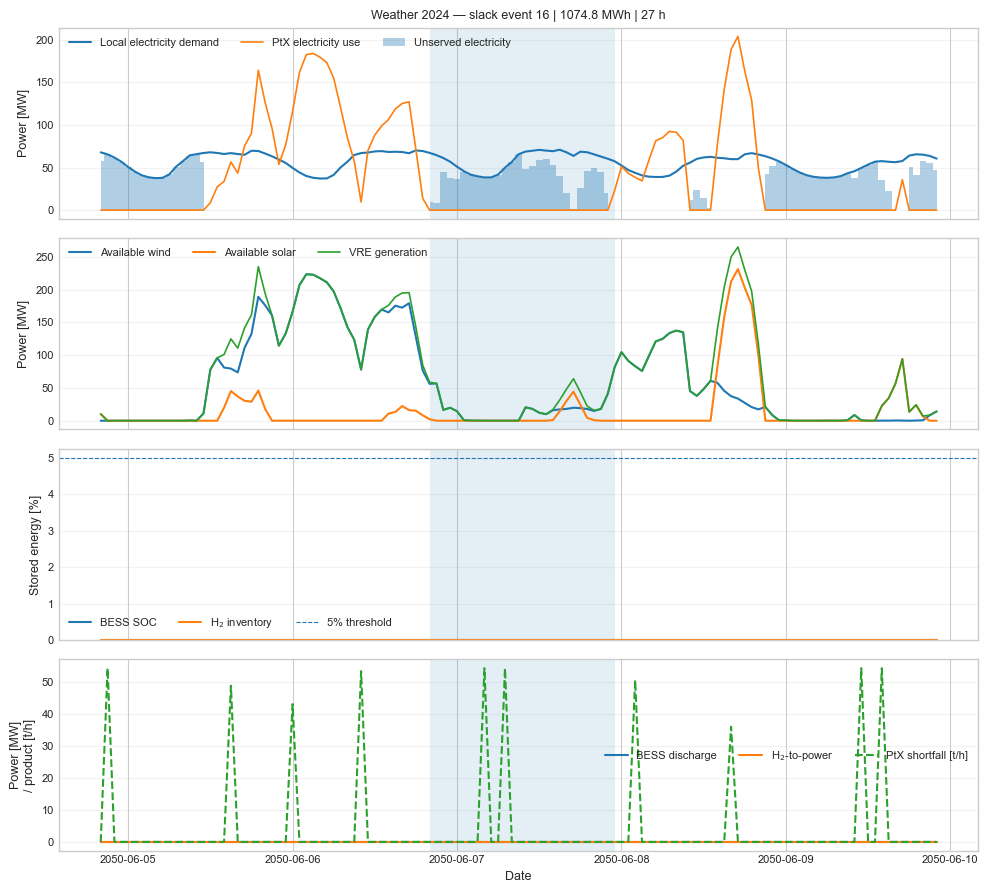

Weather 2024, event 16: 2050-06-06 20:00:00 → 2050-06-07 22:00:00
  Slack: 1074.8 MWh | peak 65.6 MW
  Night: 77.2% | peak-demand hours: 49.3%
  BESS SOC: 0.0% before → minimum 0.0%
  H₂ inventory: 0.0% before → minimum 0.0%
  PtX electricity during event: 0.0 MW average



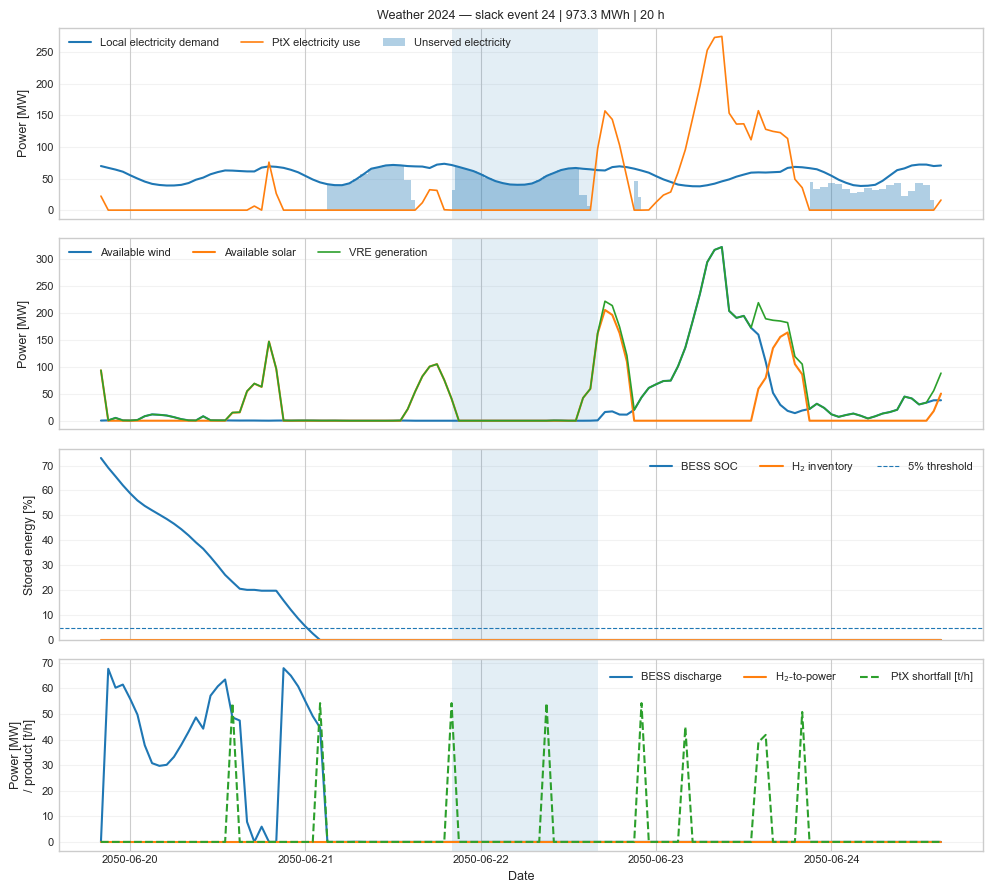

Weather 2024, event 24: 2050-06-21 20:00:00 → 2050-06-22 15:00:00
  Slack: 973.3 MWh | peak 68.4 MW
  Night: 93.6% | peak-demand hours: 33.1%
  BESS SOC: 0.0% before → minimum 0.0%
  H₂ inventory: 0.0% before → minimum 0.0%
  PtX electricity during event: 0.0 MW average



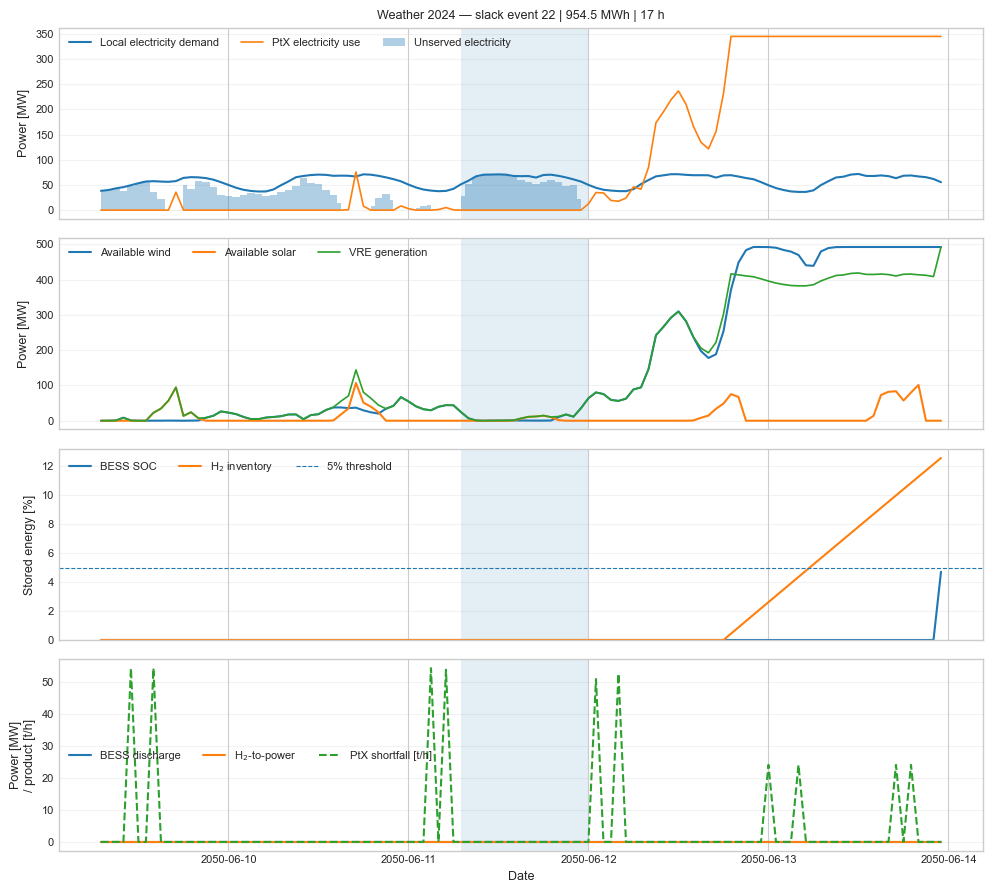

Weather 2024, event 22: 2050-06-11 07:00:00 → 2050-06-11 23:00:00
  Slack: 954.5 MWh | peak 70.6 MW
  Night: 57.2% | peak-demand hours: 73.7%
  BESS SOC: 0.0% before → minimum 0.0%
  H₂ inventory: 0.0% before → minimum 0.0%
  PtX electricity during event: 0.0 MW average



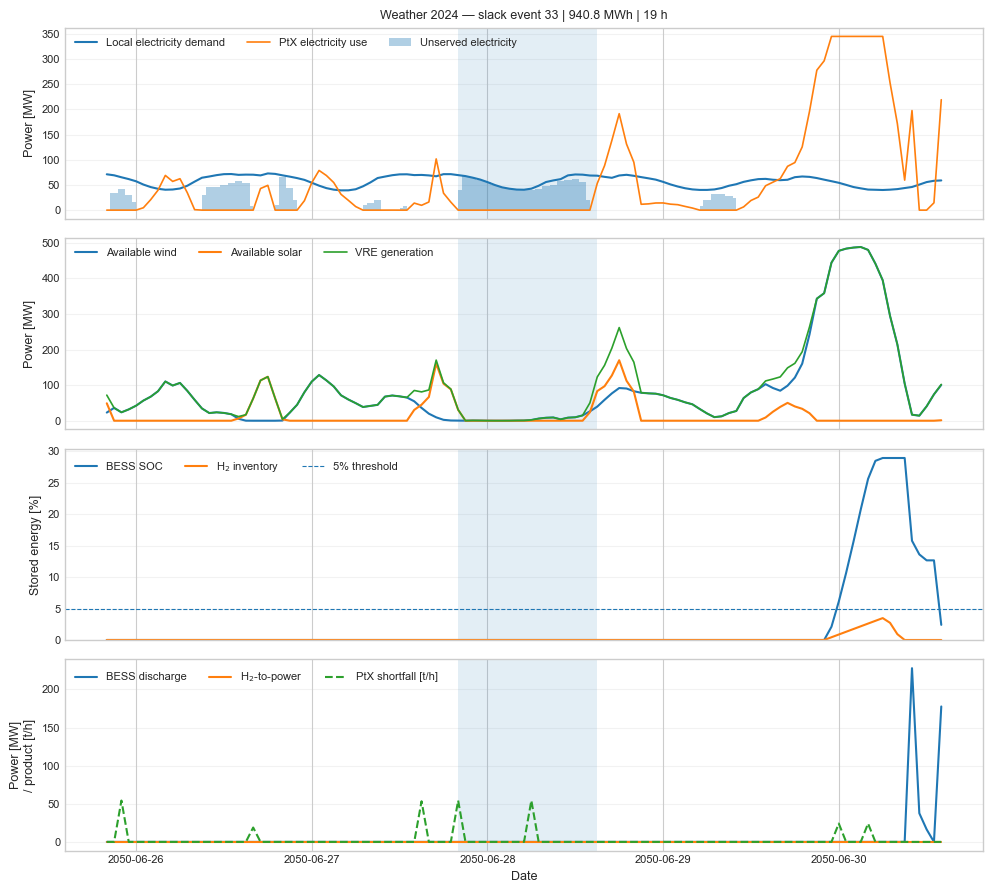

Weather 2024, event 33: 2050-06-27 20:00:00 → 2050-06-28 14:00:00
  Slack: 940.8 MWh | peak 67.5 MW
  Night: 93.7% | peak-demand hours: 32.3%
  BESS SOC: 0.0% before → minimum 0.0%
  H₂ inventory: 0.0% before → minimum 0.0%
  PtX electricity during event: 0.0 MW average



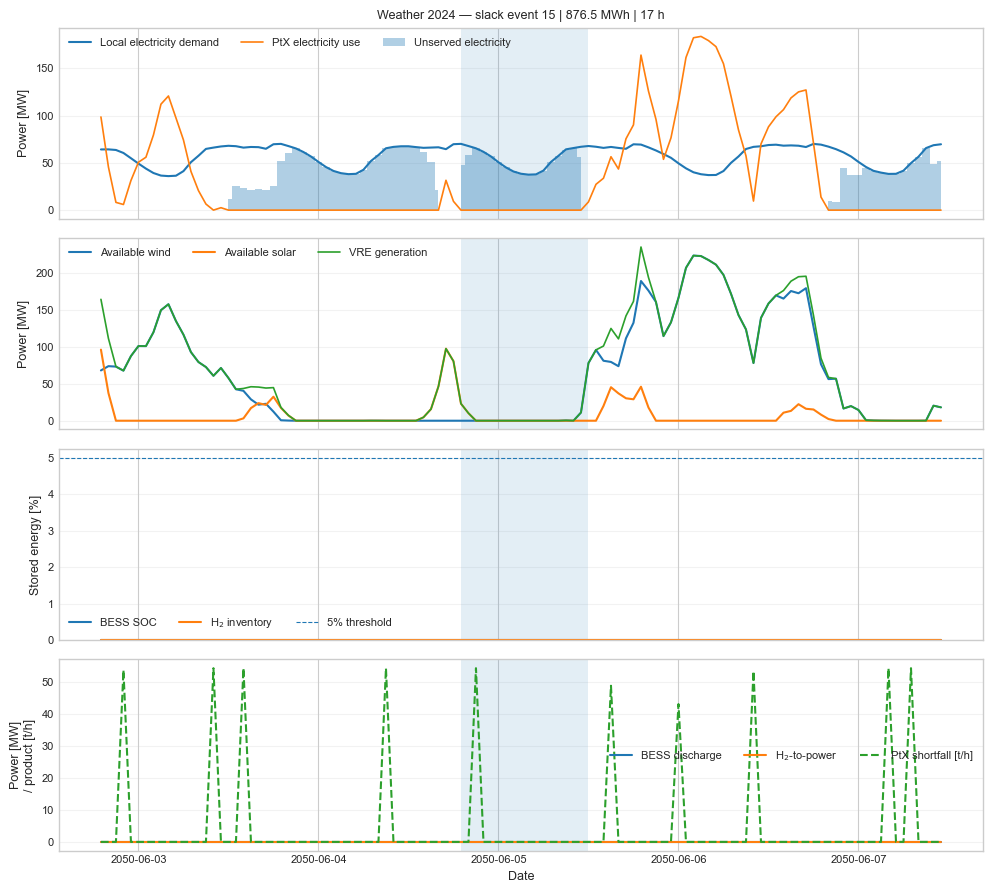

Weather 2024, event 15: 2050-06-04 19:00:00 → 2050-06-05 11:00:00
  Slack: 876.5 MWh | peak 65.7 MW
  Night: 88.0% | peak-demand hours: 33.4%
  BESS SOC: 0.0% before → minimum 0.0%
  H₂ inventory: 0.0% before → minimum 0.0%
  PtX electricity during event: 0.0 MW average



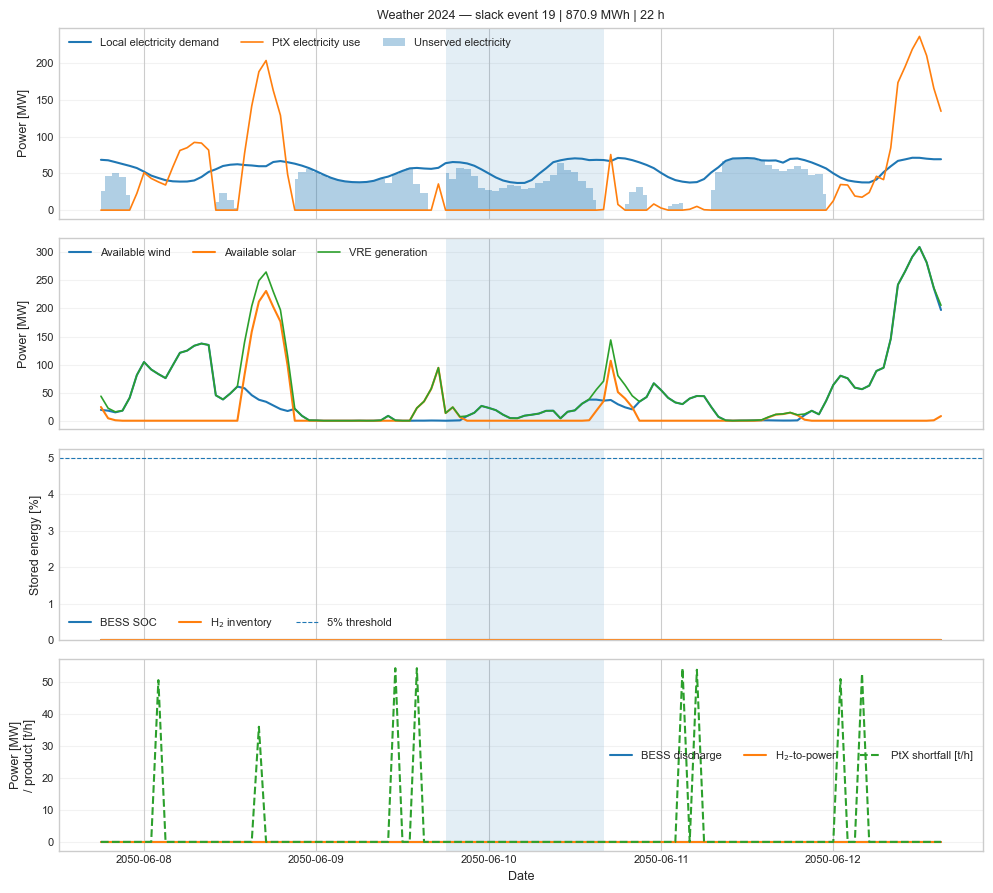

Weather 2024, event 19: 2050-06-09 18:00:00 → 2050-06-10 15:00:00
  Slack: 870.9 MWh | peak 63.8 MW
  Night: 77.6% | peak-demand hours: 46.3%
  BESS SOC: 0.0% before → minimum 0.0%
  H₂ inventory: 0.0% before → minimum 0.0%
  PtX electricity during event: 0.0 MW average



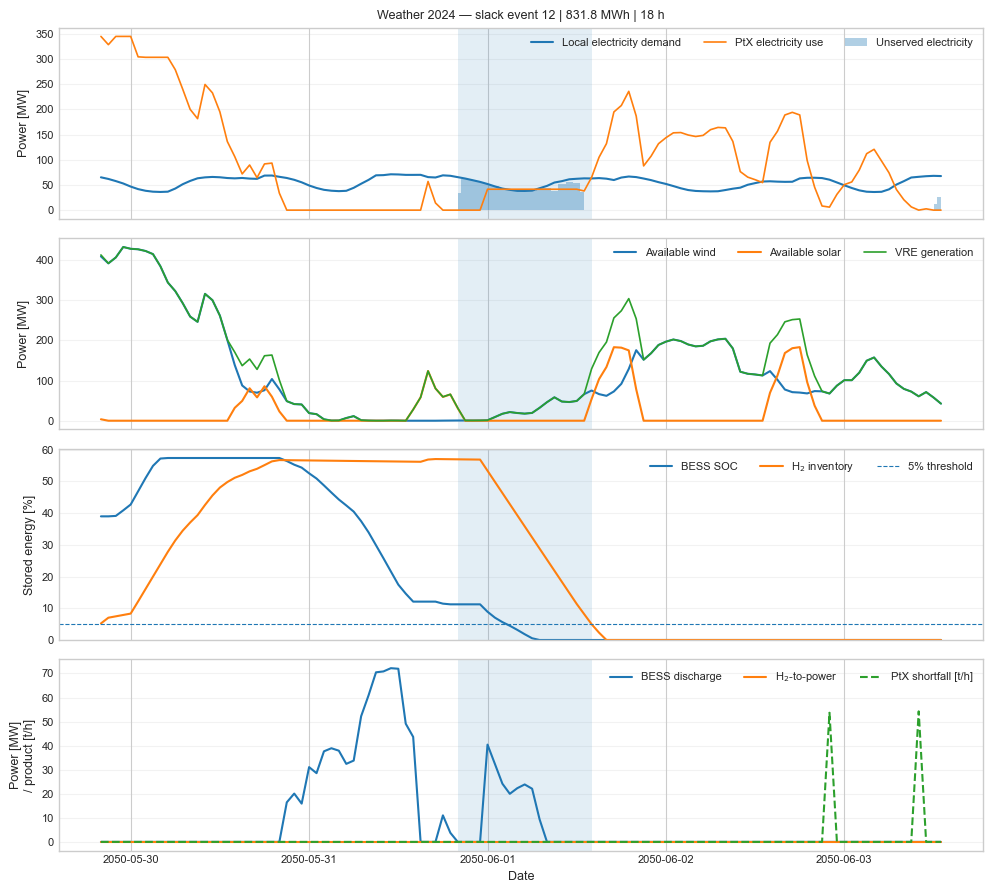

Weather 2024, event 12: 2050-05-31 20:00:00 → 2050-06-01 13:00:00
  Slack: 831.8 MWh | peak 62.2 MW
  Night: 95.8% | peak-demand hours: 4.2%
  BESS SOC: 11.2% before → minimum 0.0%
  H₂ inventory: 57.0% before → minimum 8.2%
  PtX electricity during event: 32.1 MW average



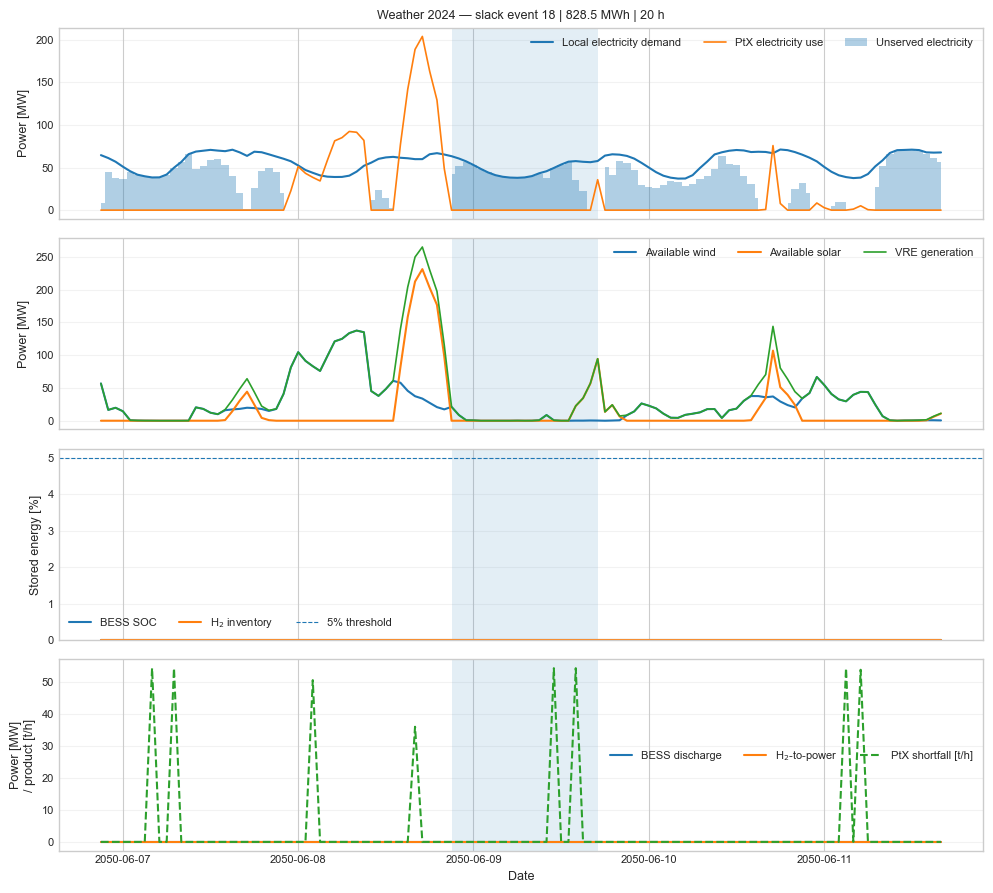

Weather 2024, event 18: 2050-06-08 21:00:00 → 2050-06-09 16:00:00
  Slack: 828.5 MWh | peak 56.9 MW
  Night: 92.9% | peak-demand hours: 0.0%
  BESS SOC: 0.0% before → minimum 0.0%
  H₂ inventory: 0.0% before → minimum 0.0%
  PtX electricity during event: 0.0 MW average



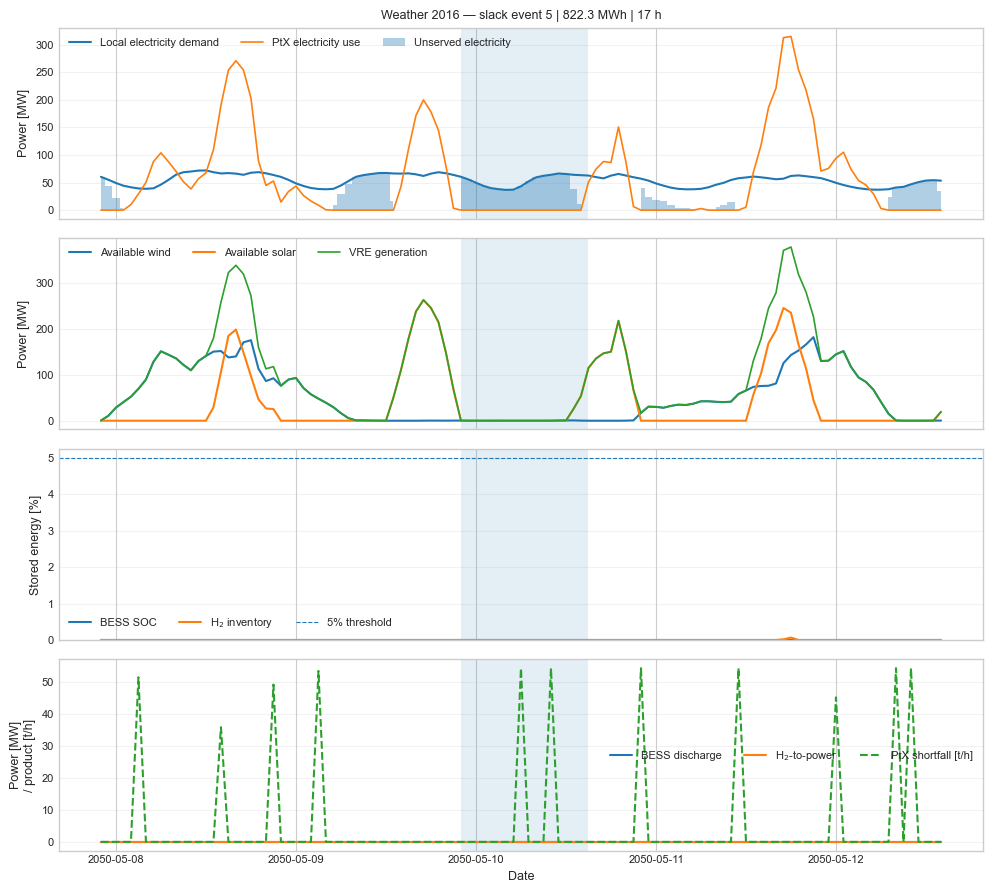

Weather 2016, event 5: 2050-05-09 22:00:00 → 2050-05-10 14:00:00
  Slack: 822.3 MWh | peak 66.1 MW
  Night: 94.0% | peak-demand hours: 15.9%
  BESS SOC: 0.0% before → minimum 0.0%
  H₂ inventory: 0.0% before → minimum 0.0%
  PtX electricity during event: 0.0 MW average



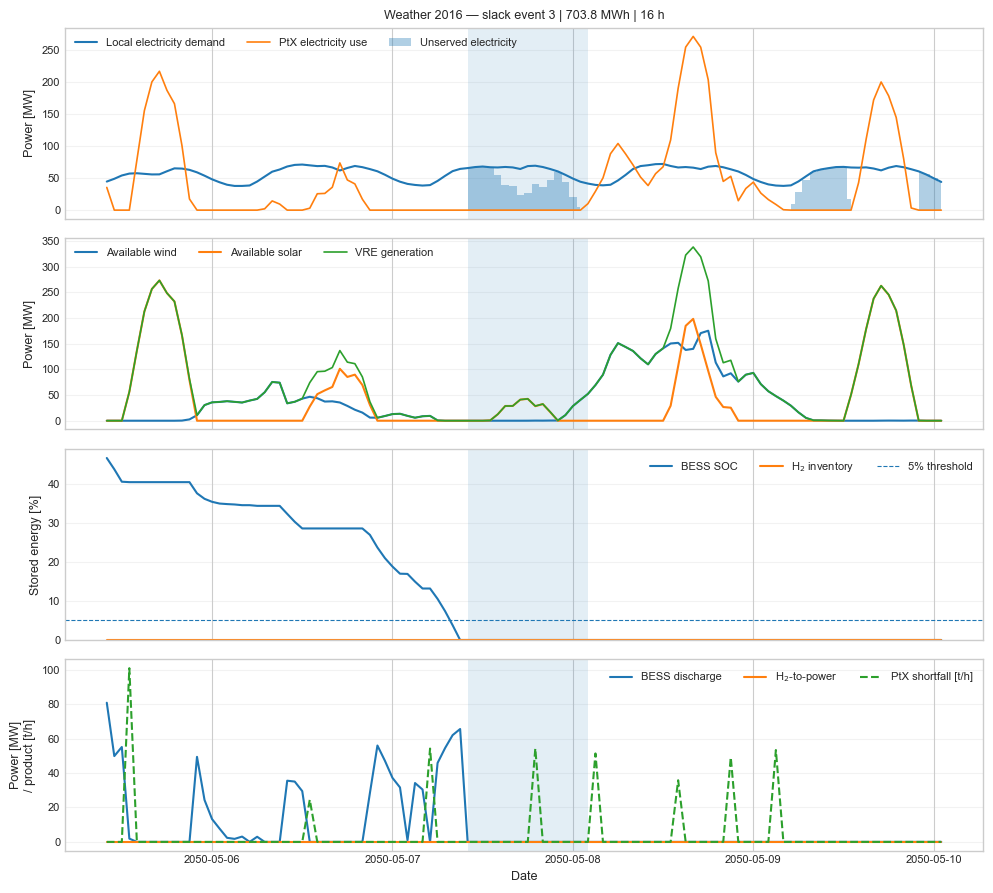

Weather 2016, event 3: 2050-05-07 10:00:00 → 2050-05-08 01:00:00
  Slack: 703.8 MWh | peak 68.0 MW
  Night: 47.0% | peak-demand hours: 71.4%
  BESS SOC: 0.0% before → minimum 0.0%
  H₂ inventory: 0.0% before → minimum 0.0%
  PtX electricity during event: 0.0 MW average



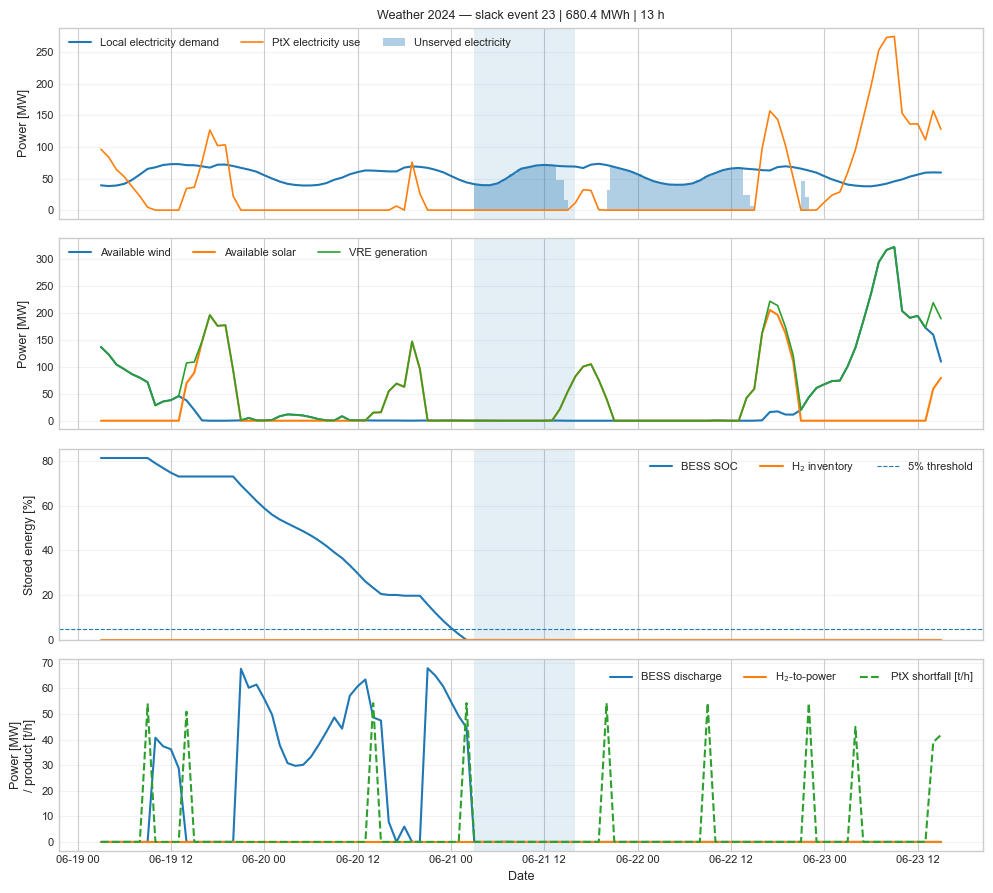

Weather 2024, event 23: 2050-06-21 03:00:00 → 2050-06-21 15:00:00
  Slack: 680.4 MWh | peak 71.5 MW
  Night: 90.4% | peak-demand hours: 60.5%
  BESS SOC: 0.0% before → minimum 0.0%
  H₂ inventory: 0.0% before → minimum 0.0%
  PtX electricity during event: 0.0 MW average



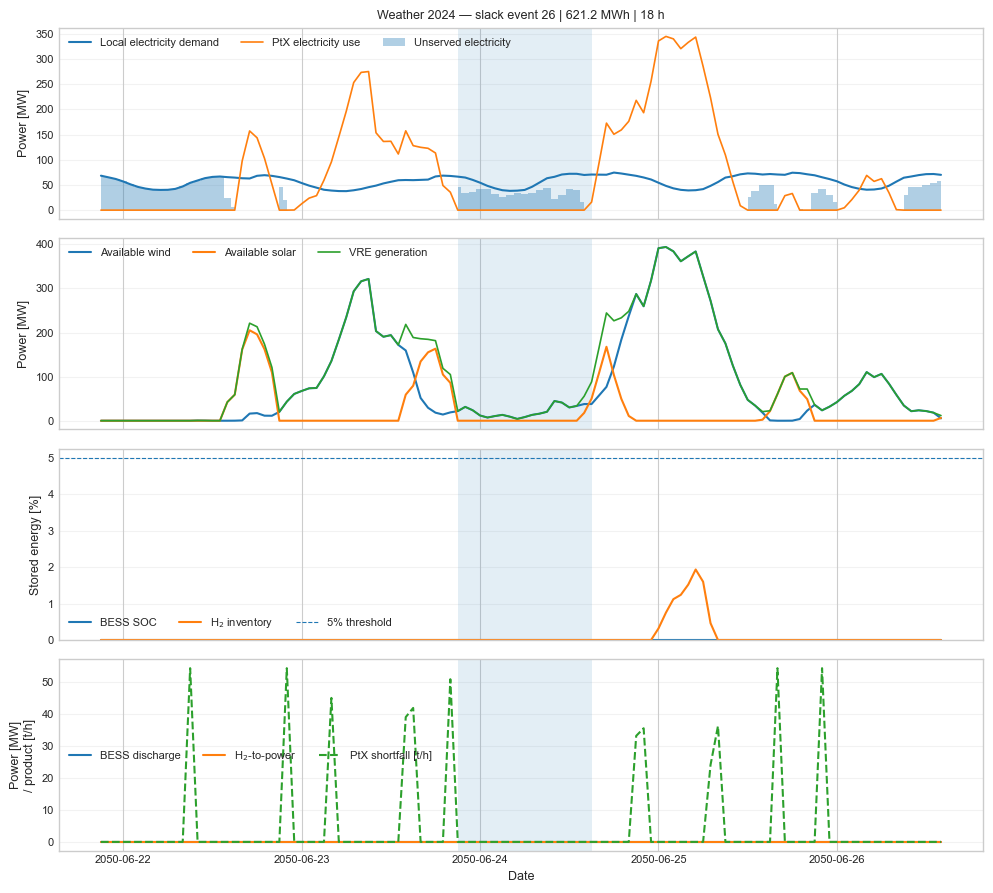

Weather 2024, event 26: 2050-06-23 21:00:00 → 2050-06-24 14:00:00
  Slack: 621.2 MWh | peak 45.2 MW
  Night: 97.5% | peak-demand hours: 31.4%
  BESS SOC: 0.0% before → minimum 0.0%
  H₂ inventory: 0.0% before → minimum 0.0%
  PtX electricity during event: 0.0 MW average



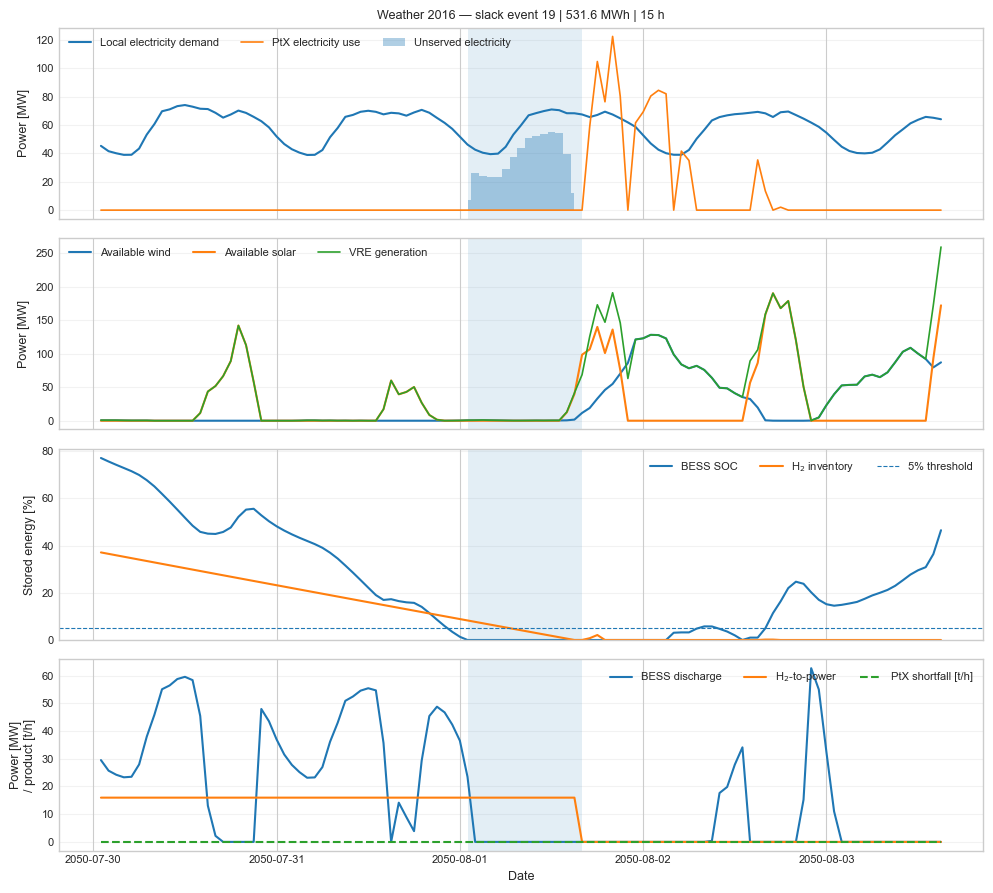

Weather 2016, event 19: 2050-08-01 01:00:00 → 2050-08-01 15:00:00
  Slack: 531.6 MWh | peak 54.9 MW
  Night: 90.3% | peak-demand hours: 59.8%
  BESS SOC: 1.4% before → minimum 0.0%
  H₂ inventory: 8.9% before → minimum 0.0%
  PtX electricity during event: 0.0 MW average



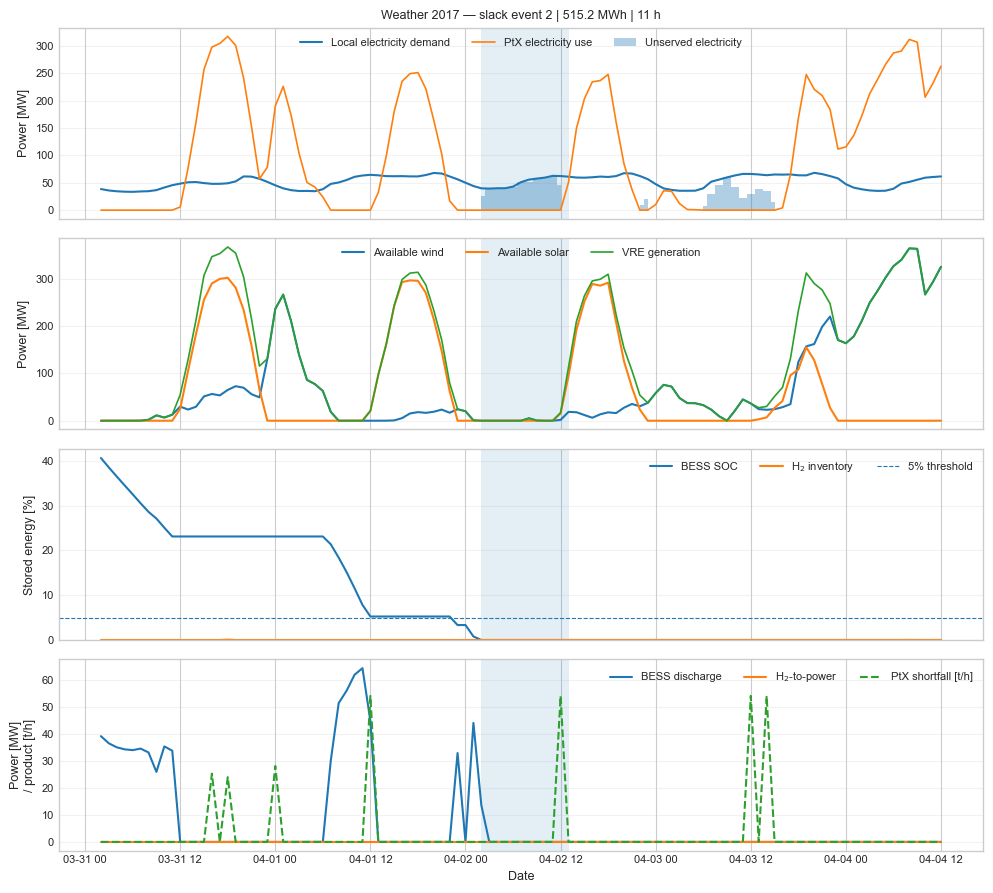

Weather 2017, event 2: 2050-04-02 02:00:00 → 2050-04-02 12:00:00
  Slack: 515.2 MWh | peak 62.6 MW
  Night: 91.2% | peak-demand hours: 0.0%
  BESS SOC: 0.8% before → minimum 0.0%
  H₂ inventory: 0.0% before → minimum 0.0%
  PtX electricity during event: 0.0 MW average



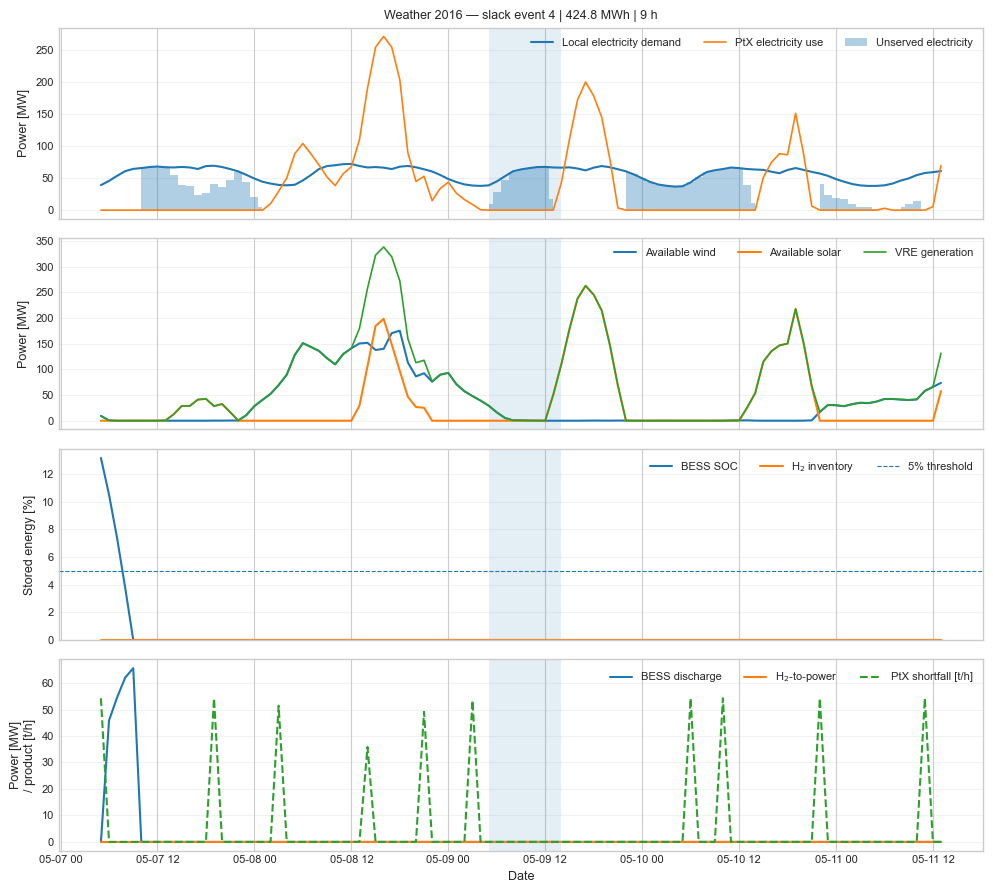

Weather 2016, event 4: 2050-05-09 05:00:00 → 2050-05-09 13:00:00
  Slack: 424.8 MWh | peak 67.4 MW
  Night: 96.1% | peak-demand hours: 50.9%
  BESS SOC: 0.0% before → minimum 0.0%
  H₂ inventory: 0.0% before → minimum 0.0%
  PtX electricity during event: 0.0 MW average



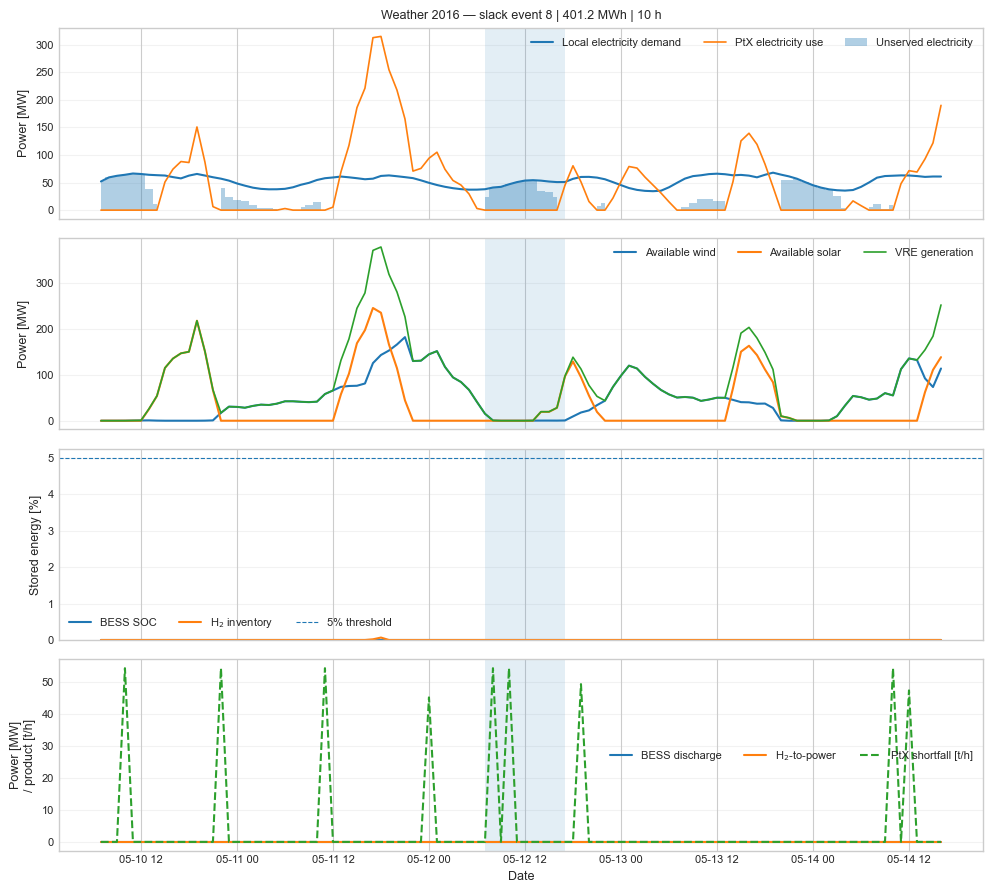

Weather 2016, event 8: 2050-05-12 07:00:00 → 2050-05-12 16:00:00
  Slack: 401.2 MWh | peak 54.1 MW
  Night: 77.6% | peak-demand hours: 0.0%
  BESS SOC: 0.0% before → minimum 0.0%
  H₂ inventory: 0.0% before → minimum 0.0%
  PtX electricity during event: 0.0 MW average



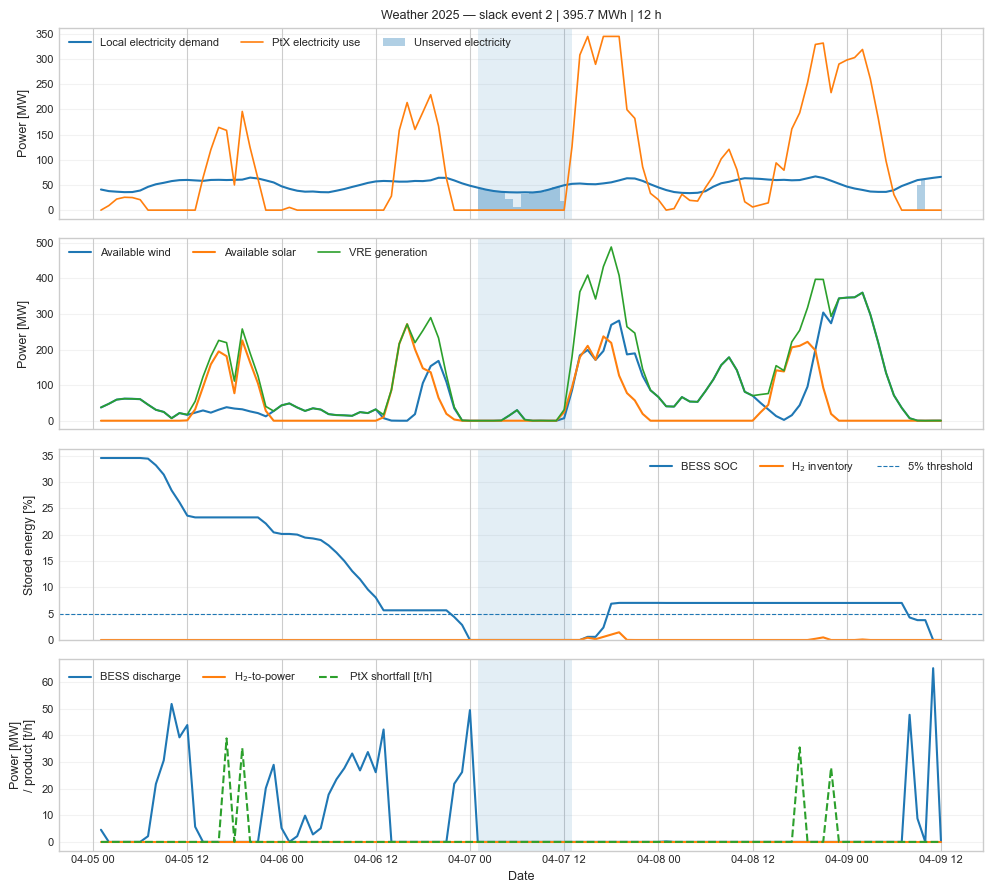

Weather 2025, event 2: 2050-04-07 01:00:00 → 2050-04-07 12:00:00
  Slack: 395.7 MWh | peak 45.2 MW
  Night: 95.2% | peak-demand hours: 0.0%
  BESS SOC: 0.0% before → minimum 0.0%
  H₂ inventory: 0.0% before → minimum 0.0%
  PtX electricity during event: 0.0 MW average



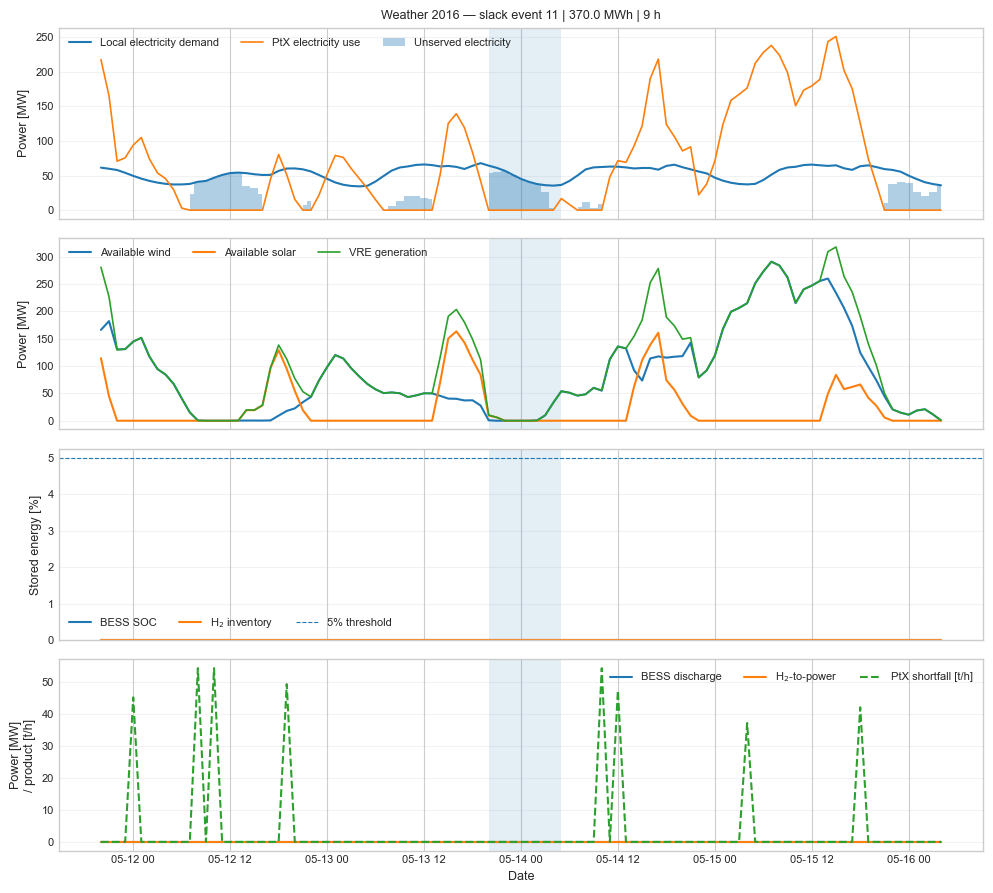

Weather 2016, event 11: 2050-05-13 20:00:00 → 2050-05-14 04:00:00
  Slack: 370.0 MWh | peak 56.9 MW
  Night: 70.4% | peak-demand hours: 0.0%
  BESS SOC: 0.0% before → minimum 0.0%
  H₂ inventory: 0.0% before → minimum 0.0%
  PtX electricity during event: 0.0 MW average



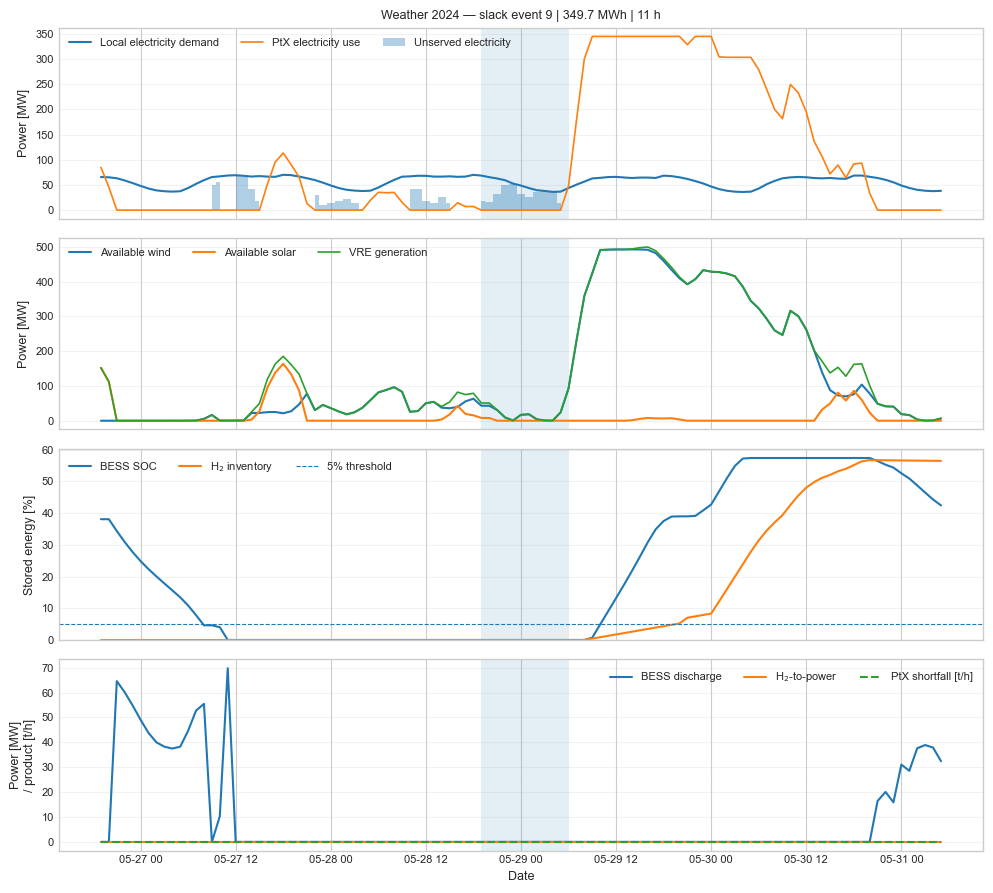

Weather 2024, event 9: 2050-05-28 19:00:00 → 2050-05-29 05:00:00
  Slack: 349.7 MWh | peak 52.1 MW
  Night: 90.2% | peak-demand hours: 9.8%
  BESS SOC: 0.0% before → minimum 0.0%
  H₂ inventory: 0.0% before → minimum 0.0%
  PtX electricity during event: 0.0 MW average



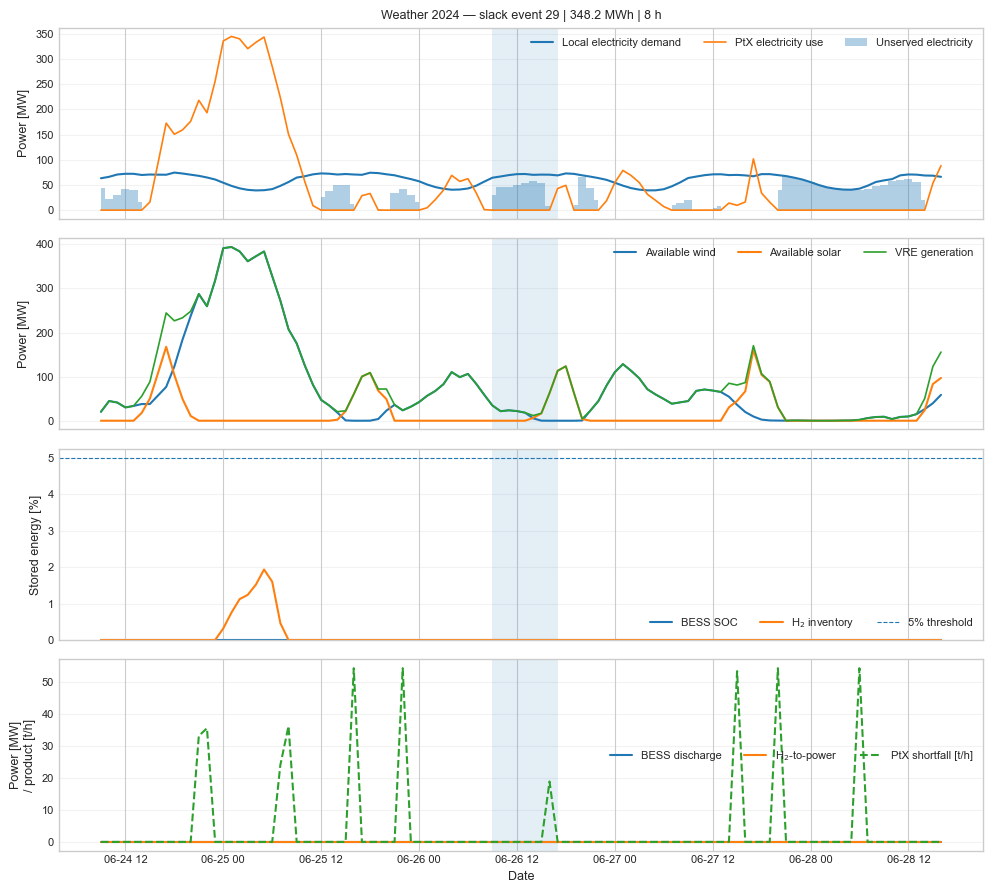

Weather 2024, event 29: 2050-06-26 09:00:00 → 2050-06-26 16:00:00
  Slack: 348.2 MWh | peak 58.6 MW
  Night: 65.0% | peak-demand hours: 91.2%
  BESS SOC: 0.0% before → minimum 0.0%
  H₂ inventory: 0.0% before → minimum 0.0%
  PtX electricity during event: 0.0 MW average



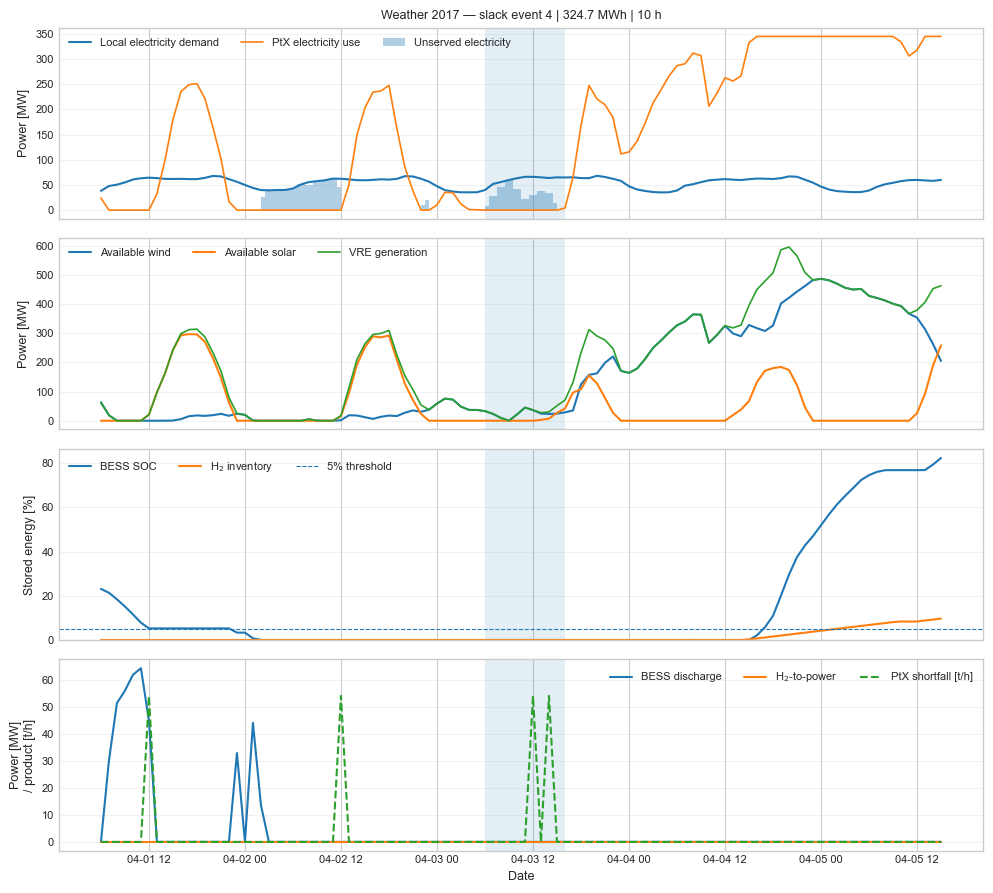

Weather 2017, event 4: 2050-04-03 06:00:00 → 2050-04-03 15:00:00
  Slack: 324.7 MWh | peak 59.8 MW
  Night: 73.2% | peak-demand hours: 32.4%
  BESS SOC: 0.0% before → minimum 0.0%
  H₂ inventory: 0.0% before → minimum 0.0%
  PtX electricity during event: 0.0 MW average



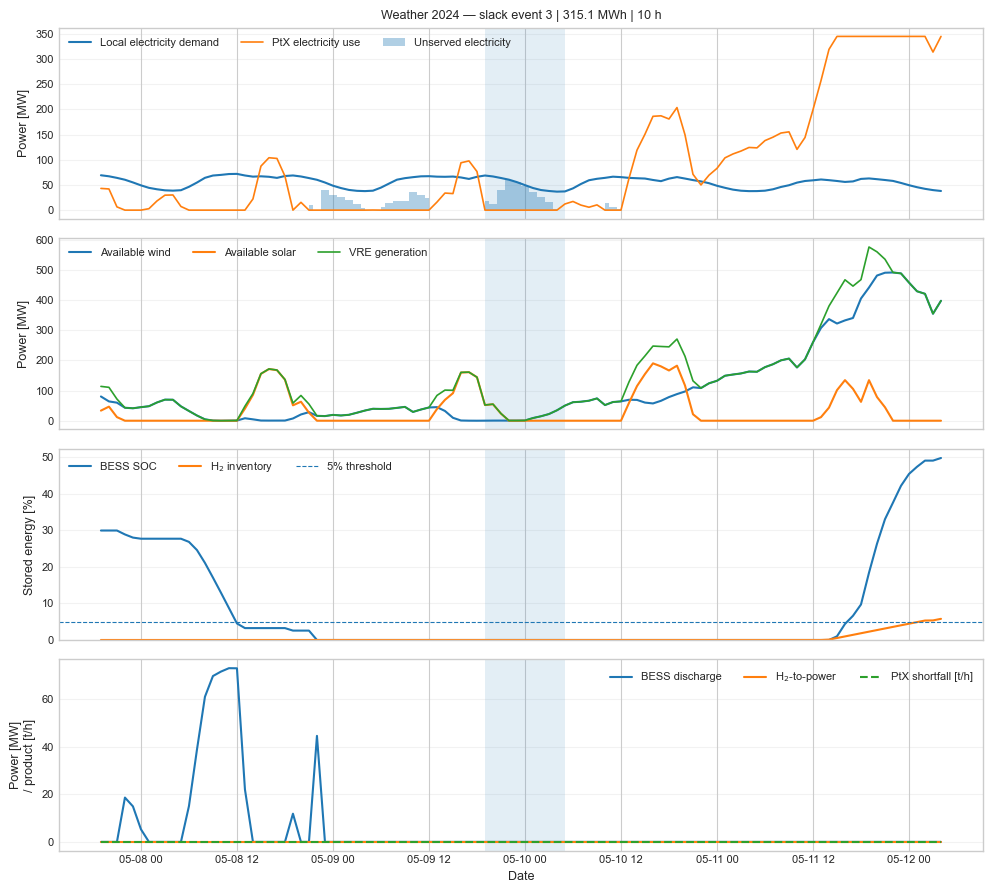

Weather 2024, event 3: 2050-05-09 19:00:00 → 2050-05-10 04:00:00
  Slack: 315.1 MWh | peak 60.1 MW
  Night: 77.4% | peak-demand hours: 9.8%
  BESS SOC: 0.0% before → minimum 0.0%
  H₂ inventory: 0.0% before → minimum 0.0%
  PtX electricity during event: 0.0 MW average



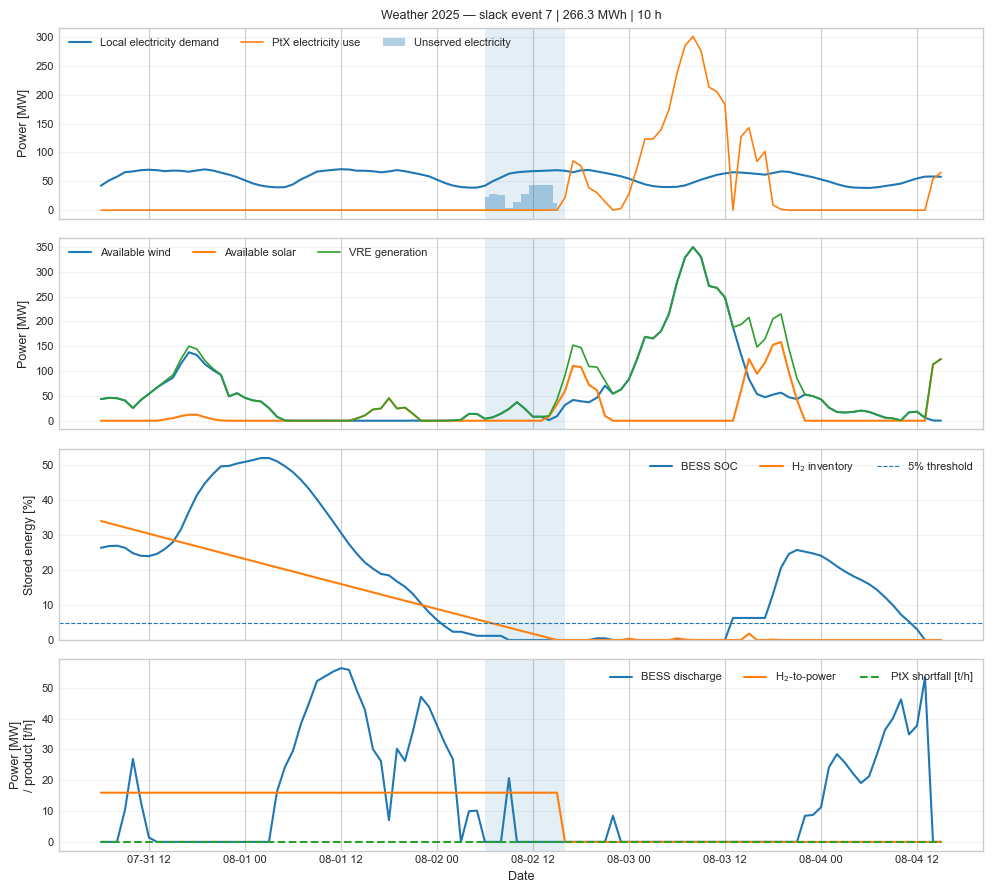

Weather 2025, event 7: 2050-08-02 06:00:00 → 2050-08-02 15:00:00
  Slack: 266.3 MWh | peak 44.3 MW
  Night: 79.1% | peak-demand hours: 69.4%
  BESS SOC: 1.2% before → minimum 0.0%
  H₂ inventory: 5.9% before → minimum 0.0%
  PtX electricity during event: 0.0 MW average



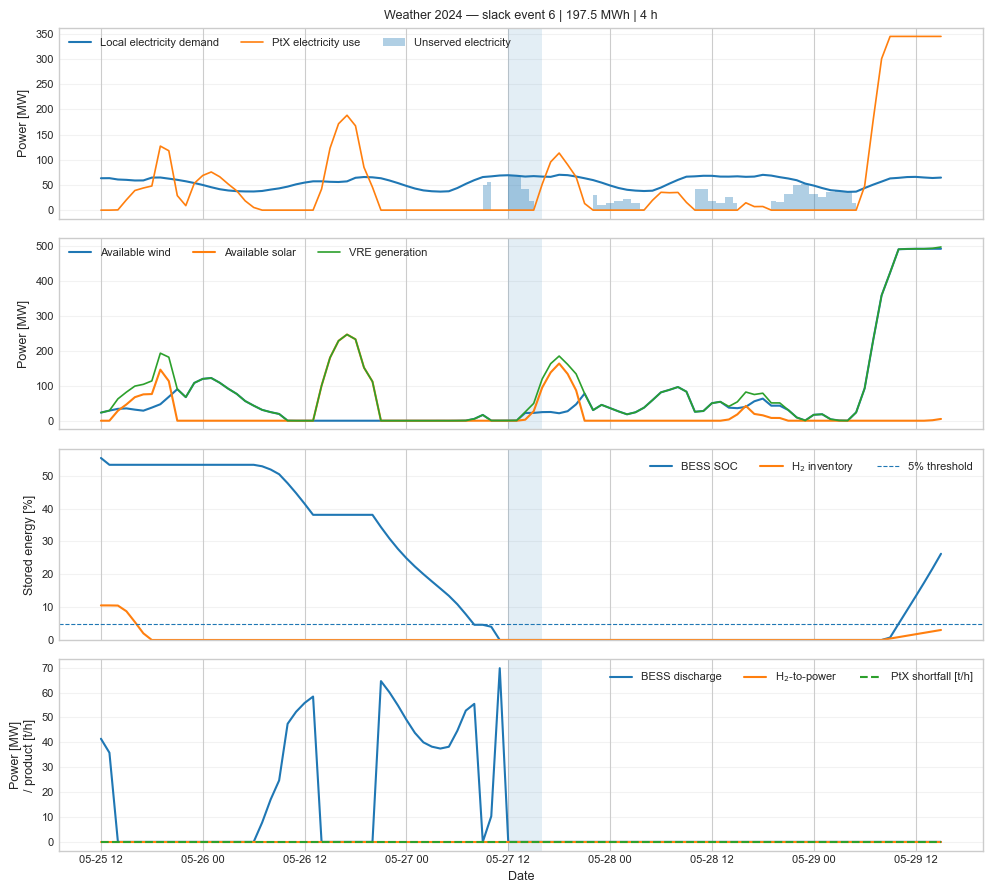

Weather 2024, event 6: 2050-05-27 12:00:00 → 2050-05-27 15:00:00
  Slack: 197.5 MWh | peak 68.9 MW
  Night: 69.1% | peak-demand hours: 100.0%
  BESS SOC: 0.0% before → minimum 0.0%
  H₂ inventory: 0.0% before → minimum 0.0%
  PtX electricity during event: 0.0 MW average



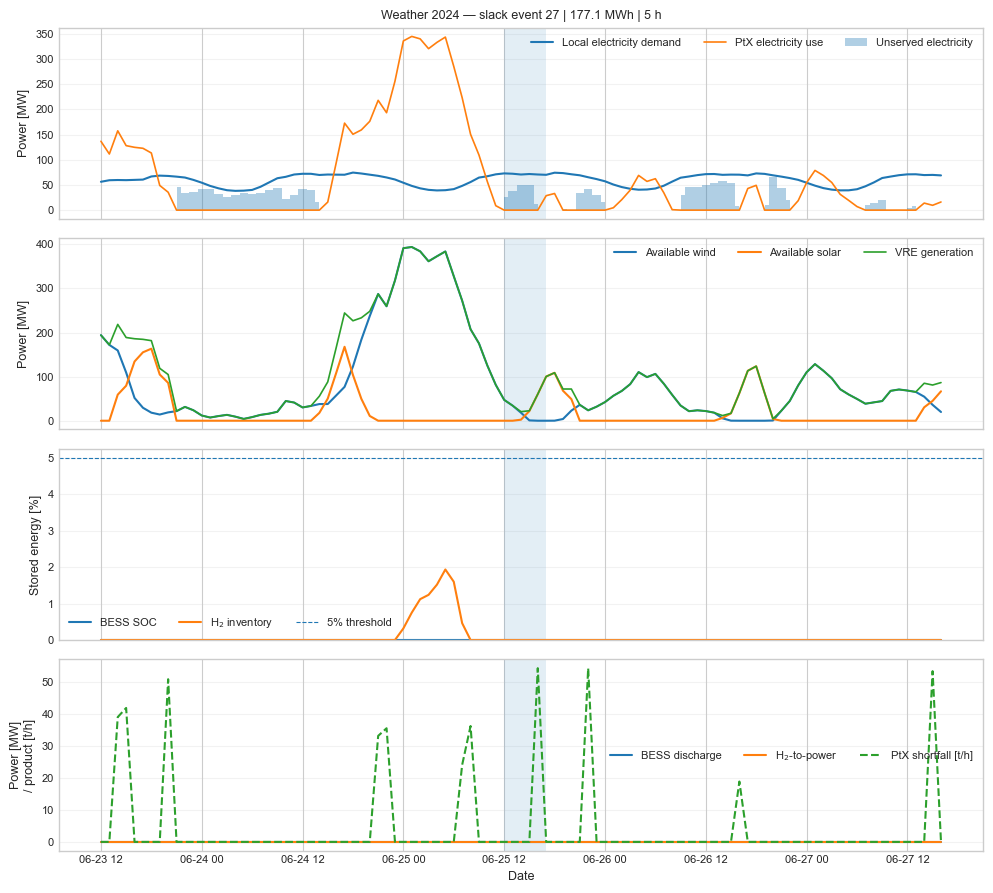

Weather 2024, event 27: 2050-06-25 12:00:00 → 2050-06-25 16:00:00
  Slack: 177.1 MWh | peak 50.6 MW
  Night: 36.8% | peak-demand hours: 100.0%
  BESS SOC: 0.0% before → minimum 0.0%
  H₂ inventory: 0.0% before → minimum 0.0%
  PtX electricity during event: 0.0 MW average



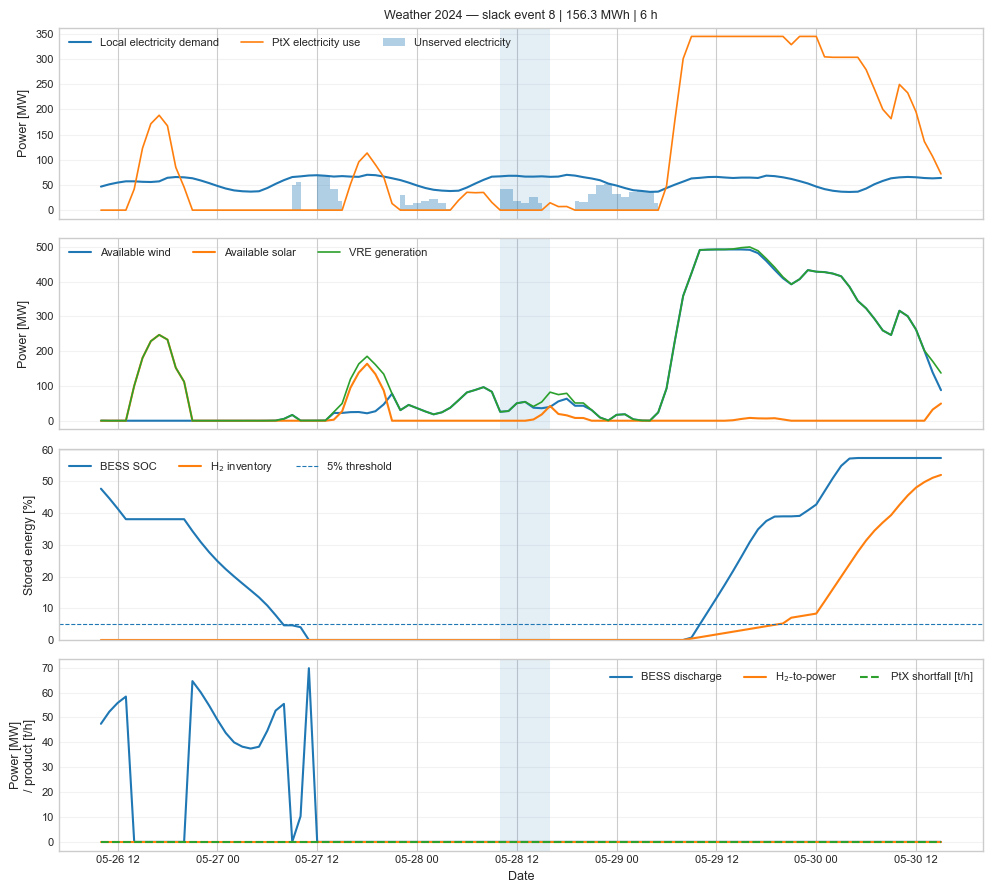

Weather 2024, event 8: 2050-05-28 10:00:00 → 2050-05-28 15:00:00
  Slack: 156.3 MWh | peak 42.0 MW
  Night: 73.9% | peak-demand hours: 100.0%
  BESS SOC: 0.0% before → minimum 0.0%
  H₂ inventory: 0.0% before → minimum 0.0%
  PtX electricity during event: 0.0 MW average



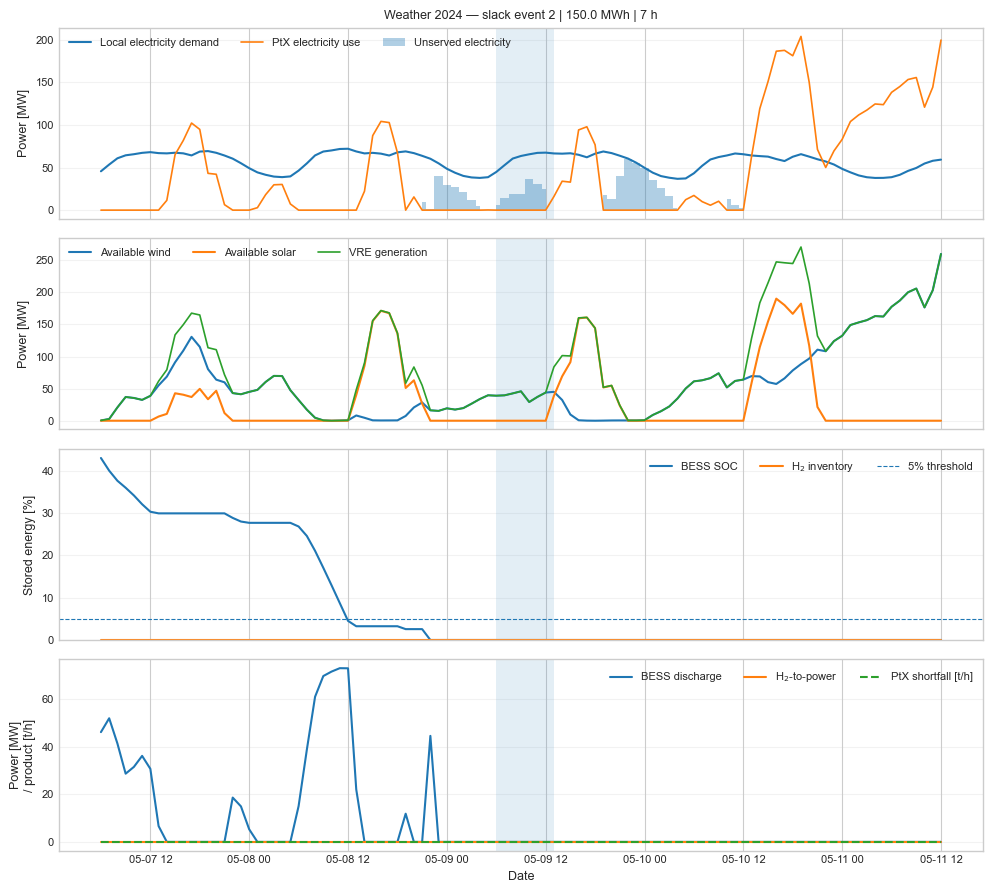

Weather 2024, event 2: 2050-05-09 06:00:00 → 2050-05-09 12:00:00
  Slack: 150.0 MWh | peak 36.9 MW
  Night: 100.0% | peak-demand hours: 61.4%
  BESS SOC: 0.0% before → minimum 0.0%
  H₂ inventory: 0.0% before → minimum 0.0%
  PtX electricity during event: 0.0 MW average



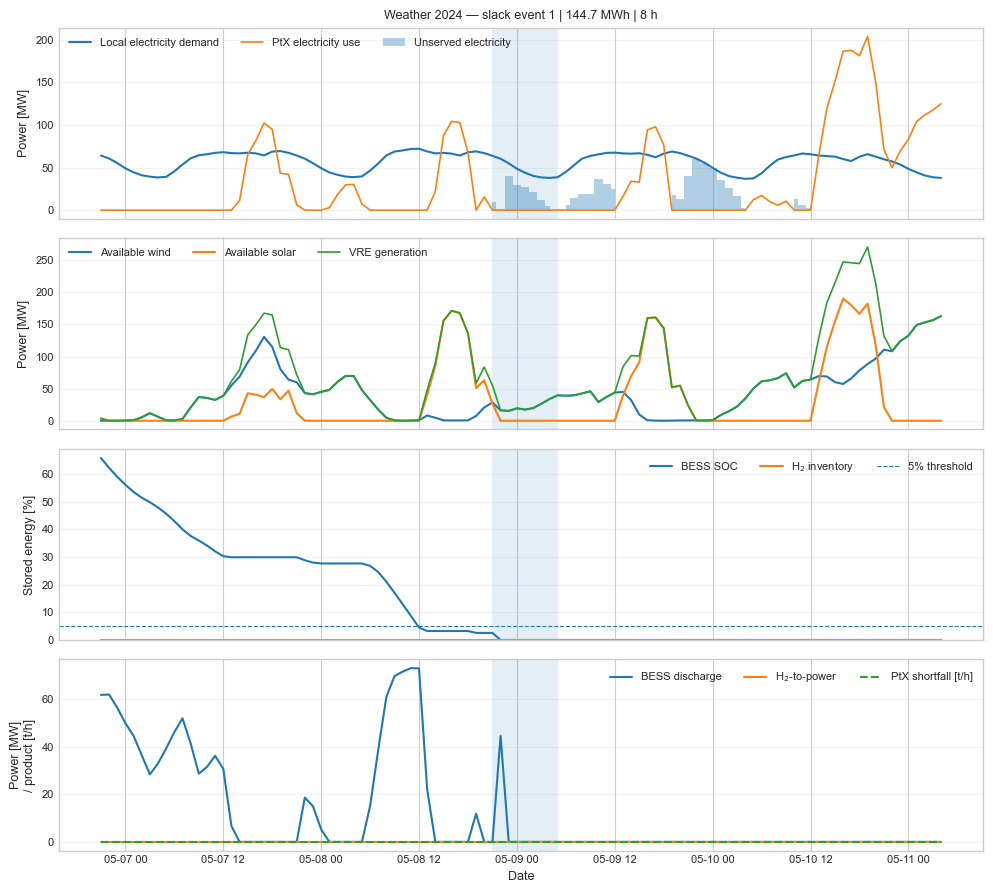

Weather 2024, event 1: 2050-05-08 21:00:00 → 2050-05-09 04:00:00
  Slack: 144.7 MWh | peak 39.8 MW
  Night: 93.3% | peak-demand hours: 0.0%
  BESS SOC: 2.6% before → minimum 0.0%
  H₂ inventory: 0.0% before → minimum 0.0%
  PtX electricity during event: 0.0 MW average



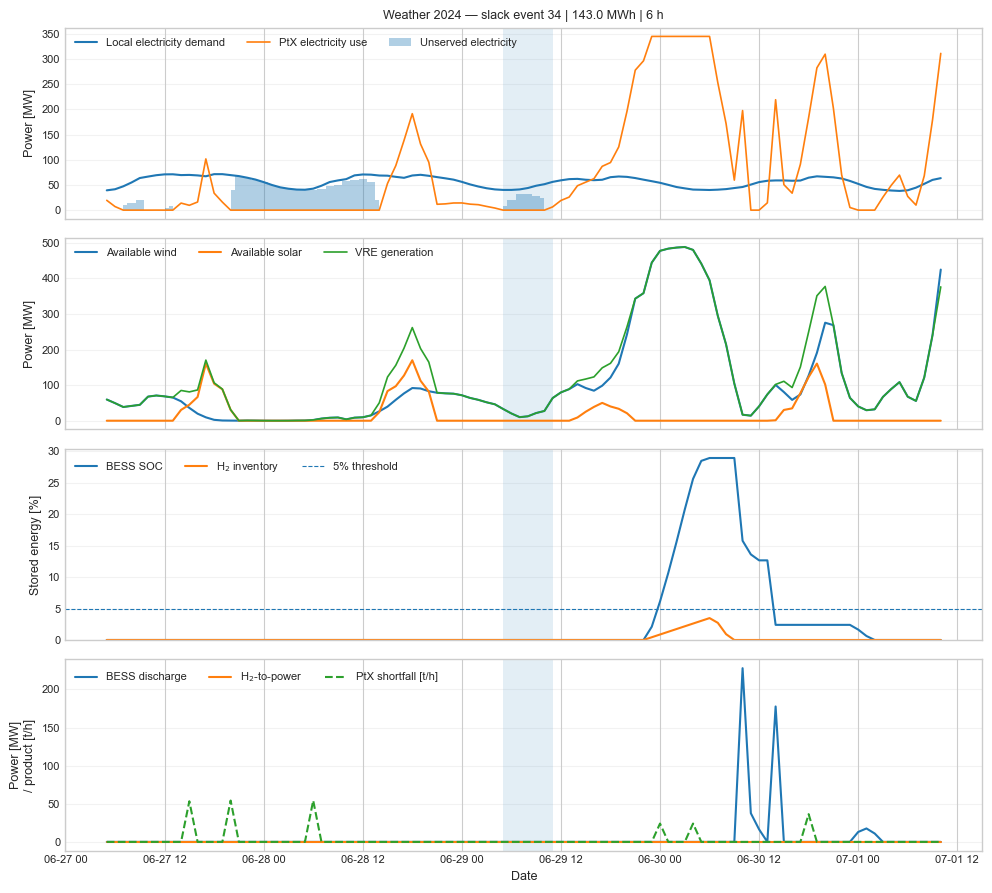

Weather 2024, event 34: 2050-06-29 05:00:00 → 2050-06-29 10:00:00
  Slack: 143.0 MWh | peak 31.8 MW
  Night: 100.0% | peak-demand hours: 0.0%
  BESS SOC: 0.0% before → minimum 0.0%
  H₂ inventory: 0.0% before → minimum 0.0%
  PtX electricity during event: 0.0 MW average



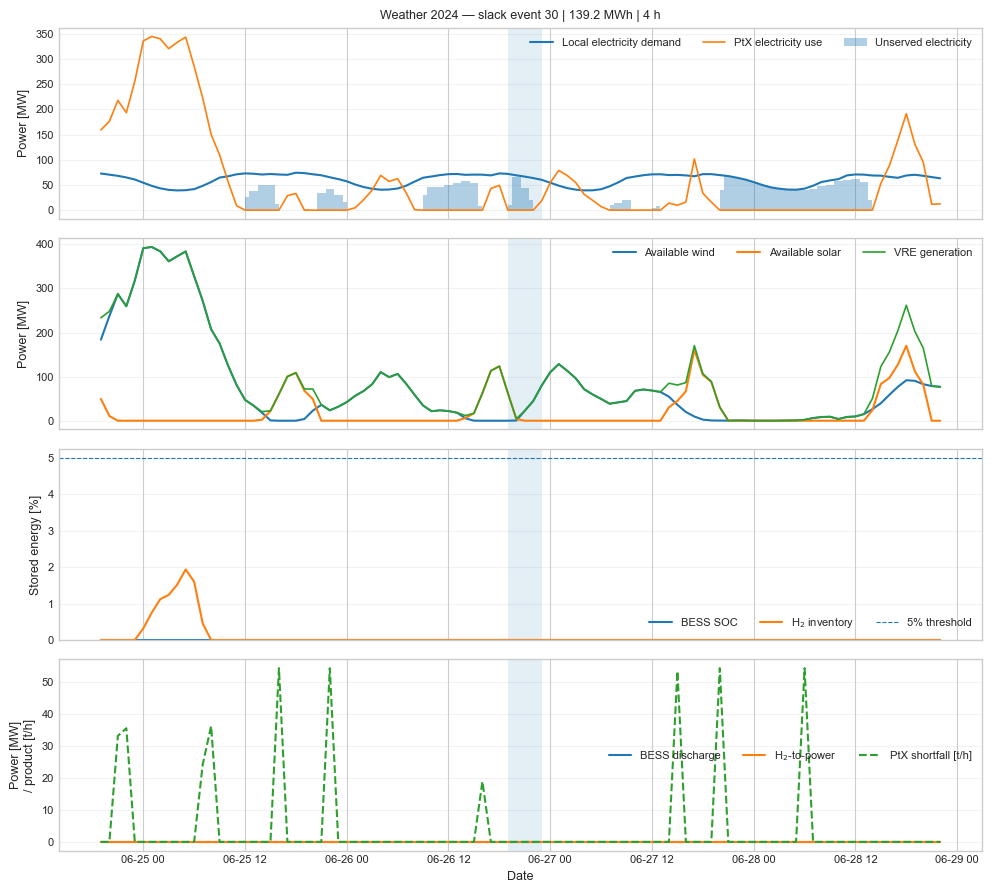

Weather 2024, event 30: 2050-06-26 19:00:00 → 2050-06-26 22:00:00
  Slack: 139.2 MWh | peak 64.9 MW
  Night: 45.9% | peak-demand hours: 85.9%
  BESS SOC: 0.0% before → minimum 0.0%
  H₂ inventory: 0.0% before → minimum 0.0%
  PtX electricity during event: 0.0 MW average



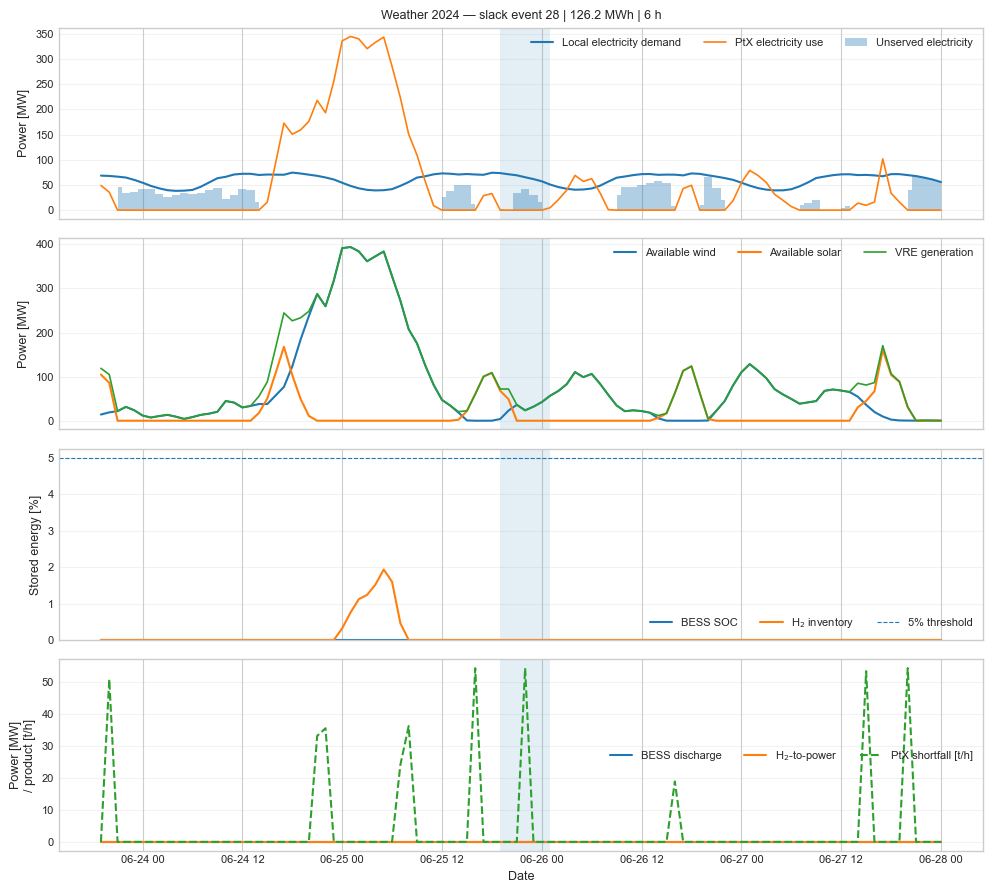

Weather 2024, event 28: 2050-06-25 19:00:00 → 2050-06-26 00:00:00
  Slack: 126.2 MWh | peak 42.2 MW
  Night: 97.0% | peak-demand hours: 63.2%
  BESS SOC: 0.0% before → minimum 0.0%
  H₂ inventory: 0.0% before → minimum 0.0%
  PtX electricity during event: 0.0 MW average



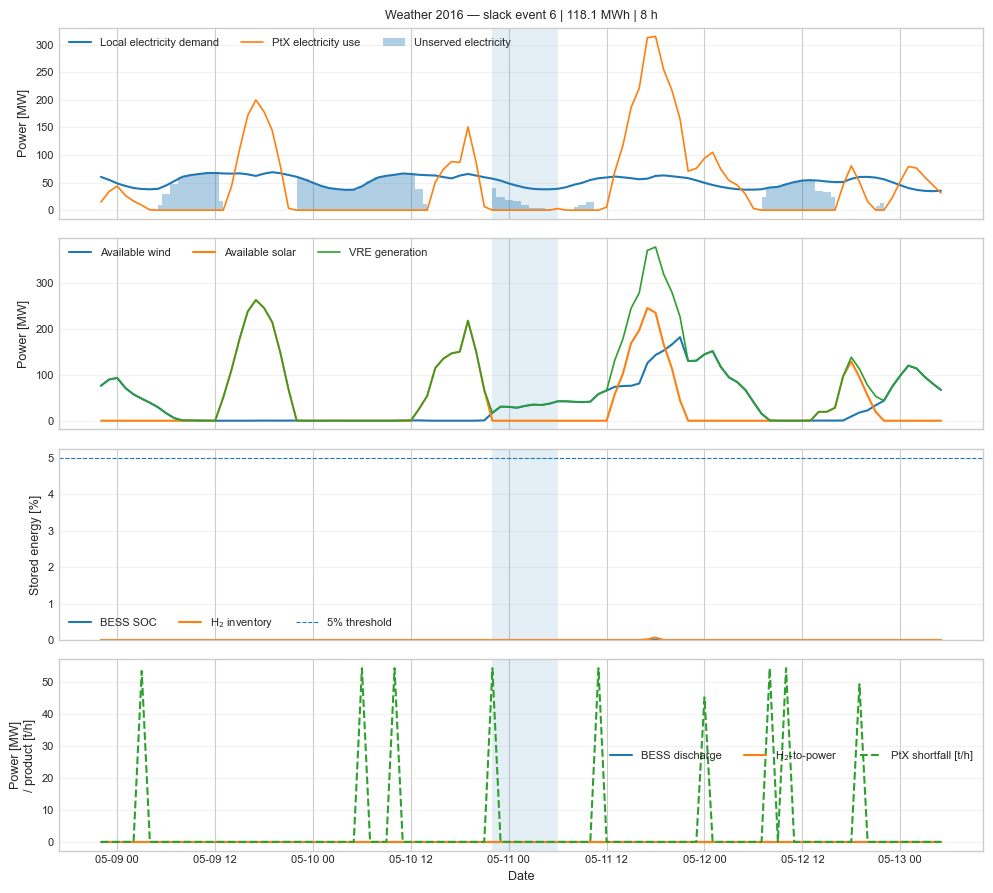

Weather 2016, event 6: 2050-05-10 22:00:00 → 2050-05-11 05:00:00
  Slack: 118.1 MWh | peak 40.3 MW
  Night: 100.0% | peak-demand hours: 0.0%
  BESS SOC: 0.0% before → minimum 0.0%
  H₂ inventory: 0.0% before → minimum 0.0%
  PtX electricity during event: 0.0 MW average



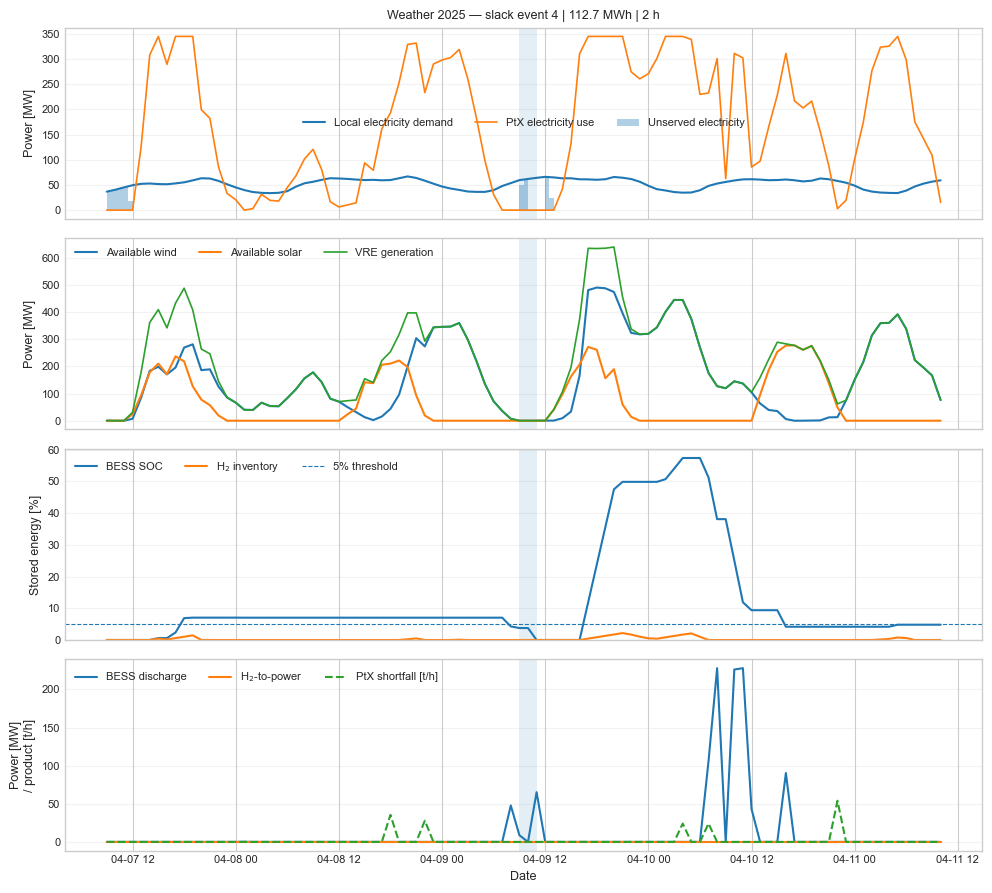

Weather 2025, event 4: 2050-04-09 09:00:00 → 2050-04-09 10:00:00
  Slack: 112.7 MWh | peak 61.9 MW
  Night: 100.0% | peak-demand hours: 0.0%
  BESS SOC: 4.3% before → minimum 3.8%
  H₂ inventory: 0.0% before → minimum 0.0%
  PtX electricity during event: 0.0 MW average



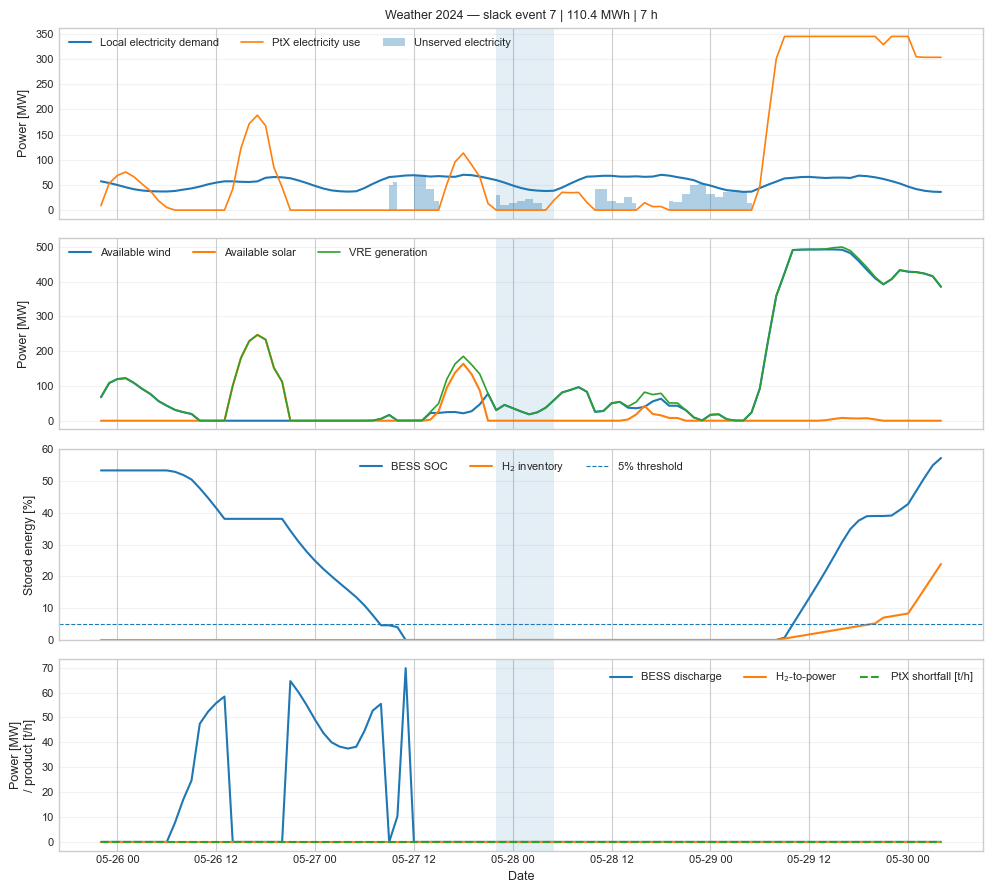

Weather 2024, event 7: 2050-05-27 22:00:00 → 2050-05-28 04:00:00
  Slack: 110.4 MWh | peak 30.0 MW
  Night: 100.0% | peak-demand hours: 0.0%
  BESS SOC: 0.0% before → minimum 0.0%
  H₂ inventory: 0.0% before → minimum 0.0%
  PtX electricity during event: 0.0 MW average



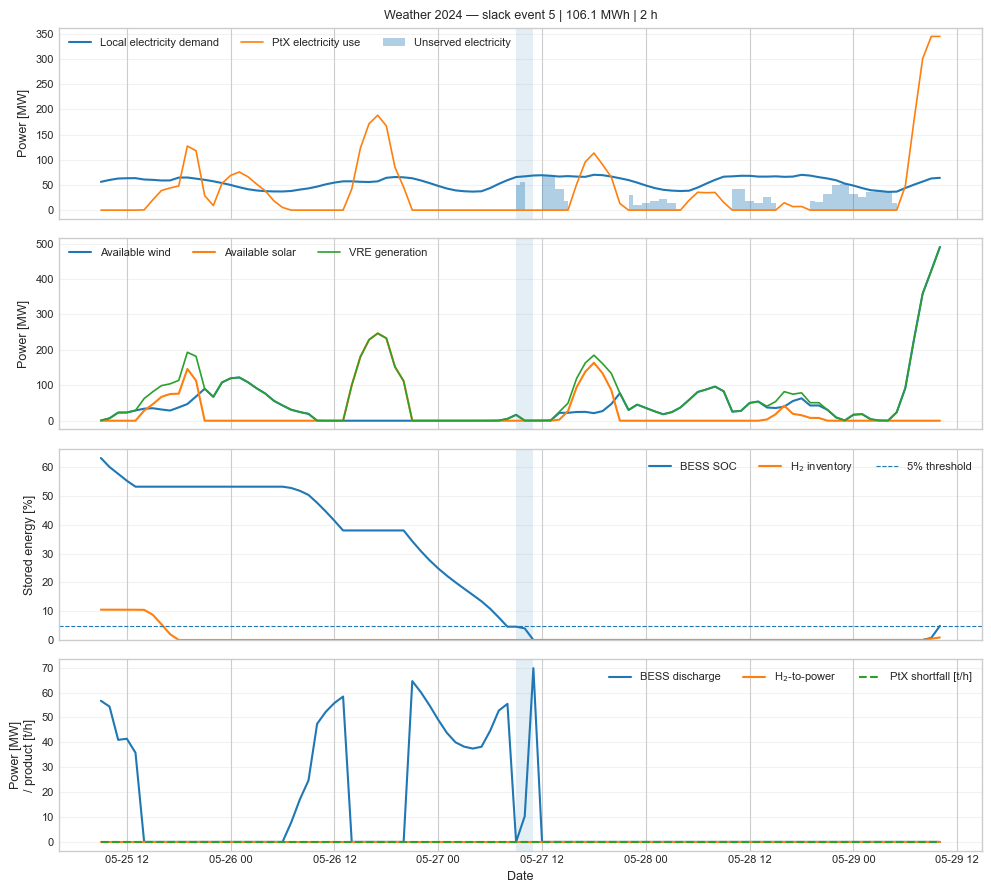

Weather 2024, event 5: 2050-05-27 09:00:00 → 2050-05-27 10:00:00
  Slack: 106.1 MWh | peak 56.6 MW
  Night: 100.0% | peak-demand hours: 100.0%
  BESS SOC: 4.6% before → minimum 4.0%
  H₂ inventory: 0.0% before → minimum 0.0%
  PtX electricity during event: 0.0 MW average



In [56]:
# ══════════════════════════════════════════════════════════════════════════════
# EVENT WINDOWS — WHAT HAPPENS BEFORE AND DURING UNSERVED DEMAND?
# ══════════════════════════════════════════════════════════════════════════════

DIAGNOSTIC_DIR = ROBUSTNESS_EXPORT_DIR / "diagnostics"
DIAGNOSTIC_DIR.mkdir(parents=True, exist_ok=True)

WINDOW_DAYS_BEFORE = 2
WINDOW_DAYS_AFTER = 2

# Plot the largest events first
MAX_EVENTS_TO_PLOT = 40

if slack_event_summary.empty:
    print("No unserved-electricity events found.")
else:
    events_to_plot = (
        slack_event_summary
        .sort_values("slack_mwh", ascending=False)
        .head(MAX_EVENTS_TO_PLOT)
        .copy()
    )
    for _, event in events_to_plot.iterrows():
        wy = int(event["weather_year"])
        event_number = int(event["event"])
        start = pd.Timestamp(event["start"])
        end = pd.Timestamp(event["end"])
        df = hourly_diagnostics[wy]
        window_start = start - pd.Timedelta(days=WINDOW_DAYS_BEFORE)
        window_end = end + pd.Timedelta(days=WINDOW_DAYS_AFTER)
        window = df.loc[(df.index >= window_start) & (df.index <= window_end)].copy()
        if window.empty:
            continue
        fig, axes = plt.subplots(4, 1, figsize=(10, 9), sharex=True)

        # ── (a) Demand, PtX electricity and unserved demand ──────────────────
        axes[0].plot(
            window.index,
            window["local_demand_mw"],
            label="Local electricity demand",
            linewidth=1.5,
        )
        axes[0].plot(
            window.index,
            window["ptx_electricity_mw"],
            label="PtX electricity use",
            linewidth=1.2,
        )
        axes[0].fill_between(
            window.index,
            0,
            window["slack_mw"],
            where=window["slack_mw"] > SLACK_EPS_MW,
            alpha=0.35,
            label="Unserved electricity",
            step="mid",
        )
        axes[0].set_ylabel("Power [MW]")
        axes[0].legend(frameon=False, ncol=3)
        axes[0].grid(True, axis='y', alpha=0.25)

        # ── (b) Renewable availability ───────────────────────────────────────
        axes[1].plot(window.index, window['wind_available_mw'], label='Available wind')
        axes[1].plot(
            window.index,
            window["solar_available_mw"],
            label="Available solar",
        )
        axes[1].plot(
            window.index,
            window["vre_generation_mw"],
            label="VRE generation",
            linewidth=1.2,
        )
        axes[1].set_ylabel("Power [MW]")
        axes[1].legend(frameon=False, ncol=3)
        axes[1].grid(True, axis='y', alpha=0.25)

        # ── (c) Storage state ────────────────────────────────────────────────
        axes[2].plot(
            window.index,
            window["bess_soc_pct"],
            label="BESS SOC",
            linewidth=1.5,
        )
        axes[2].plot(
            window.index,
            window["h2_inventory_pct"],
            label="H$_2$ inventory",
            linewidth=1.5,
        )
        axes[2].axhline(
            DEPLETED_THRESHOLD_PCT,
            linestyle="--",
            linewidth=0.8,
            label=f"{DEPLETED_THRESHOLD_PCT:.0f}% threshold",
        )
        axes[2].set_ylabel("Stored energy [%]")
        axes[2].set_ylim(bottom=0)
        axes[2].legend(frameon=False, ncol=3)
        axes[2].grid(True, axis='y', alpha=0.25)

        # ── (d) Flexibility response ─────────────────────────────────────────
        axes[3].plot(window.index, window['bess_discharge_mw'], label='BESS discharge')
        axes[3].plot(window.index, window['h2_to_power_mw'], label='H$_2$-to-power')
        axes[3].plot(
            window.index,
            window["ptx_shortfall_tph"],
            label="PtX shortfall [t/h]",
            linestyle="--",
        )
        axes[3].set_ylabel("Power [MW]\n/ product [t/h]")
        axes[3].set_xlabel("Date")
        axes[3].legend(frameon=False, ncol=3)
        axes[3].grid(True, axis='y', alpha=0.25)

        # ── Highlight the actual slack event in every panel ──────────────────
        for ax in axes:
            ax.axvspan(start, end + pd.Timedelta(hours=1), alpha=0.12)
        axes[0].set_title(
            f"Weather {wy} — slack event {event_number} | "
            f"{event['slack_mwh']:.1f} MWh | "
            f"{event['duration_h']:.0f} h"
        )
        plt.tight_layout()
        output_path = (
            DIAGNOSTIC_DIR
            / f"slack_event_weather_{wy}_event_{event_number}.svg"
        )
        fig.savefig(output_path, bbox_inches='tight')
        plt.show()
        print(f'Weather {wy}, event {event_number}: {start} → {end}')
        print(
            f"  Slack: {event['slack_mwh']:.1f} MWh | "
            f"peak {event['peak_slack_mw']:.1f} MW"
        )
        print(
            f"  Night: {event['night_share_slack_pct']:.1f}% | "
            f"peak-demand hours: "
            f"{event['peak_demand_share_slack_pct']:.1f}%"
        )
        print(
            f"  BESS SOC: "
            f"{event['bess_soc_before_pct']:.1f}% before → "
            f"minimum {event['minimum_bess_soc_pct']:.1f}%"
        )
        print(
            f"  H₂ inventory: "
            f"{event['h2_inventory_before_pct']:.1f}% before → "
            f"minimum {event['minimum_h2_inventory_pct']:.1f}%"
        )
        print(
            f"  PtX electricity during event: "
            f"{event['mean_ptx_electricity_mw']:.1f} MW average"
        )
        print()


## 6. Recommended execution order

For an **analysis-only** session, keep the expensive `RUN_*` switches disabled as needed and execute from the top so shared configuration and cached/exported results are loaded before the figure cells.

For a **full refresh**:

1. Enable `RUN_SIMULATIONS` and execute Sections 1–3.
2. Enable `RUN_PTX_WEATHER_DESIGN_SENSITIVITY` before Figure 6 if the 2016–2025 investment-sensitivity runs or their saved 2050 networks must be regenerated.
3. Enable `RUN_ROBUSTNESS` to regenerate Figure 7 from the fixed 2020 design.
4. Enable `RUN_ROBUSTNESS_2024` to generate the alternative fixed-design experiment used by Figure 8. This requires `PTX_base_WY2024_2050.nc`, produced by the Figure 6 sensitivity workflow.
5. Return expensive `RUN_*` switches to `False` after the required exports have been created.

The notebook keeps the manuscript figures separate from supplementary diagnostics. Figure 7 and Figure 8 use the same operational-stress-test and event-clustering functions so their comparison differs only in the fixed investment design (2020 versus 2024).
